In [1]:
import numpy as np
import pandas as pd
import scipy as sp
import scanpy as sc
from glob import glob
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib as mpl
from matplotlib.pyplot import rc_context
import os
import seaborn as sns
import importlib
import re
import harmonypy as hm

/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import anndata.io.read_mtx instead.
  warnings.warn(msg, FutureWarning)
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from 

In [2]:
import degSummary

In [3]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.logging.print_header()
sc.settings.set_figure_params(dpi=150, facecolor='white', dpi_save=1000)

/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


scanpy==1.9.3 anndata==0.11.4 umap==0.5.12 numpy==1.26.4 scipy==1.15.2 pandas==2.3.3 scikit-learn==1.7.2 statsmodels==0.14.6 python-igraph==1.0.0 leidenalg==0.12.0 pynndescent==0.5.13


In [4]:
sns.set_theme(style="ticks") # ticks whitegrid

# Load data

In [5]:
os.chdir('../..')

In [6]:
pwd

'/Users/tzu-chiaolu/Project/HongjieLab/rapamycin'

In [7]:
age_L=[ '7', '30', '50', '70' ]
ageColor_L=['#1F77B4', '#FF7F0E', '#2CA02C', '#D62728']
ageColor_L2=['#009ACD', '#FF7D40', '#2CA02C', '#D62728']
ggplotColor3_L= ["#F8766D", "#00BA38", "#619CFF"]
set2Color_L=["#66C2A5", "#E9936A", "#A89BB0"]

In [8]:
condition_L=['NoTreatment', 'DMSO', 'Rapamycin']

In [9]:
figureFolder=f'Analysis/Figure'
os.makedirs(figureFolder, exist_ok=True)
figure1Folder=f'{figureFolder}/Figure1'
os.makedirs(figure1Folder, exist_ok=True)
figure1PicFolder=f'{figure1Folder}/pic'
os.makedirs(figure1PicFolder, exist_ok=True)

In [10]:
figure2Folder=f'{figureFolder}/Figure2'
os.makedirs(figure2Folder, exist_ok=True)
figure2PicFolder=f'{figure2Folder}/pic'
os.makedirs(figure2PicFolder, exist_ok=True)

In [11]:
figure3Folder=f'{figureFolder}/Figure3'
os.makedirs(figure3Folder, exist_ok=True)
figure3PicFolder=f'{figure3Folder}/pic'
os.makedirs(figure3PicFolder, exist_ok=True)

In [12]:
figure4Folder=f'{figureFolder}/Figure4'
os.makedirs(figure4Folder, exist_ok=True)
figure4PicFolder=f'{figure4Folder}/pic'
os.makedirs(figure4PicFolder, exist_ok=True)

In [13]:
figure5Folder=f'{figureFolder}/Figure5'
os.makedirs(figure5Folder, exist_ok=True)
figure5PicFolder=f'{figure5Folder}/pic'
os.makedirs(figure5PicFolder, exist_ok=True)

lineageDegFolder = f'{figure5Folder}/lineageDeg'
os.makedirs(lineageDegFolder, exist_ok=True)
lineageGoFolder = f'{figure5Folder}/GO'
os.makedirs(lineageGoFolder, exist_ok=True)
lineageRrvgoFolder = f'{figure5Folder}/rrvgo'
os.makedirs(lineageRrvgoFolder, exist_ok=True)

In [14]:
cellnFolder=f'{figure2Folder}/cellN'
os.makedirs(cellnFolder, exist_ok=True)

compositionFolder=f'{figure2Folder}/composition'
os.makedirs(compositionFolder, exist_ok=True)

In [15]:
degControlFolder=f'{figure2Folder}/DEG_toControl'
os.makedirs(degControlFolder, exist_ok=True)

# degCelltypeFolder=f'{figure2Folder}/DEG_celltype'
# os.makedirs(degCelltypeFolder, exist_ok=True)

degTreatControlFolder=f'{figure2Folder}/DEG_treatment_toControl'
os.makedirs(degTreatControlFolder, exist_ok=True)

degTreatControlBroadFolder=f'{figure2Folder}/DEG_treatment_toControl_broad'
os.makedirs(degTreatControlBroadFolder, exist_ok=True)

degTreatControlGroupFolder=f'{figure2Folder}/DEG_treatment_toControl_group'
os.makedirs(degTreatControlGroupFolder, exist_ok=True)

In [16]:
degTreatAgeControlFolder=f'{figure2Folder}/DEG_treatAge_toControl'
os.makedirs(degTreatAgeControlFolder, exist_ok=True)

In [17]:
degTreatAgeSexControlFolder=f'{figure2Folder}/DEG_treatAgeSex_toControl'
os.makedirs(degTreatAgeSexControlFolder, exist_ok=True)

In [18]:
degSummaryFolder=f'{figure2Folder}/degSummary'
os.makedirs(degSummaryFolder, exist_ok=True)

In [19]:
degCompositionSummary=f'{figure2Folder}/degCompositionSummary'
os.makedirs(degCompositionSummary, exist_ok=True)

In [20]:
### Fig2 GO
goFolder=f'{figure2Folder}/GO_compareToControl'
os.makedirs(goFolder, exist_ok=True)

goIdFolder=f'{goFolder}/geneID'
os.makedirs(goIdFolder, exist_ok=True)
goNameFolder=f'{goFolder}/geneName'
os.makedirs(goNameFolder, exist_ok=True)

revigoFolder=f'{figure2Folder}/revigo_compareToControl'
os.makedirs(revigoFolder, exist_ok=True)

In [21]:
condition_L=['NoTreatment', 'DMSO', 'Rapamycin']
treatment_L=['Control', 'Rapamycin']

In [22]:
age_L=['7', '30', '50', '70']
ageColor_L=['#1F77B4', '#FF7F0E', '#2CA02C', '#D62728']
ageColor_L2=['#009ACD', '#FF7D40', '#2CA02C', '#D62728']
ggplotColor3_L= ["#F8766D", "#00BA38", "#619CFF"]
set2Color_L=["#66C2A5", "#E9936A", "#A89BB0"]

In [23]:
annotFolder='Analysis/5.transferAnnot_cellbender_scDblFinder'

In [24]:
treatAge_Df = pd.DataFrame(index=range(len(age_L)-1))
treatAge_Df['expSet'] = ['Rapamycin']*3
treatAge_Df['controlSet'] = ['Control']*3
treatAge_Df['age'] = age_L[1:]
treatAge_Df['expAge'] = treatAge_Df['expSet'].astype(str) + '_' + treatAge_Df['age'].astype(str)
treatAge_Df['controlAge'] = treatAge_Df['controlSet'].astype(str) + '_' + treatAge_Df['age'].astype(str)

treatAge_Df

,expSet,controlSet,age,expAge,controlAge
0,Rapamycin,Control,30,Rapamycin_30,Control_30
1,Rapamycin,Control,50,Rapamycin_50,Control_50
2,Rapamycin,Control,70,Rapamycin_70,Control_70


In [25]:
treatAge_Df = pd.DataFrame(index=range(len(age_L)-1))
treatAge_Df['expSet'] = ['Rapamycin']*3
treatAge_Df['controlSet'] = ['Control']*3
treatAge_Df['age'] = age_L[1:]
treatAge_Df['expAge'] = treatAge_Df['expSet'].astype(str) + '_' + treatAge_Df['age'].astype(str)
treatAge_Df['controlAge'] = treatAge_Df['controlSet'].astype(str) + '_' + treatAge_Df['age'].astype(str)

treatAge_Df

,expSet,controlSet,age,expAge,controlAge
0,Rapamycin,Control,30,Rapamycin_30,Control_30
1,Rapamycin,Control,50,Rapamycin_50,Control_50
2,Rapamycin,Control,70,Rapamycin_70,Control_70


In [26]:
treatAgeSex_Df = pd.DataFrame(index=range( (len(age_L)-1)*2  ))
treatAgeSex_Df['expSet'] = ['Rapamycin']*6
treatAgeSex_Df['controlSet'] = ['Control']*6
treatAgeSex_Df['age'] = age_L[1:]*2
treatAgeSex_Df['sex'] = ['female']*3+['male']*3
treatAgeSex_Df['expAgeSex'] = treatAgeSex_Df['expSet'].astype(str) + '_' + treatAgeSex_Df['age'].astype(str) + '_' + treatAgeSex_Df['sex'].astype(str)
treatAgeSex_Df['controlAgeSex'] = treatAgeSex_Df['controlSet'].astype(str) + '_' + treatAgeSex_Df['age'].astype(str) + '_' + treatAgeSex_Df['sex'].astype(str)

treatAgeSex_Df

,expSet,controlSet,age,sex,expAgeSex,controlAgeSex
0,Rapamycin,Control,30,female,Rapamycin_30_female,Control_30_female
1,Rapamycin,Control,50,female,Rapamycin_50_female,Control_50_female
2,Rapamycin,Control,70,female,Rapamycin_70_female,Control_70_female
3,Rapamycin,Control,30,male,Rapamycin_30_male,Control_30_male
4,Rapamycin,Control,50,male,Rapamycin_50_male,Control_50_male
5,Rapamycin,Control,70,male,Rapamycin_70_male,Control_70_male


In [27]:
celltypeN700_L = pd.read_csv(f'{cellnFolder}/celltype_cellN_n700.csv', index_col=0).columns.to_list()
print(len(celltypeN700_L))

90


In [28]:
male_L = ['ejaculatory bulb epithelium', 'ejaculatory bulb', 'anterior ejaculatory duct', 'seminal vesicle & testis epithelia', 'male accessory gland main cell_roX1+', 'male accessory gland main cell_roX1-', 
          'male accessory gland secondary cell', 'spermatocyte', 'cyst cell', 'spermatid']
female_L = ['16-cell germline cyst in germarium region 2a and 2b', 'choriogenic main body follicle cell and corpus luteum', 'escort cell', 'female reproductive system', 'follicle cell', 'follicle stem cell and prefollicle cell', 
            'germline cell', 'polar follicle cell', 'prefollicle cell/stalk follicle cell', 'stalk follicle cell', 'young germ cell', 'oviduct']

In [29]:
treatColor_L = ['#dfc27d','#01665e']

In [30]:
treatAgeSex_L = ['Control_7_female', 'Control_30_female', 'Control_50_female', #'Control_70_female',
                 'Control_7_male', 'Control_30_male', 'Control_50_male', #'Control_70_male',
                 'Rapamycin_30_female', 'Rapamycin_50_female', #'Rapamycin_70_female',
                 'Rapamycin_30_male', 'Rapamycin_50_male',] #'Rapamycin_70_male']

In [31]:
treatAgeSexF_L = ['Control_7_female', 'Control_30_female', 'Control_50_female', #'Control_70_female',
                 'Rapamycin_30_female', 'Rapamycin_50_female', #'Rapamycin_70_female',
] #'Rapamycin_70_male']

treatAgeSexM_L = [
                 'Control_7_male', 'Control_30_male', 'Control_50_male', #'Control_70_male',
                 'Rapamycin_30_male', 'Rapamycin_50_male',] #'Rapamycin_70_male']

In [32]:
treatAgeSexComp_L = ['Control_7_female', 
                     'Control_30_female', 'Rapamycin_30_female','Control_50_female', 'Rapamycin_50_female',  #'Rapamycin_70_female',
                     'Control_7_male', 
                     'Control_30_male', 'Rapamycin_30_male', 'Control_50_male',  'Rapamycin_50_male', #'Control_70_male', #'Rapamycin_70_male']
                    ] 

# Funciont summarize cellN

In [33]:
def cellN_cellRatio(adata, sampleCol, annotCol):
    """
    Calculate the cell-type numbers and ratios in each sample
    """
    # print(sampleCol, annotCol)

    # cellN
    cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
    cellN_Df.columns = list(cellN_Df.columns.get_level_values(1))
    cellN_Df.index.name = None
    # cellN_Df = cellN_Df.loc[:, umiCol_L ] # + ['unknown']
    # cellN_Df

    cellN_ratio = pd.DataFrame(index=cellN_Df.index.to_list(), columns= cellN_Df.columns.to_list())
    for dataset_each in cellN_Df.index:
        cellN_ratio.loc[dataset_each]= cellN_Df.loc[dataset_each]/cellN_Df.loc[dataset_each].sum()

    return(cellN_Df, cellN_ratio)

# Compared genes enriched/depleted in the aged trajectory

## Load files

In [34]:
adata_germlineAll = sc.read(f'{figure4Folder}/adata_germline_raw.h5ad')
adata_germline = sc.read(f'{figure4Folder}/adata_germline_rapamycin.h5ad')
adata_follicle = sc.read(f'{figure4Folder}/ovary_follicle__rapamycin__body__5.lineage_raw.h5ad')
adata_maleAcc = sc.read(f'{figure4Folder}/maleAccessory__rapamycin__body__2.PAGA_raw.h5ad')
adata_ejula = sc.read(f'{figure4Folder}/adata_concat_eb__tsne__rox1Group.h5ad')
adata_vnc = sc.read(f'{figure3Folder}/adata_vnc__w70d__lineage.h5ad')

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use 

## Identify genes

In [35]:
adata_germline

AnnData object with n_obs × n_vars = 9198 × 2000
    obs: 'fca_annotation', 'afca_annotation', 'afca_annotation_broad', 'adfca_annotation', 'adfca_annotation_broad', 'adfca_annotation_group', 'adfca_annotation_subcluster', 'linearR_annotation', 'dataset', 'age', 'sex', 'tissue', 'condition', 'leiden', 'treatment', 'treatAge', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.45', 'leiden_0.5', 'leiden_0.55', 'leiden_0.6', 'rapamycin_annotation_subcluster', 'S_score', 'G2M_score', 'phase', 'dpt_pseudotime', 'lineage'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'age_colors', 'dataset_colors', 'diffmap_evals', 'draw_graph', 'hvg', 'iroot', 'leiden', 'leiden_0.45_colors', 'leiden_0.4_colors', 'leiden_0.55_colors', 'leiden_0.5_colors', 'leiden_colors', 'lineage_colors', 'neighbors', 'paga', 'pca', 'rapamycin_annotation_subcluster_colors', 'rapamycin_annotation_subcluster_sizes', 

In [41]:
adata_maleAcc.obs['rapamycin_annotation_subcluster']

TCTTTGAGTATCACCA-1__DMSO_50_male_body         male accessory gland main cell_roX1+
CTGAGCGGTACACTCA-1__DMSO_50_male_body         male accessory gland main cell_roX1+
TACTTGTCACCTGTCT-1__DMSO_50_male_body         male accessory gland main cell_roX1+
TCTTCCTAGCACTGGA-1__DMSO_50_male_body         male accessory gland main cell_roX1+
CCTAAGACATAACCCA-1__DMSO_50_male_body         male accessory gland main cell_roX1+
                                                              ...                 
GTAAGTCTCCCTCTAG-1__Rapamycin_50_male_body    male accessory gland main cell_roX1+
ATCACTTCATCACAGT-1__Rapamycin_50_male_body    male accessory gland main cell_roX1-
TTTCGATCAAGCGCTC-1__Rapamycin_50_male_body    male accessory gland main cell_roX1-
TGGATCATCTGATTCT-1__Rapamycin_50_male_body    male accessory gland main cell_roX1-
TACGCTCGTAGACTGG-1__Rapamycin_50_male_body    male accessory gland main cell_roX1+
Name: rapamycin_annotation_subcluster, Length: 6117, dtype: category
Categories (2, obj

In [42]:
adata_maleAcc.obs['lineage'] = adata_maleAcc.obs.rapamycin_annotation_subcluster.to_list()
adata_ejula.obs['lineage'] = adata_ejula.obs.rapamycin_annotation_sub.to_list()

adata_maleAcc.obs['lineage'] = pd.Categorical(['young lineage' if 'roX1+' in lineage else 'old lineage' for lineage in adata_maleAcc.obs['lineage'] ])
adata_ejula.obs['lineage'] = pd.Categorical(['young lineage' if 'roX1+' in lineage else 'old lineage' for lineage in adata_ejula.obs['lineage'] ])

In [45]:
adata_germline.obs.lineage.value_counts()

lineage
young lineage      3810
old lineage        3664
young germ cell    1724
Name: count, dtype: int64

In [46]:
adata_germline.obs.dataset.value_counts()

dataset
Rapamycin    9198
Name: count, dtype: int64

In [47]:
adata_germline_selected = adata_germline[ (adata_germline.obs.lineage.isin(['old lineage', 'young lineage']) ) ]
# adata_follicle_selected = adata_follicle[ (adata_follicle.obs.lineage.isin(['old lineage', 'young lineage']) ) ]
adata_follicle_selected = adata_follicle[ (adata_follicle.obs.rapamycin_annotation == 'follicle cell') & \
                                (adata_follicle.obs.lineage.isin(['old lineage', 'young lineage']) ) ]

## Identify DEGs: compared between age-matched treatments: treatAgeSex

In [48]:
compareGroup = 'lineage'

In [49]:
adata_D = {'germline': adata_germline_selected, 'follicle': adata_follicle_selected, 'maleAcc': adata_maleAcc, 'ejulatoryBulb': adata_ejula, 'vnc': adata_vnc}

In [50]:
treatAgeSex_Df.expAgeSex

0    Rapamycin_30_female
1    Rapamycin_50_female
2    Rapamycin_70_female
3      Rapamycin_30_male
4      Rapamycin_50_male
5      Rapamycin_70_male
Name: expAgeSex, dtype: object

In [51]:
# DEG: compared by genotype, grouped by corresponding ages

for cellType in adata_D.keys():
    csvFileName=cellType.replace('/', '_')
    csvFile=f'{lineageDegFolder}/{csvFileName}__{compareGroup}.csv'
    print(cellType)

    adata=adata_D[cellType]
    # adata.uns['log1p']["base"] = None
    
    try:
        sc.tl.rank_genes_groups(adata, groupby=compareGroup, reference='young lineage', method='wilcoxon')
    except KeyError:
        adata.uns['log1p']["base"] = None
        sc.tl.rank_genes_groups(adata, groupby=compareGroup, reference='young lineage', method='wilcoxon')

    result = adata.uns['rank_genes_groups']
    groups = result['names'].dtype.names
    degDf =pd.DataFrame(
        {cellType + '__' + key: result[key][group]
        for group in groups for key in ['names', 'pvals', 'pvals_adj', 'logfoldchanges']})
    if '/' in cellType: 
        cellType=cellType.replace('/', '_')

    degDf.to_csv(csvFile, index=False)


germline
ranking genes


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:580: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/numpy/core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:04)
follicle
ranking genes
ranking genes


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:580: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[key_added] = {}
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/numpy/core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:13)
maleAcc
ranking genes
ranking genes


...

    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:02)
ejulatoryBulb
ranking genes
ranking genes


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/numpy/core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:01)
vnc
ranking genes
ranking genes


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/numpy/core/fromnumeric.py:84: FutureWarning: The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)
  return reduction(axis=axis, out=out, **passkwargs)


    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:04)


## DEG dynamics: Summarize all pairs

In [52]:
def conv(val):
    if val == np.nan:
        return 0 # or whatever else you want to represent your NaN with
    return val

# df = pd.read_csv(file, converters={colWithNaN : conv}, dtypes=...)

In [53]:
degDf_L=[]
for cellType in adata_D.keys():
    csvFileName=cellType.replace('/', '_')
    print(cellType)
    
    csvFile=f'{lineageDegFolder}/{csvFileName}__{compareGroup}.csv'
    print(csvFile)
    if os.path.exists(csvFile):
        degDf = pd.read_csv(csvFile, converters={f'{cellType}__names': conv})
        # print(degDf[degDf.iloc[:,0].isna()])
        degDf_L.append(degDf)

if len(degDf_L) > 0:
    allDeg_Df=pd.concat(degDf_L, axis=1)
    allDeg_Df.to_csv(f'{lineageDegFolder}/DEGs__lineageCompare__{compareGroup}.csv', index=False)

germline
Analysis/Figure/Figure5/lineageDeg/germline__lineage.csv
follicle
Analysis/Figure/Figure5/lineageDeg/follicle__lineage.csv
maleAcc
Analysis/Figure/Figure5/lineageDeg/maleAcc__lineage.csv
ejulatoryBulb
Analysis/Figure/Figure5/lineageDeg/ejulatoryBulb__lineage.csv
vnc
Analysis/Figure/Figure5/lineageDeg/vnc__lineage.csv


### FDR<0.01, absLogFC>=1
### total DEG# from each cell type

In [54]:
fdrCutOff=0.01
absLogFC=0
compareGroup='lineage'

In [55]:
list(adata_D.keys())

['germline', 'follicle', 'maleAcc', 'ejulatoryBulb', 'vnc']

In [56]:
ct_L = ['germline', 'maleAcc', 'vnc']

In [57]:
# degN_Df=pd.DataFrame(index=list(adata_D.keys()), columns=['Up', 'Down', 'Total']  )
# for cellType in adata_D.keys():
    
degN_Df=pd.DataFrame(index=ct_L, columns=['Up', 'Down', 'Total']  )
for cellType in ct_L:
    csvFileName=cellType.replace('/', '_')
    csvFile=f'{lineageDegFolder}/{csvFileName}__{compareGroup}.csv'
    # print(cellType)

    # print(os.path.exists(csvFile))
    if os.path.exists(csvFile):
        print(cellType)
        degDf=pd.read_csv(csvFile)
        degN_up=len(degDf[(degDf[f'{cellType}__pvals_adj'] < fdrCutOff) & (degDf[f'{cellType}__logfoldchanges'] >= absLogFC) ][f'{cellType}__names'].to_list()) # & 
        degN_down=len(degDf[(degDf[f'{cellType}__pvals_adj'] < fdrCutOff) & (degDf[f'{cellType}__logfoldchanges'] <= -absLogFC) ][f'{cellType}__names'].to_list()) 
        # degN_up=len(degDf[(degDf[f'{cellType}__pvals_adj'] < fdrCutOff) & (degDf[f'{cellType}__logfoldchanges'] >= 0) ][f'{cellType}__names'].to_list()) # & 
        # degN_down=len(degDf[(degDf[f'{cellType}__pvals_adj'] < fdrCutOff) & (degDf[f'{cellType}__logfoldchanges'] <= 0) ][f'{cellType}__names'].to_list()) 
        degN_all = degN_up + degN_down
        
        degName_up_L=degDf[(degDf[f'{cellType}__pvals_adj'] < fdrCutOff) & (degDf[f'{cellType}__logfoldchanges'] >= absLogFC) ][f'{cellType}__names'].to_list() 
        degName_down_L=degDf[(degDf[f'{cellType}__pvals_adj'] < fdrCutOff) & (degDf[f'{cellType}__logfoldchanges'] <= -absLogFC) ][f'{cellType}__names'].to_list()
        
        upFile = open(f'{lineageDegFolder}/degName__{csvFileName}__lineage__up.txt', 'w')
        for gene in degName_up_L: upFile.write(gene+'\n')
        upFile.close()
        downFile = open(f'{lineageDegFolder}/degName__{csvFileName}__lineage__down.txt', 'w')
        for gene in degName_down_L: downFile.write(gene+'\n')
        downFile.close()
        
    # else:
    #     degN = np.nan

    degN_Df.loc[cellType, :]=degN_up, degN_down, degN_all

degN_Df       

germline
maleAcc
vnc


,Up,Down,Total
germline,953,1669,2622
maleAcc,441,1937,2378
vnc,1725,547,2272


color_pos='#D62728' 

color_neg='#1F77B4’ (steelblue)

<ipython-input-72-f136903eb9fd>:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


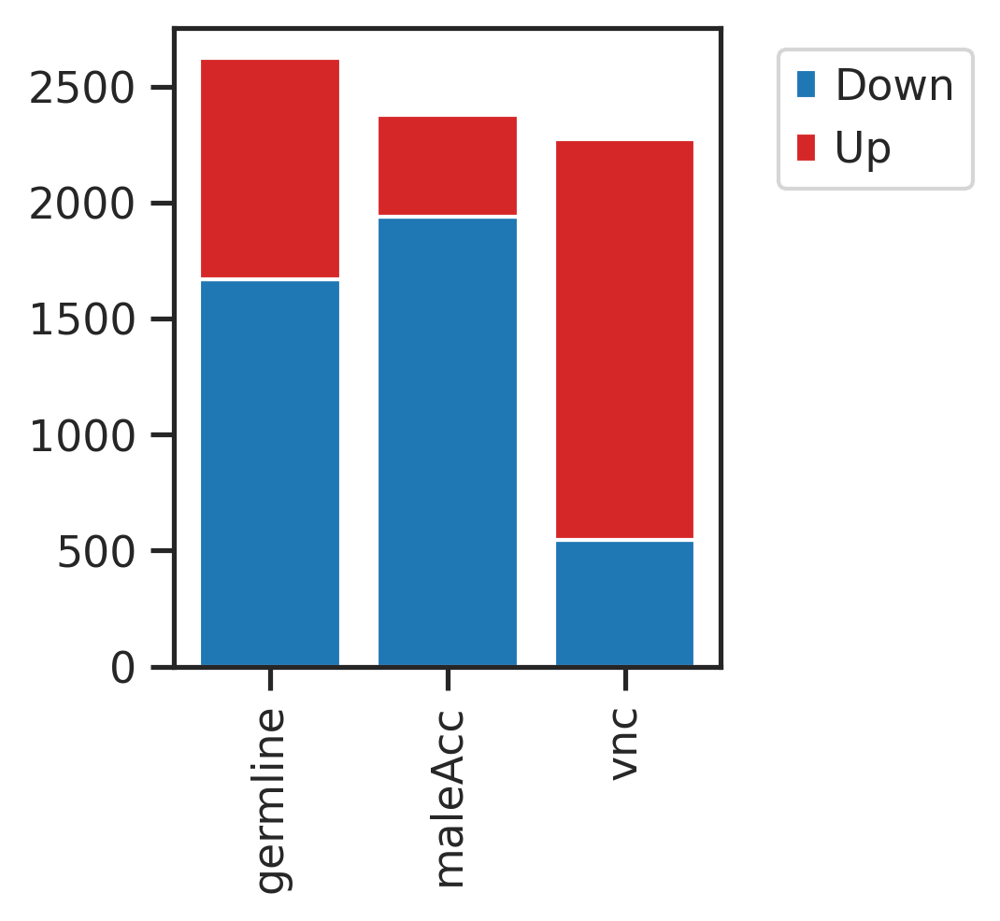

In [72]:
# Data
groups = degN_Df.index.to_list()
values1 = degN_Df.Up.to_list()
values2 = degN_Df.Down.to_list()

fig, ax = plt.subplots(figsize=(2.5, 3))

# Stacked bar chart
ax.bar(groups, values2, label = "Down", color='#1F77B4' )
ax.bar(groups, values1, bottom = values2, label = "Up", color='#D62728' )

ax.legend(bbox_to_anchor=(1.5, 1.0))
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

plt.savefig(f'{figure5PicFolder}/barplot__degN__lineage.pdf')

In [73]:
from matplotlib_venn import venn3

### up-regulated genes

In [74]:
degSetUp_D = {ct: set([gene.strip() for gene in open(f'{lineageDegFolder}/degName__{ct}__lineage__up.txt') ]) for ct in ct_L}
degSetUp_D.keys()

dict_keys(['germline', 'maleAcc', 'vnc'])

In [75]:
setGermline_up = degSetUp_D['germline']
setMaleAcc_up = degSetUp_D['maleAcc']
setVNC_up = degSetUp_D['vnc']

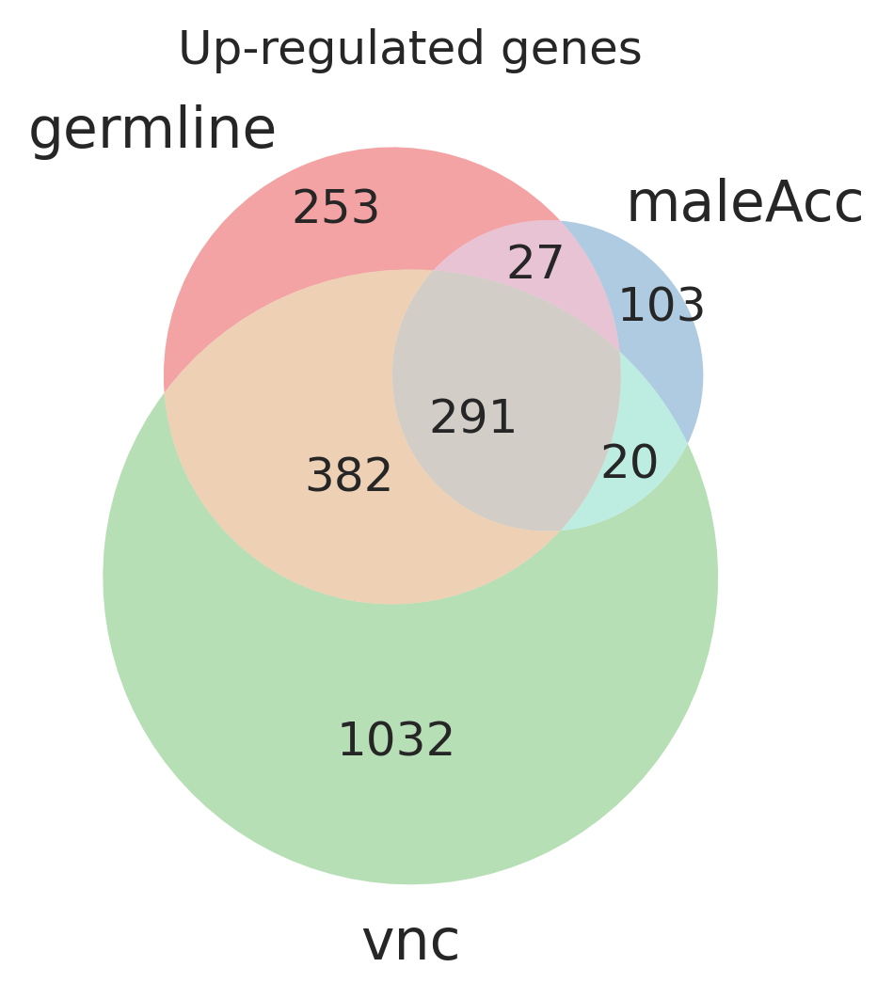

In [76]:
venn3([setGermline_up, setMaleAcc_up, setVNC_up], set_labels=('germline', 'maleAcc', 'vnc'), set_colors=sns.color_palette("Set1"))
# Display the plot
plt.title("Up-regulated genes")
plt.show()

### down-regulated genes

In [77]:
degSetDown_D = {ct: set([gene.strip() for gene in open(f'{lineageDegFolder}/degName__{ct}__lineage__down.txt') ]) for ct in ct_L}
degSetDown_D.keys()

dict_keys(['germline', 'maleAcc', 'vnc'])

In [78]:
setGermline_down = degSetDown_D['germline']
setMaleAcc_down = degSetDown_D['maleAcc']
setVNC_down = degSetDown_D['vnc']

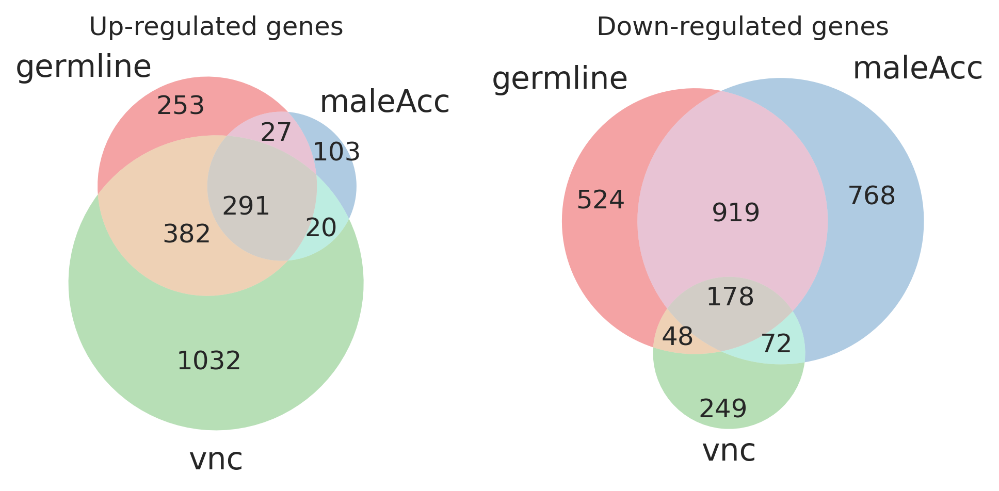

In [79]:
### up- and down-regulated trajectory genes
figs, axs = plt.subplots(1, 2, figsize = (8, 3.5))

venn3([setGermline_up, setMaleAcc_up, setVNC_up], set_labels=('germline', 'maleAcc', 'vnc'), set_colors=sns.color_palette("Set1"), ax=axs[0])
venn3([setGermline_down, setMaleAcc_down, setVNC_down], set_labels=('germline', 'maleAcc', 'vnc'), set_colors=sns.color_palette("Set1"), ax=axs[1])

axs[0].set_title("Up-regulated genes")
axs[1].set_title("Down-regulated genes")

fig.tight_layout()
plt.savefig(f'{figure5PicFolder}/venn__sharedAging__up_down.pdf', bbox_inches='tight')
plt.show()

In [80]:
len(list(set(setGermline_up & setMaleAcc_up & setVNC_up)))

291

In [81]:
shareUp_L = sorted(list(set(setGermline_up & setMaleAcc_up & setVNC_up)))
shareDown_L = sorted(list(set(setGermline_down & setMaleAcc_down & setVNC_down)))

In [82]:
OutFile1 = open(f'{lineageDegFolder}/sharedAgingGenes__up.txt', 'w')
for gene in shareUp_L: OutFile1.write(gene+ '\n')

OutFile2 = open(f'{lineageDegFolder}/sharedAgingGenes__down.txt', 'w')
for gene in shareDown_L: OutFile2.write(gene+ '\n')
                   
OutFile1.close()
OutFile2.close()

In [85]:
for ct in adata_D.keys():
    print(ct)
    adata_D[ct].write(f'{figure5Folder}/adata_{ct}.h5ad')

germline
follicle
maleAcc
ejulatoryBulb
vnc


# GO of shared aging genes

## Load GO files

### Load ontologies and associations

In [33]:
import goatools

In [34]:
goatools.__version__

'1.3.1'

In [35]:
!pwd

/data/tcl/Project/HongjieLab/rapamycin


In [36]:
from goatools.obo_parser import GODag
from goatools.anno.gaf_reader import GafReader

obodag = GODag("/data/tcl/Resource/GO/go-basic.obo")
# ogaf = GafReader("../../Resource/GO/FlyBase_gene_association_09082022.gaf") # FlyBase file
ogaf = GafReader('/data/tcl/genomes/fly/dmel_r6.31_FB2019_06/precomputed_files/go/gene_association.gaf')

/data/tcl/Resource/GO/go-basic.obo: fmt(1.2) rel(2022-07-01) 47,008 Terms
HMS:0:00:02.189817 114,641 annotations READ: /data/tcl/genomes/fly/dmel_r6.31_FB2019_06/precomputed_files/go/gene_association.gaf 


In [37]:
ns2assc = ogaf.get_ns2assc()

### Load Background gene set

In [38]:
geneid2symbol_Df=pd.read_table('cellrangerSummary/features.tsv', header=None, index_col=0)
geneid2symbol_Df.head()

,1,2
0,,
FBgn0267594,CR45932,Gene Expression
FBgn0259849,Su(Ste):CR42418,Gene Expression
FBgn0085494,Mst77Y-16Psi,Gene Expression
FBgn0085506,CG40635,Gene Expression
FBgn0259870,Su(Ste):CR42439,Gene Expression


In [39]:
geneid2symbol_D= dict(zip(geneid2symbol_Df.index.to_list(), geneid2symbol_Df[1].to_list()))

In [40]:
symbol2geneid_D= dict(zip(geneid2symbol_Df[1].to_list(), geneid2symbol_Df.index.to_list()))

### Initialize a GOEA object 

In [41]:
from goatools.goea.go_enrichment_ns import GOEnrichmentStudyNS

goeaobj = GOEnrichmentStudyNS(
        geneid2symbol_D, # List of fly protein-coding genes
        ns2assc, # geneid/GO associations
        obodag, # Ontologies
        propagate_counts = False,
        alpha = 0.05, # default significance cut-off
        methods = ['fdr_bh']) # defult multipletest correction method


Load BP Ontology Enrichment Analysis ...
 57% 10,035 of 17,562 population items found in association

Load CC Ontology Enrichment Analysis ...
 54%  9,426 of 17,562 population items found in association

Load MF Ontology Enrichment Analysis ...
 52%  9,201 of 17,562 population items found in association


## Load gene list

In [42]:
# degLong_Df=pd.read_csv(f'{degSummaryFolder}/degLong_Df_treatAgeSex_compareToControl_cellN700.csv', index_col=0) # 
# degLong_Df

In [43]:
shareUp_L = [gene.strip() for gene in open(f'{lineageDegFolder}/sharedAgingGenes__up.txt')]
shareDown_L = [gene.strip() for gene in open(f'{lineageDegFolder}/sharedAgingGenes__down.txt')]

## Detect GOs using Goatools

In [44]:
adata_body = sc.read(f'/data/tcl/Project/HongjieLab/rapamycin/adataProcess/v1.0/adata_rapafca_body_v1.0.h5ad')
adata_head = sc.read(f'/data/tcl/Project/HongjieLab/rapamycin/adataProcess/v1.0/adata_rapafca_head_v1.0.h5ad')

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


In [45]:
adata_headBody = adata_head.concatenate(adata_body, join='outer')
adata_headBody

<ipython-input-45-d569f6e12017>:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata_headBody = adata_head.concatenate(adata_body, join='outer')


AnnData object with n_obs × n_vars = 505731 × 15919
    obs: 'latent_RT_efficiency', 'latent_cell_probability', 'latent_scale', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'dataset', 'age', 'sex', 'tissue', 'condition', 'leiden', 'linearR_annotation', 'condAge', 'condSex', 'ageSex', 'condAgeSex', 'condAgeSexTissue', 'leiden_1.0', 'leiden_2.0', 'leiden_3.0', 'leiden_4.0', 'leiden_5.0', 'leiden_6.0', 'leiden_7.0', 'leiden_8.0', 'leiden_9.0', 'leiden_10.0', 'leiden_1.5', 'treatment', 'treatAge', 'treatAgeSex', 'treatSex', 'rapamycin_annotation', 'rapamycin_annotation_broad', 'rapamycin_annotation_subcluster', 'rapamycin_annotation_group', 'batch'
    var: 'gene_ids', 'highly_variable-0', 'means-0', 'dispersions-0', 'dispersions_norm-0', 'highly_variable-1', 'means-1', 'dispersions-1', 'dispersions_norm-1'
    obsm: 'X_pca', 'X_pca_original', 'X_tsne', 'X_umap', 'latent_gene_encoding'
    layers: 'counts', 'logNor'

In [46]:
ct_L = ['germline', 'maleAcc', 'vnc']
compareGroup='lineage'

In [47]:
upId_L=[symbol2geneid_D[x] for x in shareUp_L ]
downId_L=[symbol2geneid_D[x] for x in shareDown_L]

id_D=dict(zip(['up', 'down'], [upId_L, downId_L]))
for expression in id_D.keys():
    geneids_study = id_D[expression]
    goea_results_all = goeaobj.run_study(geneids_study)
    goea_results_sig = [r for r in goea_results_all if r.p_fdr_bh < 0.05]

    goeaobj.wr_tsv(f"{lineageGoFolder}/sharedAgingGO_{expression}_symbols.tsv", goea_results_sig, itemid2name=geneid2symbol_D)
    goeaobj.wr_tsv(f"{lineageGoFolder}/sharedAgingGO_{expression}_geneids.tsv", goea_results_sig)


Runing BP Ontology Analysis: current study set of 291 IDs.
 93%    271 of    291 study items found in association
100%    291 of    291 study items found in population(17562)
Calculating 4,986 uncorrected p-values using fisher_scipy_stats
   4,986 terms are associated with  9,908 of 17,562 population items
     512 terms are associated with    270 of    291 study items
  METHOD fdr_bh:
      23 GO terms found significant (< 0.05=alpha) ( 23 enriched +   0 purified): statsmodels fdr_bh
     175 study items associated with significant GO IDs (enriched)
       0 study items associated with significant GO IDs (purified)

Runing CC Ontology Analysis: current study set of 291 IDs.
 92%    268 of    291 study items found in association
100%    291 of    291 study items found in population(17562)
Calculating 1,072 uncorrected p-values using fisher_scipy_stats
   1,072 terms are associated with  9,424 of 17,562 population items
     181 terms are associated with    268 of    291 study items
  

## remove redundant GO using rrvgo

In [34]:
upGo_Df = pd.read_csv(f"{lineageGoFolder}/sharedAgingGO_up_symbols.tsv", sep='\t')
downGo_Df = pd.read_csv(f"{lineageGoFolder}/sharedAgingGO_down_symbols.tsv", sep='\t')
upGo_Df

,# GO,NS,enrichment,name,ratio_in_study,ratio_in_pop,p_uncorrected,depth,study_count,p_fdr_bh,study_items
0,GO:0002181,BP,e,cytoplasmic translation,82/291,102/17562,2.430288e-131,8,82,1.211741e-127,"RpL10, RpL10Ab, RpL11, RpL12, RpL13, RpL13A, R..."
1,GO:0006412,BP,e,translation,61/291,519/17562,1.532977e-34,7,61,3.821711e-31,"RpL10, RpL10Ab, RpL11, RpL12, RpL13, RpL14, Rp..."
2,GO:1902600,BP,e,proton transmembrane transport,20/291,57/17562,8.822346e-22,8,20,1.466274e-18,"ATP6AP2, ATPsynB, ATPsynC, ATPsynCF6, ATPsynD,..."
3,GO:0015986,BP,e,proton motive force-driven ATP synthesis,11/291,19/17562,1.438879e-15,12,11,1.793563e-12,"ATPsynB, ATPsynC, ATPsynCF6, ATPsynD, ATPsynE,..."
4,GO:0006123,BP,e,"mitochondrial electron transport, cytochrome c...",10/291,17/17562,2.348092e-14,8,10,2.341518e-11,"COX4, COX5A, COX5B, COX7A, COX7C, Cyt-c-p, cyp..."
...,...,...,...,...,...,...,...,...,...,...,...
75,GO:0019843,MF,e,rRNA binding,4/291,17/17562,1.482261e-04,5,4,1.910469e-02,"RpL12, RpL9, RpS5a, RpS9"
76,GO:0015078,MF,e,proton transmembrane transporter activity,3/291,8/17562,2.370795e-04,6,3,2.750122e-02,"ATPsynCF6, VhaM9.7-b, VhaPPA1-1"
77,GO:0070181,MF,e,small ribosomal subunit rRNA binding,3/291,8/17562,2.370795e-04,6,3,2.750122e-02,"RpS13, RpS14a, RpS14b"
78,GO:0016615,MF,e,malate dehydrogenase activity,2/291,2/17562,2.736326e-04,4,2,2.885580e-02,"Mdh1, Mdh2"


In [35]:
# import go rrvgo files

rrvgoMain_up = pd.read_csv(f'{lineageRrvgoFolder}/rrvgo_BP_up.csv').mainGO.to_list()
rrvgoMain_down = pd.read_csv(f'{lineageRrvgoFolder}/rrvgo_BP_down.csv').mainGO.to_list()

In [36]:
len(rrvgoMain_up)

23

In [37]:
upGo_Df_BP = upGo_Df[upGo_Df.NS == 'BP'][rrvgoMain_up]
upGo_Df_BP['-log10FDR'] = -np.log10(upGo_Df_BP.p_fdr_bh)
downGo_Df_BP = downGo_Df[downGo_Df.NS == 'BP'][rrvgoMain_down]
downGo_Df_BP['-log10FDR'] = -np.log10(downGo_Df_BP.p_fdr_bh)

upGo_Df_BP

,# GO,NS,enrichment,name,ratio_in_study,ratio_in_pop,p_uncorrected,depth,study_count,p_fdr_bh,study_items,-log10FDR
0,GO:0002181,BP,e,cytoplasmic translation,82/291,102/17562,2.430288e-131,8,82,1.211741e-127,"RpL10, RpL10Ab, RpL11, RpL12, RpL13, RpL13A, R...",126.916590
2,GO:1902600,BP,e,proton transmembrane transport,20/291,57/17562,8.822346e-22,8,20,1.466274e-18,"ATP6AP2, ATPsynB, ATPsynC, ATPsynCF6, ATPsynD,...",17.833785
4,GO:0006123,BP,e,"mitochondrial electron transport, cytochrome c...",10/291,17/17562,2.348092e-14,8,10,2.341518e-11,"COX4, COX5A, COX5B, COX7A, COX7C, Cyt-c-p, cyp...",10.630503
5,GO:0000027,BP,e,ribosomal large subunit assembly,10/291,19/17562,1.083132e-13,7,10,9.000824e-11,"RpL10, RpL11, RpL12, RpL23A, RpL24, RpL24-like...",10.045718
9,GO:0010499,BP,e,proteasomal ubiquitin-independent protein cata...,9/291,25/17562,1.347834e-10,8,9,6.720299e-08,"Prosalpha3, Prosalpha4, Prosalpha5, Prosbeta1,...",7.172611
18,GO:0008340,BP,e,determination of adult lifespan,12/291,165/17562,2.024669e-05,2,12,5.313159e-03,"ATPsynD, Jafrac1, ND-SGDH, SdhC, Sod1, Sod2, T...",2.274647
19,GO:0042593,BP,e,glucose homeostasis,6/291,41/17562,5.426912e-05,6,6,1.352929e-02,"Ald1, Desat1, Eno, Gapdh2, PyK, Tpi",1.868725
22,GO:0019430,BP,e,removal of superoxide radicals,3/291,7/17562,1.500142e-04,5,3,3.252048e-02,"Jafrac1, Sod1, Sod2",1.487843


In [38]:
downGo_Df_BP

,# GO,NS,enrichment,name,ratio_in_study,ratio_in_pop,p_uncorrected,depth,study_count,p_fdr_bh,study_items,-log10FDR
0,GO:0006468,BP,e,protein phosphorylation,16/178,192/17562,1.147131e-10,6,16,5.719595e-07,"CASK, CG17698, CG34357, CaMKI, CaMKII, Eip63E,...",6.242635
1,GO:0000381,BP,e,"regulation of alternative mRNA splicing, via s...",11/178,89/17562,1.565489e-09,10,11,3.902763e-06,"B52, CG11360, Caper, Rbfox1, Rbp1-like, Saf-B,...",5.408628
2,GO:0007268,BP,e,chemical synaptic transmission,11/178,93/17562,2.523395e-09,7,11,4.193882e-06,"Atpalpha, CaMKII, Sap47, dlg1, dnc, kcc, lap, ...",5.377384
3,GO:0007411,BP,e,axon guidance,14/178,179/17562,3.988518e-09,8,14,4.971688e-06,"Fas1, Lar, PlexA, RhoGAP93B, Sdc, Sema1a, Xe7,...",5.303496
6,GO:0007269,BP,e,neurotransmitter secretion,8/178,67/17562,3.727617e-07,8,8,2.430662e-04,"CASK, Cadps, Cirl, Snap25, Syt7, Syx1A, Tomosy...",3.614275
8,GO:0007616,BP,e,long-term memory,8/178,74/17562,8.109645e-07,7,8,4.492743e-04,"Appl, CASK, CaMKII, EcR, Tob, Tomosyn, hiw, pum",3.347488
9,GO:0007416,BP,e,synapse assembly,5/178,24/17562,3.676047e-06,6,5,1.832877e-03,"AGO1, Prosap, Sema1a, Tl, aPKC",2.736867
18,GO:0007476,BP,e,imaginal disc-derived wing morphogenesis,8/178,118/17562,2.696592e-05,5,8,7.076426e-03,"EcR, flw, kis, nmo, pan, psq, rl, sbb",2.150186
19,GO:0007163,BP,e,establishment or maintenance of cell polarity,5/178,37/17562,3.388519e-05,2,5,7.539210e-03,"CASK, Tomosyn, aPKC, fz, sdt",2.122674
22,GO:0007043,BP,e,cell-cell junction assembly,3/178,7/17562,3.477774e-05,6,3,7.539210e-03,"aPKC, p120ctn, sdt",2.122674


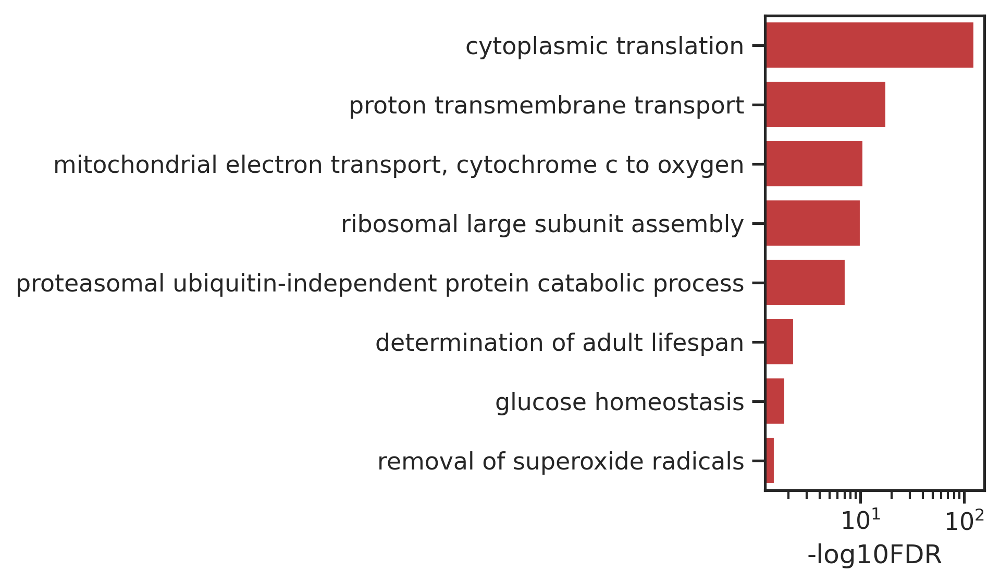

In [58]:
with rc_context({'figure.figsize': (1.8, 4)}):
    sns.barplot(data=upGo_Df_BP, x='-log10FDR', y='name',  color='#D62728', ) # palette=sex_cmap
    # plt.legend(bbox_to_anchor=(1.0, 1.00)) 
    plt.xscale("log")
    plt.xticks([10**1, 10**2,])
    plt.ylabel('')
    plt.savefig(f'{figure5PicFolder}/barplot__upGo_Df_BP.pdf', bbox_inches='tight')

In [47]:
from brokenaxes import brokenaxes

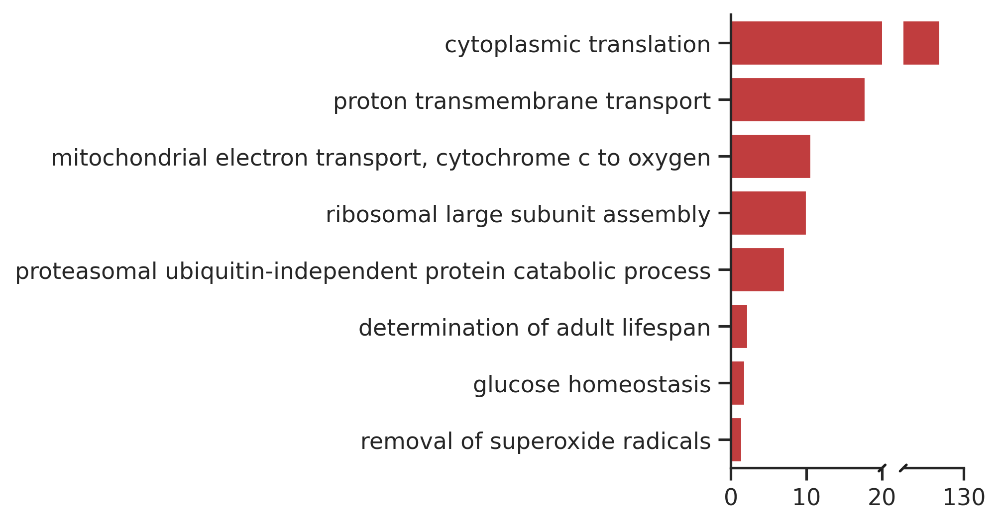

In [64]:
fig = plt.figure(figsize=(2, 4))
bax = brokenaxes(xlims=( (0, 20), (122, 130)), wspace=0.2)

# Plot on each individual axis
for i, ax in enumerate(bax.axs):
    sns.barplot(data=upGo_Df_BP, x='-log10FDR', y='name',  color='#D62728', ax=ax)
    ax.set_xlabel('')
    
    # # Clean up the upper axis (remove x-axis labels and ticks)
    # if i == 0:  # Upper axis
    #     ax.set_xlabel('')
    #     ax.set_xticklabels([])
    #     ax.tick_params(bottom=False)
    # else:  # Lower axis
    #     ax.set_xlabel('sex')

    ax.set_ylabel('')  # Remove individual y-labels

# Set the overall y-label
# bax.set_ylabel('R2', labelpad=40) 

plt.savefig(f'{figure5PicFolder}/barplot__upGo_Df_BP_brokenaxes.pdf', bbox_inches='tight')
plt.show()

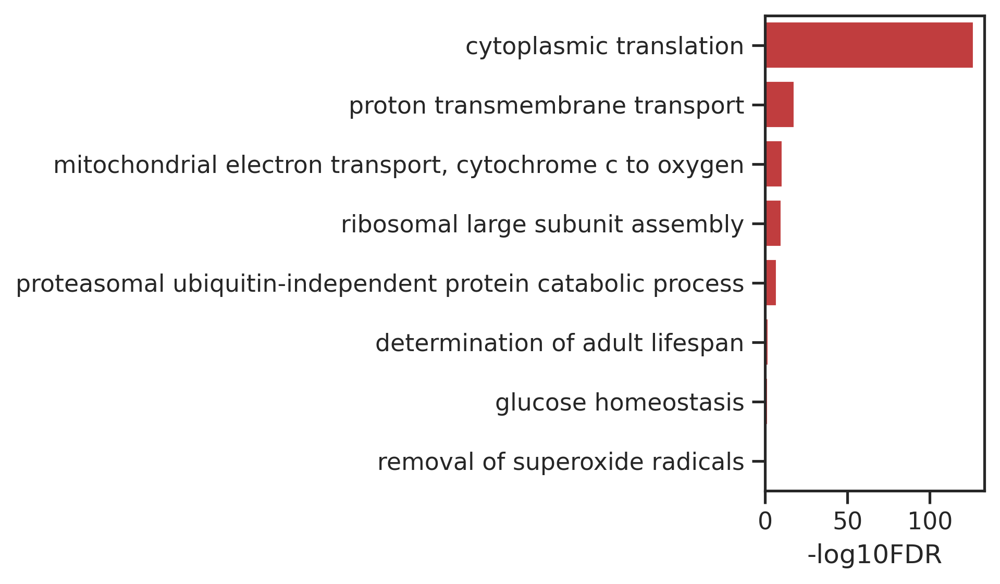

In [45]:
with rc_context({'figure.figsize': (1.8, 4)}):
    sns.barplot(data=upGo_Df_BP, x='-log10FDR', y='name',  color='#D62728', ) # palette=sex_cmap
    # plt.legend(bbox_to_anchor=(1.0, 1.00)) 
    # plt.xscale("log")
    # plt.xticks([10**1, 10**2,])
    plt.ylabel('')
    plt.gca().set_clip_on(True)
    plt.savefig(f'{figure5PicFolder}/barplot__upGo_Df_BP_clip.pdf', bbox_inches='tight') # 

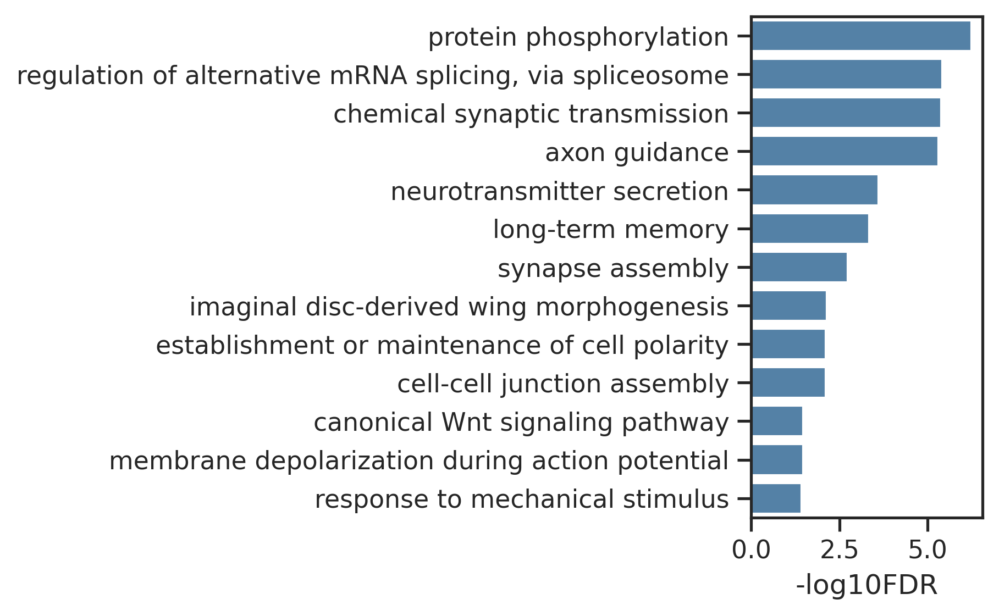

In [59]:
with rc_context({'figure.figsize': (1.8, 4)}):
    sns.barplot(data=downGo_Df_BP, x='-log10FDR', y='name',  color='steelblue', ) # palette=sex_cmap
    # plt.legend(bbox_to_anchor=(1.0, 1.00)) 
    # plt.xscale("log")
    # plt.xticks([10**0, 10**1,])
    plt.ylabel('')
    plt.savefig(f'{figure5PicFolder}/barplot__downGo_Df_BP.pdf', bbox_inches='tight')

# scores of shared aging genes (up-down)

## scores in whole body/head

### up-down

In [36]:
import math

In [37]:
adata_body = sc.read(f'/data/tcl/Project/HongjieLab/rapamycin/adataProcess/v1.0/adata_rapafca_body_v1.0.h5ad')
adata_head = sc.read(f'/data/tcl/Project/HongjieLab/rapamycin/adataProcess/v1.0/adata_rapafca_head_v1.0.h5ad')

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


In [38]:
shareUp_L = [gene.strip() for gene in open(f'{lineageDegFolder}/sharedAgingGenes__up.txt') ]
shareDown_L = [gene.strip() for gene in open(f'{lineageDegFolder}/sharedAgingGenes__down.txt') ]

In [39]:
print(len(shareUp_L), len(shareDown_L))

291 178


In [37]:
# sc.tl.score_genes(adata_body, shareUp_L, score_name='sharedAging_up',)
# sc.tl.score_genes(adata_body, shareDown_L, score_name='sharedAging_down',)
# adata_body.obs['sharedAging_up/down'] = np.log2(adata_body.obs.sharedAging_up/adata_body.obs.sharedAging_down)

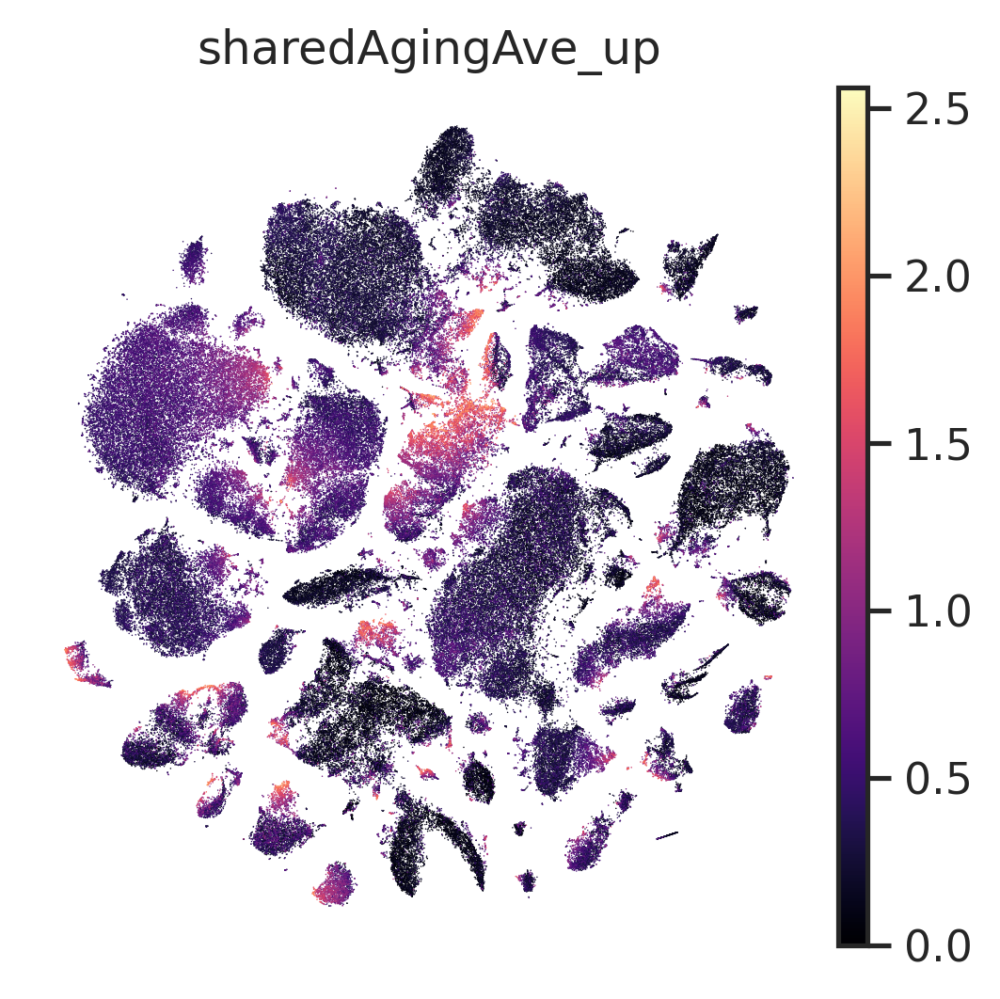

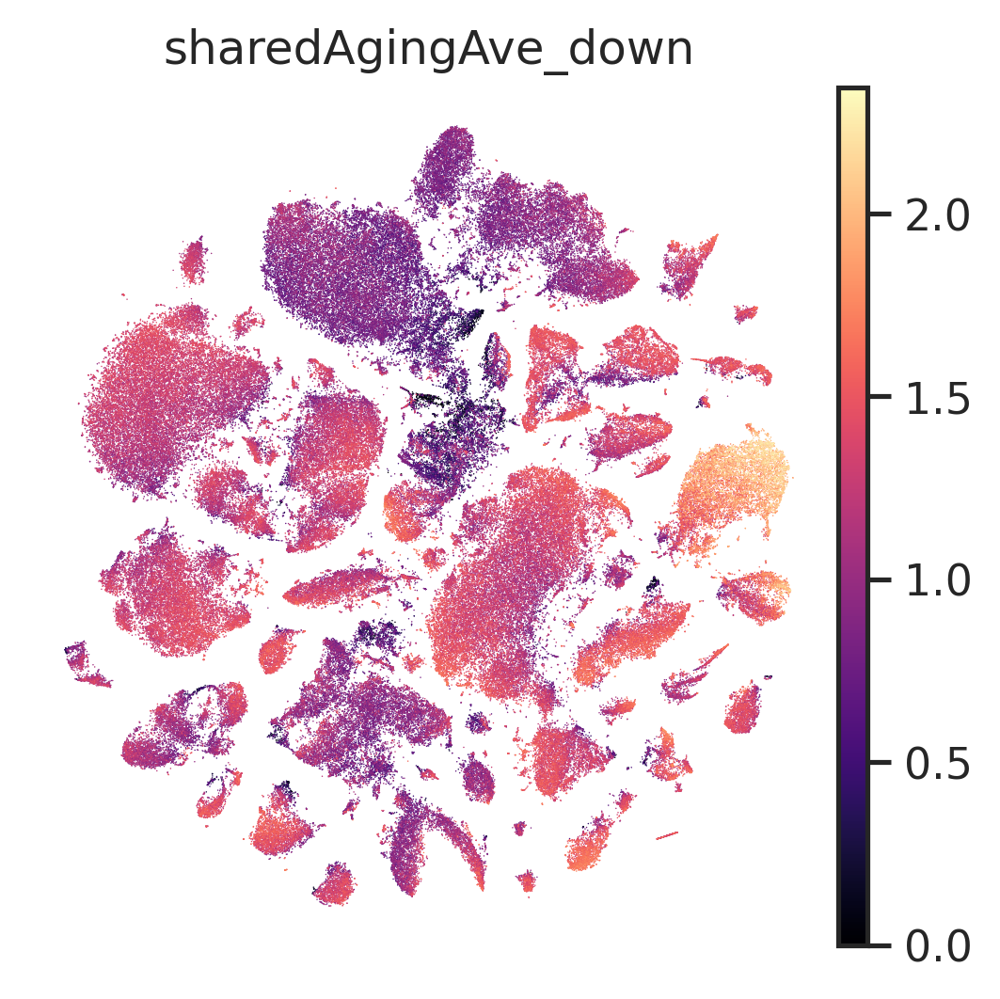

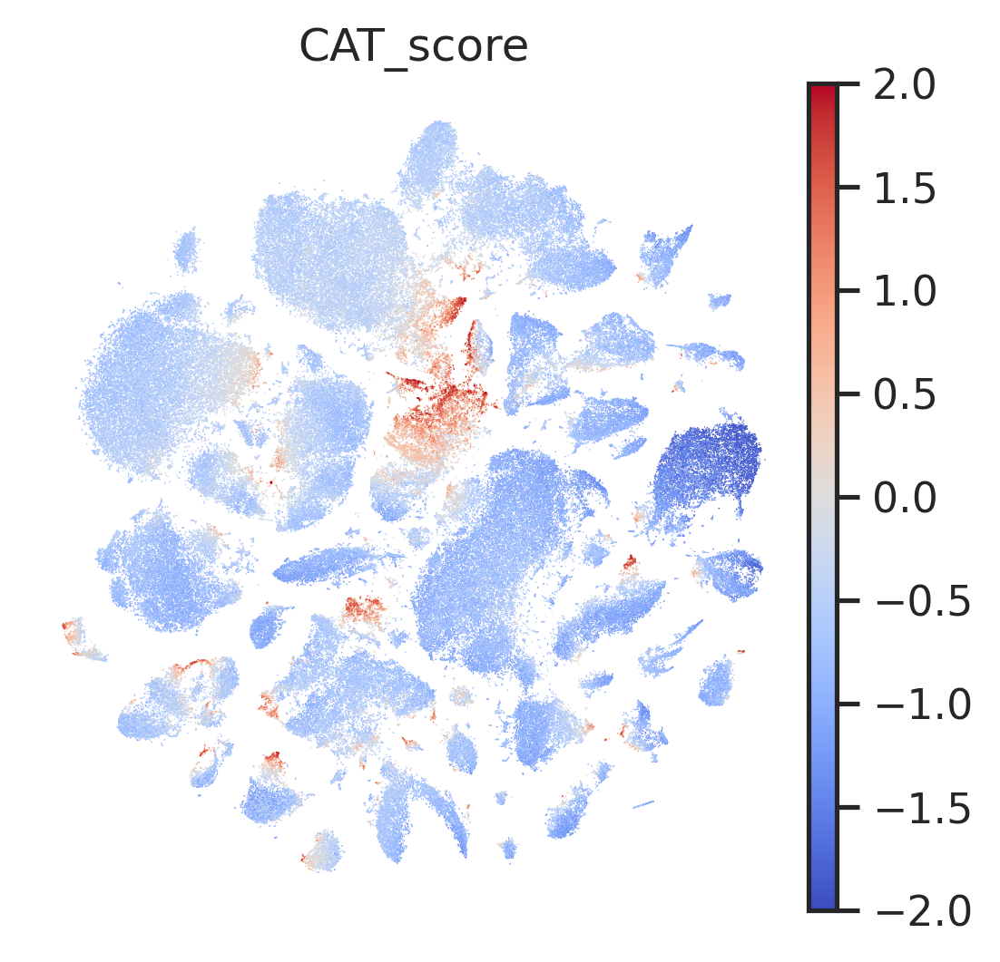

In [44]:
# body
adata_body.obs['sharedAgingAve_up'] = adata_body[:, shareUp_L].X.todense().mean(axis=1).flatten().tolist()[0]
adata_body.obs['sharedAgingAve_down'] = adata_body[:, shareDown_L].X.todense().mean(axis=1).flatten().tolist()[0]
adata_body.obs['sharedAgingAve_upMinusDown'] = adata_body.obs.sharedAgingAve_up - adata_body.obs.sharedAgingAve_down
adata_body.obs['CAT_score'] = adata_body.obs['sharedAgingAve_upMinusDown'].copy()


# plot
sc.pl.tsne(adata_body, color=['sharedAgingAve_up',], color_map='magma', frameon=False, save=f'__adata_body__sharedAgingAve_up.pdf')
sc.pl.tsne(adata_body, color=['sharedAgingAve_down'], color_map='magma', frameon=False, save=f'__adata_body__sharedAgingAve_down.pdf')
sc.pl.tsne(adata_body, color=['CAT_score'], color_map='coolwarm', frameon=False, vmin=-2, vmax=2, save=f'__adata_body__CAT_score.pdf')

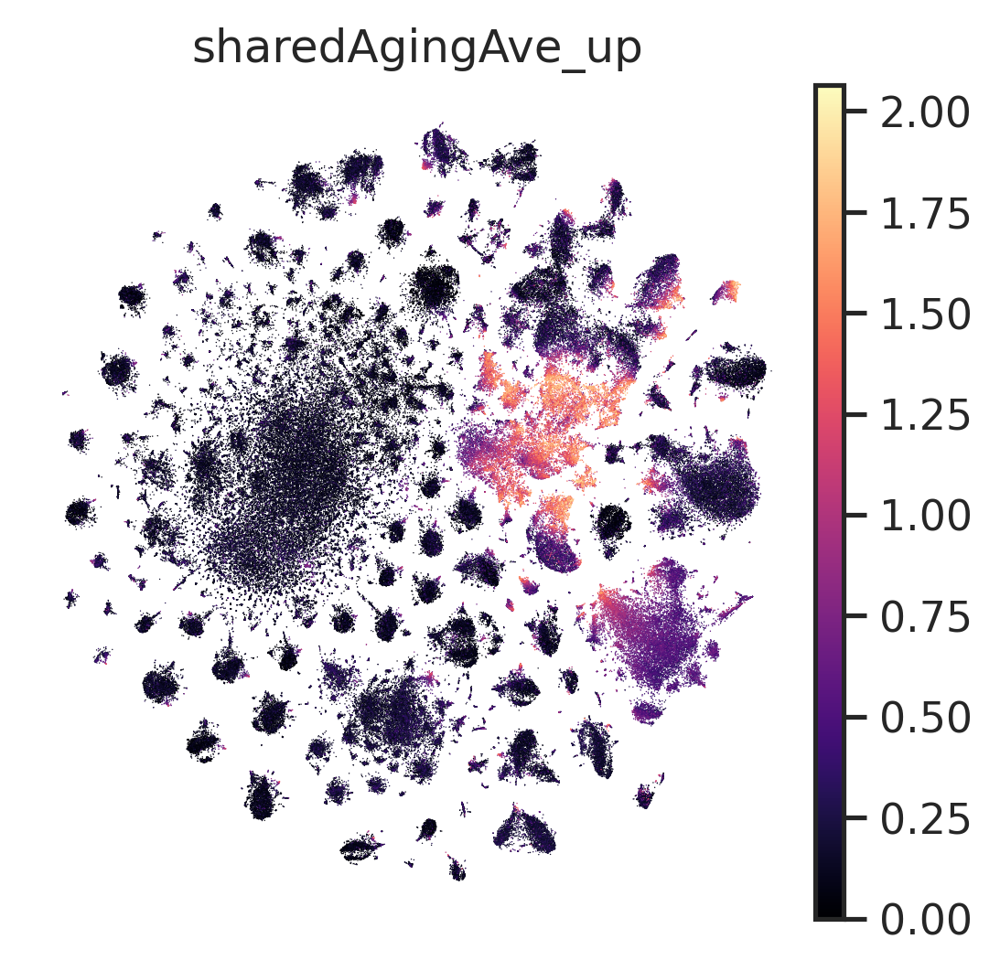

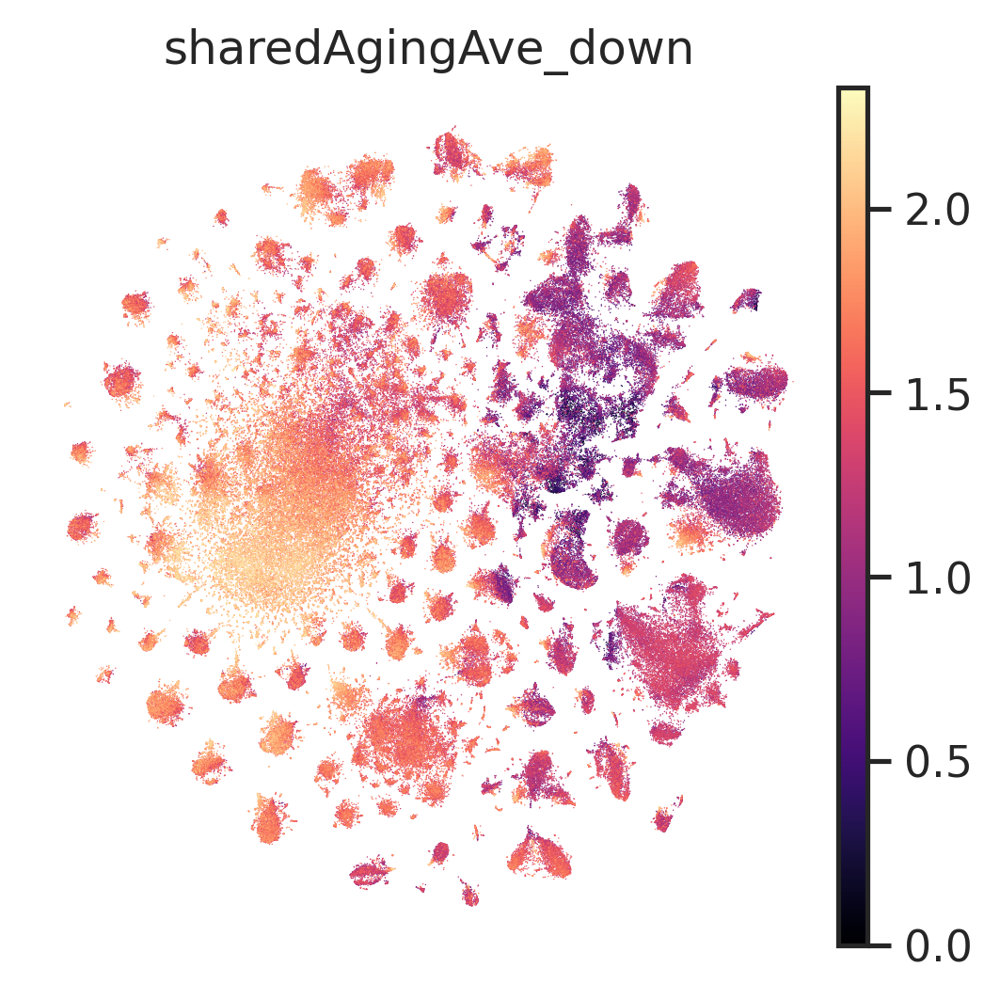

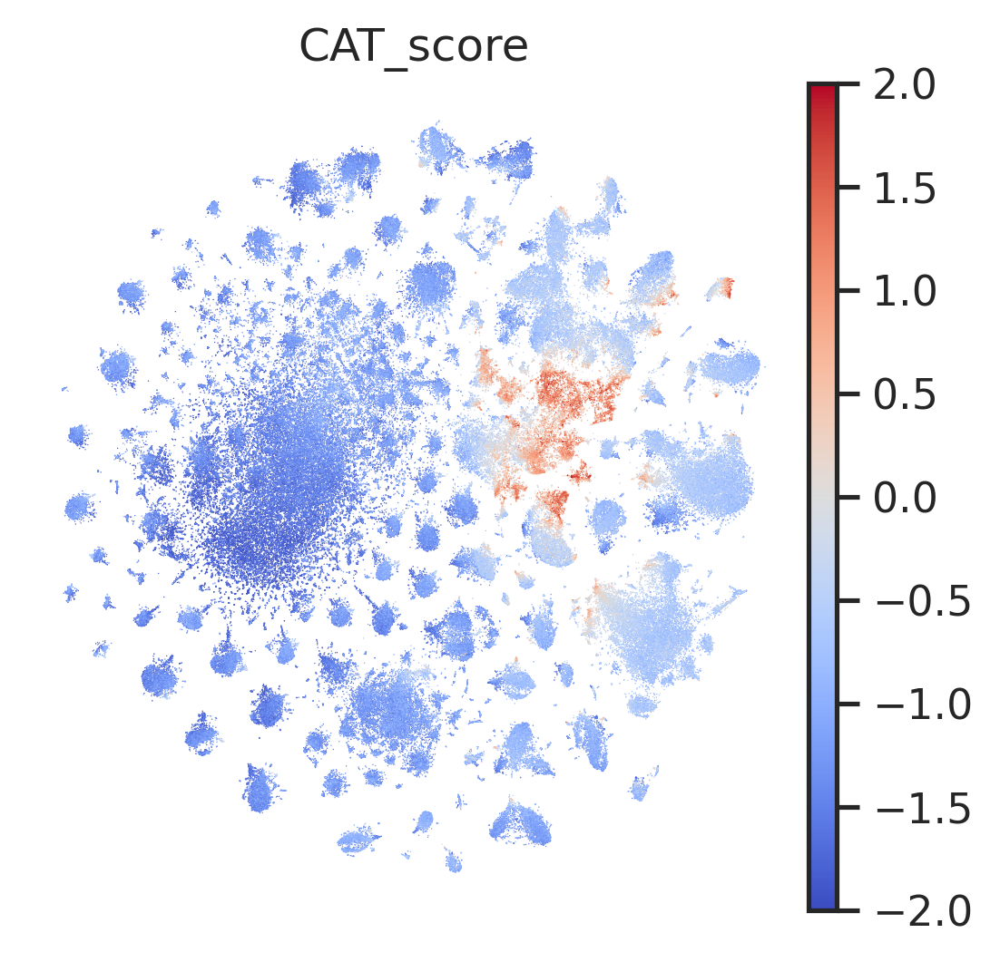

In [45]:
# head
adata_head.obs['sharedAgingAve_up'] = adata_head[:, shareUp_L].X.todense().mean(axis=1).flatten().tolist()[0]
adata_head.obs['sharedAgingAve_down'] = adata_head[:, shareDown_L].X.todense().mean(axis=1).flatten().tolist()[0]
adata_head.obs['sharedAgingAve_upMinusDown'] = adata_head.obs.sharedAgingAve_up - adata_head.obs.sharedAgingAve_down
adata_head.obs['CAT_score'] = adata_head.obs['sharedAgingAve_upMinusDown'].copy()

# plot
sc.pl.tsne(adata_head, color=['sharedAgingAve_up',], color_map='magma', frameon=False, save=f'__adata_head__sharedAgingAve_up.pdf')
sc.pl.tsne(adata_head, color=['sharedAgingAve_down'], color_map='magma', frameon=False, save=f'__adata_head__sharedAgingAve_down.pdf')
sc.pl.tsne(adata_head, color=['CAT_score'], color_map='coolwarm', frameon=False, vmin=-2, vmax=2, save=f'__adata_head__CAT_score.pdf')

### CAT group

In [46]:
mean=adata_body.obs['CAT_score'].mean()
std = adata_body.obs['CAT_score'].std()
z1 = mean + std*1
z1_5 = mean + std*1.5
z2 = mean + std*2

print(mean, std)
print(z1, z1_5, z2)

-0.727088946733654 0.5186755310287191
-0.20841341570493488 0.05092434980942462 0.3102621153237842


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


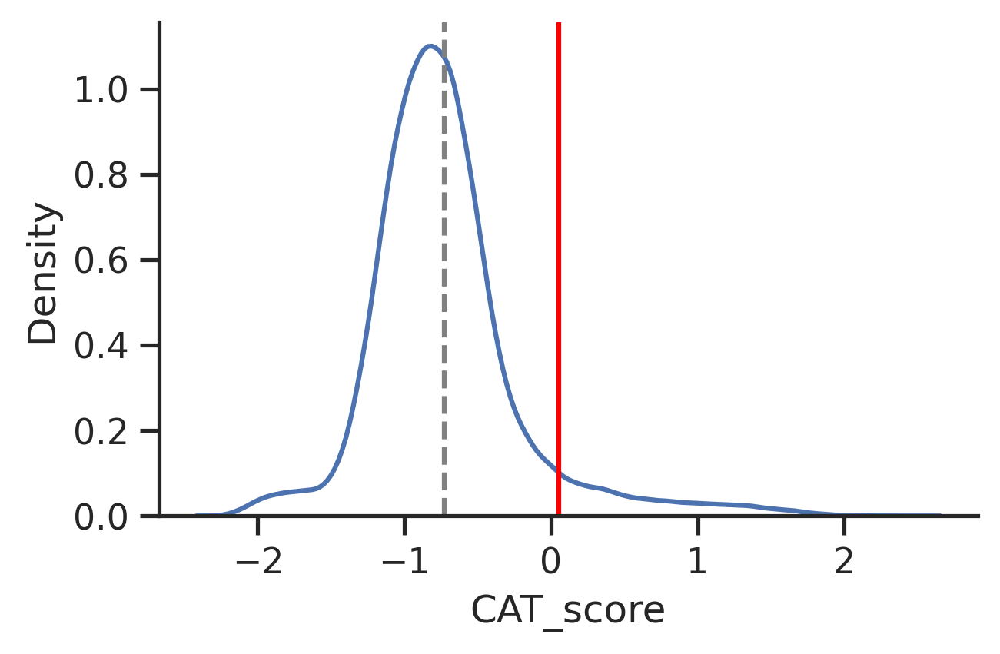

In [49]:
# with rc_context({'figure.figsize': (3, 1)}):
sns.displot(data=adata_body.obs, x='CAT_score', height=3, aspect=1.5, kind='kde')
# plt.xlim(-7.7, 7)
plt.axvline(mean, c='grey', linestyle='--')
plt.axvline(z1_5, c='red')
plt.savefig(f'{figure5PicFolder}/displot__adata_body__CAT_score.pdf')

plt.show()

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


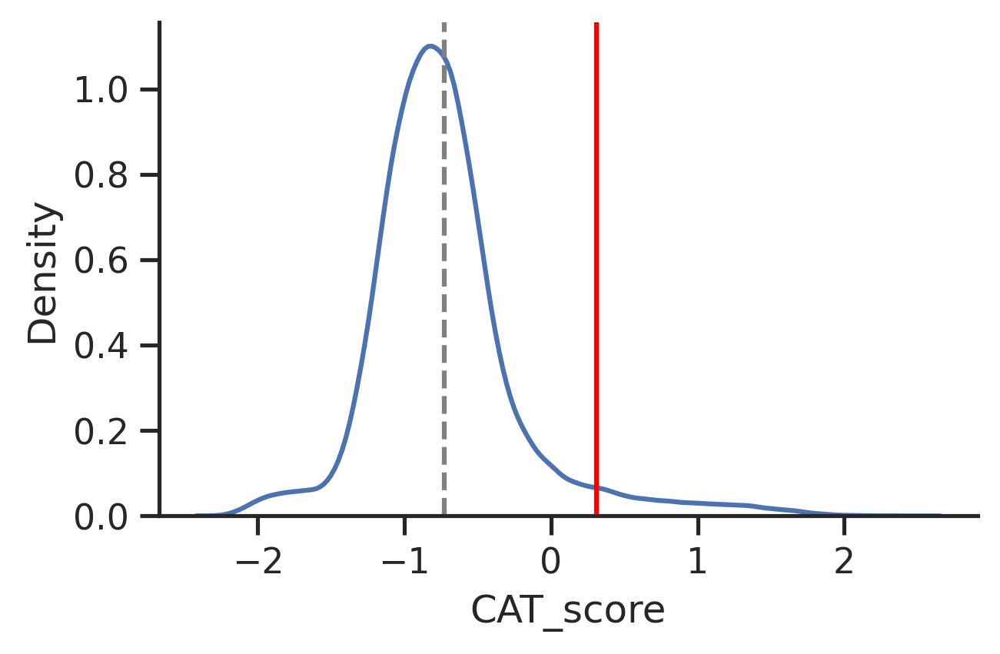

In [50]:
# with rc_context({'figure.figsize': (3, 1)}):
sns.displot(data=adata_body.obs, x='CAT_score', height=3, aspect=1.5, kind='kde')
# plt.xlim(-7.7, 7)
plt.axvline(mean, c='grey', linestyle='--')
plt.axvline(z2, c='red')
plt.savefig(f'{figure5PicFolder}/displot__adata_body__CAT_score.pdf')

plt.show()

In [51]:
adata_body.obs['CAT_group'] = pd.Categorical([ 'CAT' if score >= z2 else 'others' for score in adata_body.obs['CAT_score']  ])

In [52]:
cmap = list(sns.color_palette("Set2"))[1:3]

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


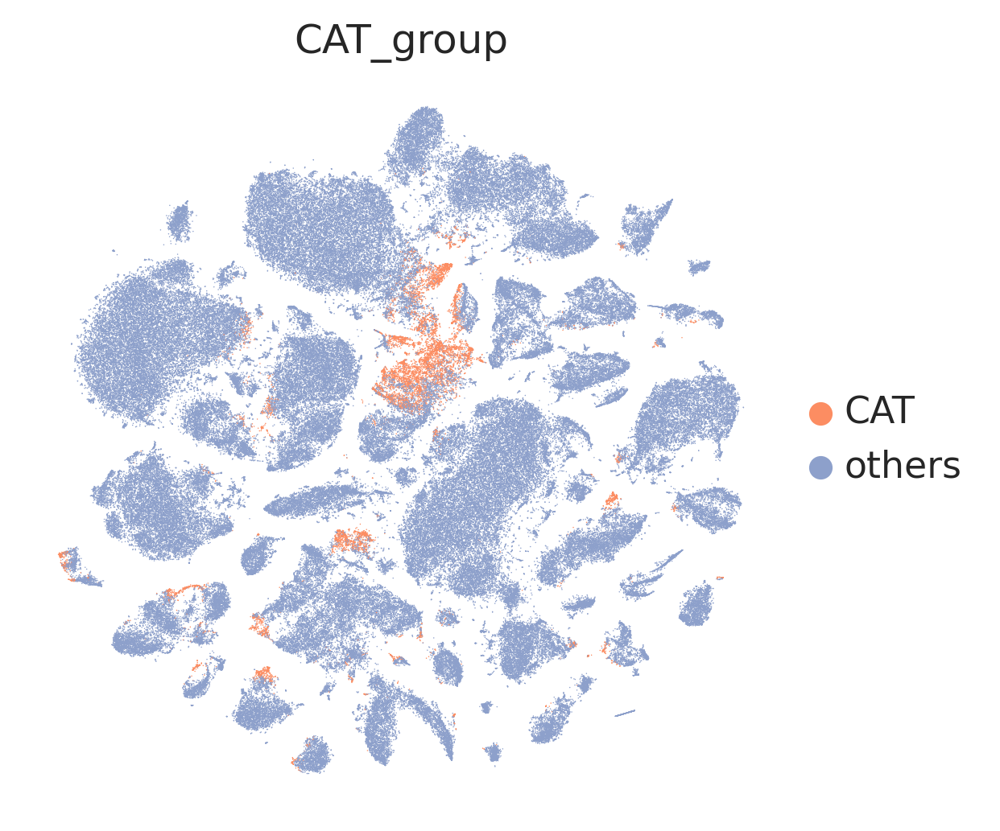

In [53]:
sc.pl.tsne(adata_body, color=['CAT_group'], frameon=False, palette=cmap, save=f'_adata_body__CAT_group_Set2.pdf')

In [54]:
# head
mean=adata_head.obs['CAT_score'].mean()
std = adata_head.obs['CAT_score'].std()
z1 = mean + std*1
z1_5 = mean + std*1.5
z2 = mean + std*2

print(mean, std)
print(z1, z1_5, z2)

-1.1218998394116557 0.6095607386674252
-0.5123391007442305 -0.20755873141051784 0.09722163792319471


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


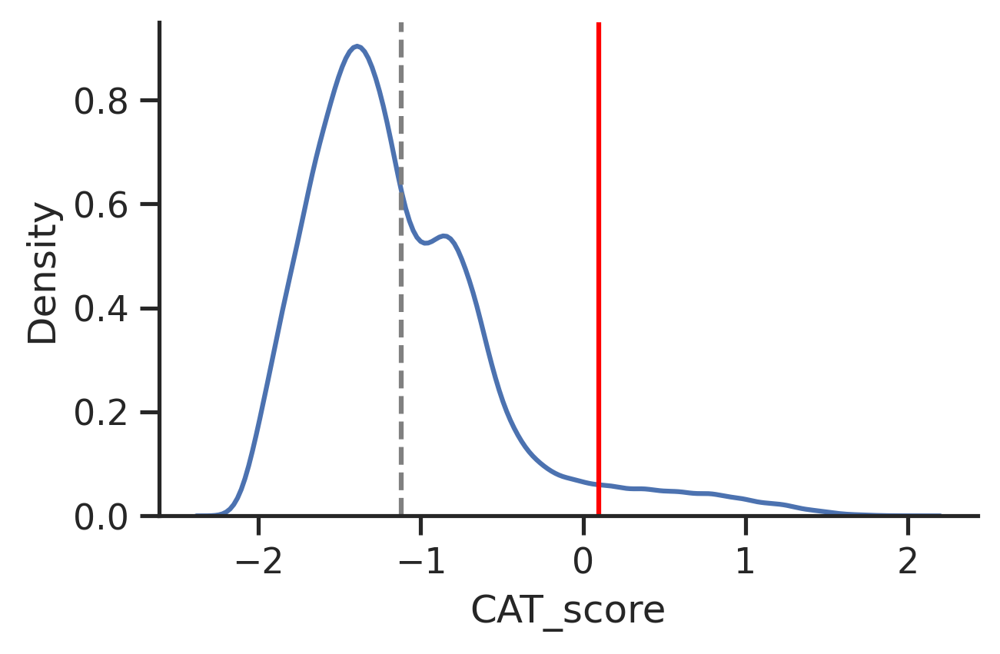

In [55]:
# with rc_context({'figure.figsize': (3, 1)}):
sns.displot(data=adata_head.obs, x='CAT_score', height=3, aspect=1.5, kind='kde')
# plt.xlim(-8, 6)
plt.axvline(mean, c='grey', linestyle='--')
plt.axvline(z2, c='red')
plt.savefig(f'{figure5PicFolder}/displot__adata_head__CAT_score.pdf')

plt.show()

In [57]:
adata_head.obs['CAT_group'] = pd.Categorical([ 'CAT' if score >= z2 else 'others' for score in adata_head.obs['CAT_score']  ])

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


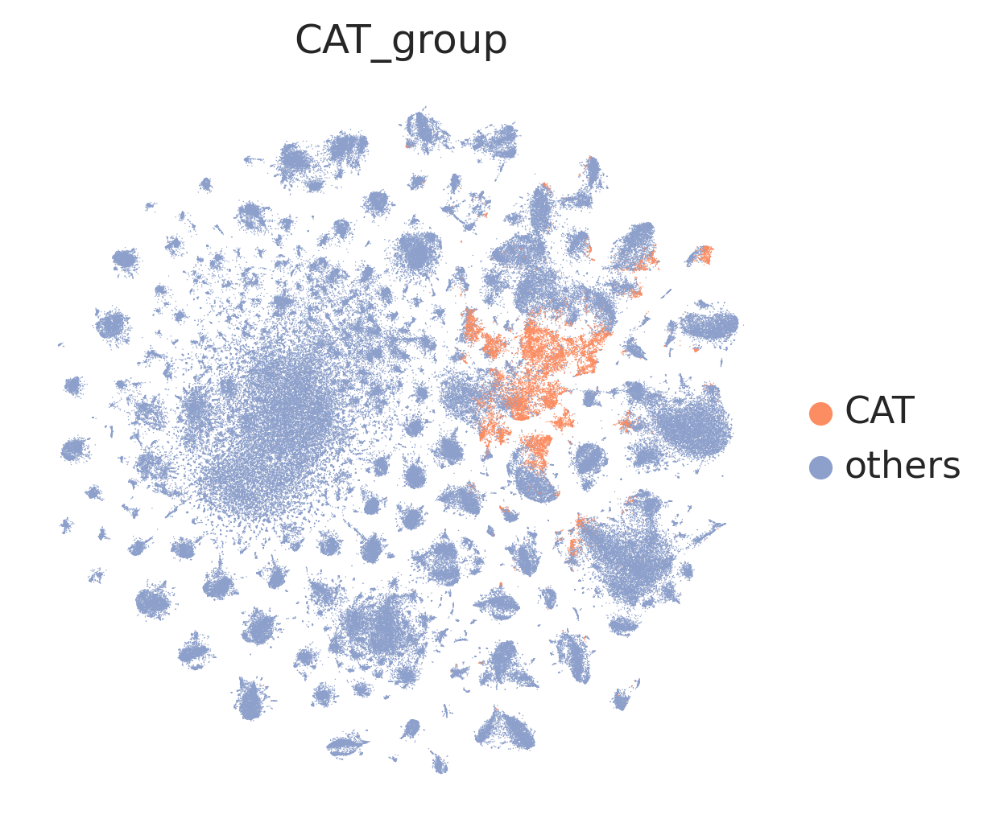

In [58]:
sc.pl.tsne(adata_head, color=['CAT_group'], frameon=False, palette=cmap, save=f'_adata_head__CAT_group_Set2.pdf')

In [59]:
for x in os.listdir('figures/'): 
    os.replace(f'figures/{x}', f'{figure5PicFolder}/{x}')

In [60]:
adata_body.write(f'{figure5Folder}/adata_body__CAT_score__CAT_group.h5ad')
adata_head.write(f'{figure5Folder}/adata_head__CAT_score__CAT_group.h5ad')

# scores in germline, male acc., VNC, epithelia cell

## Load files

In [61]:
adata_body = sc.read(f'{figure5Folder}/adata_body__CAT_score__CAT_group.h5ad')
adata_head = sc.read(f'{figure5Folder}/adata_head__CAT_score__CAT_group.h5ad')

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


In [62]:
# adata_germlineAll = sc.read(f'{figure4Folder}/adata_germline_raw.h5ad')
adata_germline = sc.read(f'{figure3Folder}/adata_germline_rapamycin__GlycolysisScore_LipidSynScore.h5ad')
adata_maleAcc = sc.read(f'{figure3Folder}/adata_maleAcc__tsne__agedLineage.h5ad')
adata_vnc = sc.read(f'{figure4Folder}/adata_vnc__tsne__agedLineage.h5ad')

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


In [63]:
bcRatio_D = dict(zip(adata_body.obs_names.to_list(), adata_body.obs['CAT_score']))
bcLineage_D = dict(zip(adata_body.obs_names.to_list(), adata_body.obs['CAT_group']))

## integrate ratios: germline, maleAcc, vnc

In [64]:
adata_D = {'germline': adata_germline, 'maleAcc': adata_maleAcc, 'vnc': adata_vnc}

In [65]:
for ct in adata_D.keys():
    print(ct)
    
    adata=adata_D[ct]
    
    adata.obs['CAT_score'] = [bcRatio_D[bc] for bc in adata.obs_names.to_list()]
    adata.obs['CAT_group'] = pd.Categorical([bcLineage_D[bc] for bc in adata.obs_names.to_list()], categories=['others', 'CAT'])

germline
maleAcc
vnc


germline


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


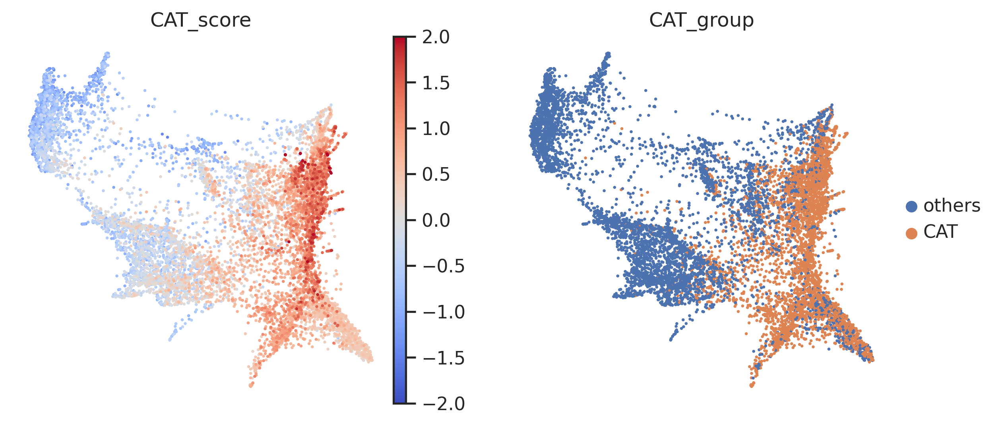

maleAcc


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


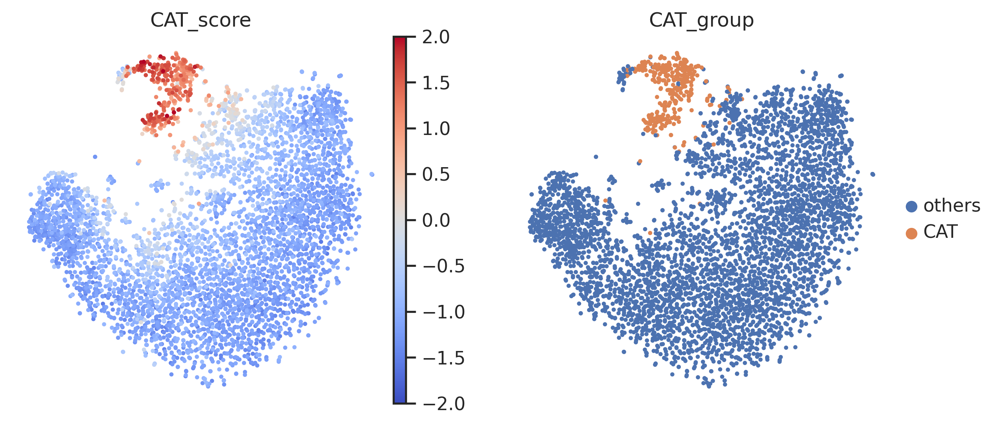

vnc


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


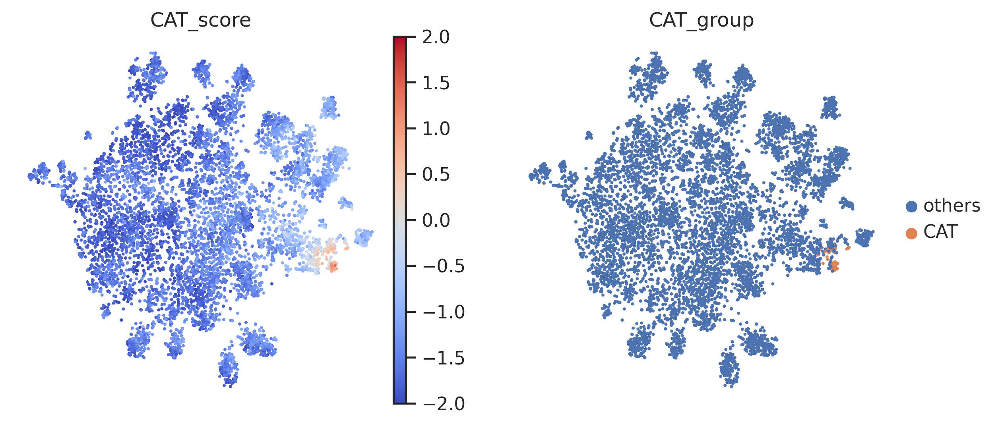

In [66]:
for ct in adata_D.keys():
    print(ct)
    if ct in ['germline', 'follicle']:
        sc.pl.draw_graph(adata_D[ct], color=['CAT_score', 'CAT_group'],  color_map='coolwarm', frameon=False, vmin=-2., vmax=2., save=f'_adata_{ct}__CAT_score__CAT_group.pdf')
    else: 
        sc.pl.tsne(adata_D[ct], color=['CAT_score', 'CAT_group'],  color_map='coolwarm', frameon=False, vmin=-2., vmax=2., save=f'_adata_{ct}__CAT_score__CAT_group.pdf')

In [67]:
for ct in adata_D.keys():
    print(ct)
    adata_D[ct].write(f'{figure5Folder}/adata_{ct}__CAT_score__CAT_group.h5ad')

germline
maleAcc
vnc


In [68]:
for x in os.listdir('figures/'): 
    os.replace(f'figures/{x}', f'{figure5PicFolder}/{x}')

## check ratios in epithlial cell & IFM

In [69]:
adata_body.obs.rapamycin_annotation.value_counts().head(20)

rapamycin_annotation
adult fat body_body                                      43669
follicle cell                                            26086
indirect flight muscle                                   22769
muscle cell                                              18494
epithelial cell_body                                     14731
adult oenocyte                                           13628
adult ventral nervous system                              9383
germline cell                                             6598
choriogenic main body follicle cell and corpus luteum     6208
crop                                                      5924
adult tracheal cell_body                                  5836
male accessory gland main cell_roX1+                      5708
unannotated                                               5370
hemocyte_body                                             4458
enterocyte of anterior adult midgut epithelium            4039
ejaculatory bulb                  

In [70]:
ct_L = ['indirect flight muscle', 'epithelial cell_body', 'ejaculatory bulb']

In [71]:
for ct in ct_L:
    print(ct)

    adata = adata_body[ adata_body.obs.rapamycin_annotation == ct ] # & (~adata_body.obs.age.isin(['70']))
    sc.pp.neighbors(adata, n_neighbors=15, n_pcs=50)
    sc.tl.tsne(adata, n_pcs=50)
    sc.tl.umap(adata)
    
    adata.write(f'{figure5Folder}/adata_{ct}__CAT_score__CAT_group.h5ad')

indirect flight muscle
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:17)
computing tSNE
    using 'X_pca' with n_pcs = 50
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:03:17)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:15)
epithelial cell_body
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:01)
computing tSNE
    using 'X_pca' with n_pcs = 50
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:01:56)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:09)
ejaculatory bu

indirect flight muscle


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pa

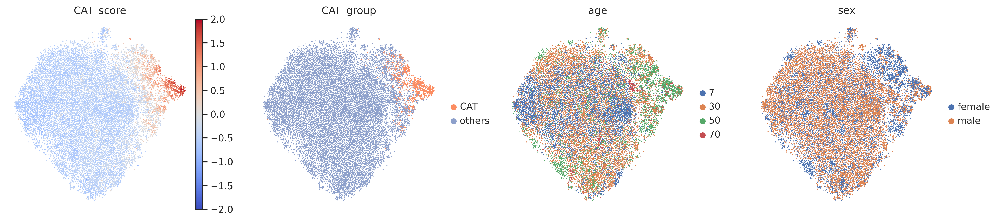

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map)

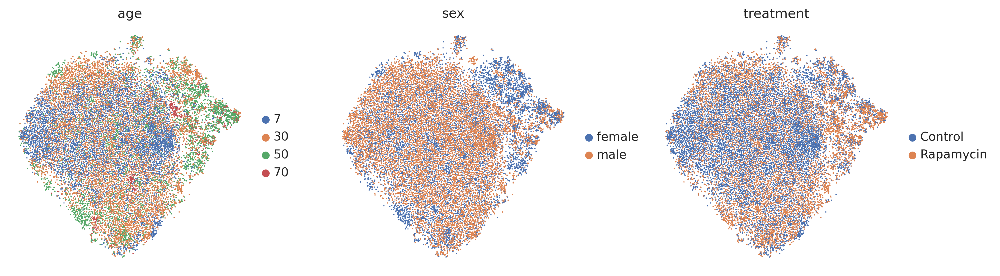

epithelial cell_body


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` paramete

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


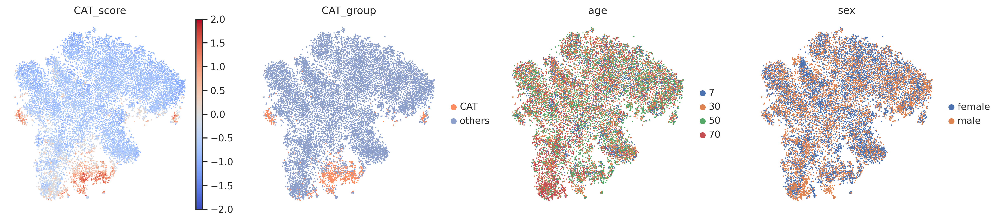

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map)

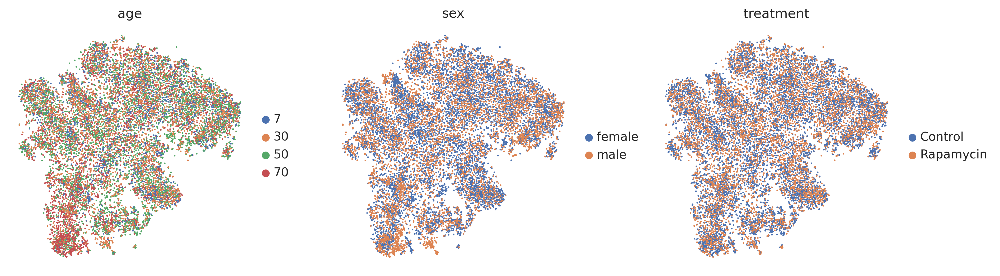

ejaculatory bulb


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` paramete

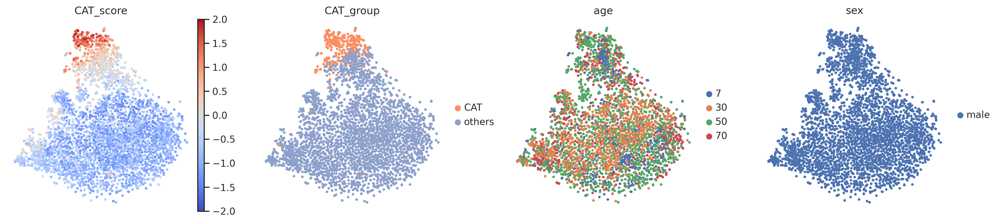

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map)

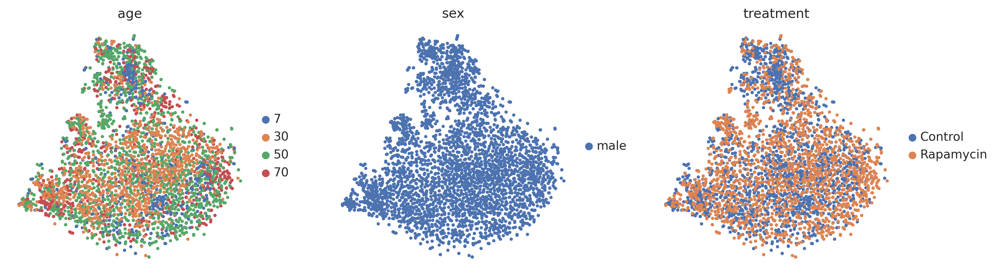

In [72]:
for ct in ct_L:
    print(ct)

    adata = sc.read(f'{figure5Folder}/adata_{ct}__CAT_score__CAT_group.h5ad')
    adata.obs.CAT_group = pd.Categorical(adata.obs.CAT_group, categories=['CAT', 'others'])
    sc.pl.tsne(adata, color=['CAT_score', 'CAT_group', 'age', 'sex'],  color_map='coolwarm', frameon=False, vmin=-2., vmax=2., save=f'_adata_{ct}__CAT_score__CAT_group.pdf')
    sc.pl.tsne(adata, color=['age', 'sex', 'treatment'],  color_map='coolwarm', frameon=False, save=f'_adata_{ct}__age_sex_treatment.pdf')

In [73]:
for x in os.listdir('figures/'): 
    os.replace(f'figures/{x}', f'{figure5PicFolder}/{x}')

## Plot shared aging groups

### Plot ratio of shared aging group: germline

In [108]:
adata_germline = sc.read(f'{figure5Folder}/adata_germline__CAT_score__CAT_group.h5ad')
adata_germline

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


AnnData object with n_obs × n_vars = 9198 × 2000
    obs: 'fca_annotation', 'afca_annotation', 'afca_annotation_broad', 'adfca_annotation', 'adfca_annotation_broad', 'adfca_annotation_group', 'adfca_annotation_subcluster', 'linearR_annotation', 'dataset', 'age', 'sex', 'tissue', 'condition', 'leiden', 'treatment', 'treatAge', 'leiden_0.2', 'leiden_0.3', 'leiden_0.4', 'leiden_0.45', 'leiden_0.5', 'leiden_0.55', 'leiden_0.6', 'rapamycin_annotation_subcluster', 'S_score', 'G2M_score', 'phase', 'dpt_pseudotime', 'lineage', 'GlycolysisScore', 'LipidSynScore', 'CAT_score', 'CAT_group'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'CAT_group_colors', 'age_colors', 'dataset_colors', 'diffmap_evals', 'draw_graph', 'hvg', 'iroot', 'leiden', 'leiden_0.45_colors', 'leiden_0.4_colors', 'leiden_0.55_colors', 'leiden_0.5_colors', 'leiden_colors', 'lineage_colors', 'neighbors', 'paga', 'pca', '

In [109]:
adata_germline.obs.dataset.cat.categories

Index(['Rapamycin'], dtype='object')

In [110]:
adata_germline.obs.CAT_group = pd.Categorical(adata_germline.obs.CAT_group, categories=['others', 'CAT'])
adata_germline.obs.CAT_group.cat.categories

Index(['others', 'CAT'], dtype='object')

In [111]:
adata_germline.obs.treatAge.cat.categories

Index(['Control_7', 'Control_30', 'Control_50', 'Control_70', 'Rapamycin_30',
       'Rapamycin_50', 'Rapamycin_70'],
      dtype='object')

In [112]:
cmap = list(sns.color_palette("Set2"))[1:3]

In [113]:
cellN_Df, cellN_ratio = cellN_cellRatio(adata_germline[(adata_germline.obs.age != '70') & (adata_germline.obs.lineage != 'young germ cell')], 'treatAge', 'CAT_group')

<ipython-input-35-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


In [114]:
cellN_ratio

,others,CAT
Control_7,0.911275,0.088725
Control_30,0.870345,0.129655
Control_50,0.283931,0.716069
Rapamycin_30,0.877834,0.122166
Rapamycin_50,0.636872,0.363128


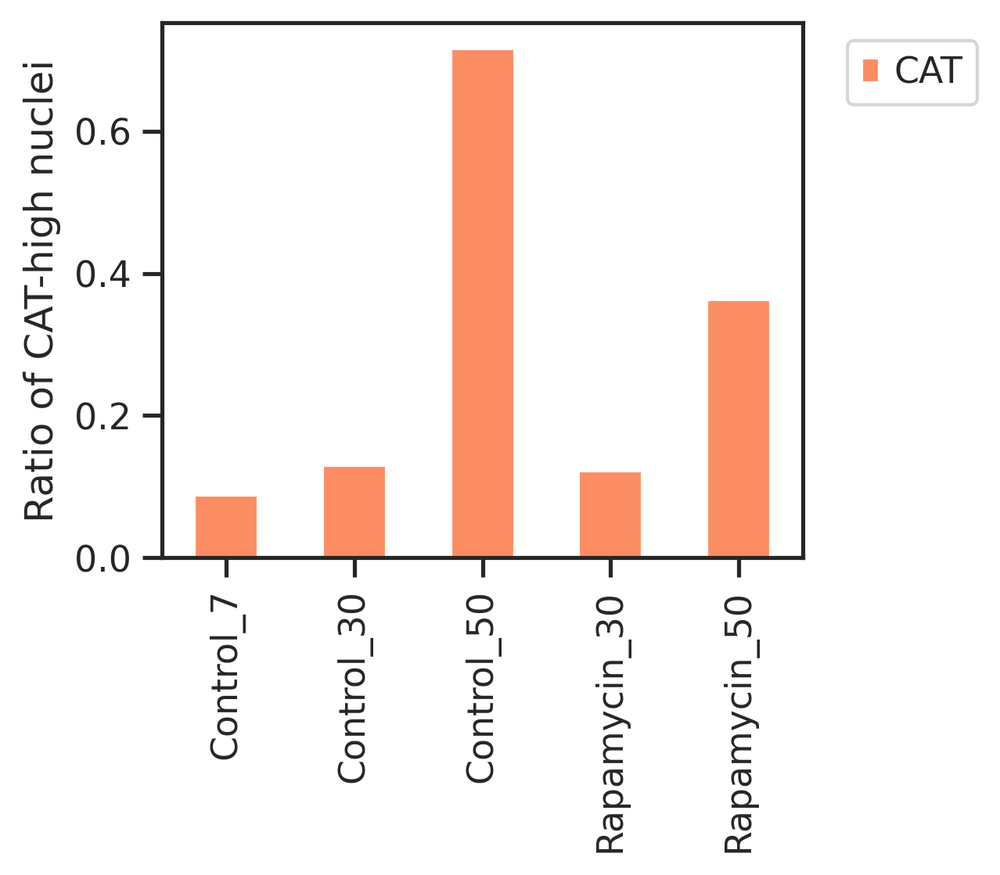

In [115]:
cellN_ratio.iloc[:,1:].plot( kind='bar', stacked=True, figsize=(3.5, 3), color=cmap)
plt.legend(bbox_to_anchor=(1.3, 1.0))
plt.ylabel('Ratio of CAT-high nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__CAT_group__germline.pdf', bbox_inches='tight')

In [124]:
cellN_Df, cellN_ratio = cellN_cellRatio(adata_germline[(adata_germline.obs.age != '70')], 'treatAge', 'CAT_group')

<ipython-input-35-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


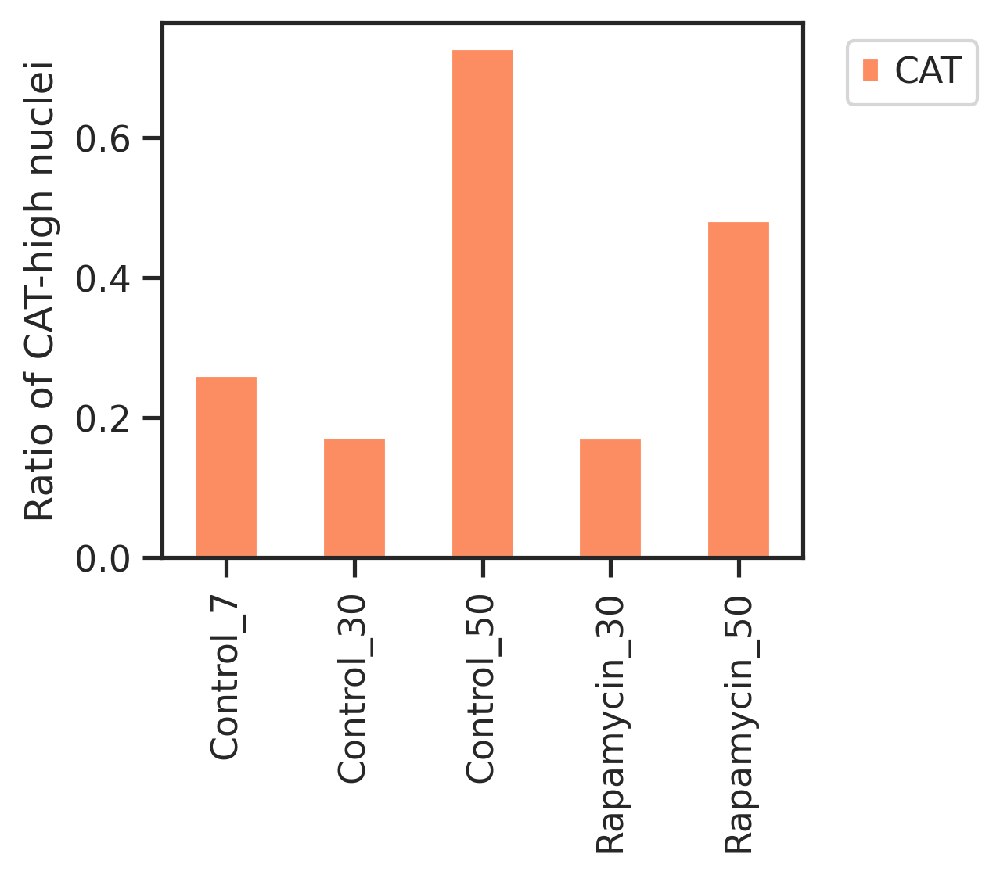

In [125]:
cellN_ratio.iloc[:,1:].plot( kind='bar', stacked=True, figsize=(3.5, 3), color=cmap)
plt.legend(bbox_to_anchor=(1.3, 1.0))
plt.ylabel('Ratio of CAT-high nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__CAT_group__germline_includeYoungGerm_orange.pdf', bbox_inches='tight')

In [126]:
cellN_ratio_no70 = cellN_ratio.loc[ [idx for idx in cellN_ratio.index if '70' not in idx ] ]
cellN_ratio_no70

,others,CAT
Control_7,0.738764,0.261236
Control_30,0.82716,0.17284
Control_50,0.272233,0.727767
Rapamycin_30,0.82907,0.17093
Rapamycin_50,0.518441,0.481559


In [127]:
cellN_ratio_no70['color'] = ['#dfc27d', '#dfc27d', '#dfc27d','#01665e','#01665e' ]

In [128]:
cellN_ratio_no70

,others,CAT,color
Control_7,0.738764,0.261236,#dfc27d
Control_30,0.82716,0.17284,#dfc27d
Control_50,0.272233,0.727767,#dfc27d
Rapamycin_30,0.82907,0.17093,#01665e
Rapamycin_50,0.518441,0.481559,#01665e


In [129]:
cellN_ratio_no70.insert(0, 'group',cellN_ratio_no70.index.to_list())

In [130]:
cellN_ratio_no70.columns

Index(['group', 'others', 'CAT', 'color'], dtype='object')

In [131]:
from matplotlib.patches import Patch

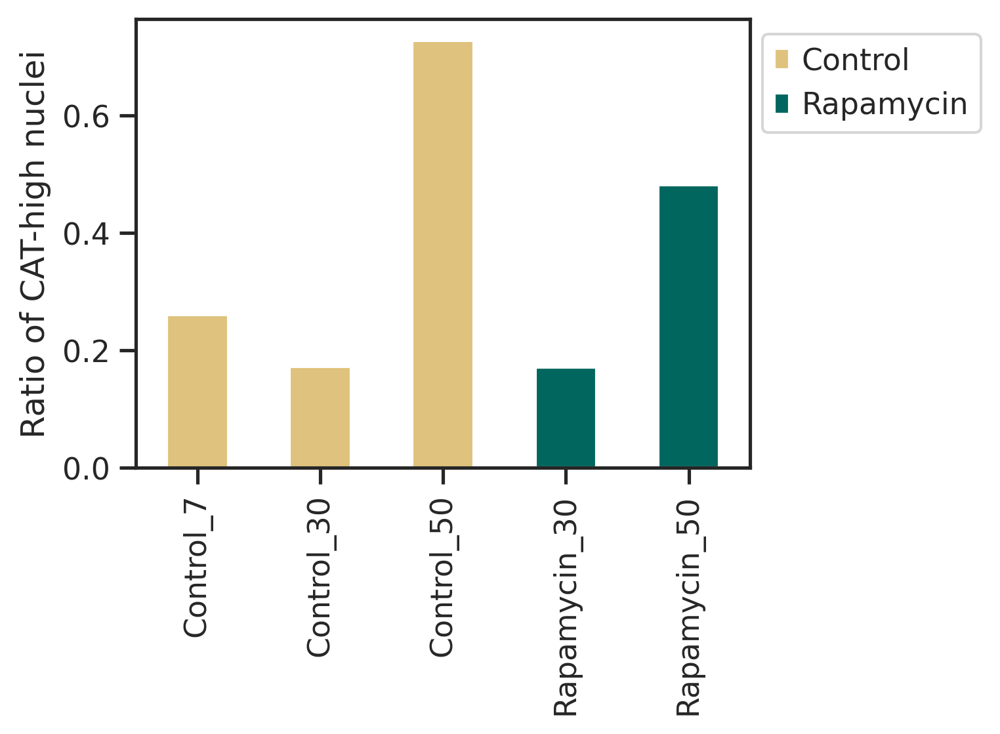

In [132]:
# Create the plot
ax = cellN_ratio_no70['CAT'].plot(kind='bar', figsize=(4, 3), color=cellN_ratio_no70['color'])

# Create custom legend
legend_elements = [Patch(facecolor='#dfc27d', label='Control'), Patch(facecolor='#01665e', label='Rapamycin')]
ax.legend(handles=legend_elements, bbox_to_anchor=(1.4, 1.0)) # loc='best'
ax.set(ylabel='Ratio of CAT-high nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__CAT_group__germline_includeYoungGerm.pdf', bbox_inches='tight')

### Plot ratio of shared aging group: Male accessory gland

In [133]:
adata_maleAcc.obs.CAT_group = pd.Categorical(adata_maleAcc.obs.CAT_group, categories=['others', 'CAT'])
adata_maleAcc.obs.treatAge = pd.Categorical(adata_maleAcc.obs.treatAge, categories=['Control_7', 'Control_30', 'Control_50', 'Control_70', 'Rapamycin_30', 'Rapamycin_50', 'Rapamycin_70'])

In [134]:
cmap = list(sns.color_palette("Set2"))[1:3]

In [135]:
cellN_Df, cellN_ratio = cellN_cellRatio(adata_maleAcc[(adata_maleAcc.obs.age != '70')], 'treatAge', 'CAT_group')

<ipython-input-35-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


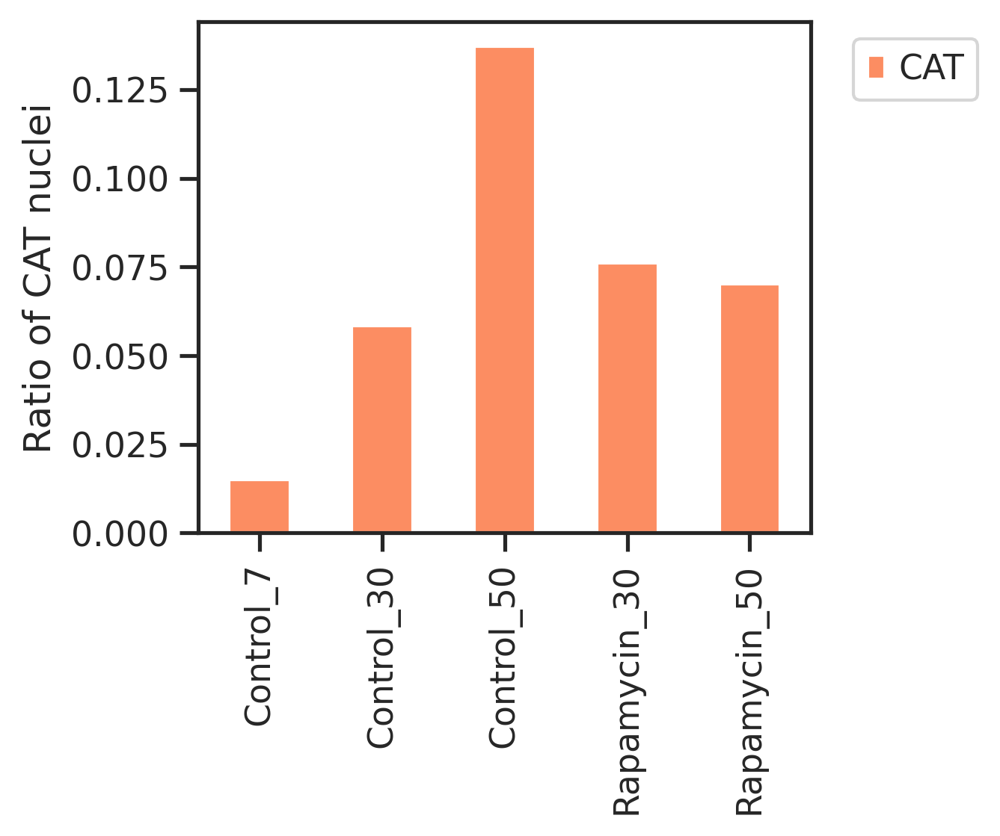

In [136]:
cellN_ratio.iloc[:,1:].plot( kind='bar', stacked=True, figsize=(3.5, 3), color=cmap)
plt.legend(bbox_to_anchor=(1.3, 1.0))
plt.ylabel('Ratio of CAT nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__CAT_group__maleAcc_orange.pdf', bbox_inches='tight')

In [137]:
cellN_ratio['color'] = ['#dfc27d', '#dfc27d', '#dfc27d','#01665e','#01665e' ]

In [138]:
cellN_ratio

,others,CAT,color
Control_7,0.984971,0.015029,#dfc27d
Control_30,0.941586,0.058414,#dfc27d
Control_50,0.862808,0.137192,#dfc27d
Rapamycin_30,0.92395,0.07605,#01665e
Rapamycin_50,0.92981,0.07019,#01665e


In [139]:
cellN_ratio.insert(0, 'group',cellN_ratio.index.to_list())

In [140]:
cellN_ratio.columns

Index(['group', 'others', 'CAT', 'color'], dtype='object')

In [141]:
from matplotlib.patches import Patch

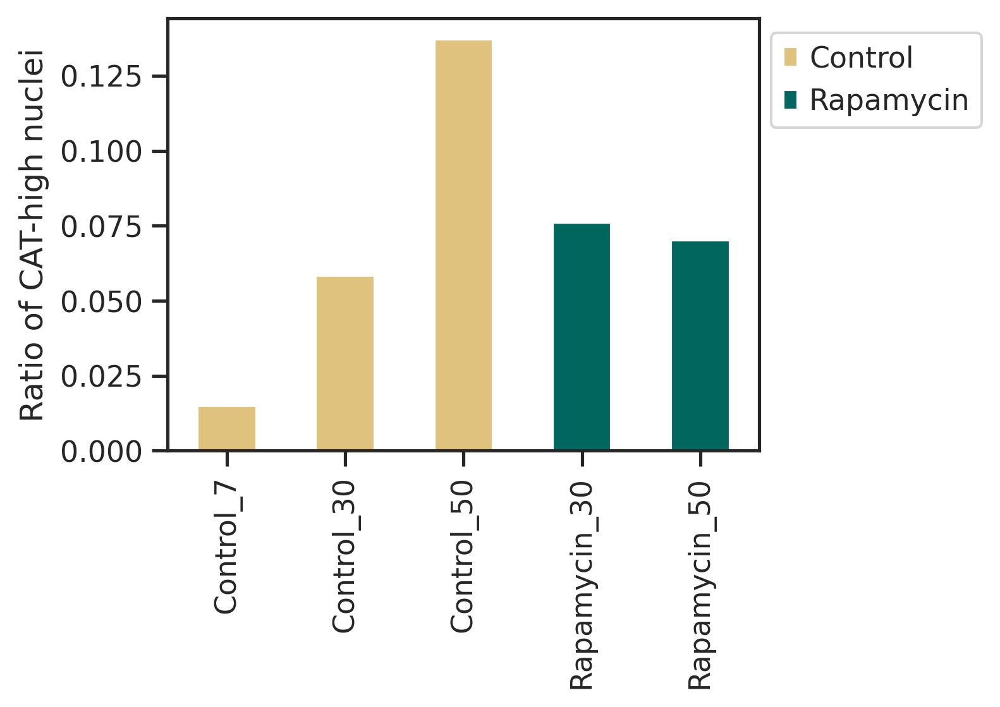

In [142]:
# Create the plot
ax = cellN_ratio['CAT'].plot(kind='bar', figsize=(4, 3), color=cellN_ratio_no70['color'])

# Create custom legend
legend_elements = [Patch(facecolor='#dfc27d', label='Control'), Patch(facecolor='#01665e', label='Rapamycin')]
ax.legend(handles=legend_elements, bbox_to_anchor=(1.4, 1.0)) # loc='best'
ax.set(ylabel='Ratio of CAT-high nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__CAT_group__maleAcc.pdf', bbox_inches='tight')

Whole body

In [143]:
adata_body.obs.treatAgeSex.cat.categories

Index(['Control_30_female', 'Control_30_male', 'Control_50_female',
       'Control_50_male', 'Control_70_female', 'Control_70_male',
       'Control_7_female', 'Control_7_male', 'Rapamycin_30_female',
       'Rapamycin_30_male', 'Rapamycin_50_female', 'Rapamycin_50_male',
       'Rapamycin_70_female', 'Rapamycin_70_male'],
      dtype='object')

In [144]:
adata_body.obs.CAT_group = pd.Categorical(adata_body.obs.CAT_group, categories=['others', 'CAT'])
adata_body.obs.treatAgeSex = pd.Categorical(adata_body.obs.treatAgeSex, categories=['Control_7_female', 'Control_30_female', 'Control_50_female', 'Control_70_female', 
                                                                              'Rapamycin_30_female', 'Rapamycin_50_female', 'Rapamycin_70_female',
                                                                              'Control_7_male', 'Control_30_male', 'Control_50_male', 'Control_70_male', 
                                                                              'Rapamycin_30_male', 'Rapamycin_50_male', 'Rapamycin_70_male'])

In [145]:
cmap = list(sns.color_palette("Set2"))[1:3]

In [153]:
cellN_Df, cellN_ratio = cellN_cellRatio(adata_body[(adata_body.obs.age != '70')], 'treatAgeSex', 'CAT_group')

<ipython-input-35-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


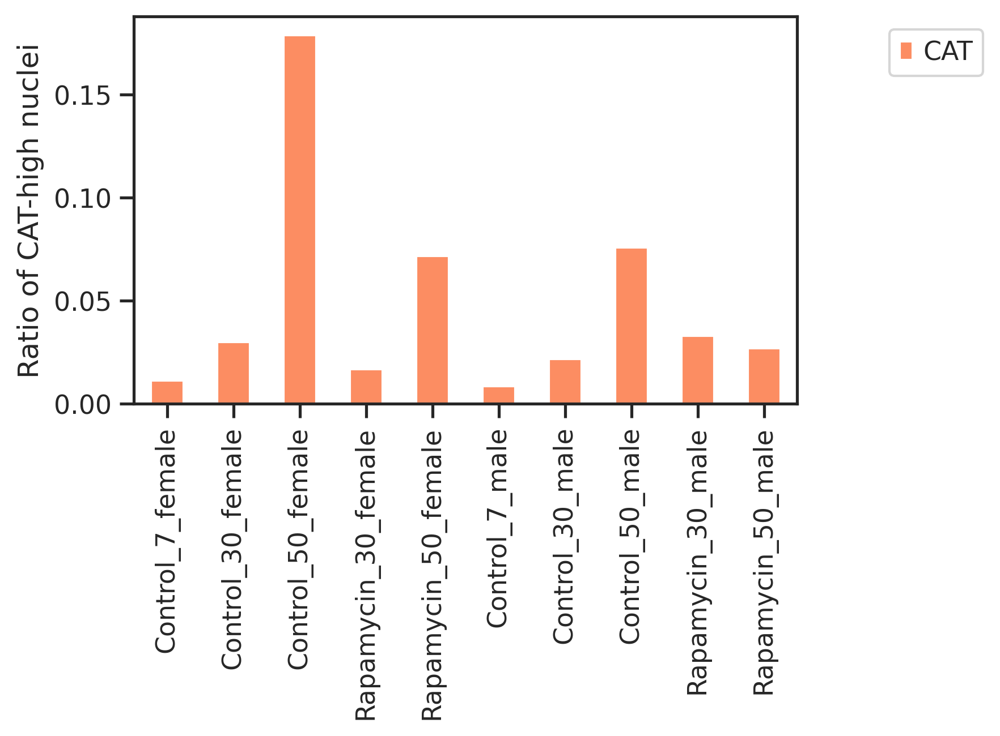

In [154]:
cellN_ratio.iloc[:,1:].plot( kind='bar', stacked=True, figsize=(5, 3), color=cmap)
plt.legend(bbox_to_anchor=(1.3, 1.0))
plt.ylabel('Ratio of CAT-high nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__CAT_group__body_orange.pdf', bbox_inches='tight')

In [155]:
cellN_ratio['color'] = ['#dfc27d', '#dfc27d', '#dfc27d','#01665e','#01665e' ]*2

In [156]:
cellN_ratio

,others,CAT,color
Control_7_female,0.988604,0.011396,#dfc27d
Control_30_female,0.970111,0.029889,#dfc27d
Control_50_female,0.821194,0.178806,#dfc27d
Rapamycin_30_female,0.983254,0.016746,#01665e
Rapamycin_50_female,0.928197,0.071803,#01665e
Control_7_male,0.991465,0.008535,#dfc27d
Control_30_male,0.978116,0.021884,#dfc27d
Control_50_male,0.924042,0.075958,#dfc27d
Rapamycin_30_male,0.967108,0.032892,#01665e
Rapamycin_50_male,0.973014,0.026986,#01665e


In [157]:
cellN_ratio.insert(0, 'group',cellN_ratio.index.to_list())

In [158]:
cellN_ratio.columns

Index(['group', 'others', 'CAT', 'color'], dtype='object')

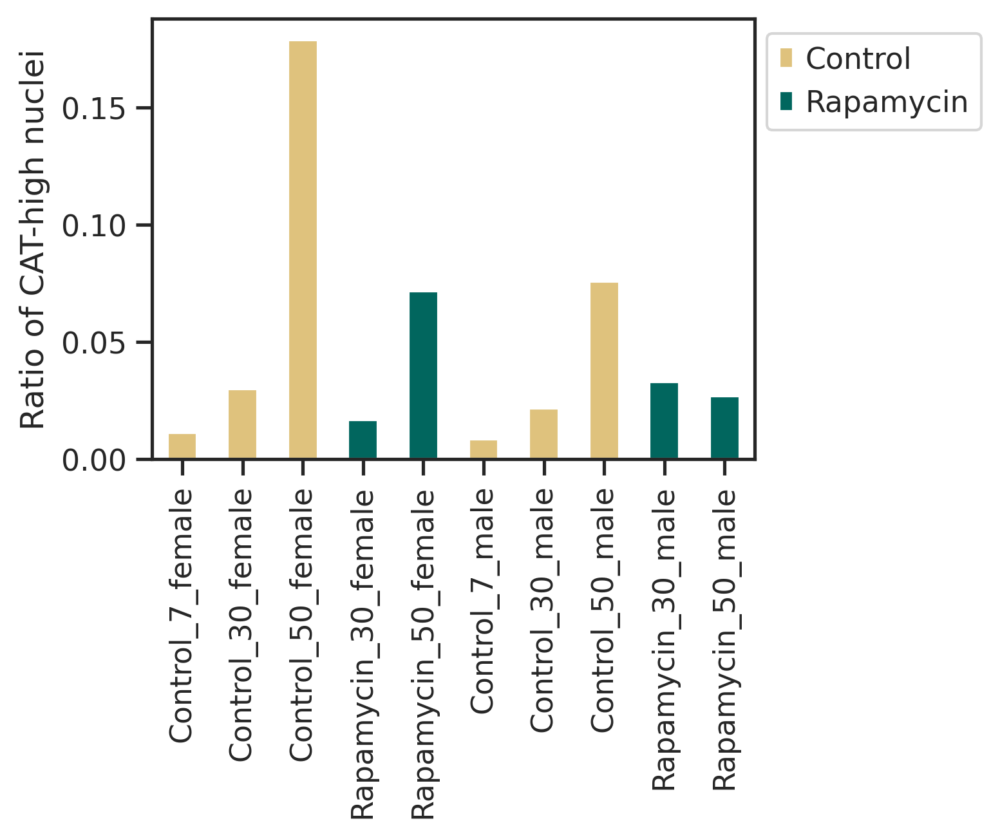

In [159]:
# Create the plot
ax = cellN_ratio['CAT'].plot(kind='bar', figsize=(4, 3), color=cellN_ratio_no70['color'])

# Create custom legend
legend_elements = [Patch(facecolor='#dfc27d', label='Control'), Patch(facecolor='#01665e', label='Rapamycin')]
ax.legend(handles=legend_elements, bbox_to_anchor=(1.4, 1.0)) # loc='best'
ax.set(ylabel='Ratio of CAT-high nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__CAT_group__body.pdf', bbox_inches='tight')

Whole head

In [160]:
adata_head.obs.treatAgeSex.cat.categories

Index(['Control_7_female', 'Control_30_female', 'Control_50_female',
       'Control_70_female', 'Rapamycin_30_female', 'Rapamycin_50_female',
       'Rapamycin_70_female', 'Control_7_male', 'Control_30_male',
       'Control_50_male', 'Control_70_male', 'Rapamycin_30_male',
       'Rapamycin_50_male', 'Rapamycin_70_male'],
      dtype='object')

In [161]:
adata_head.obs.CAT_group = pd.Categorical(adata_head.obs.CAT_group, categories=['others', 'CAT'])
adata_head.obs.treatAgeSex = pd.Categorical(adata_head.obs.treatAgeSex, categories=['Control_7_female', 'Control_30_female', 'Control_50_female', 'Control_70_female', 
                                                                              'Rapamycin_30_female', 'Rapamycin_50_female', 'Rapamycin_70_female',
                                                                              'Control_7_male', 'Control_30_male', 'Control_50_male', 'Control_70_male', 
                                                                              'Rapamycin_30_male', 'Rapamycin_50_male', 'Rapamycin_70_male'])

In [162]:
cmap = list(sns.color_palette("Set2"))[1:3]

In [163]:
cellN_Df, cellN_ratio = cellN_cellRatio(adata_head[(adata_head.obs.age != '70')], 'treatAgeSex', 'CAT_group')

<ipython-input-35-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


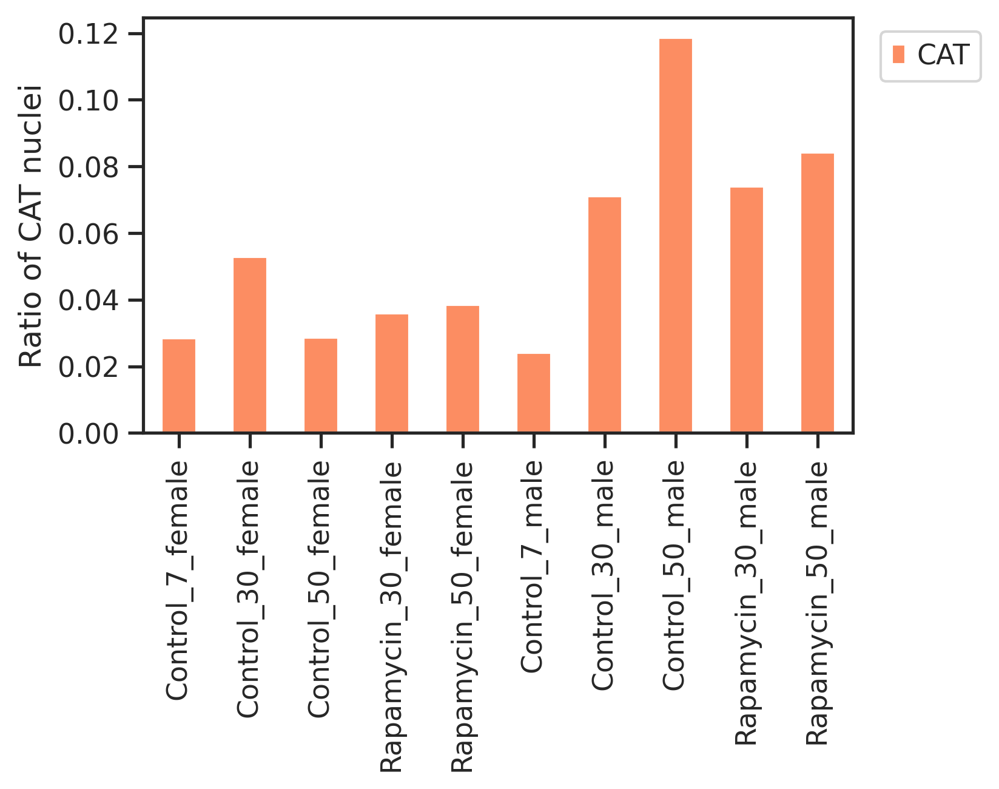

In [164]:
cellN_ratio.iloc[:,1:].plot( kind='bar', stacked=True, figsize=(5, 3), color=cmap)
plt.legend(bbox_to_anchor=(1.2, 1.0))
plt.ylabel('Ratio of CAT nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__CAT_group__head_orange.pdf', bbox_inches='tight')

In [165]:
cellN_ratio['color'] = ['#dfc27d', '#dfc27d', '#dfc27d','#01665e','#01665e' ]*2

In [166]:
cellN_ratio

,others,CAT,color
Control_7_female,0.971461,0.028539,#dfc27d
Control_30_female,0.947065,0.052935,#dfc27d
Control_50_female,0.971356,0.028644,#dfc27d
Rapamycin_30_female,0.964122,0.035878,#01665e
Rapamycin_50_female,0.961461,0.038539,#01665e
Control_7_male,0.975875,0.024125,#dfc27d
Control_30_male,0.928867,0.071133,#dfc27d
Control_50_male,0.881321,0.118679,#dfc27d
Rapamycin_30_male,0.925961,0.074039,#01665e
Rapamycin_50_male,0.915755,0.084245,#01665e


In [167]:
cellN_ratio.insert(0, 'group',cellN_ratio.index.to_list())

In [168]:
cellN_ratio.columns

Index(['group', 'others', 'CAT', 'color'], dtype='object')

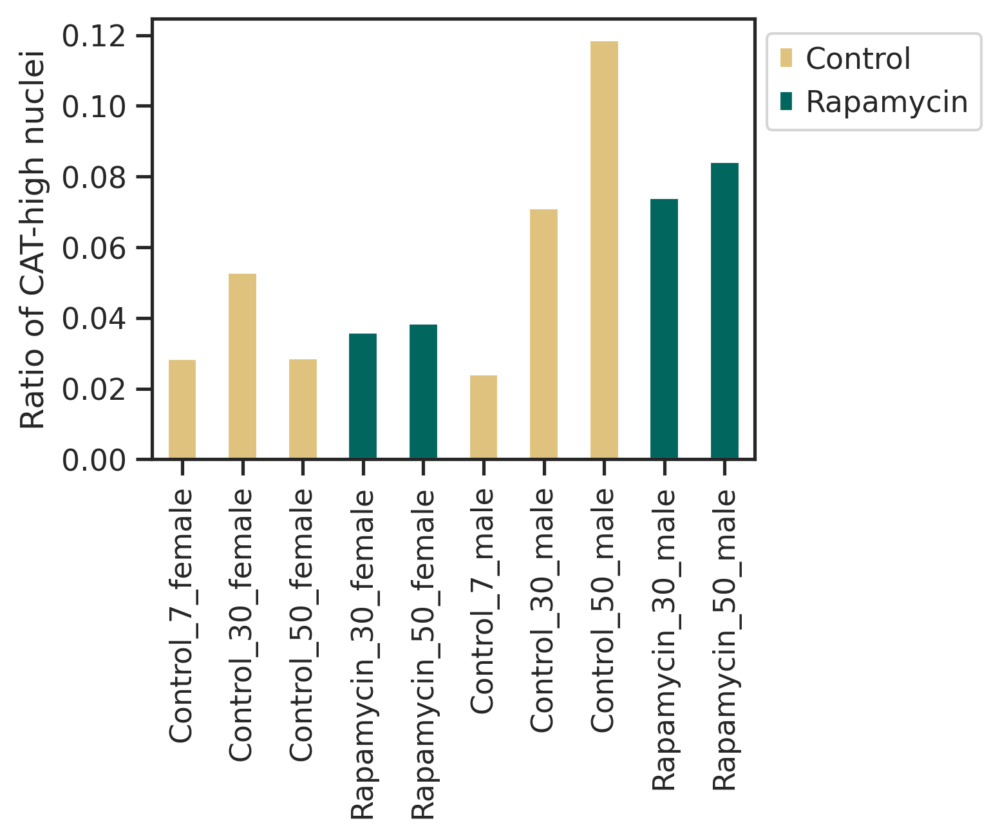

In [169]:
# Create the plot
ax = cellN_ratio['CAT'].plot(kind='bar', figsize=(4, 3), color=cellN_ratio_no70['color'])

# Create custom legend
legend_elements = [Patch(facecolor='#dfc27d', label='Control'), Patch(facecolor='#01665e', label='Rapamycin')]
ax.legend(handles=legend_elements, bbox_to_anchor=(1.4, 1.0)) # loc='best'
ax.set(ylabel='Ratio of CAT-high nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__CAT_group__head.pdf', bbox_inches='tight')

# Supplement: ADFCA score

## Load data

In [34]:
adata_adfca_body = sc.read(f'/data/tcl/Project/ADFCA/adataProcess/v1.0/adata_adfca_body_v1.0.h5ad')
adata_adfca_head = sc.read(f'/data/tcl/Project/ADFCA/adataProcess/v1.0/adata_adfca_head_v1.0.h5ad')

adata_adfca_body

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


AnnData object with n_obs × n_vars = 264422 × 16219
    obs: 'sample', 'dataset', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'sex', 'tissue', 'age', 'genotype', 'sex_age', 'genoAge', 'genoSex', 'genoAgeSex', 'adfca_annotation', 'adfca_annotation_broad', 'adfca_annotation_group', 'adfca_annotation_subcluster'
    var: 'gene_ids', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'adfca_annotation_colors', 'hvg', 'leiden', 'log1p', 'neighbors', 'pca', 'tsne', 'umap'
    obsm: 'X_pca', 'X_tsne', 'X_umap', 'latent_gene_encoding'
    layers: 'logNormalize_exp', 'umi_counts'
    obsp: 'connectivities', 'distances'

In [35]:
shareUp_L = [gene.strip() for gene in open(f'{lineageDegFolder}/sharedAgingGenes__up.txt') ]
shareDown_L = [gene.strip() for gene in open(f'{lineageDegFolder}/sharedAgingGenes__down.txt') ]

## calculate scores in the body dataset

In [36]:
import math

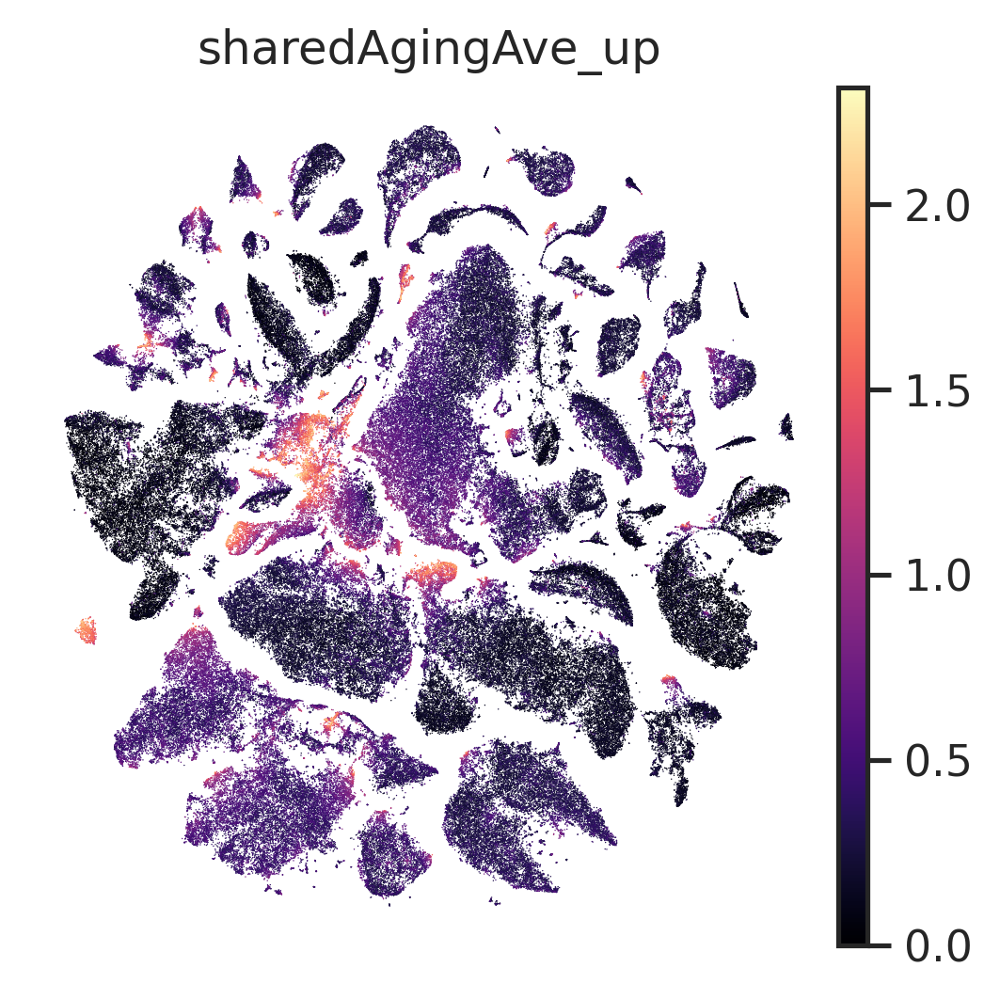

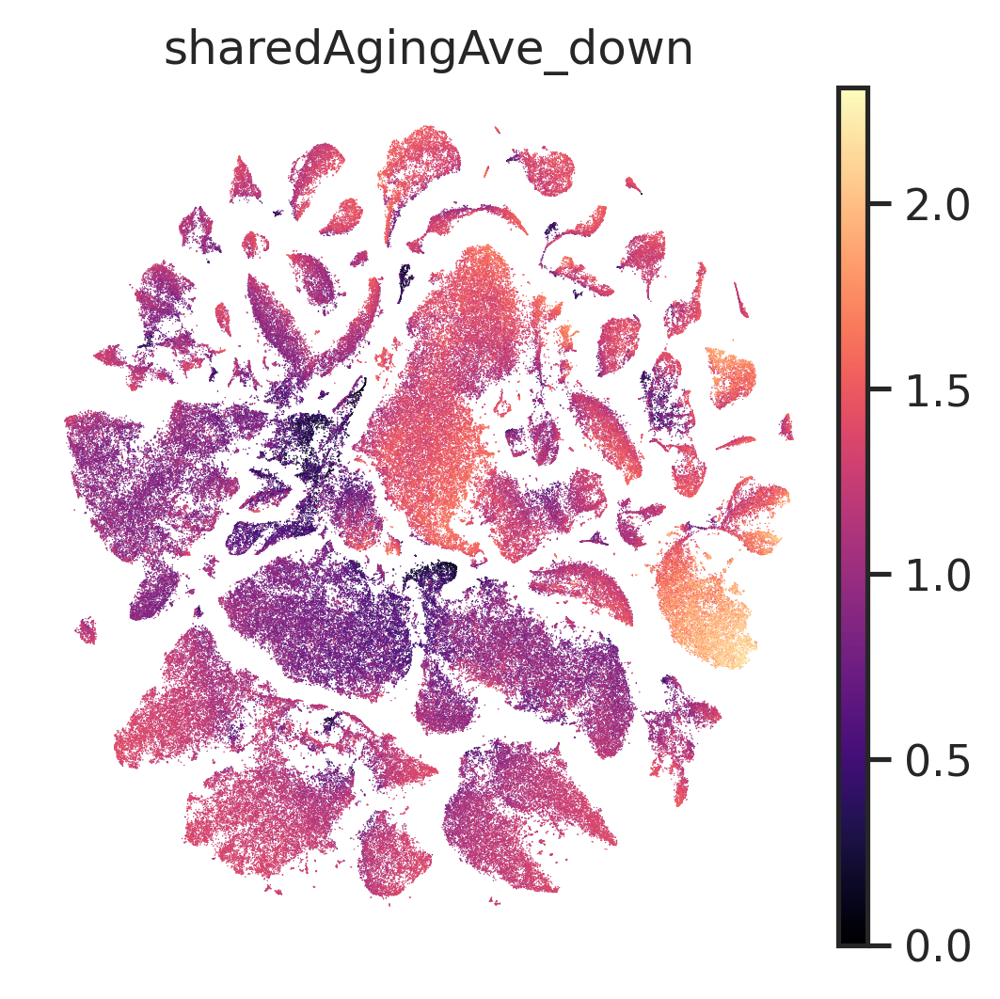

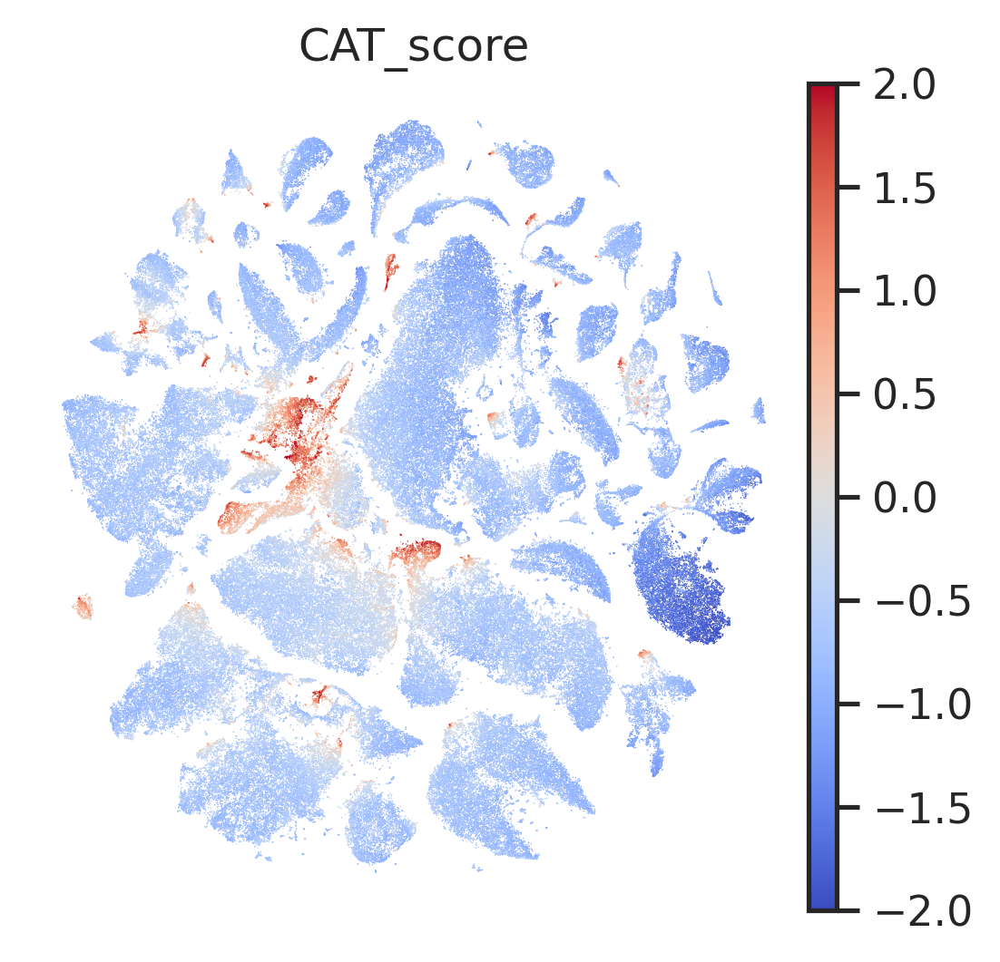

In [40]:
# body
adata_adfca_body.obs['sharedAgingAve_up'] = adata_adfca_body[:, shareUp_L].X.todense().mean(axis=1).flatten().tolist()[0]
adata_adfca_body.obs['sharedAgingAve_down'] = adata_adfca_body[:, shareDown_L].X.todense().mean(axis=1).flatten().tolist()[0]
adata_adfca_body.obs['sharedAgingAve_upMinusDown'] = adata_adfca_body.obs.sharedAgingAve_up - adata_adfca_body.obs.sharedAgingAve_down
adata_adfca_body.obs['CAT_score'] = adata_adfca_body.obs['sharedAgingAve_upMinusDown'].copy()

# plot
sc.pl.tsne(adata_adfca_body, color=['sharedAgingAve_up',], color_map='magma', frameon=False, save=f'__adata_adfca_body__sharedAgingAve_up.pdf')
sc.pl.tsne(adata_adfca_body, color=['sharedAgingAve_down'], color_map='magma', frameon=False, save=f'__adata_adfca_body__sharedAgingAve_down.pdf')
sc.pl.tsne(adata_adfca_body, color=['CAT_score'], color_map='coolwarm', frameon=False, vmin=-2, vmax=2, save=f'__adata_adfca_body__CAT_score.pdf')

In [41]:
adata_adfca_body.obs.genotype.value_counts()

genotype
control    110369
AB42        83132
hTau        70921
Name: count, dtype: int64

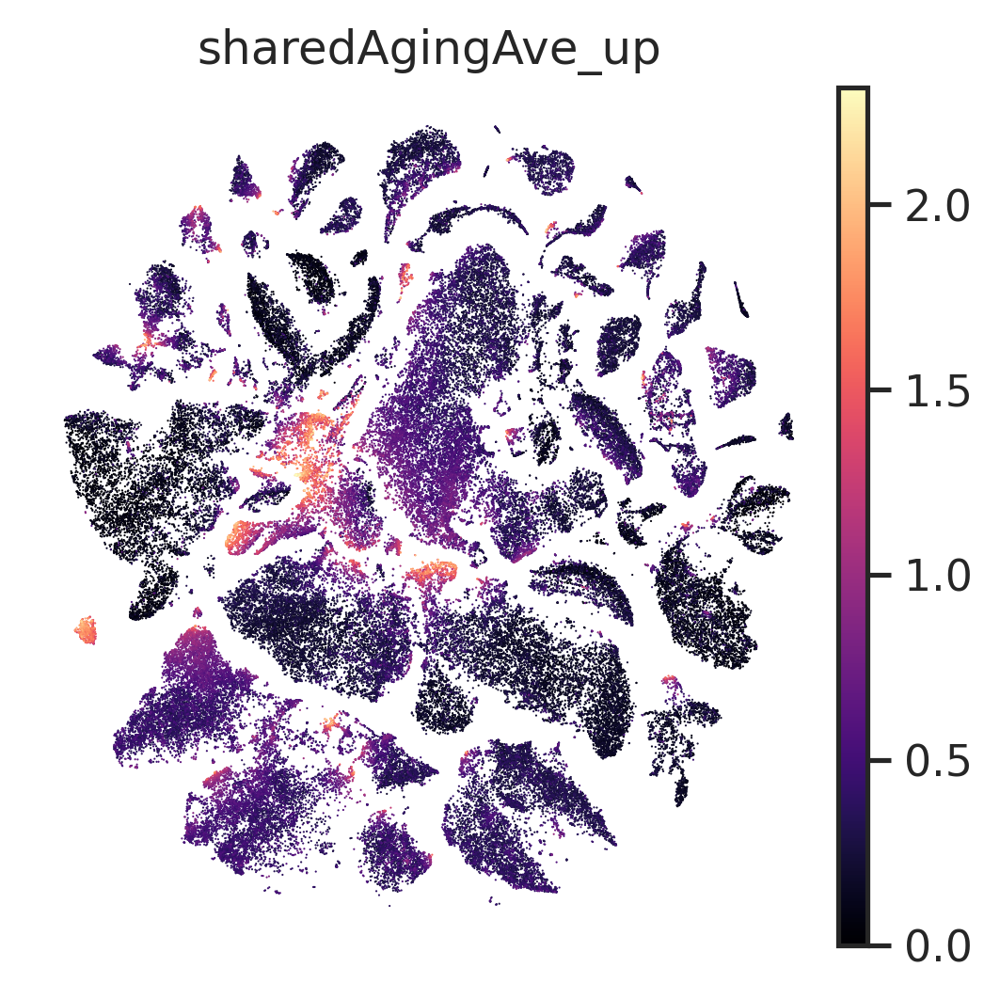

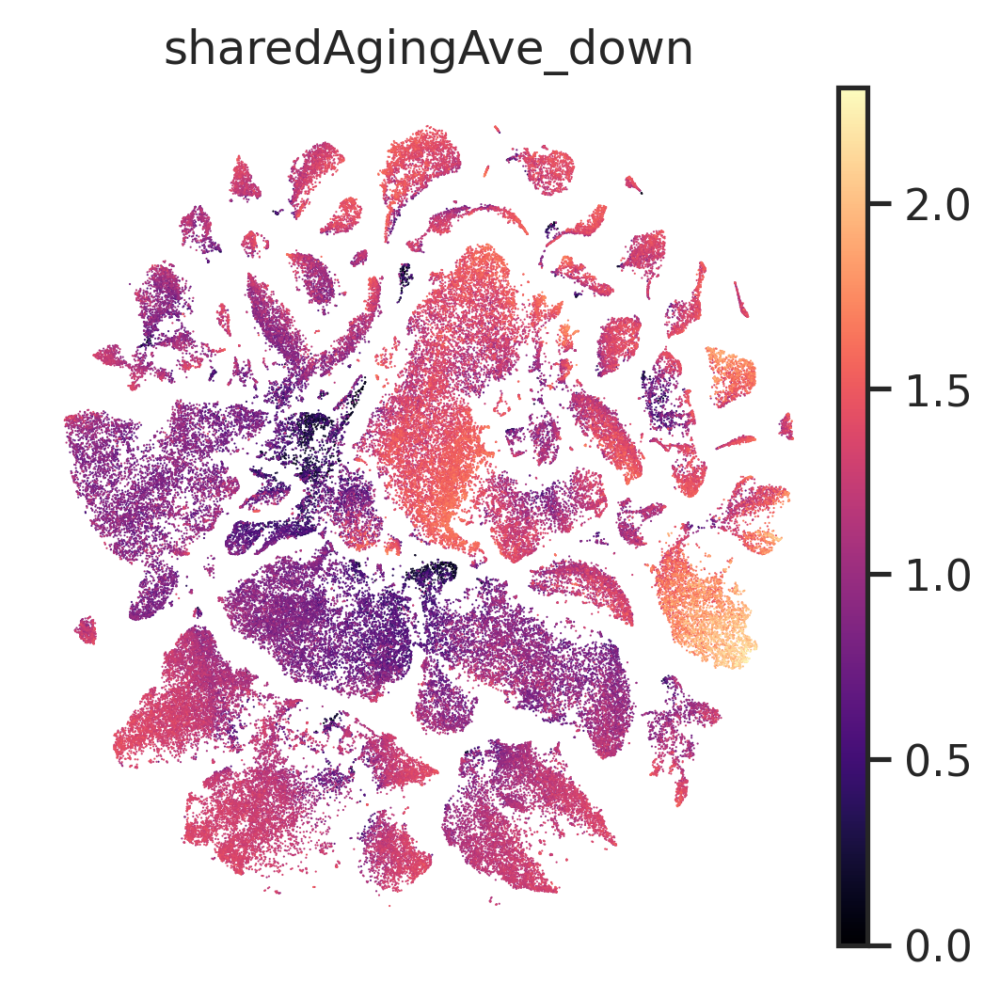

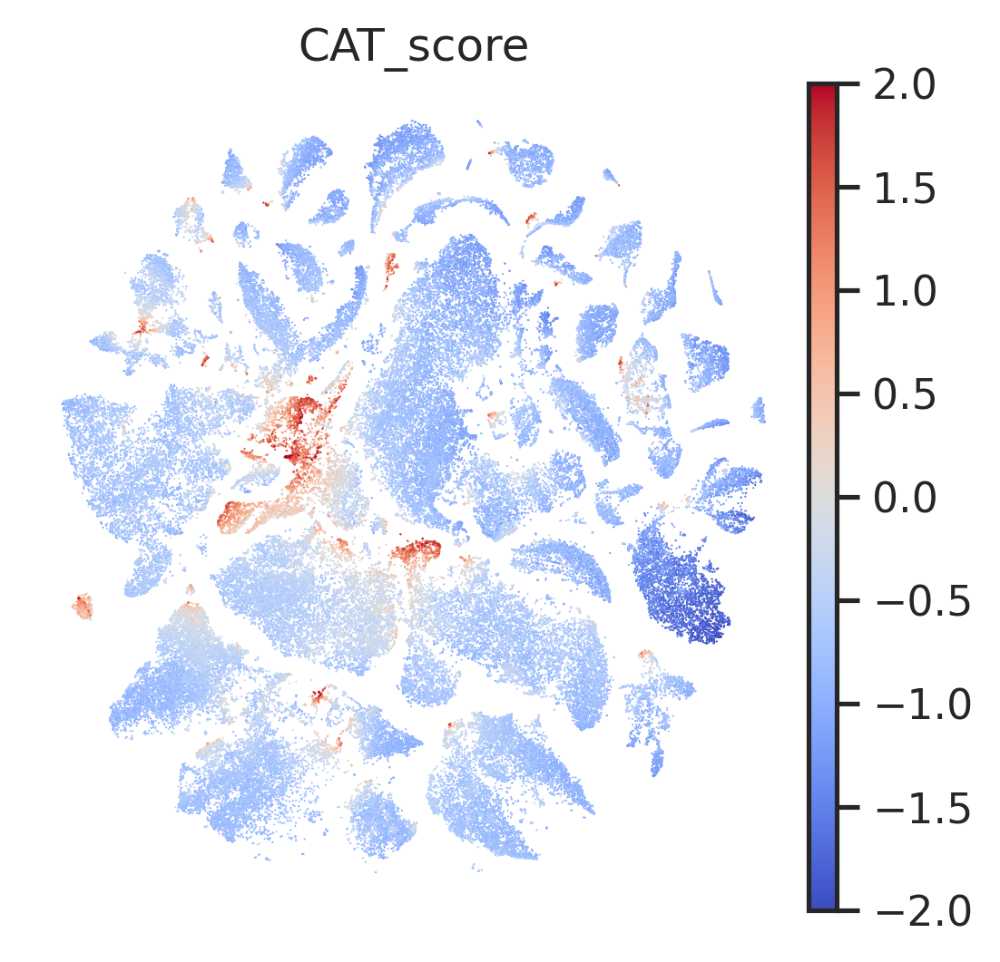

In [42]:
# control only
# plot
sc.pl.tsne(adata_adfca_body[adata_adfca_body.obs.genotype == 'control'], color=['sharedAgingAve_up',], color_map='magma', frameon=False, save=f'__adata_adfca_body__control__sharedAgingAve_up.pdf')
sc.pl.tsne(adata_adfca_body[adata_adfca_body.obs.genotype == 'control'], color=['sharedAgingAve_down'], color_map='magma', frameon=False, save=f'__adata_adfca_body__control__sharedAgingAve_down.pdf')
sc.pl.tsne(adata_adfca_body[adata_adfca_body.obs.genotype == 'control'], color=['CAT_score'], color_map='coolwarm', frameon=False, vmin=-2, vmax=2, save=f'__adata_adfca_body__control__CAT_score.pdf')

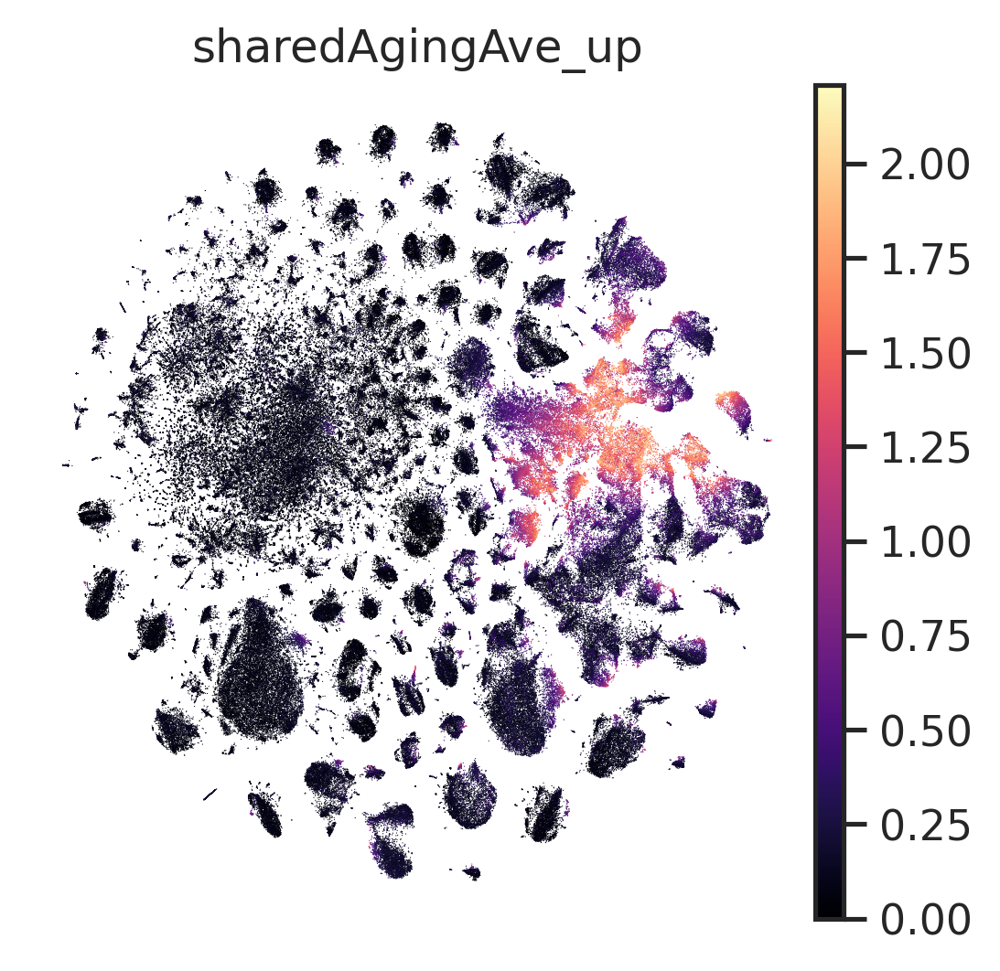

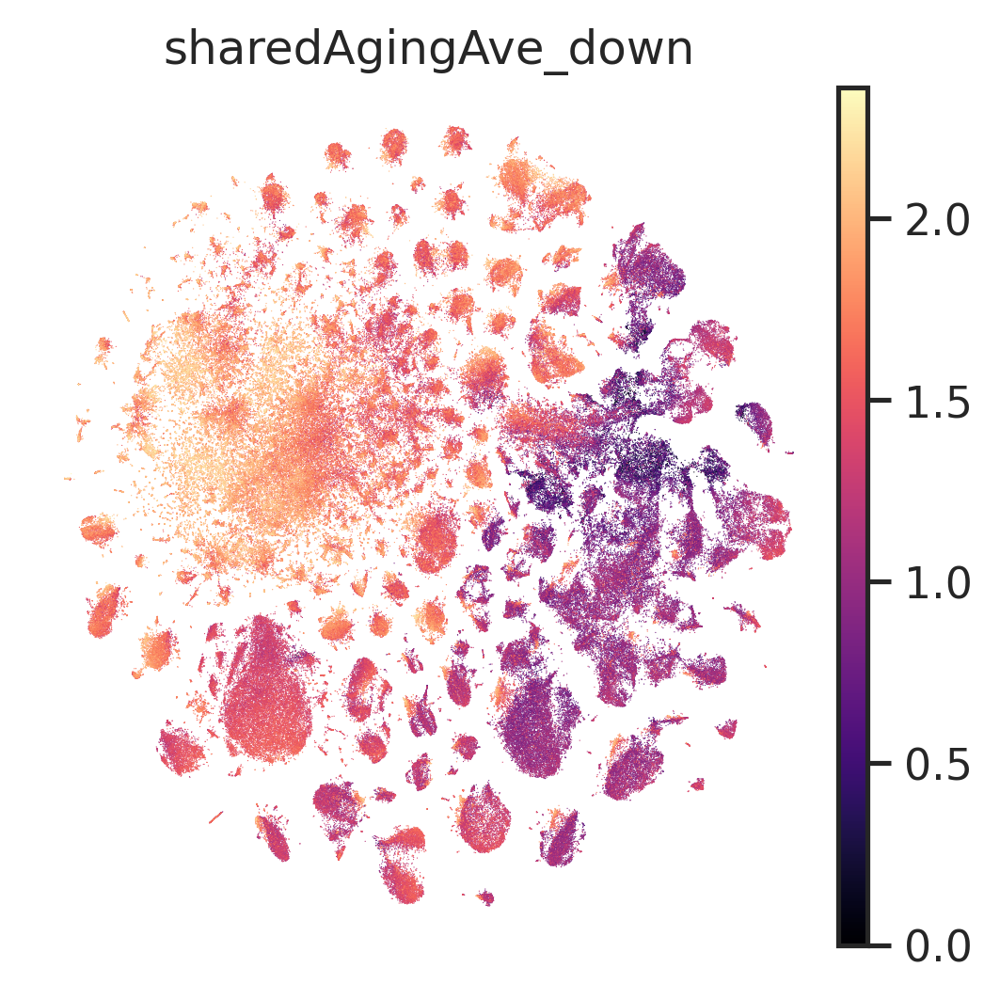

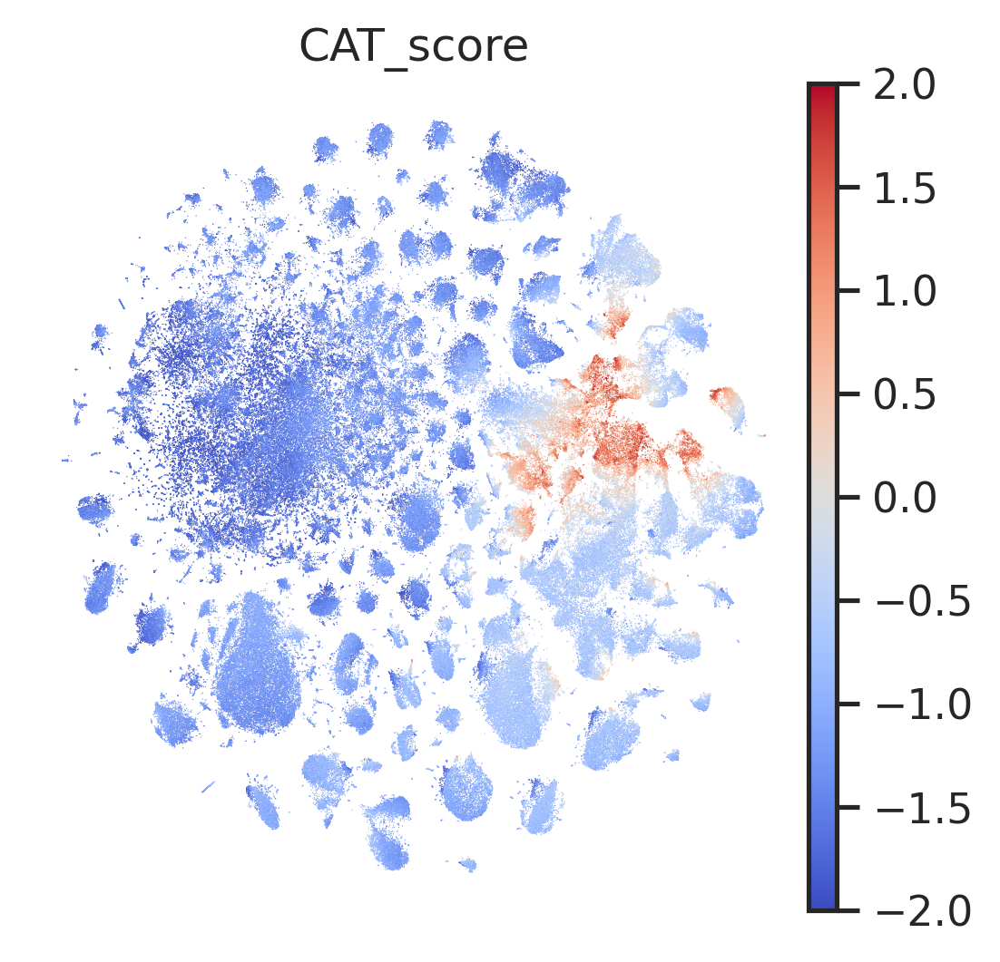

In [43]:
# head
adata_adfca_head.obs['sharedAgingAve_up'] = adata_adfca_head[:, shareUp_L].X.todense().mean(axis=1).flatten().tolist()[0]
adata_adfca_head.obs['sharedAgingAve_down'] = adata_adfca_head[:, shareDown_L].X.todense().mean(axis=1).flatten().tolist()[0]
adata_adfca_head.obs['sharedAgingAve_upMinusDown'] = adata_adfca_head.obs.sharedAgingAve_up - adata_adfca_head.obs.sharedAgingAve_down
adata_adfca_head.obs['CAT_score'] = adata_adfca_head.obs['sharedAgingAve_upMinusDown'].copy()

# plot
sc.pl.tsne(adata_adfca_head, color=['sharedAgingAve_up',], color_map='magma', frameon=False, save=f'__adata_adfca_head__sharedAgingAve_up.pdf')
sc.pl.tsne(adata_adfca_head, color=['sharedAgingAve_down'], color_map='magma', frameon=False, save=f'__adata_adfca_head__sharedAgingAve_down.pdf')
sc.pl.tsne(adata_adfca_head, color=['CAT_score'], color_map='coolwarm', frameon=False, vmin=-2, vmax=2, save=f'__adata_adfca_head__CAT_score.pdf')

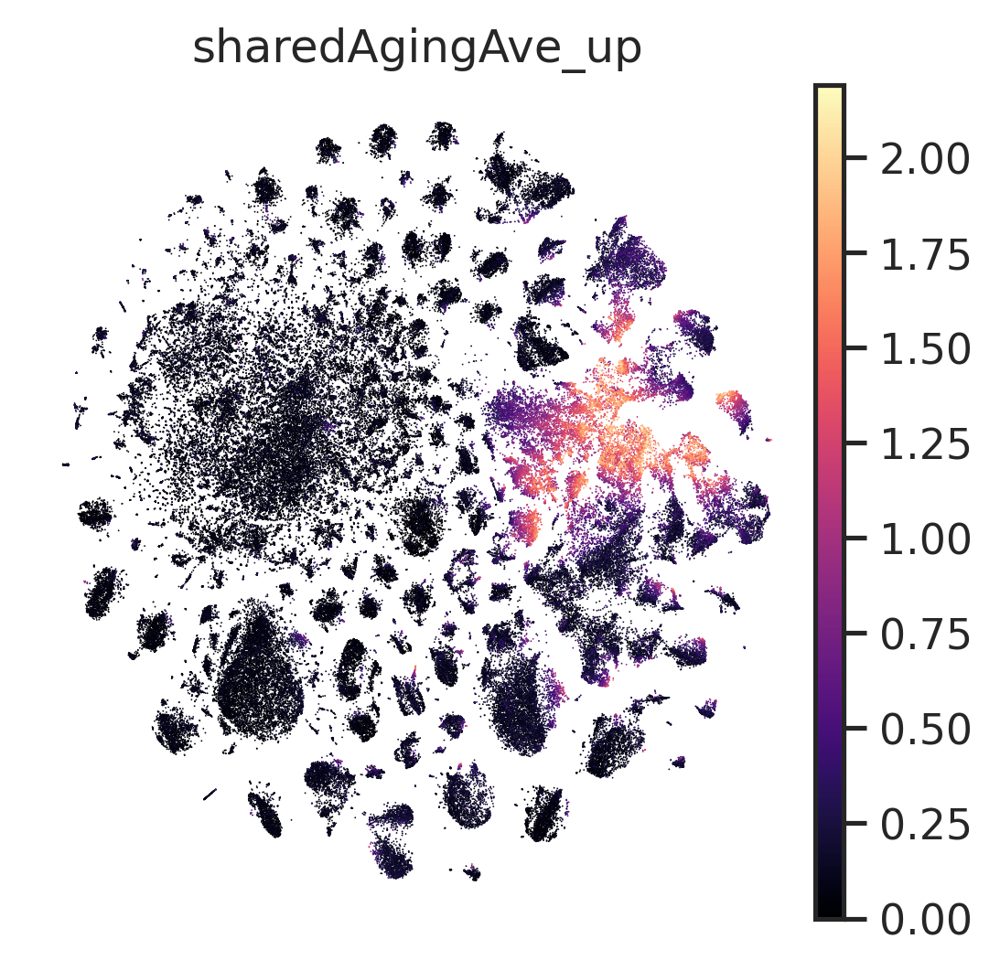

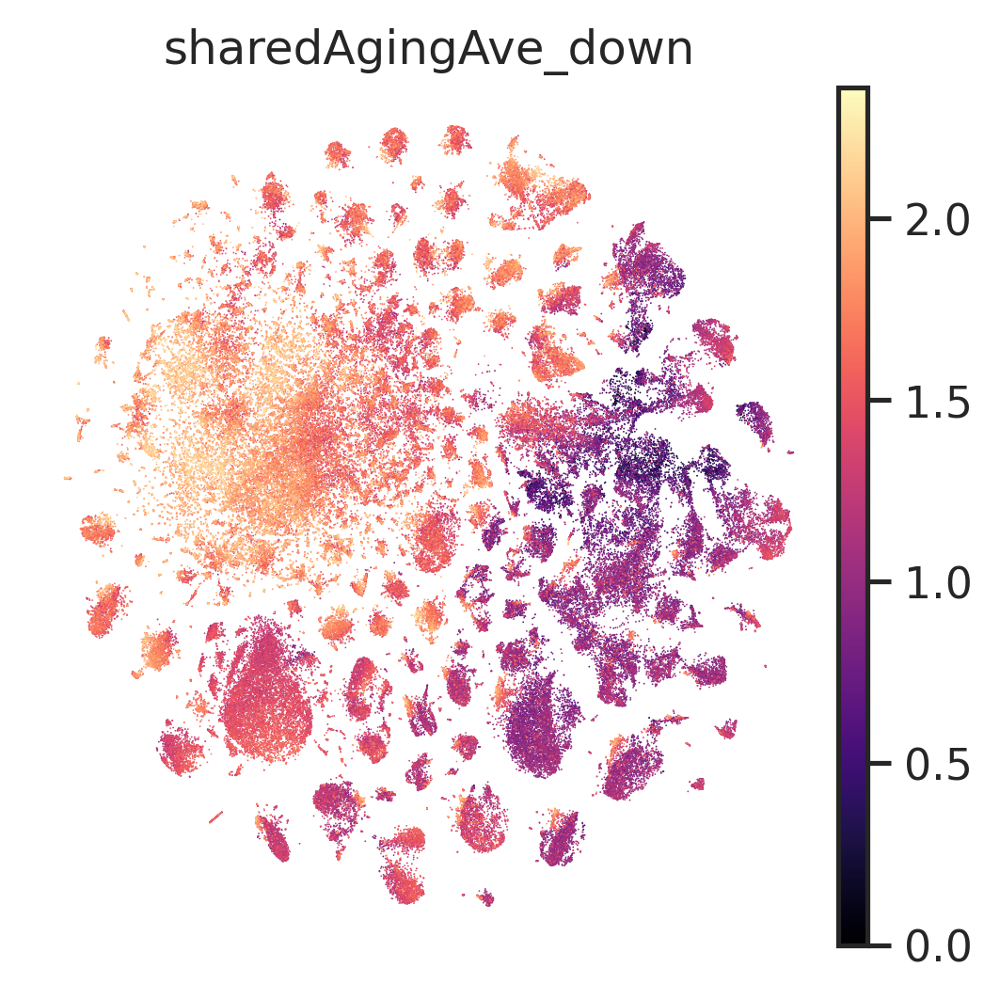

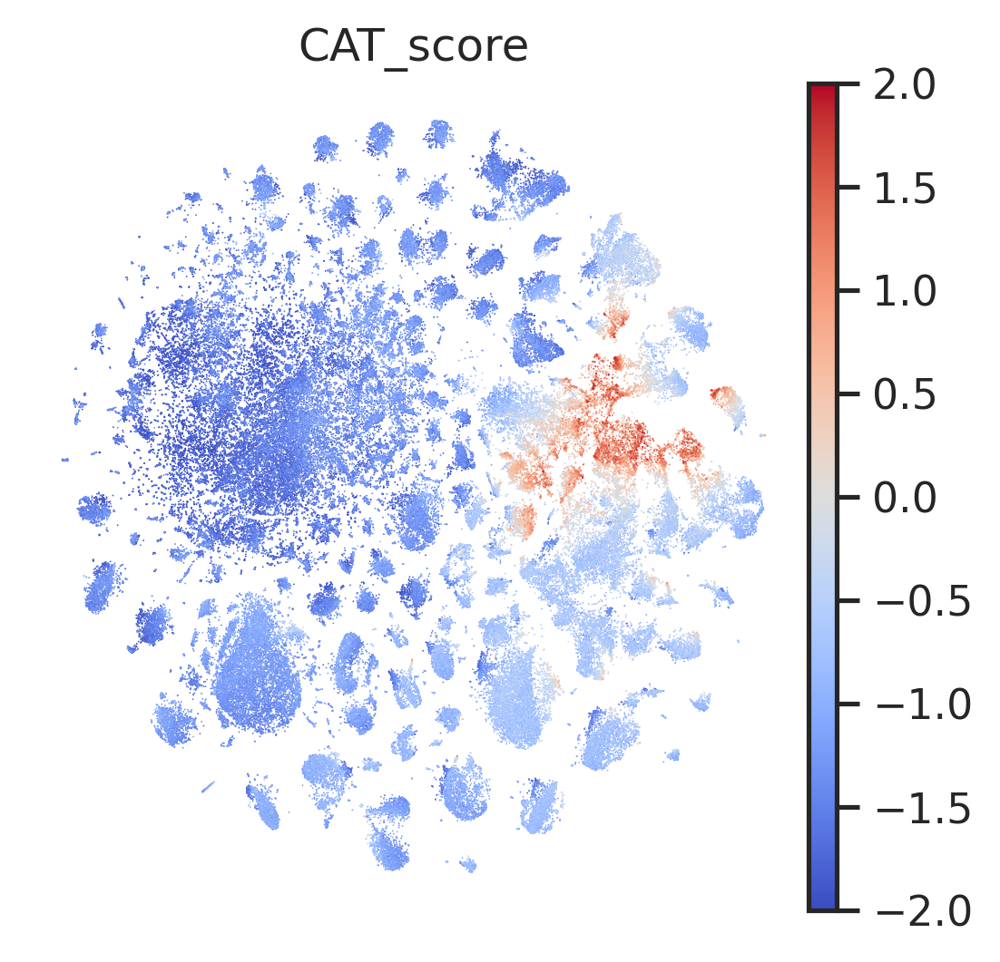

In [44]:
# control only
# plot
sc.pl.tsne(adata_adfca_head[adata_adfca_head.obs.genotype == 'control'], color=['sharedAgingAve_up',], color_map='magma', frameon=False, save=f'__adata_adfca_head__control__sharedAgingAve_up.pdf')
sc.pl.tsne(adata_adfca_head[adata_adfca_head.obs.genotype == 'control'], color=['sharedAgingAve_down'], color_map='magma', frameon=False, save=f'__adata_adfca_head__control__sharedAgingAve_down.pdf')
sc.pl.tsne(adata_adfca_head[adata_adfca_head.obs.genotype == 'control'], color=['CAT_score'], color_map='coolwarm', frameon=False, vmin=-2, vmax=2, save=f'__adata_adfca_head__control__CAT_score.pdf')

## shared aging lineage

In [45]:
mean=adata_adfca_body.obs['CAT_score'].mean()
std = adata_adfca_body.obs['CAT_score'].std()
z1 = mean + std*1
z1_5 = mean + std*1.5
z2 = mean + std*2

print(mean, std)
print(z1, z1_5, z2)

-0.7408738616353013 0.5062471706273505
-0.23462669100795086 0.01849689430572432 0.2716204796193996


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


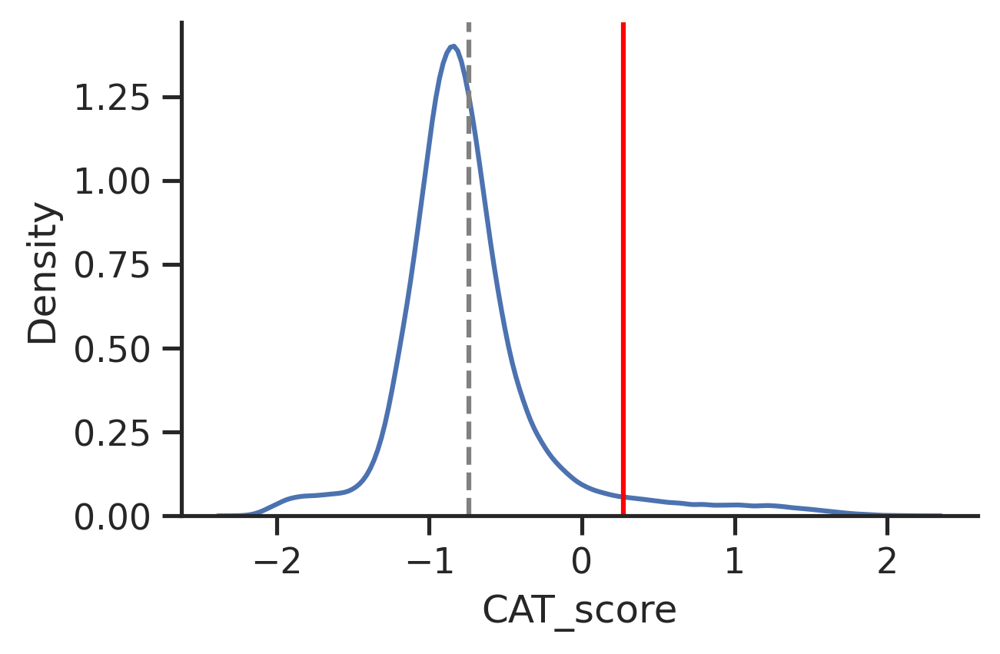

In [55]:
# with rc_context({'figure.figsize': (3, 1)}):
sns.displot(data=adata_adfca_body.obs, x='CAT_score', height=3, aspect=1.5, kind='kde')
# plt.xlim(-7.7, 7)
plt.axvline(mean, c='grey', linestyle='--')
plt.axvline(z2, c='red')
plt.savefig(f'{figure5PicFolder}/displot__adata_adfca_body__CAT_score.pdf')

plt.show()

In [56]:
adata_adfca_body.obs['CAT_group'] = pd.Categorical([ 'CAT' if ratio >= z2 else 'others' for ratio in adata_adfca_body.obs['CAT_score']  ], categories=['CAT', 'others'])

In [57]:
adata_adfca_body.obs['CAT_group'].cat.categories

Index(['CAT', 'others'], dtype='object')

In [58]:
cmap = list(sns.color_palette("Set2"))[1:3]

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


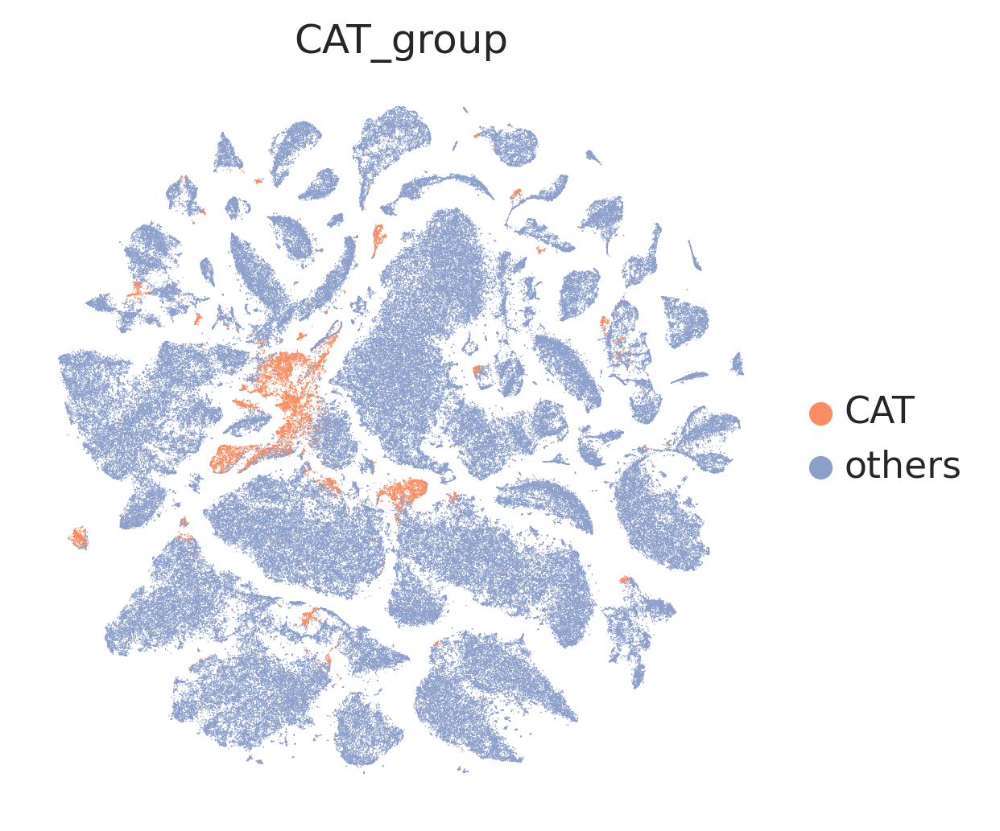

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_utils.py:430: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


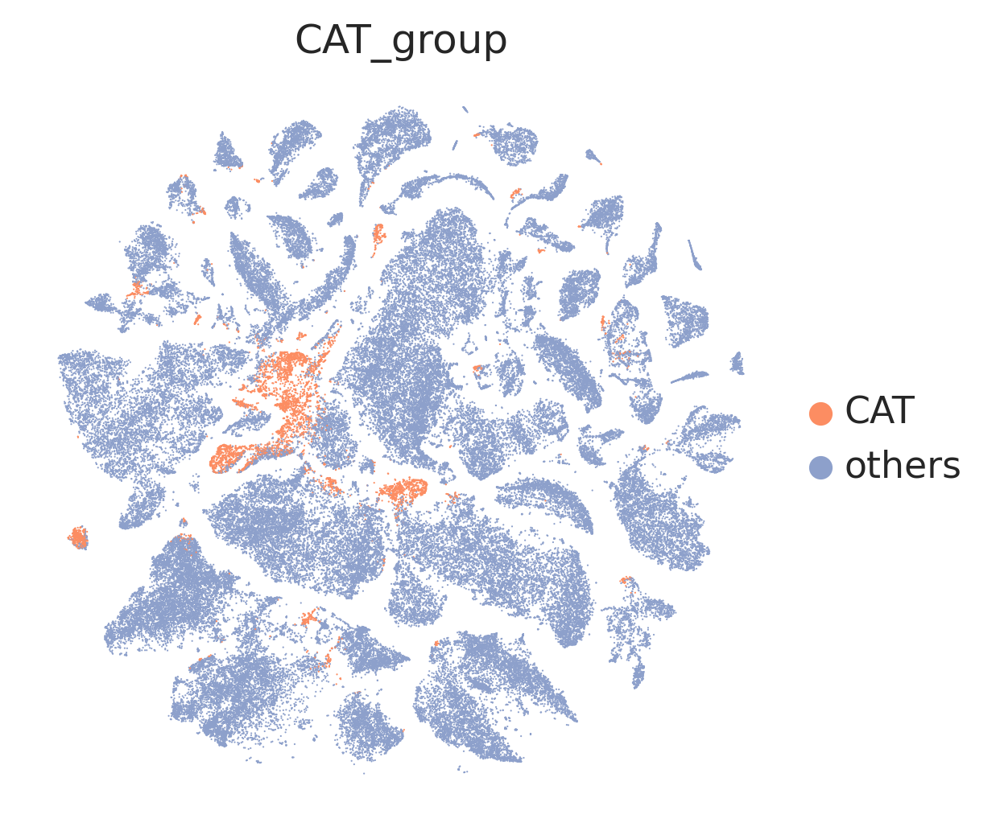

In [59]:
sc.pl.tsne(adata_adfca_body, color=['CAT_group'], frameon=False, palette=cmap, save=f'_adata_adfca_body__CAT_group.pdf')
sc.pl.tsne(adata_adfca_body[adata_adfca_body.obs.genotype == 'control'], color=['CAT_group'], frameon=False, palette=cmap, save=f'_adata_adfca_body__control__CAT_group.pdf')

In [60]:
# head
mean=adata_adfca_head.obs['CAT_score'].mean()
std = adata_adfca_head.obs['CAT_score'].std()
z1 = mean + std*1
z1_5 = mean + std*1.5
z2 = mean + std*2

print(mean, std)
print(z1, z1_5, z2)

-1.147139666487068 0.6566575280673674
-0.4904821384197007 -0.16215337438601696 0.16617538964766676


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


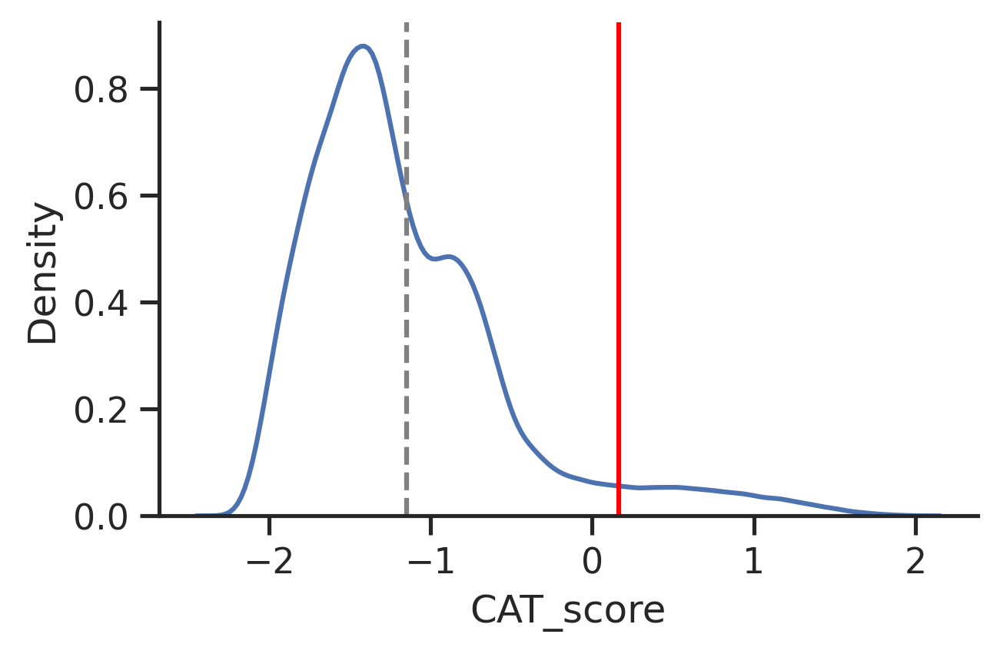

In [61]:
# with rc_context({'figure.figsize': (3, 1)}):
sns.displot(data=adata_adfca_head.obs, x='CAT_score', height=3, aspect=1.5, kind='kde')
# plt.xlim(-8, 6)
plt.axvline(mean, c='grey', linestyle='--')
plt.axvline(z2, c='red')
plt.savefig(f'{figure5PicFolder}/displot__adata_adfca_head__CAT_score.pdf')

plt.show()

In [62]:
adata_adfca_head.obs['CAT_group'] = pd.Categorical([ 'CAT' if ratio >= z2 else 'others' for ratio in adata_adfca_head.obs['CAT_score']  ], categories=['CAT', 'others'])

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


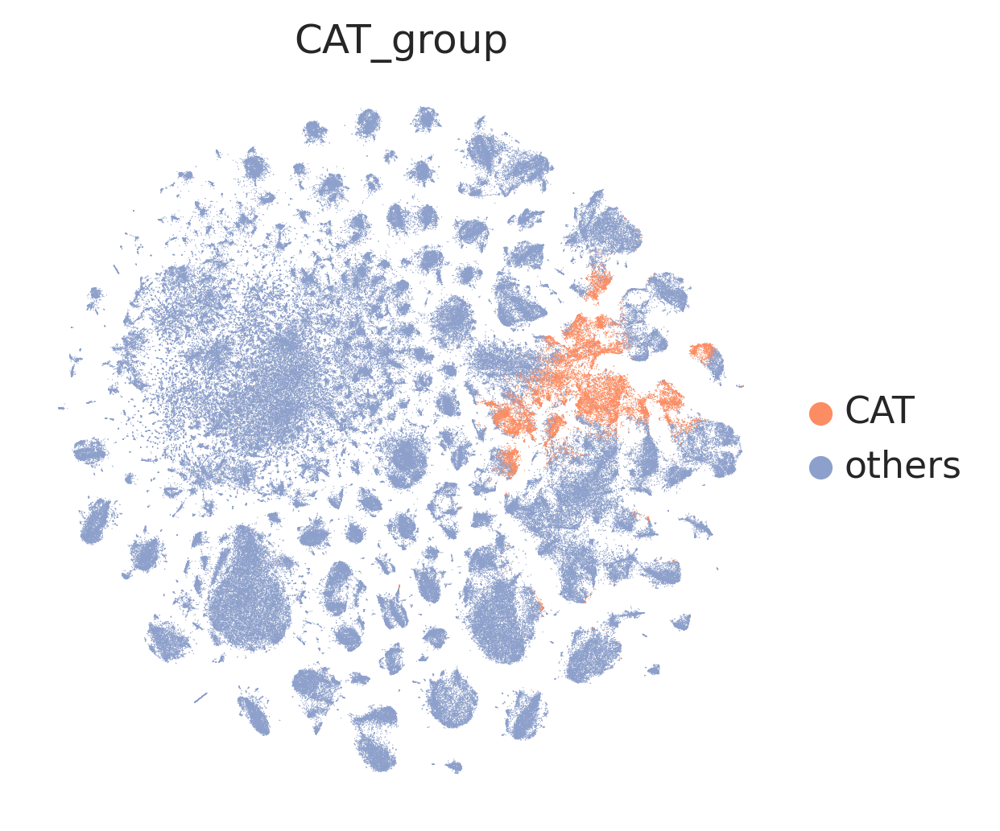

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_utils.py:430: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


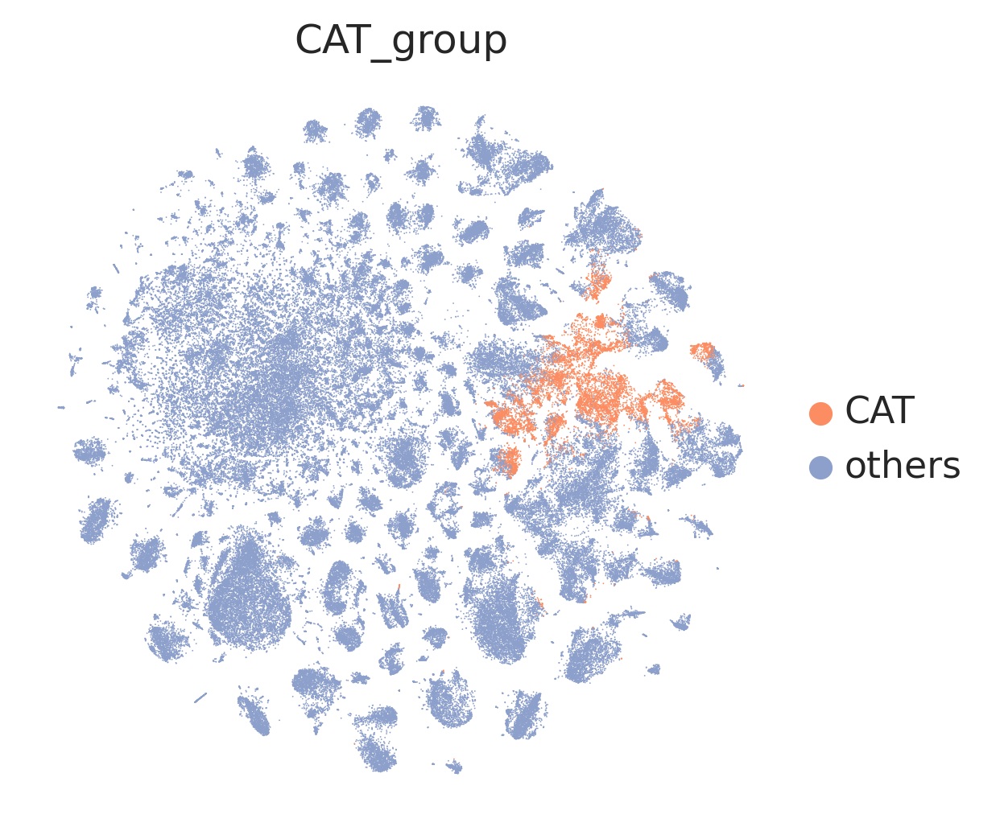

In [63]:
sc.pl.tsne(adata_adfca_head, color=['CAT_group'], frameon=False, palette=cmap, save=f'_adata_adfca_head__CAT_group.pdf')
sc.pl.tsne(adata_adfca_head[adata_adfca_head.obs.genotype == 'control'], color=['CAT_group'], frameon=False, palette=cmap, save=f'_adata_adfca_head__control__CAT_group.pdf')

In [64]:
for x in os.listdir('figures/'): 
    os.replace(f'figures/{x}', f'{figure5PicFolder}/{x}')

In [65]:
adata_adfca_body.write(f'{figure5Folder}/adata_adfca_body__CAT_score__CAT_group.h5ad')
adata_adfca_head.write(f'{figure5Folder}/adata_adfca_head__CAT_score__CAT_group.h5ad')

## germline and male acc

In [76]:
adata_adfca_body = sc.read(f'{figure5Folder}/adata_adfca_body__CAT_score__CAT_group.h5ad')
adata_adfca_body = adata_adfca_body[adata_adfca_body.obs.genotype == 'control']

adata_adfca_head = sc.read(f'{figure5Folder}/adata_adfca_head__CAT_score__CAT_group.h5ad')
adata_adfca_head = adata_adfca_head[adata_adfca_head.obs.genotype == 'control']

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


In [77]:
bcRatio_D = dict(zip(adata_adfca_body.obs_names.to_list(), adata_adfca_body.obs['CAT_score']))
bcLineage_D = dict(zip(adata_adfca_body.obs_names.to_list(), adata_adfca_body.obs['CAT_group']))

In [78]:
adata_adfca_body.obs.adfca_annotation.value_counts().head(50)

adfca_annotation
adult fat body_body                                      18285
follicle cell                                            15677
muscle cell                                               9658
epithelial cell_body                                      8480
indirect flight muscle                                    8385
adult oenocyte                                            7101
adult ventral nervous system                              3487
adult tracheal cell_body                                  3329
germline cell                                             3325
unannotated                                               3246
male accessory gland main cell_roX1+                      2341
crop                                                      2225
hemocyte_body                                             1793
eo support cell                                           1325
ejaculatory bulb                                          1280
choriogenic main body follicle cell an

In [83]:
adata_germline = adata_adfca_body[adata_adfca_body.obs.adfca_annotation.isin(['germline cell', '16-cell germline cyst in germarium region 2a and 2b'])]
adata_maleAcc = adata_adfca_body[adata_adfca_body.obs.adfca_annotation.isin(['male accessory gland main cell_roX1+', 'male accessory gland main cell_roX1-'])]
adata_ejula = adata_adfca_body[adata_adfca_body.obs.adfca_annotation.isin(['ejaculatory bulb'])]
adata_epithilial = adata_adfca_body[adata_adfca_body.obs.adfca_annotation.isin(['epithelial cell_body'])]

In [84]:
adata_germline.obs.adfca_annotation.value_counts()

adfca_annotation
germline cell                                          3325
16-cell germline cyst in germarium region 2a and 2b    1040
Name: count, dtype: int64

In [85]:
adata_maleAcc.obs.adfca_annotation.value_counts()

adfca_annotation
male accessory gland main cell_roX1+    2341
male accessory gland main cell_roX1-     174
Name: count, dtype: int64

In [86]:
adata_ejula.obs.adfca_annotation.value_counts()

adfca_annotation
ejaculatory bulb    1280
Name: count, dtype: int64

In [87]:
adata_epithilial.obs.adfca_annotation.value_counts()

adfca_annotation
epithelial cell_body    8480
Name: count, dtype: int64

In [88]:
adata_D = {'germline': adata_germline, 'maleAcc': adata_maleAcc, 'ejulatoryBulb': adata_ejula, 'epithilial': adata_epithilial}

germline
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 50
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:25)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:07)


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map)

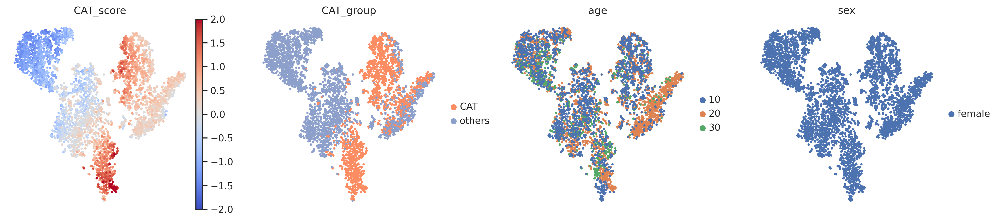

maleAcc
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 50
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:12)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:04)


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map)

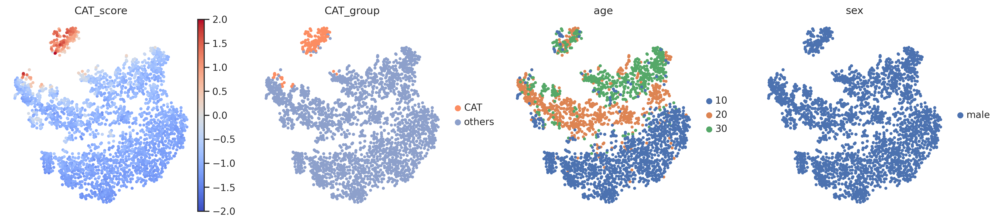

ejulatoryBulb
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 50
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:05)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:02)


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map)

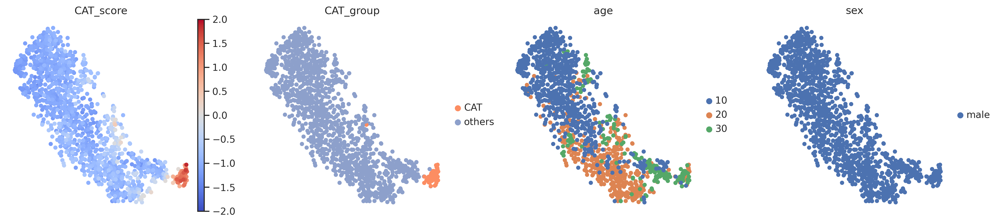

epithilial
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 50
    using sklearn.manifold.TSNE
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm) (0:00:55)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:14)


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:1217: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map)

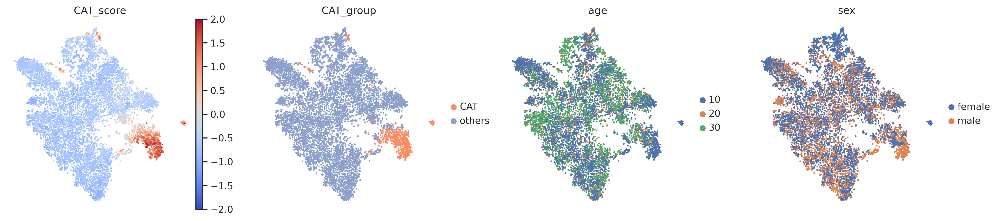

In [89]:
for ct in adata_D.keys():
    print(ct)

    adata = adata_D[ct]
    sc.pp.neighbors(adata, n_neighbors=15, n_pcs=50)
    sc.tl.tsne(adata, n_pcs=50)
    sc.tl.umap(adata)
    sc.pl.tsne(adata, color=['CAT_score', 'CAT_group', 'age', 'sex'],  color_map='coolwarm', frameon=False, vmin=-2, vmax=2, save=f'_adata_adfca_{ct}__CAT_score__CAT_group__age_sex.pdf')
    
    adata.write(f'{figure5Folder}/adata_adfca_{ct}__CAT_score__CAT_group.h5ad')

In [90]:
for x in os.listdir('figures/'): 
    os.replace(f'figures/{x}', f'{figure5PicFolder}/{x}')

### Plot ratio of shared aging group: germline

In [91]:
adata_germline.obs.genoAge.cat.categories

Index(['control_10', 'control_20', 'control_30'], dtype='object')

In [92]:
cmap = list(sns.color_palette("Set2"))[1:3]

In [93]:
cellN_Df, cellN_ratio = cellN_cellRatio(adata_germline, 'genoAge', 'CAT_group') # [(adata_germline.obs.age != '70') & (adata_germline.obs.lineage != 'young germ cell')]

<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


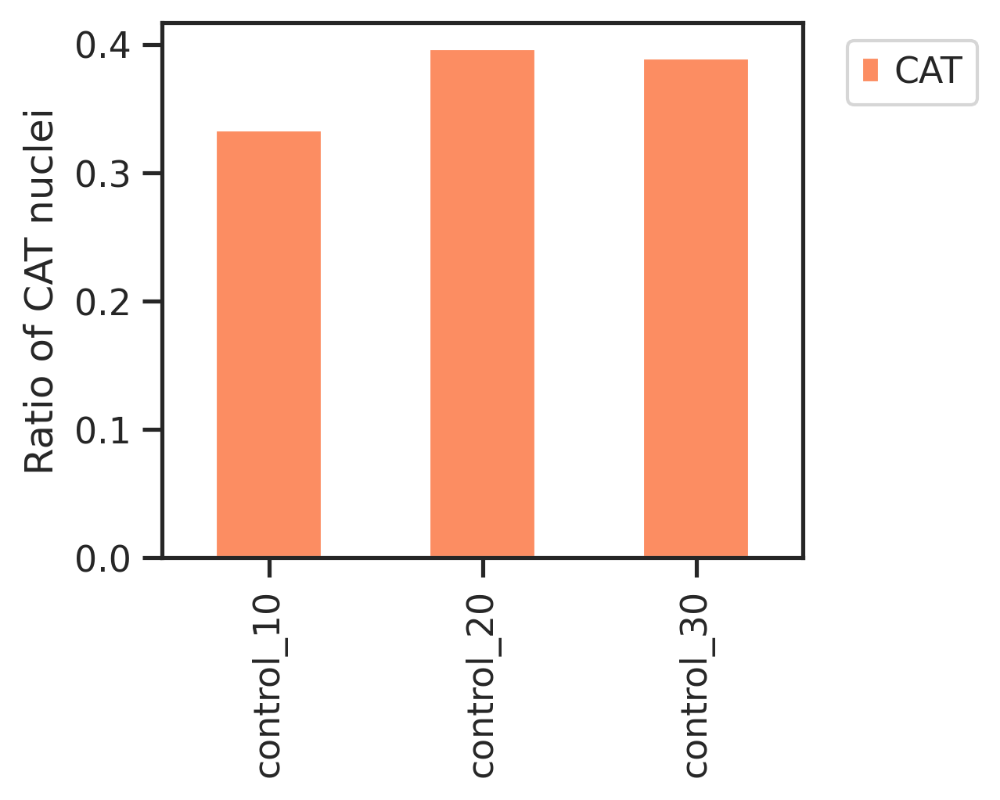

In [94]:
cellN_ratio.iloc[:,:1].plot( kind='bar', stacked=True, figsize=(3.5, 3), color=cmap)
plt.legend(bbox_to_anchor=(1.3, 1.0))
plt.ylabel('Ratio of CAT nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__adfca__CAT_group__germline.pdf', bbox_inches='tight')

Male accessory gland

In [91]:
# adata_maleAcc.obs.sharedAging_lineage = pd.Categorical(adata_maleAcc.obs.sharedAging_lineage, categories=['shared aging', 'others'])
# adata_maleAcc.obs.treatAge = pd.Categorical(adata_maleAcc.obs.treatAge, categories=['Control_7', 'Control_30', 'Control_50', 'Control_70', 'Rapamycin_30', 'Rapamycin_50', 'Rapamycin_70'])

In [95]:
cmap = list(sns.color_palette("Set2"))[1:3]

In [96]:
cellN_Df, cellN_ratio = cellN_cellRatio(adata_maleAcc, 'genoAge', 'CAT_group') # [(adata_maleAcc.obs.age != '70')]

<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


In [97]:
cellN_ratio

,CAT,others
control_10,0.012048,0.987952
control_20,0.089163,0.910837
control_30,0.125693,0.874307


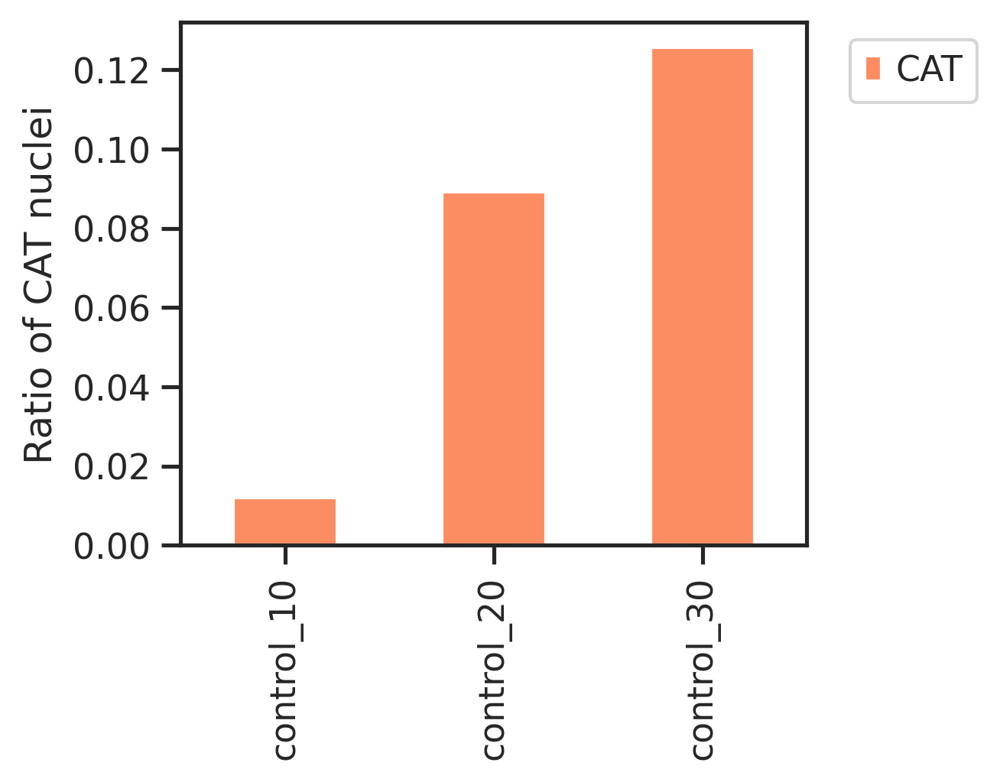

In [98]:
cellN_ratio.iloc[:,:1].plot( kind='bar', stacked=True, figsize=(3.5, 3), color=cmap)
plt.legend(bbox_to_anchor=(1.3, 1.0))
plt.ylabel('Ratio of CAT nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__adfca__CAT_group__maleAcc.pdf', bbox_inches='tight')

ejaculatory bulb

In [91]:
# adata_maleAcc.obs.sharedAging_lineage = pd.Categorical(adata_maleAcc.obs.sharedAging_lineage, categories=['shared aging', 'others'])
# adata_maleAcc.obs.treatAge = pd.Categorical(adata_maleAcc.obs.treatAge, categories=['Control_7', 'Control_30', 'Control_50', 'Control_70', 'Rapamycin_30', 'Rapamycin_50', 'Rapamycin_70'])

In [99]:
cellN_Df, cellN_ratio = cellN_cellRatio(adata_ejula, 'genoAge', 'CAT_group') # [(adata_maleAcc.obs.age != '70')]

<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


In [100]:
cellN_ratio

,CAT,others
control_10,0.004354,0.995646
control_20,0.039024,0.960976
control_30,0.160221,0.839779


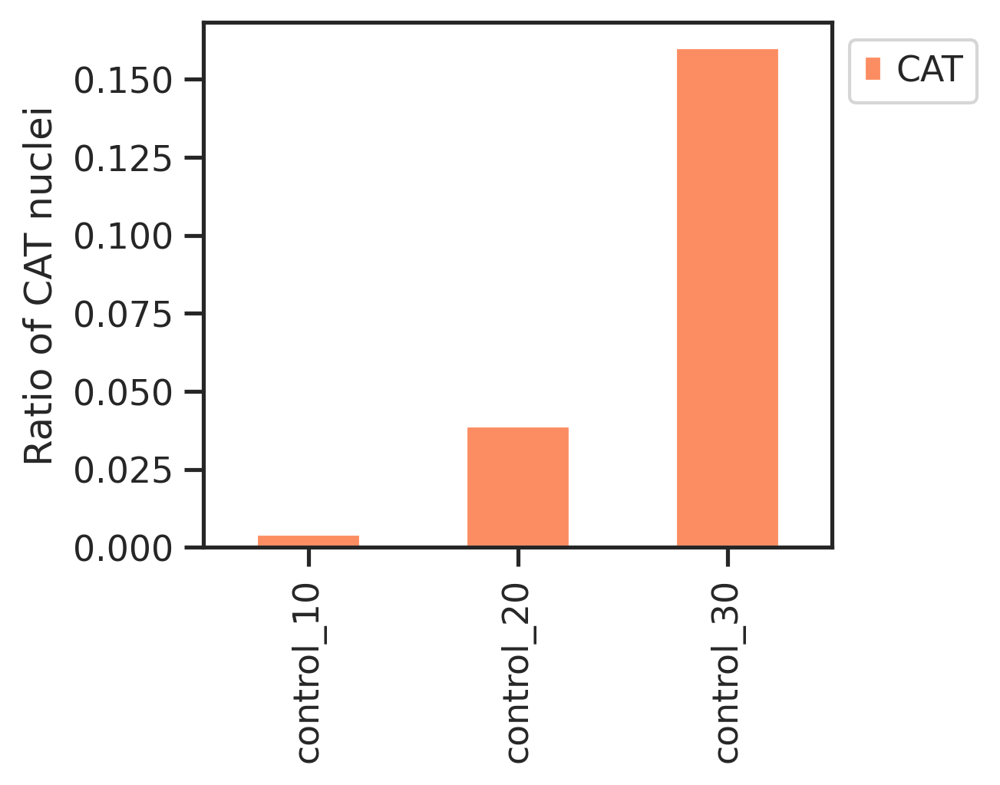

In [101]:
cellN_ratio.iloc[:,:1].plot( kind='bar', stacked=True, figsize=(3.5, 3), color=cmap)
plt.legend(bbox_to_anchor=(1.0, 1.0))
plt.ylabel('Ratio of CAT nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__adfca__CAT__ejulatoryBulb.pdf', bbox_inches='tight')

Whole body

In [102]:
adata_adfca_body.obs.genoAgeSex.cat.categories

Index(['control_10_female', 'control_10_male', 'control_20_female',
       'control_20_male', 'control_30_female', 'control_30_male'],
      dtype='object')

In [103]:
adata_adfca_body.obs.CAT_group = pd.Categorical(adata_adfca_body.obs.CAT_group, categories=['CAT', 'others'])
adata_adfca_body.obs.genoAgeSex = pd.Categorical(adata_adfca_body.obs.genoAgeSex, categories=['control_10_female', 'control_20_female', 'control_30_female',
                                                                              'control_10_male', 'control_20_male', 'control_30_male',])

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/pandas/core/generic.py:6326: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self[name] = value


In [104]:
cellN_Df, cellN_ratio = cellN_cellRatio(adata_adfca_body, 'genoAgeSex', 'CAT_group')

<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


In [105]:
cellN_ratio

,CAT,others
control_10_female,0.060422,0.939578
control_20_female,0.052508,0.947492
control_30_female,0.050525,0.949475
control_10_male,0.031959,0.968041
control_20_male,0.037415,0.962585
control_30_male,0.053245,0.946755


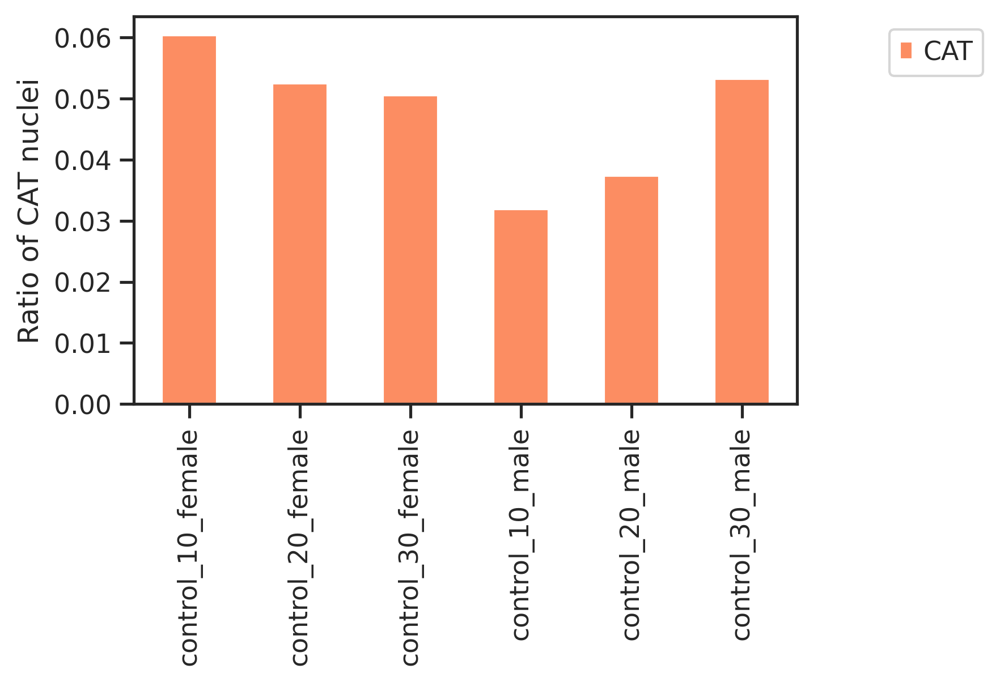

In [106]:
cellN_ratio.iloc[:,:1].plot( kind='bar', stacked=True, figsize=(5, 3), color=cmap)
plt.legend(bbox_to_anchor=(1.3, 1.0))
plt.ylabel('Ratio of CAT nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__adfca__CAT_group__body.pdf', bbox_inches='tight')

Whole head

In [107]:
adata_adfca_head.obs.genoAgeSex.cat.categories

Index(['control_10_female', 'control_10_male', 'control_20_female',
       'control_20_male', 'control_30_female', 'control_30_male'],
      dtype='object')

In [108]:
adata_adfca_head.obs.CAT_group = pd.Categorical(adata_adfca_head.obs.CAT_group, categories=['CAT', 'others'])
adata_adfca_head.obs.genoAgeSex = pd.Categorical(adata_adfca_head.obs.genoAgeSex, categories=['control_10_female', 'control_20_female', 'control_30_female',
                                                                              'control_10_male', 'control_20_male', 'control_30_male',])

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/pandas/core/generic.py:6326: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self[name] = value


In [109]:
cellN_Df, cellN_ratio = cellN_cellRatio(adata_adfca_head, 'genoAgeSex', 'CAT_group')

<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


In [110]:
cellN_ratio

,CAT,others
control_10_female,0.05954,0.94046
control_20_female,0.025936,0.974064
control_30_female,0.058816,0.941184
control_10_male,0.057122,0.942878
control_20_male,0.096548,0.903452
control_30_male,0.052007,0.947993


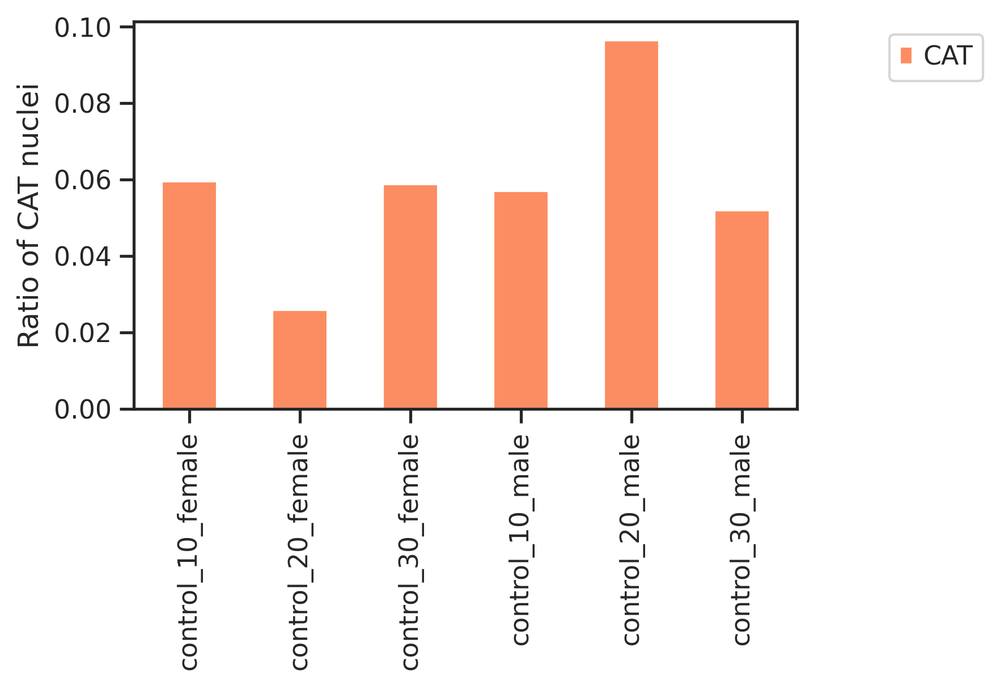

In [111]:
cellN_ratio.iloc[:,:1].plot( kind='bar', stacked=True, figsize=(5, 3), color=cmap)
plt.legend(bbox_to_anchor=(1.3, 1.0))
plt.ylabel('Ratio of CAT nuclei')
plt.savefig(f'{figure5PicFolder}/barplot__adfca__CAT_group__head.pdf', bbox_inches='tight')

# Heatmap of overall ratios

## Load files

In [34]:
adata_body = sc.read(f'{figure5Folder}/adata_body__CAT_score__CAT_group.h5ad')
adata_head = sc.read(f'{figure5Folder}/adata_head__CAT_score__CAT_group.h5ad')

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


In [35]:
adata_body

AnnData object with n_obs × n_vars = 238034 × 15919
    obs: 'latent_RT_efficiency', 'latent_cell_probability', 'latent_scale', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'dataset', 'age', 'sex', 'tissue', 'condition', 'leiden', 'linearR_annotation', 'condAge', 'condSex', 'ageSex', 'condAgeSex', 'condAgeSexTissue', 'leiden_1.0', 'leiden_2.0', 'leiden_3.0', 'leiden_4.0', 'leiden_5.0', 'leiden_6.0', 'leiden_7.0', 'leiden_8.0', 'leiden_9.0', 'leiden_10.0', 'leiden_1.5', 'treatment', 'treatAge', 'treatAgeSex', 'treatSex', 'rapamycin_annotation', 'rapamycin_annotation_subcluster', 'rapamycin_annotation_broad', 'rapamycin_annotation_group', 'sharedAgingAve_up', 'sharedAgingAve_down', 'sharedAgingAve_upMinusDown', 'CAT_score', 'CAT_group'
    var: 'gene_ids', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'CAT_group_colors', 'annotation_rapamycin_colors', 'hvg', 'leiden', 'linearR_annotation_colors', 'log1p', 'neighbors', 'pca',

In [36]:
adata_head

AnnData object with n_obs × n_vars = 267697 × 15919
    obs: 'latent_RT_efficiency', 'latent_cell_probability', 'latent_scale', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'dataset', 'age', 'sex', 'tissue', 'condition', 'leiden', 'linearR_annotation', 'condAge', 'condSex', 'ageSex', 'condAgeSex', 'condAgeSexTissue', 'leiden_1.0', 'leiden_2.0', 'leiden_3.0', 'leiden_4.0', 'leiden_5.0', 'leiden_6.0', 'leiden_7.0', 'leiden_8.0', 'leiden_9.0', 'leiden_10.0', 'leiden_1.5', 'treatment', 'treatAge', 'treatAgeSex', 'treatSex', 'rapamycin_annotation', 'rapamycin_annotation_broad', 'rapamycin_annotation_subcluster', 'rapamycin_annotation_group', 'sharedAgingAve_up', 'sharedAgingAve_down', 'sharedAgingAve_upMinusDown', 'CAT_score', 'CAT_group'
    var: 'gene_ids', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'CAT_group_colors', 'hvg', 'leiden', 'linearR_annotation_colors', 'log1p', 'neighbors', 'pca', 'rapamycin_annotation_colors',

In [37]:
degN_mtx  = pd.read_csv(f'/data/tcl/Project/HongjieLab/rapamycin/Analysis/Figure/Figure2/degSummary/degN_mtx_treatAgeSex_compareToControl_cellN700.csv', index_col=0)
degN_mtx.sort_values(by='totalDegN', ascending=False, inplace=True)
degN_mtx_100 = degN_mtx[degN_mtx.totalDegN > 100]
degN_mtx_100

,Rapamycin_30_female vs. Control_30_female,Rapamycin_50_female vs. Control_50_female,Rapamycin_70_female vs. Control_70_female,Rapamycin_30_male vs. Control_30_male,Rapamycin_50_male vs. Control_50_male,Rapamycin_70_male vs. Control_70_male,totalDegN
adult fat body_body,727,1185,891,460,1243,1169,5675
enterocyte of anterior adult midgut epithelium,974,629,98,20,1063,455,3239
adult oenocyte,473,441,323,215,1013,632,3097
pericerebral adult fat mass,464,454,641,416,200,781,2956
follicle cell,577,1065,555,0,0,0,2197
male accessory gland main cell_roX1+,0,0,0,317,806,543,1666
adult ventral nervous system,895,307,15,52,315,1,1585
indirect flight muscle,352,280,0,350,147,7,1136
choriogenic main body follicle cell and corpus luteum,440,441,172,0,0,0,1053
ejaculatory bulb,0,0,0,216,539,109,864


In [38]:
degN_mtx_100.index.to_list().index('male accessory gland main cell_roX1+')

5

In [39]:
degNindex_L = degN_mtx_100.index.to_list()
degNindex_L[5] = 'male accessory gland main cell'

In [40]:
degNindex_L

['adult fat body_body',
 'enterocyte of anterior adult midgut epithelium',
 'adult oenocyte',
 'pericerebral adult fat mass',
 'follicle cell',
 'male accessory gland main cell',
 'adult ventral nervous system',
 'indirect flight muscle',
 'choriogenic main body follicle cell and corpus luteum',
 'ejaculatory bulb',
 'outer photoreceptor cell',
 'enterocyte of posterior adult midgut epithelium',
 'muscle cell',
 'epithelial cell_body',
 'female reproductive system',
 'cardia (1)',
 'crop',
 'anterior ejaculatory duct',
 'germline cell',
 'hemocyte_body',
 'cone cell',
 '16-cell germline cyst in germarium region 2a and 2b',
 'adult tracheal cell_body',
 'ejaculatory bulb epithelium',
 'adult salivary gland',
 'midgut large flat cell',
 'adult hindgut',
 'skeletal muscle of head',
 'hemocyte_head',
 'enteroblast']

In [41]:
adata_headBody = adata_head.concatenate(adata_body, join='outer')
adata_headBody.obs_names = [obs[:-2] for obs in adata_headBody.obs_names]

bcToRatio_D = dict(zip(adata_headBody.obs_names, adata_headBody.obs.CAT_score))
bcToLineage_D = dict(zip(adata_headBody.obs_names, adata_headBody.obs.CAT_group))

adata_headBody

<ipython-input-41-99e2b9b2d509>:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata_headBody = adata_head.concatenate(adata_body, join='outer')


AnnData object with n_obs × n_vars = 505731 × 15919
    obs: 'latent_RT_efficiency', 'latent_cell_probability', 'latent_scale', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'dataset', 'age', 'sex', 'tissue', 'condition', 'leiden', 'linearR_annotation', 'condAge', 'condSex', 'ageSex', 'condAgeSex', 'condAgeSexTissue', 'leiden_1.0', 'leiden_2.0', 'leiden_3.0', 'leiden_4.0', 'leiden_5.0', 'leiden_6.0', 'leiden_7.0', 'leiden_8.0', 'leiden_9.0', 'leiden_10.0', 'leiden_1.5', 'treatment', 'treatAge', 'treatAgeSex', 'treatSex', 'rapamycin_annotation', 'rapamycin_annotation_broad', 'rapamycin_annotation_subcluster', 'rapamycin_annotation_group', 'sharedAgingAve_up', 'sharedAgingAve_down', 'sharedAgingAve_upMinusDown', 'CAT_score', 'CAT_group', 'batch'
    var: 'gene_ids', 'highly_variable-0', 'means-0', 'dispersions-0', 'dispersions_norm-0', 'highly_variable-1', 'means-1', 'dispersions-1', 'dispersions_norm-1'
    obsm: 'X_pca', 'X_pca_original', 'X_tsne',

## calculate ratio

In [42]:
adata_body.obs.rapamycin_annotation.value_counts().head(20)

rapamycin_annotation
adult fat body_body                                      43669
follicle cell                                            26086
indirect flight muscle                                   22769
muscle cell                                              18494
epithelial cell_body                                     14731
adult oenocyte                                           13628
adult ventral nervous system                              9383
germline cell                                             6598
choriogenic main body follicle cell and corpus luteum     6208
crop                                                      5924
adult tracheal cell_body                                  5836
male accessory gland main cell_roX1+                      5708
unannotated                                               5370
hemocyte_body                                             4458
enterocyte of anterior adult midgut epithelium            4039
ejaculatory bulb                  

In [43]:
# merge roX1+ and roX1-
adata_body.obs.rapamycin_annotation = pd.Categorical([ 'male accessory gland main cell' if 'roX1' in annot else annot for annot in adata_body.obs.rapamycin_annotation ])

In [44]:
# body
ratioBody_Df = pd.DataFrame()
for treatAgeSex in adata_body.obs.treatAgeSex.cat.categories.to_list()[:]:
    print(treatAgeSex)
    
    adata = adata_body[adata_body.obs.treatAgeSex == treatAgeSex]

    cellN_Df, cellN_ratio = cellN_cellRatio(adata, 'rapamycin_annotation', 'CAT_group')
    cellN_ratio = cellN_ratio.iloc[:,:1]
    cellN_ratio.columns = [treatAgeSex]
    cellN_ratio.insert(0, 'annotation', cellN_ratio.index.to_list())
    
    if len(ratioBody_Df) == 0: ratioBody_Df = cellN_ratio.copy()
    else:
        ratioBody_Df= pd.merge(ratioBody_Df, cellN_ratio, on='annotation', how='outer')

ratioBody_Df.index = ratioBody_Df.annotation.to_list()
# ratioBody_Df

Control_30_female
Control_30_male
Control_50_female
Control_50_male
Control_70_female
Control_70_male


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
 

Control_7_female
Control_7_male
Rapamycin_30_female
Rapamycin_30_male
Rapamycin_50_female
Rapamycin_50_male


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
 

Rapamycin_70_female
Rapamycin_70_male


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


In [45]:
# head
ratioHead_Df = pd.DataFrame()
for treatAgeSex in adata_head.obs.treatAgeSex.cat.categories.to_list()[:]:
    print(treatAgeSex)
    
    adata = adata_head[adata_head.obs.treatAgeSex == treatAgeSex]

    cellN_Df, cellN_ratio = cellN_cellRatio(adata, 'rapamycin_annotation', 'CAT_group')
    cellN_ratio = cellN_ratio.iloc[:,:1]
    cellN_ratio.columns = [treatAgeSex]
    cellN_ratio.insert(0, 'annotation', cellN_ratio.index.to_list())
    
    if len(ratioHead_Df) == 0: ratioHead_Df = cellN_ratio.copy()
    else:
        ratioHead_Df= pd.merge(ratioHead_Df, cellN_ratio, on='annotation', how='outer')

ratioHead_Df.index = ratioHead_Df.annotation.to_list()
# ratioHead_Df

Control_30_female
Control_30_male
Control_50_female


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
 

Control_50_male
Control_70_female


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


Control_70_male
Control_7_female
Control_7_male


...

<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


Rapamycin_50_female
Rapamycin_50_male


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


Rapamycin_70_female
Rapamycin_70_male


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)


In [46]:
ratioHead_Df

,annotation,Control_30_female,Control_30_male,Control_50_female,Control_50_male,Control_70_female,Control_70_male,Control_7_female,Control_7_male,Rapamycin_30_female,Rapamycin_30_male,Rapamycin_50_female,Rapamycin_50_male,Rapamycin_70_female,Rapamycin_70_male
LDH-high cluster,LDH-high cluster,0.0,0.0,0.0,0.0,0.005618,0.004167,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.004484
Poxn neuron,Poxn neuron,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.025641,0.0,0.0,0.0,0.0,0.0
T neuron T2,T neuron T2,0.007299,0.008475,0.0,0.020833,0.0,0.0,0.0,0.0,0.0,0.009091,0.0,0.013158,0.0,0.0
T neuron T2a,T neuron T2a,0.0,0.0,0.0,0.017699,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.011628,0.0,0.0
T neuron T3,T neuron T3,0.0,0.0,0.0,0.011905,0.0,0.011765,0.0,0.006803,0.00625,0.008696,0.008264,0.012195,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
transmedullary neuron Tm5ab,transmedullary neuron Tm5ab,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
transmedullary neuron Tm5c,transmedullary neuron Tm5c,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
transmedullary neuron Tm9,transmedullary neuron Tm9,0.0,0.0,0.0,0.129032,0.014706,0.0,0.0,0.0,0.0,0.011236,0.0,0.027778,0.0,0.0
unannotated,unannotated,0.245416,0.221937,0.111621,0.444714,0.191391,0.1625,0.103879,0.110769,0.155131,0.258684,0.100158,0.317817,0.167587,0.148455


In [47]:
treatAgeSexComp_L

['Control_7_female',
 'Control_30_female',
 'Rapamycin_30_female',
 'Control_50_female',
 'Rapamycin_50_female',
 'Control_7_male',
 'Control_30_male',
 'Rapamycin_30_male',
 'Control_50_male',
 'Rapamycin_50_male']

In [48]:
ratio_Df = pd.concat([ratioBody_Df, ratioHead_Df])
# ratio_Df = ratio_Df.loc[[ct for ct in ratio_Df.index if ct in degNindex_L], treatAgeSexF_L+treatAgeSexM_L]
ratio_Df = ratio_Df.loc[[ct for ct in ratio_Df.index if ct in degNindex_L], treatAgeSexComp_L]

# ratio_Df = ratioBody_Df.loc[[ct for ct in ratioBody_Df.index if ct in celltypeN700_L], treatAgeSexF_L+treatAgeSexM_L]
# ratio_Df = ratioBody_Df.loc[[ct for ct in ratioBody_Df.index if ct in degNindex_L], treatAgeSexF_L+treatAgeSexM_L]

ratio_Df

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
16-cell germline cyst in germarium region 2a and 2b,0.005618,0.013986,0.008368,0.04918,0.078853,NaN,NaN,NaN,NaN,NaN
adult fat body_body,0.011594,0.003498,0.003822,0.022265,0.020523,0.005635,0.011373,0.003015,0.015562,0.007184
adult hindgut,0.0,0.039216,0.121951,0.333333,0.181818,0.0,0.0,0.015038,0.197802,0.04717
adult oenocyte,0.003268,0.004425,0.006211,0.01107,0.010256,0.001072,0.0,0.001021,0.003356,0.000832
adult salivary gland,0.0,0.0,0.0,0.0,0.0,0.0,0.009259,0.0,0.014286,0.0
adult tracheal cell_body,0.001344,0.020134,0.002681,0.08642,0.009245,0.0,0.0,0.002646,0.00722,0.004484
adult ventral nervous system,0.0,0.001397,0.0,0.017677,0.003752,0.0,0.012346,0.005917,0.024015,0.001851
anterior ejaculatory duct,NaN,NaN,NaN,NaN,NaN,0.007194,0.025424,0.059649,0.03719,0.005747
cardia (1),0.0,0.0,0.010753,0.255814,0.010204,0.007194,0.0,0.0,0.036145,0.040984
choriogenic main body follicle cell and corpus luteum,0.0,0.002558,0.00074,0.021448,0.017582,NaN,NaN,NaN,NaN,NaN


In [49]:
ratio_Df = ratio_Df.sort_values(by=['Control_50_female', 'Control_50_male'], ascending=False)
ratio_Df

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089,NaN,NaN,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.065934,0.46087,0.222727,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.0,0.039216,0.121951,0.333333,0.181818,0.0,0.0,0.015038,0.197802,0.04717
crop,0.041534,0.059028,0.036638,0.307042,0.094139,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000479,0.170732,0.01938,0.27752,0.284598,0.0,0.008673,0.008594,0.052448,0.180915
cardia (1),0.0,0.0,0.010753,0.255814,0.010204,0.007194,0.0,0.0,0.036145,0.040984
skeletal muscle of head,0.047525,0.265385,0.278607,0.18662,0.227373,0.11413,0.3584,0.501441,0.488372,0.41958
epithelial cell_body,0.01125,0.076923,0.025943,0.12029,0.068251,0.019856,0.047722,0.067568,0.110126,0.06821
adult tracheal cell_body,0.001344,0.020134,0.002681,0.08642,0.009245,0.0,0.0,0.002646,0.00722,0.004484
16-cell germline cyst in germarium region 2a and 2b,0.005618,0.013986,0.008368,0.04918,0.078853,NaN,NaN,NaN,NaN,NaN


In [50]:
ratio_Df_ctl = ratio_Df.loc[:, [col for col in ratio_Df.columns if 'Control' in col]]
ratio_Df_ctl

,Control_7_female,Control_30_female,Control_50_female,Control_7_male,Control_30_male,Control_50_male
germline cell,0.538012,0.220132,0.814076,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.46087,NaN,NaN,NaN
adult hindgut,0.0,0.039216,0.333333,0.0,0.0,0.197802
crop,0.041534,0.059028,0.307042,0.121019,0.017308,0.156627
indirect flight muscle,0.000479,0.170732,0.27752,0.0,0.008673,0.052448
cardia (1),0.0,0.0,0.255814,0.007194,0.0,0.036145
skeletal muscle of head,0.047525,0.265385,0.18662,0.11413,0.3584,0.488372
epithelial cell_body,0.01125,0.076923,0.12029,0.019856,0.047722,0.110126
adult tracheal cell_body,0.001344,0.020134,0.08642,0.0,0.0,0.00722
16-cell germline cyst in germarium region 2a and 2b,0.005618,0.013986,0.04918,NaN,NaN,NaN


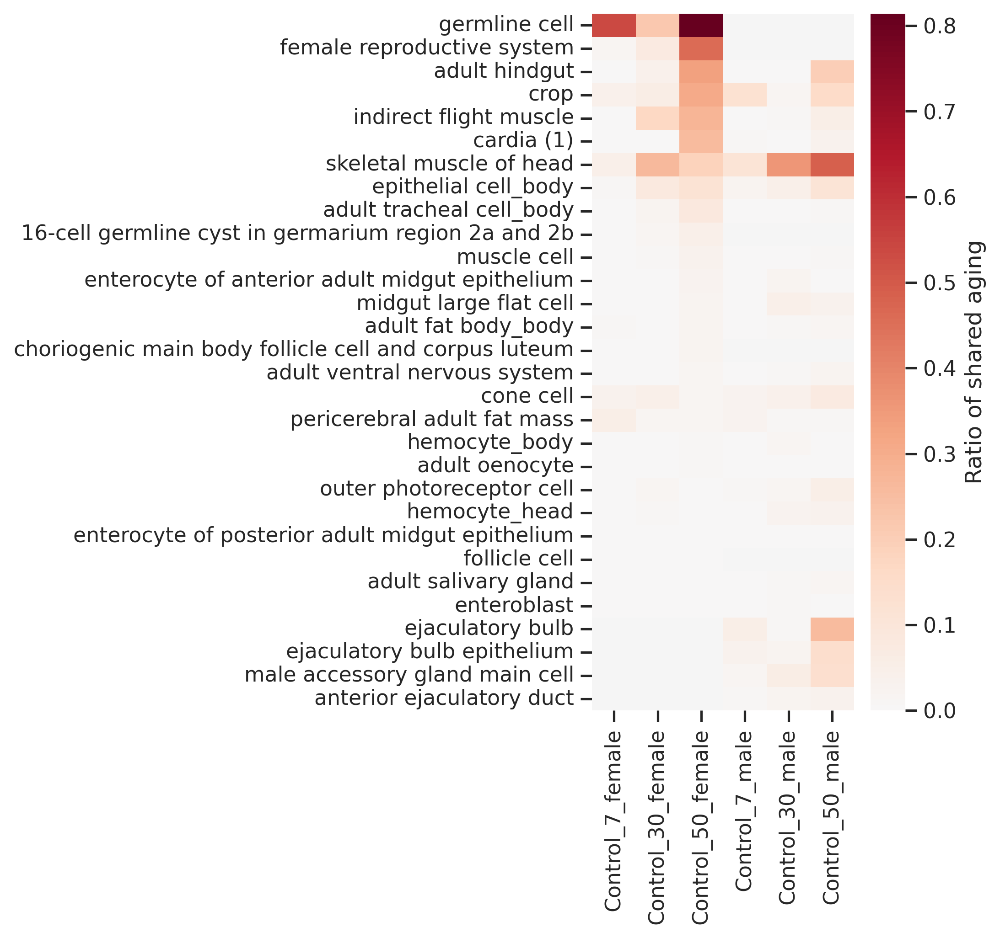

In [54]:
# control only

fig, ax = plt.subplots(figsize=(7, 7))
cmap = plt.cm.RdBu_r.copy() # Start with an existing colormap
cmap.set_bad('whitesmoke') # Set the color for NaN values
sns.heatmap(data=ratio_Df_ctl.astype(float), cmap=cmap, center=0, yticklabels=True, ax=ax, # vmin=-vmax, vmax=vmax, 
            cbar_kws={'label': 'Ratio'}) # fmt='.1f', annot=True,  # 
# ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
ax.collections[0].colorbar.set_label('Ratio of shared aging')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__sharedAgingRatio__control__no70.pdf', bbox_inches='tight')
plt.show()

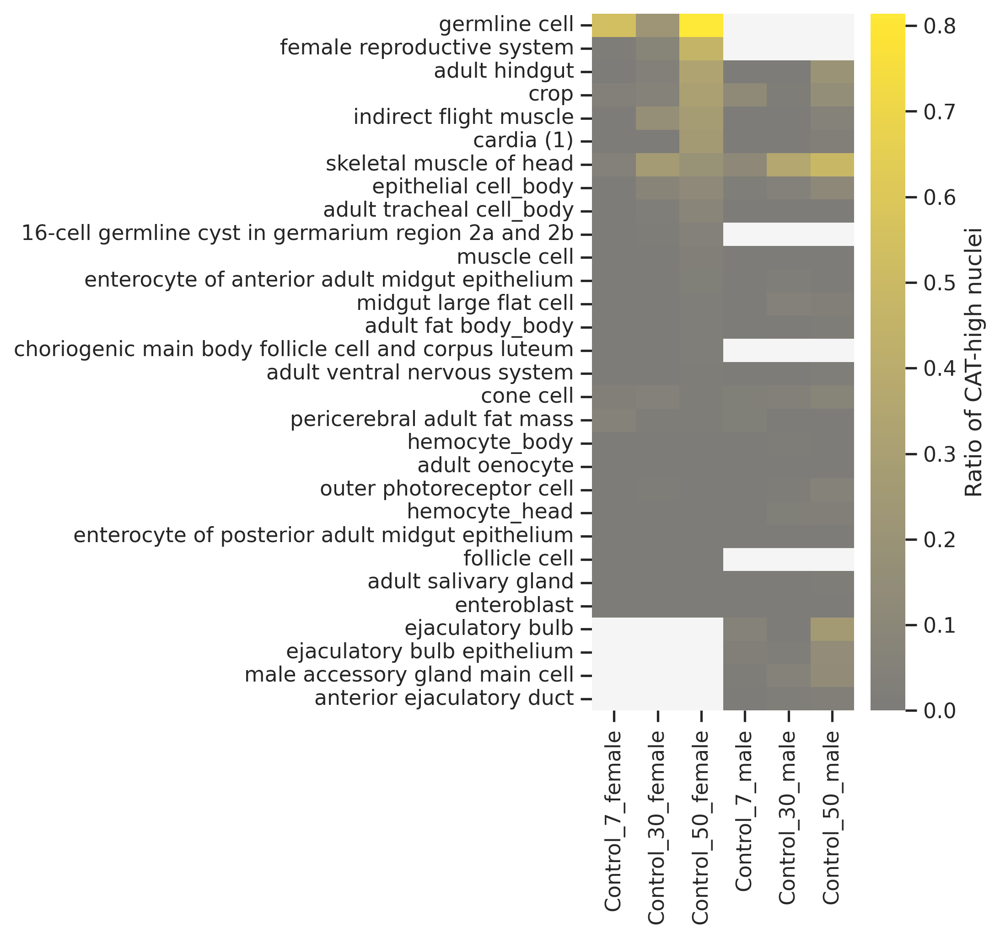

In [55]:
# control only

fig, ax = plt.subplots(figsize=(7, 7))
cmap = plt.cm.cividis.copy() # Start with an existing colormap
cmap.set_bad('whitesmoke') # Set the color for NaN values
sns.heatmap(data=ratio_Df_ctl.astype(float), cmap=cmap, center=0, yticklabels=True, ax=ax, # vmin=-vmax, vmax=vmax, 
            cbar_kws={'label': 'Ratio'}) # fmt='.1f', annot=True,  # 
# ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
ax.collections[0].colorbar.set_label('Ratio of CAT-high nuclei')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__sharedAgingRatio__control__no70_cividis.pdf', bbox_inches='tight')
plt.show()

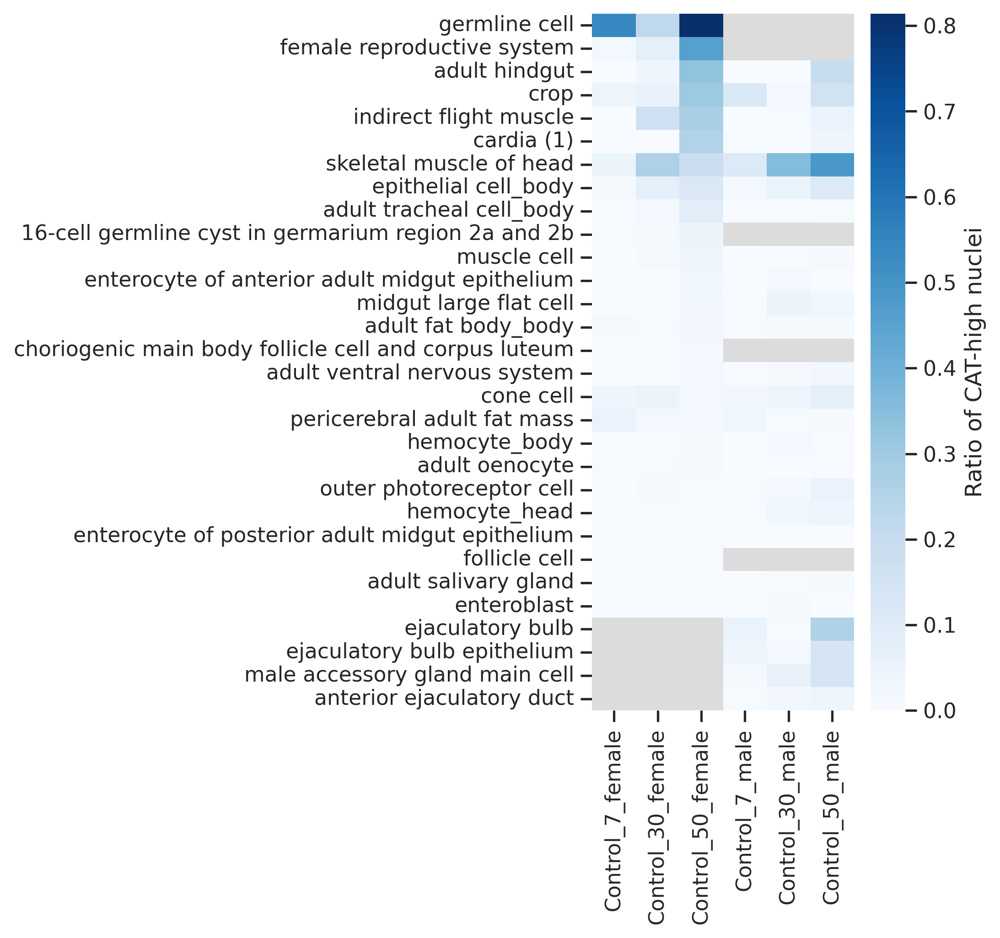

In [56]:
# control only

fig, ax = plt.subplots(figsize=(7, 7))
cmap = plt.cm.Blues.copy() # Start with an existing colormap
# cmap.set_bad('whitesmoke') # Set the color for NaN values
cmap.set_bad('gainsboro') # Set the color for NaN values
sns.heatmap(data=ratio_Df_ctl.astype(float), cmap=cmap, yticklabels=True, ax=ax, # vmin=-vmax, vmax=vmax, 
            cbar_kws={'label': 'Ratio'}) # fmt='.1f', annot=True,  # 
# ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
ax.collections[0].colorbar.set_label('Ratio of CAT-high nuclei')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__sharedAgingRatio__control__no70_Blues.pdf', bbox_inches='tight')
plt.show()

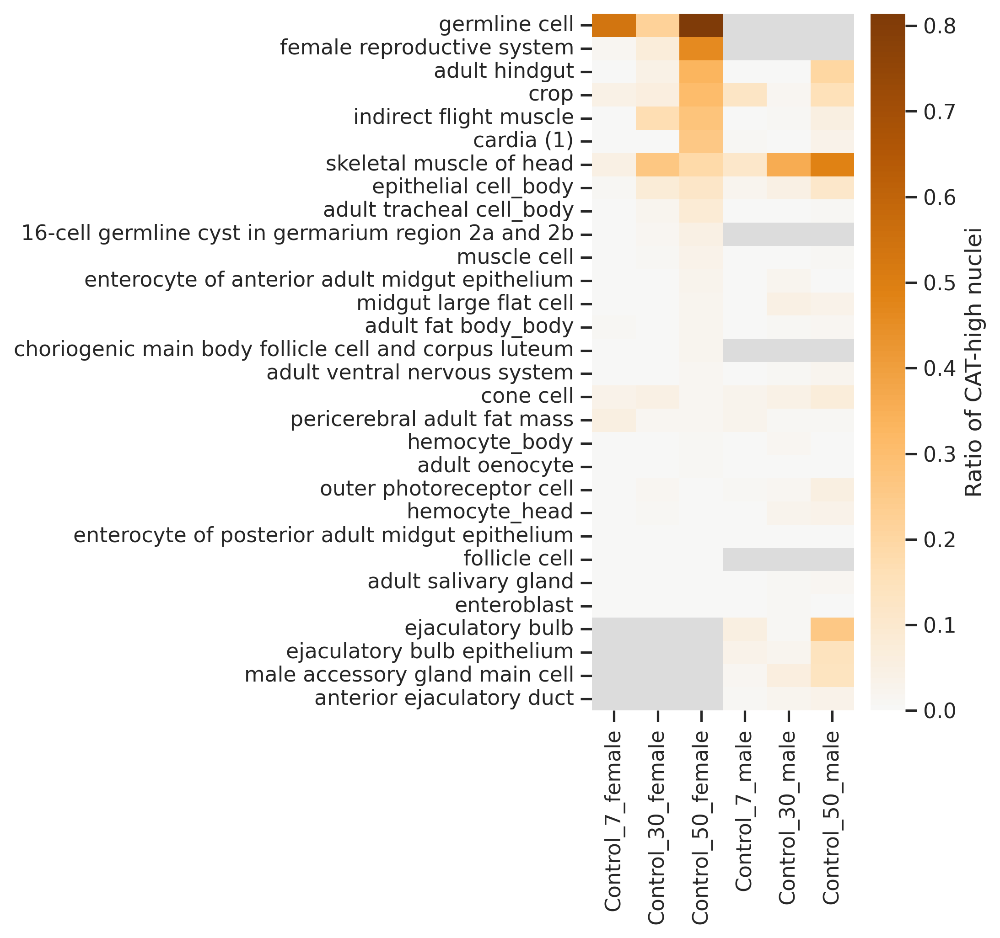

In [57]:
# control only

fig, ax = plt.subplots(figsize=(7, 7))
cmap = plt.cm.PuOr_r.copy() # Start with an existing colormap
# cmap.set_bad('whitesmoke') # Set the color for NaN values
cmap.set_bad('gainsboro') # Set the color for NaN values
sns.heatmap(data=ratio_Df_ctl.astype(float), cmap=cmap, center=0, yticklabels=True, ax=ax, # vmin=-vmax, vmax=vmax, 
            cbar_kws={'label': 'Ratio'}) # fmt='.1f', annot=True,  # 
# ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
ax.collections[0].colorbar.set_label('Ratio of CAT-high nuclei')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__sharedAgingRatio__control__no70_PuOr.pdf', bbox_inches='tight')
plt.show()

## calculate ratio (broad)

In [58]:
adata_headBody

AnnData object with n_obs × n_vars = 505731 × 15919
    obs: 'latent_RT_efficiency', 'latent_cell_probability', 'latent_scale', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'dataset', 'age', 'sex', 'tissue', 'condition', 'leiden', 'linearR_annotation', 'condAge', 'condSex', 'ageSex', 'condAgeSex', 'condAgeSexTissue', 'leiden_1.0', 'leiden_2.0', 'leiden_3.0', 'leiden_4.0', 'leiden_5.0', 'leiden_6.0', 'leiden_7.0', 'leiden_8.0', 'leiden_9.0', 'leiden_10.0', 'leiden_1.5', 'treatment', 'treatAge', 'treatAgeSex', 'treatSex', 'rapamycin_annotation', 'rapamycin_annotation_broad', 'rapamycin_annotation_subcluster', 'rapamycin_annotation_group', 'sharedAgingAve_up', 'sharedAgingAve_down', 'sharedAgingAve_upMinusDown', 'CAT_score', 'CAT_group', 'batch'
    var: 'gene_ids', 'highly_variable-0', 'means-0', 'dispersions-0', 'dispersions_norm-0', 'highly_variable-1', 'means-1', 'dispersions-1', 'dispersions_norm-1'
    obsm: 'X_pca', 'X_pca_original', 'X_tsne',

In [59]:
adata_headBody.obs['treatAgeSexTissue'] = pd.Categorical( adata_headBody.obs.treatAgeSex.astype(str) + '_' + adata_headBody.obs.tissue.astype(str) )

In [61]:
# head + body
ratio_Df = pd.DataFrame()
for treatAgeSexTissue in adata_headBody.obs.treatAgeSexTissue.cat.categories.to_list()[:]:
    print(treatAgeSexTissue)
    
    adata = adata_headBody[adata_headBody.obs.treatAgeSexTissue == treatAgeSexTissue]

    cellN_Df, cellN_ratio = cellN_cellRatio(adata, 'rapamycin_annotation_broad', 'CAT_group')
    cellN_ratio = cellN_ratio.iloc[:,:1]
    cellN_ratio.columns = [treatAgeSexTissue]
    cellN_ratio.insert(0, 'annotation', cellN_ratio.index.to_list())
    
    if len(ratio_Df) == 0: ratio_Df = cellN_ratio.copy()
    else:
        ratio_Df= pd.merge(ratio_Df, cellN_ratio, on='annotation', how='outer')

ratio_Df.index = ratio_Df.annotation.to_list()

Control_30_female_body
Control_30_female_head
Control_30_male_body
Control_30_male_head
Control_50_female_body
Control_50_female_head
Control_50_male_body
Control_50_male_head


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
 

Control_70_female_body
Control_70_female_head
Control_70_male_body
Control_70_male_head
Control_7_female_body
Control_7_female_head
Control_7_male_body
Control_7_male_head


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
 

Rapamycin_30_female_body
Rapamycin_30_female_head
Rapamycin_30_male_body
Rapamycin_30_male_head
Rapamycin_50_female_body
Rapamycin_50_female_head
Rapamycin_50_male_body
Rapamycin_50_male_head


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
 

Rapamycin_70_female_body
Rapamycin_70_female_head
Rapamycin_70_male_body
Rapamycin_70_male_head


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
 

In [62]:
ratio_Df

,annotation,Control_30_female_body,Control_30_female_head,Control_30_male_body,Control_30_male_head,Control_50_female_body,Control_50_female_head,Control_50_male_body,Control_50_male_head,Control_70_female_body,...,Rapamycin_30_male_body,Rapamycin_30_male_head,Rapamycin_50_female_body,Rapamycin_50_female_head,Rapamycin_50_male_body,Rapamycin_50_male_head,Rapamycin_70_female_body,Rapamycin_70_female_head,Rapamycin_70_male_body,Rapamycin_70_male_head
CNS neuron,CNS neuron,0.001346,0.006072,0.011765,0.006011,0.016867,0.00122,0.02343,0.017332,0.0,...,0.005731,0.009122,0.003604,0.003078,0.001709,0.006808,0.0,0.005095,0.0,0.00911
PNS neuron,PNS neuron,0.0,NaN,0.007407,NaN,0.007092,NaN,0.010204,NaN,0.0,...,0.007634,NaN,0.012987,NaN,0.008264,NaN,0.0,NaN,0.0,NaN
cardial cell,cardial cell,0.0,NaN,0.0,NaN,0.0,NaN,0.0,NaN,0.0,...,0.0,NaN,0.0,NaN,0.0,NaN,NaN,NaN,0.0,NaN
epithelial cell,epithelial cell,0.088748,0.281853,0.05071,0.472684,0.148269,0.215569,0.133595,0.60447,0.057125,...,0.077426,0.458145,0.072205,0.250758,0.074324,0.535098,0.069204,0.262552,0.028827,0.247984
excretory system,excretory system,0.007874,NaN,0.025,NaN,0.711111,NaN,0.066667,NaN,0.083333,...,0.028571,NaN,0.114754,NaN,0.04918,NaN,0.166667,NaN,0.042553,NaN
fat cell,fat cell,0.003498,0.068279,0.011373,0.128631,0.022265,0.037545,0.015562,0.264945,0.024206,...,0.003015,0.192708,0.020523,0.090909,0.007184,0.227969,0.016213,0.077852,0.002405,0.04753
female germline cell,female germline cell,0.176427,NaN,NaN,NaN,0.749741,NaN,NaN,NaN,0.400703,...,NaN,NaN,0.482998,NaN,NaN,NaN,0.298246,NaN,NaN,NaN
female reproductive system,female reproductive system,0.004209,NaN,NaN,NaN,0.029857,NaN,NaN,NaN,0.006121,...,NaN,NaN,0.020554,NaN,NaN,NaN,0.005869,NaN,NaN,NaN
gland,gland,0.0,NaN,0.035933,NaN,0.0,NaN,0.161452,NaN,0.0,...,0.049875,NaN,0.0,NaN,0.059772,NaN,0.0,NaN,0.061176,NaN
glial cell,glial cell,0.0,0.068107,0.016949,0.053615,0.031088,0.024118,0.017065,0.122518,0.012048,...,0.012195,0.04524,0.005479,0.029077,0.0,0.060624,0.020619,0.057588,0.012048,0.040838


In [58]:
# body
ratioBody_Df = pd.DataFrame()
for treatAgeSex in adata_body.obs.treatAgeSex.cat.categories.to_list()[:]:
    print(treatAgeSex)
    
    adata = adata_body[adata_body.obs.treatAgeSex == treatAgeSex]

    cellN_Df, cellN_ratio = cellN_cellRatio(adata, 'rapamycin_annotation_broad', 'CAT_group')
    cellN_ratio = cellN_ratio.iloc[:,:1]
    cellN_ratio.columns = [treatAgeSex]
    cellN_ratio.insert(0, 'annotation', cellN_ratio.index.to_list())
    
    if len(ratioBody_Df) == 0: ratioBody_Df = cellN_ratio.copy()
    else:
        ratioBody_Df= pd.merge(ratioBody_Df, cellN_ratio, on='annotation', how='outer')

ratioBody_Df.index = ratioBody_Df.annotation.to_list()
# ratioBody_Df

Control_30_female
Control_30_male
Control_50_female
Control_50_male
Control_70_female
Control_70_male
Control_7_female
Control_7_male


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
 

Rapamycin_30_female
Rapamycin_30_male
Rapamycin_50_female
Rapamycin_50_male
Rapamycin_70_female
Rapamycin_70_male


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
 

In [59]:
# head
ratioHead_Df = pd.DataFrame()
for treatAgeSex in adata_head.obs.treatAgeSex.cat.categories.to_list()[:]:
    print(treatAgeSex)
    
    adata = adata_head[adata_head.obs.treatAgeSex == treatAgeSex]

    cellN_Df, cellN_ratio = cellN_cellRatio(adata, 'rapamycin_annotation_broad', 'CAT_group')
    cellN_ratio = cellN_ratio.iloc[:,:1]
    cellN_ratio.columns = [treatAgeSex]
    cellN_ratio.insert(0, 'annotation', cellN_ratio.index.to_list())
    
    if len(ratioHead_Df) == 0: ratioHead_Df = cellN_ratio.copy()
    else:
        ratioHead_Df= pd.merge(ratioHead_Df, cellN_ratio, on='annotation', how='outer')

ratioHead_Df.index = ratioHead_Df.annotation.to_list()
# ratioHead_Df

Control_30_female
Control_30_male
Control_50_female
Control_50_male
Control_70_female
Control_70_male
Control_7_female
Control_7_male


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
 

Rapamycin_30_female
Rapamycin_30_male
Rapamycin_50_female
Rapamycin_50_male
Rapamycin_70_female
Rapamycin_70_male


<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cellN_Df = pd.DataFrame(adata.obs.groupby([sampleCol, annotCol]).size()).unstack(annotCol)
<ipython-input-33-ea2bf25e01e3>:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
 

In [60]:
ratioHead_Df

,annotation,Control_30_female,Control_30_male,Control_50_female,Control_50_male,Control_70_female,Control_70_male,Control_7_female,Control_7_male,Rapamycin_30_female,Rapamycin_30_male,Rapamycin_50_female,Rapamycin_50_male,Rapamycin_70_female,Rapamycin_70_male
CNS neuron,CNS neuron,0.006072,0.006011,0.00122,0.017332,0.005403,0.013887,0.001061,0.003129,0.004133,0.009122,0.003078,0.006808,0.005095,0.00911
epithelial cell,epithelial cell,0.281853,0.472684,0.215569,0.60447,0.311765,0.283493,0.232125,0.200292,0.24767,0.458145,0.250758,0.535098,0.262552,0.247984
fat cell,fat cell,0.068279,0.128631,0.037545,0.264945,0.077574,0.037936,0.100304,0.082397,0.062099,0.192708,0.090909,0.227969,0.077852,0.04753
glial cell,glial cell,0.068107,0.053615,0.024118,0.122518,0.050592,0.056265,0.01611,0.022682,0.043282,0.04524,0.029077,0.060624,0.057588,0.040838
hemocyte,hemocyte,0.00813,0.030303,0.004149,0.037313,0.005263,0.008734,0.002577,0.003356,0.016,0.031915,0.0,0.026786,0.008163,0.004149
muscle cell,muscle cell,0.265385,0.3584,0.18662,0.488372,0.238636,0.278884,0.047525,0.11413,0.278607,0.501441,0.227373,0.41958,0.190789,0.338129
sensory neuron,sensory neuron,0.026149,0.031349,0.009182,0.054945,0.016644,0.028798,0.015584,0.016503,0.016349,0.03733,0.014791,0.023989,0.013889,0.026432
tracheal cell,tracheal cell,0.051402,0.026316,0.019737,0.074286,0.018735,0.020958,0.007828,0.008242,0.029536,0.069444,0.014184,0.099174,0.013928,0.00495
unannotated,unannotated,0.245416,0.221937,0.111621,0.444714,0.191391,0.1625,0.103879,0.110769,0.155131,0.258684,0.100158,0.317817,0.167587,0.148455


In [61]:
treatAgeSexComp_L

['Control_7_female',
 'Control_30_female',
 'Rapamycin_30_female',
 'Control_50_female',
 'Rapamycin_50_female',
 'Control_7_male',
 'Control_30_male',
 'Rapamycin_30_male',
 'Control_50_male',
 'Rapamycin_50_male']

In [63]:
ratio_Df = pd.concat([ratioBody_Df, ratioHead_Df])
# ratio_Df = ratio_Df.loc[[ct for ct in ratio_Df.index if ct in degNindex_L], treatAgeSexComp_L]

ratio_Df

,annotation,Control_30_female,Control_30_male,Control_50_female,Control_50_male,Control_70_female,Control_70_male,Control_7_female,Control_7_male,Rapamycin_30_female,Rapamycin_30_male,Rapamycin_50_female,Rapamycin_50_male,Rapamycin_70_female,Rapamycin_70_male
CNS neuron,CNS neuron,0.001346,0.011765,0.016867,0.02343,0.0,0.017301,0.0,0.0,0.0,0.005731,0.003604,0.001709,0.0,0.0
PNS neuron,PNS neuron,0.0,0.007407,0.007092,0.010204,0.0,0.0,0.0,0.013158,0.0,0.007634,0.012987,0.008264,0.0,0.0
cardial cell,cardial cell,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,NaN,0.0
epithelial cell,epithelial cell,0.088748,0.05071,0.148269,0.133595,0.057125,0.090818,0.010978,0.016312,0.028139,0.077426,0.072205,0.074324,0.069204,0.028827
excretory system,excretory system,0.007874,0.025,0.711111,0.066667,0.083333,0.072727,0.033333,0.037037,0.017241,0.028571,0.114754,0.04918,0.166667,0.042553
fat cell,fat cell,0.003498,0.011373,0.022265,0.015562,0.024206,0.011905,0.011594,0.005635,0.003822,0.003015,0.020523,0.007184,0.016213,0.002405
female germline cell,female germline cell,0.176427,NaN,0.749741,NaN,0.400703,NaN,0.266476,NaN,0.174359,NaN,0.482998,NaN,0.298246,NaN
female reproductive system,female reproductive system,0.004209,NaN,0.029857,NaN,0.006121,NaN,0.000279,NaN,0.002583,NaN,0.020554,NaN,0.005869,NaN
gland,gland,0.0,0.035933,0.0,0.161452,0.0,0.076019,0.0,0.026106,0.0,0.049875,0.0,0.059772,0.0,0.061176
glial cell,glial cell,0.0,0.016949,0.031088,0.017065,0.012048,0.006536,0.0,0.004505,0.0,0.012195,0.005479,0.0,0.020619,0.012048


In [50]:
ratio_Df = ratio_Df.sort_values(by=['Control_50_female', 'Control_50_male'], ascending=False)
ratio_Df

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089,NaN,NaN,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.065934,0.46087,0.222727,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.0,0.039216,0.121951,0.333333,0.181818,0.0,0.0,0.015038,0.197802,0.04717
crop,0.041534,0.059028,0.036638,0.307042,0.094139,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000479,0.170732,0.01938,0.27752,0.284598,0.0,0.008673,0.008594,0.052448,0.180915
cardia (1),0.0,0.0,0.010753,0.255814,0.010204,0.007194,0.0,0.0,0.036145,0.040984
skeletal muscle of head,0.047525,0.265385,0.278607,0.18662,0.227373,0.11413,0.3584,0.501441,0.488372,0.41958
epithelial cell_body,0.01125,0.076923,0.025943,0.12029,0.068251,0.019856,0.047722,0.067568,0.110126,0.06821
adult tracheal cell_body,0.001344,0.020134,0.002681,0.08642,0.009245,0.0,0.0,0.002646,0.00722,0.004484
16-cell germline cyst in germarium region 2a and 2b,0.005618,0.013986,0.008368,0.04918,0.078853,NaN,NaN,NaN,NaN,NaN


In [51]:
ratio_Df_ctl = ratio_Df.loc[:, [col for col in ratio_Df.columns if 'Control' in col]]
ratio_Df_ctl

,Control_7_female,Control_30_female,Control_50_female,Control_7_male,Control_30_male,Control_50_male
germline cell,0.538012,0.220132,0.814076,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.46087,NaN,NaN,NaN
adult hindgut,0.0,0.039216,0.333333,0.0,0.0,0.197802
crop,0.041534,0.059028,0.307042,0.121019,0.017308,0.156627
indirect flight muscle,0.000479,0.170732,0.27752,0.0,0.008673,0.052448
cardia (1),0.0,0.0,0.255814,0.007194,0.0,0.036145
skeletal muscle of head,0.047525,0.265385,0.18662,0.11413,0.3584,0.488372
epithelial cell_body,0.01125,0.076923,0.12029,0.019856,0.047722,0.110126
adult tracheal cell_body,0.001344,0.020134,0.08642,0.0,0.0,0.00722
16-cell germline cyst in germarium region 2a and 2b,0.005618,0.013986,0.04918,NaN,NaN,NaN


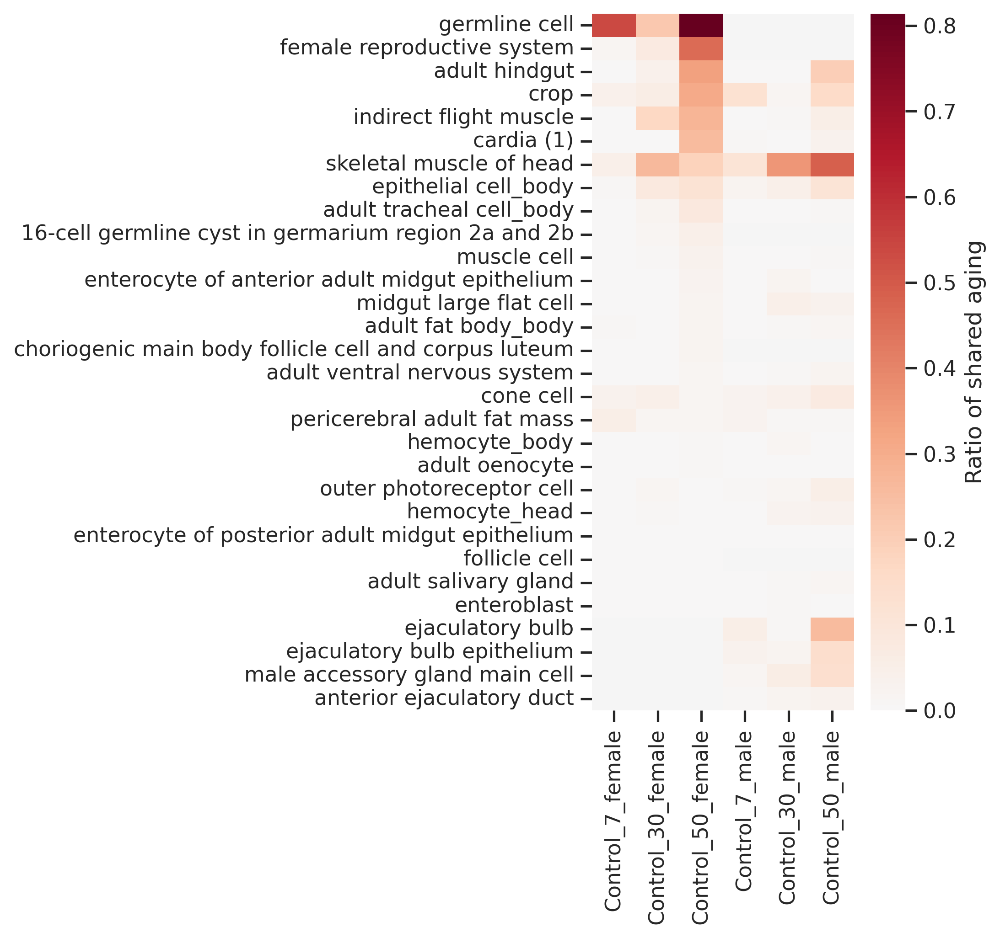

In [55]:
# control only

fig, ax = plt.subplots(figsize=(7, 7))
cmap = plt.cm.RdBu_r.copy() # Start with an existing colormap
cmap.set_bad('whitesmoke') # Set the color for NaN values
sns.heatmap(data=ratio_Df_ctl.astype(float), cmap=cmap, center=0, yticklabels=True, ax=ax, # vmin=-vmax, vmax=vmax, 
            cbar_kws={'label': 'Ratio'}) # fmt='.1f', annot=True,  # 
# ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
ax.collections[0].colorbar.set_label('Ratio of shared aging')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__sharedAgingRatio__control__no70.pdf', bbox_inches='tight')
plt.show()

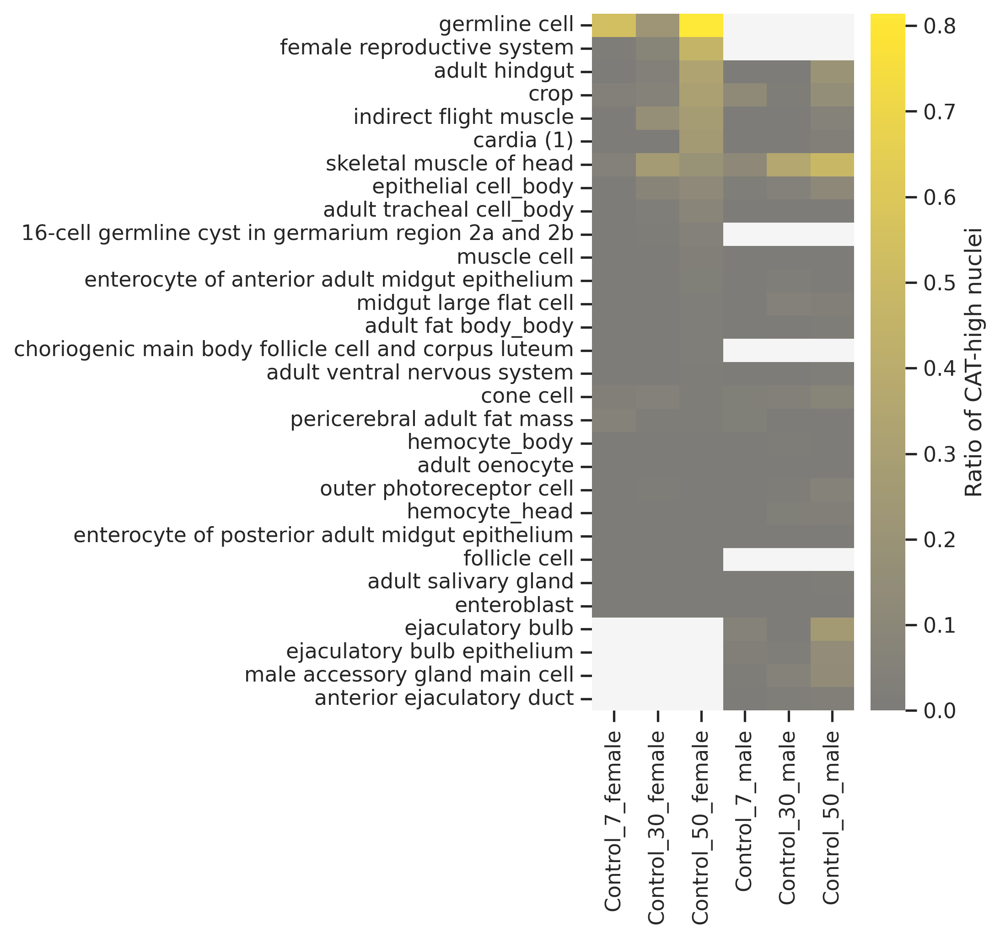

In [56]:
# control only

fig, ax = plt.subplots(figsize=(7, 7))
cmap = plt.cm.cividis.copy() # Start with an existing colormap
cmap.set_bad('whitesmoke') # Set the color for NaN values
sns.heatmap(data=ratio_Df_ctl.astype(float), cmap=cmap, center=0, yticklabels=True, ax=ax, # vmin=-vmax, vmax=vmax, 
            cbar_kws={'label': 'Ratio'}) # fmt='.1f', annot=True,  # 
# ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
ax.collections[0].colorbar.set_label('Ratio of CAT-high nuclei')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__sharedAgingRatio__control__no70_cividis.pdf', bbox_inches='tight')
plt.show()

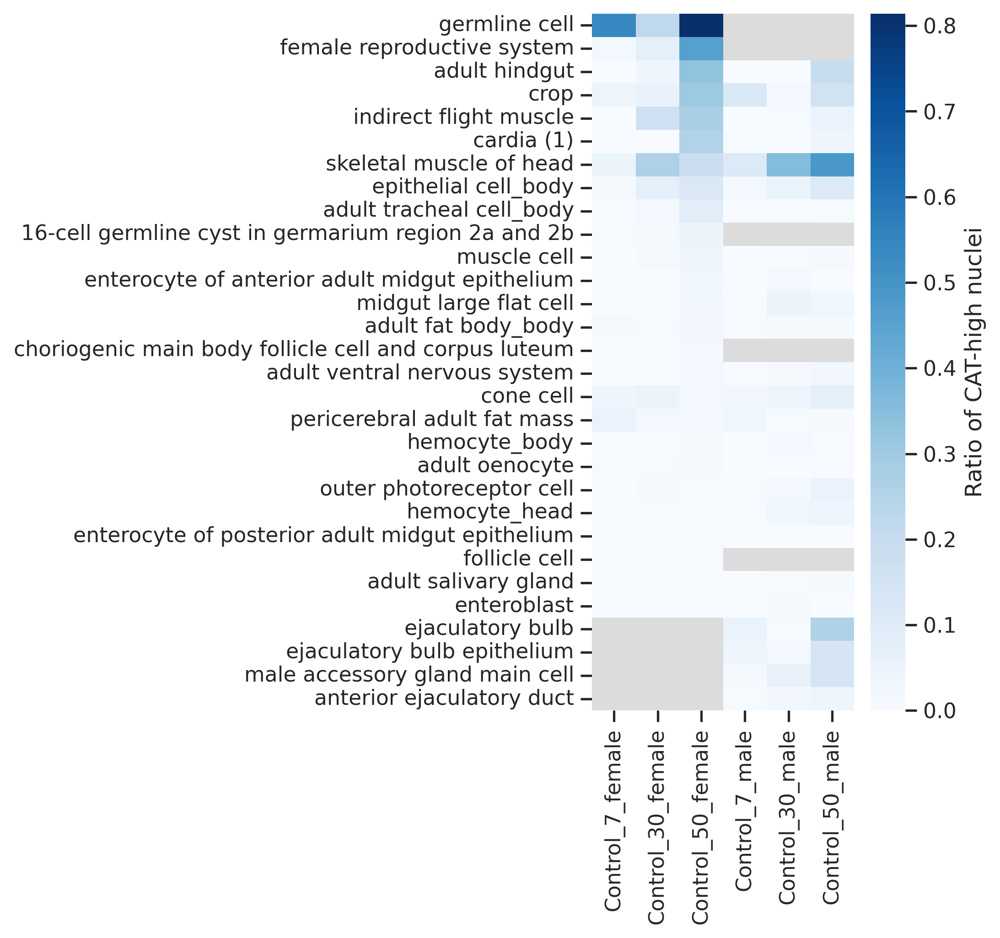

In [57]:
# control only

fig, ax = plt.subplots(figsize=(7, 7))
cmap = plt.cm.Blues.copy() # Start with an existing colormap
# cmap.set_bad('whitesmoke') # Set the color for NaN values
cmap.set_bad('gainsboro') # Set the color for NaN values
sns.heatmap(data=ratio_Df_ctl.astype(float), cmap=cmap, yticklabels=True, ax=ax, # vmin=-vmax, vmax=vmax, 
            cbar_kws={'label': 'Ratio'}) # fmt='.1f', annot=True,  # 
# ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
ax.collections[0].colorbar.set_label('Ratio of CAT-high nuclei')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__sharedAgingRatio__control__no70_Blues.pdf', bbox_inches='tight')
plt.show()

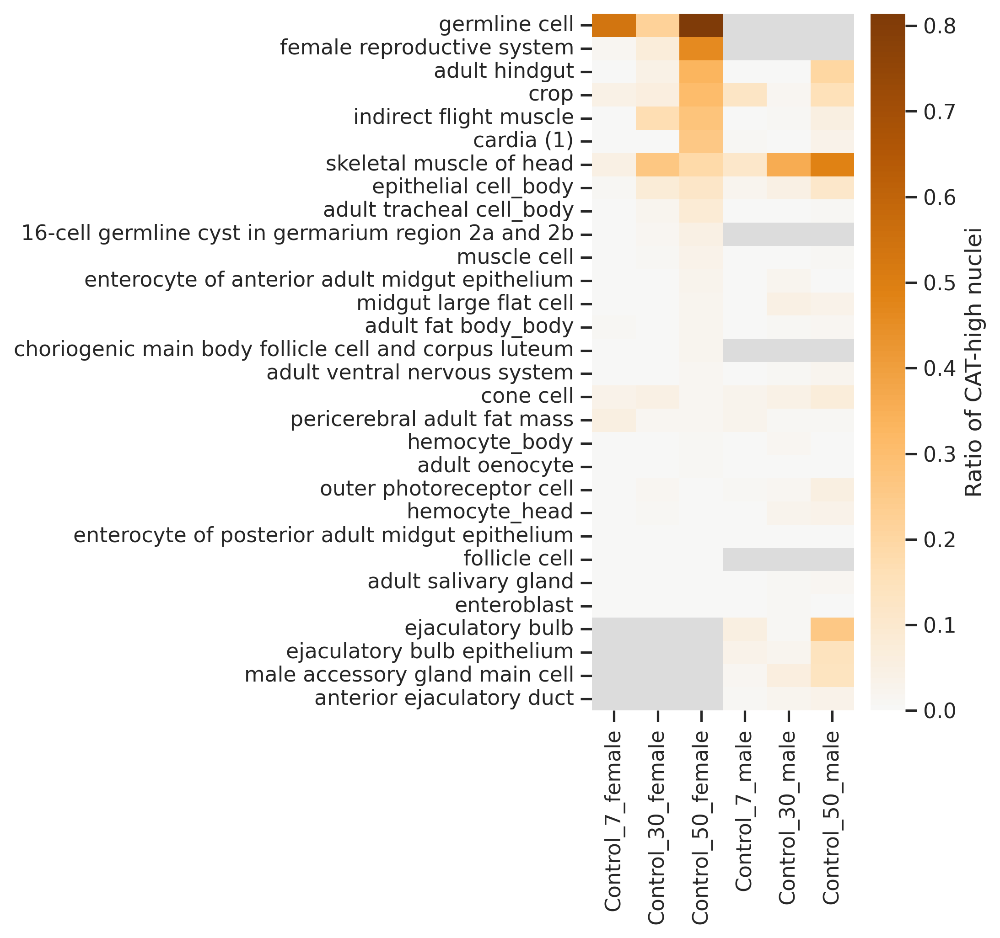

In [58]:
# control only

fig, ax = plt.subplots(figsize=(7, 7))
cmap = plt.cm.PuOr_r.copy() # Start with an existing colormap
# cmap.set_bad('whitesmoke') # Set the color for NaN values
cmap.set_bad('gainsboro') # Set the color for NaN values
sns.heatmap(data=ratio_Df_ctl.astype(float), cmap=cmap, center=0, yticklabels=True, ax=ax, # vmin=-vmax, vmax=vmax, 
            cbar_kws={'label': 'Ratio'}) # fmt='.1f', annot=True,  # 
# ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
ax.collections[0].colorbar.set_label('Ratio of CAT-high nuclei')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__sharedAgingRatio__control__no70_PuOr.pdf', bbox_inches='tight')
plt.show()

## ratio differences between Rapa and controls

In [59]:
ratio_Df

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089,NaN,NaN,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.065934,0.46087,0.222727,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.0,0.039216,0.121951,0.333333,0.181818,0.0,0.0,0.015038,0.197802,0.04717
crop,0.041534,0.059028,0.036638,0.307042,0.094139,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000479,0.170732,0.01938,0.27752,0.284598,0.0,0.008673,0.008594,0.052448,0.180915
cardia (1),0.0,0.0,0.010753,0.255814,0.010204,0.007194,0.0,0.0,0.036145,0.040984
skeletal muscle of head,0.047525,0.265385,0.278607,0.18662,0.227373,0.11413,0.3584,0.501441,0.488372,0.41958
epithelial cell_body,0.01125,0.076923,0.025943,0.12029,0.068251,0.019856,0.047722,0.067568,0.110126,0.06821
adult tracheal cell_body,0.001344,0.020134,0.002681,0.08642,0.009245,0.0,0.0,0.002646,0.00722,0.004484
16-cell germline cyst in germarium region 2a and 2b,0.005618,0.013986,0.008368,0.04918,0.078853,NaN,NaN,NaN,NaN,NaN


In [60]:
# Female
ratioF_com_Df = ratio_Df.iloc[:,[1,3,2,4]]
# ratioF_com_Df = ratioF_com_Df.replace(0, 0.0000001)
# ratioF_com_Df = pd.DataFrame(np.log2(ratioF_com_Df.iloc[:,2:].to_numpy()-ratioF_com_Df.iloc[:,:2].to_numpy()), 
#                              index=ratioF_com_Df.index, columns=['Rapa_vs_Control__30d', 'Rapa_vs_Control__50d'])
ratioF_com_Df = pd.DataFrame( ratioF_com_Df.iloc[:,2:].to_numpy()-ratioF_com_Df.iloc[:,:2].to_numpy(), 
                             index=ratioF_com_Df.index, columns=['Rapa_vs_Control__30d__F', 'Rapa_vs_Control__50d__F'])

ratioF_com_Df

,Rapa_vs_Control__30d__F,Rapa_vs_Control__50d__F
germline cell,0.027558,-0.219987
female reproductive system,-0.010153,-0.238142
adult hindgut,0.082736,-0.151515
crop,-0.02239,-0.212904
indirect flight muscle,-0.151352,0.007077
cardia (1),0.010753,-0.24561
skeletal muscle of head,0.013222,0.040753
epithelial cell_body,-0.05098,-0.052039
adult tracheal cell_body,-0.017453,-0.077175
16-cell germline cyst in germarium region 2a and 2b,-0.005618,0.029673


In [61]:
# Male
ratioM_com_Df = ratio_Df.iloc[:,[6,8,7,9]]
# ratioM_com_Df = ratioM_com_Df.replace(0, 0.0000001)
# # ratioM_com_Df = pd.DataFrame(np.log2(ratioM_com_Df.iloc[:,2:].to_numpy()-ratioM_com_Df.iloc[:,:2].to_numpy()), 
# #                              index=ratioM_com_Df.index, columns=['Rapa_vs_Control__30d', 'Rapa_vs_Control__50d'])

ratioM_com_Df = pd.DataFrame( ratioM_com_Df.iloc[:,2:].to_numpy()-ratioM_com_Df.iloc[:,:2].to_numpy(), 
                             index=ratioM_com_Df.index, columns=['Rapa_vs_Control__30d__M', 'Rapa_vs_Control__50d__M'])


ratioM_com_Df

,Rapa_vs_Control__30d__M,Rapa_vs_Control__50d__M
germline cell,NaN,NaN
female reproductive system,NaN,NaN
adult hindgut,0.015038,-0.150632
crop,0.005795,-0.093395
indirect flight muscle,-0.000079,0.128467
cardia (1),0.0,0.004839
skeletal muscle of head,0.143041,-0.068792
epithelial cell_body,0.019845,-0.041916
adult tracheal cell_body,0.002646,-0.002736
16-cell germline cyst in germarium region 2a and 2b,NaN,NaN


In [62]:
ratio_com_Df = pd.concat([ratioF_com_Df, ratioM_com_Df], axis=1)
ratio_com_Df = ratio_com_Df.iloc[:,[0,2,1,3]]
ratio_com_Df

,Rapa_vs_Control__30d__F,Rapa_vs_Control__30d__M,Rapa_vs_Control__50d__F,Rapa_vs_Control__50d__M
germline cell,0.027558,NaN,-0.219987,NaN
female reproductive system,-0.010153,NaN,-0.238142,NaN
adult hindgut,0.082736,0.015038,-0.151515,-0.150632
crop,-0.02239,0.005795,-0.212904,-0.093395
indirect flight muscle,-0.151352,-0.000079,0.007077,0.128467
cardia (1),0.010753,0.0,-0.24561,0.004839
skeletal muscle of head,0.013222,0.143041,0.040753,-0.068792
epithelial cell_body,-0.05098,0.019845,-0.052039,-0.041916
adult tracheal cell_body,-0.017453,0.002646,-0.077175,-0.002736
16-cell germline cyst in germarium region 2a and 2b,-0.005618,NaN,0.029673,NaN


In [63]:
vmax = abs(ratio_com_Df).max().max()
vmax

0.24560987185571903

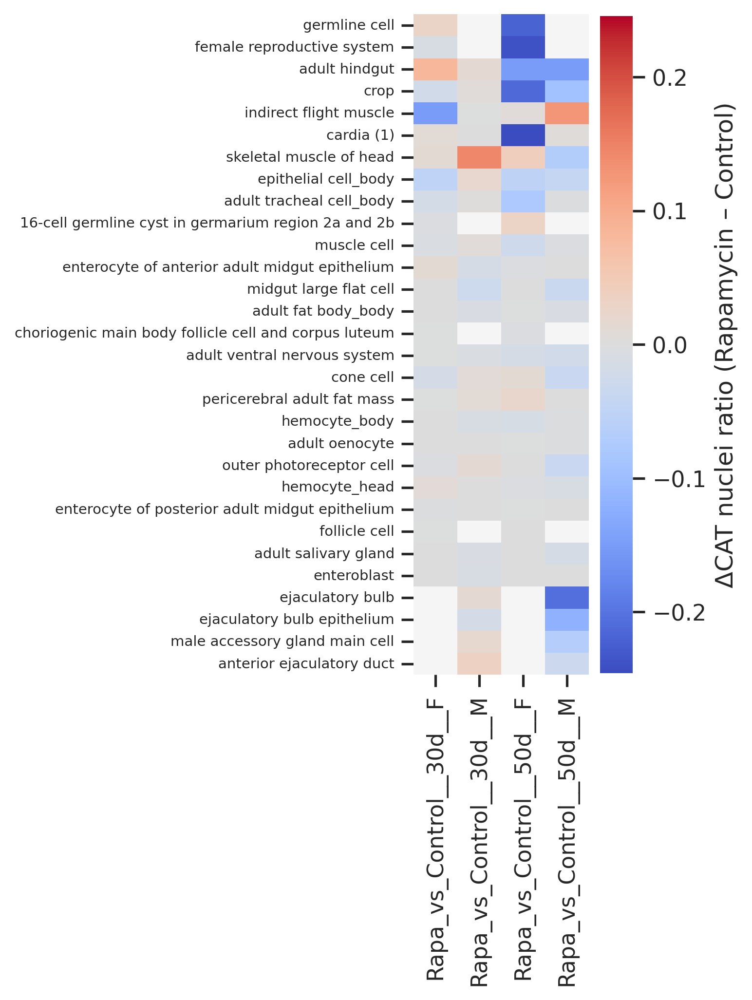

In [64]:
fig, ax = plt.subplots(figsize=(5, 7))
cmap = plt.cm.coolwarm.copy() # Start with an existing colormap
cmap.set_bad('whitesmoke') # Set the color for NaN values

sns.heatmap(data=ratio_com_Df.astype(float), cmap=cmap, center=0, yticklabels=True, ax=ax,  vmin=-vmax, vmax=vmax, 
            ) # fmt='.1f', annot=True,  # cbar_kws={'label': 'Value'}
ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
# ax.collections[0].colorbar.set_label('Δratio')
ax.collections[0].colorbar.set_label('ΔCAT nuclei ratio (Rapamycin – Control)')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__CAT_nuclei__rapaToControl__no70__coolwarm.pdf', bbox_inches='tight')
plt.show()

In [65]:
### output dataframe
ratio_Df.to_csv(f'{figure5Folder}/ratio_Df.csv')
ratio_com_Df.to_csv(f'{figure5Folder}/ratio_com_Df.csv')

In [66]:
ratio_Df

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089,NaN,NaN,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.065934,0.46087,0.222727,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.0,0.039216,0.121951,0.333333,0.181818,0.0,0.0,0.015038,0.197802,0.04717
crop,0.041534,0.059028,0.036638,0.307042,0.094139,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000479,0.170732,0.01938,0.27752,0.284598,0.0,0.008673,0.008594,0.052448,0.180915
cardia (1),0.0,0.0,0.010753,0.255814,0.010204,0.007194,0.0,0.0,0.036145,0.040984
skeletal muscle of head,0.047525,0.265385,0.278607,0.18662,0.227373,0.11413,0.3584,0.501441,0.488372,0.41958
epithelial cell_body,0.01125,0.076923,0.025943,0.12029,0.068251,0.019856,0.047722,0.067568,0.110126,0.06821
adult tracheal cell_body,0.001344,0.020134,0.002681,0.08642,0.009245,0.0,0.0,0.002646,0.00722,0.004484
16-cell germline cyst in germarium region 2a and 2b,0.005618,0.013986,0.008368,0.04918,0.078853,NaN,NaN,NaN,NaN,NaN


## other comparisons

In [34]:
### input dataframe
ratio_Df = pd.read_csv(f'{figure5Folder}/ratio_Df.csv', index_col=0)
ratio_com_Df = pd.read_csv(f'{figure5Folder}/ratio_com_Df.csv', index_col=0)

ratio_Df


,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089,NaN,NaN,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.065934,0.460870,0.222727,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.000000,0.039216,0.121951,0.333333,0.181818,0.000000,0.000000,0.015038,0.197802,0.047170
crop,0.041534,0.059028,0.036638,0.307042,0.094139,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000479,0.170732,0.019380,0.277520,0.284598,0.000000,0.008673,0.008594,0.052448,0.180915
cardia (1),0.000000,0.000000,0.010753,0.255814,0.010204,0.007194,0.000000,0.000000,0.036145,0.040984
skeletal muscle of head,0.047525,0.265385,0.278607,0.186620,0.227373,0.114130,0.358400,0.501441,0.488372,0.419580
epithelial cell_body,0.011250,0.076923,0.025943,0.120290,0.068251,0.019856,0.047722,0.067568,0.110126,0.068210
adult tracheal cell_body,0.001344,0.020134,0.002681,0.086420,0.009245,0.000000,0.000000,0.002646,0.007220,0.004484
16-cell germline cyst in germarium region 2a and 2b,0.005618,0.013986,0.008368,0.049180,0.078853,NaN,NaN,NaN,NaN,NaN


In [54]:
ratioMax = ratio_Df_ctl.max().max()
ratioMax

0.8614979299962363

In [35]:
ratio_Df_F = ratio_Df.loc[:, [col for col in ratio_Df.columns if 'female' in col]]
ratio_Df_F

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089
female reproductive system,0.017699,0.076087,0.065934,0.460870,0.222727
adult hindgut,0.000000,0.039216,0.121951,0.333333,0.181818
crop,0.041534,0.059028,0.036638,0.307042,0.094139
indirect flight muscle,0.000479,0.170732,0.019380,0.277520,0.284598
cardia (1),0.000000,0.000000,0.010753,0.255814,0.010204
skeletal muscle of head,0.047525,0.265385,0.278607,0.186620,0.227373
epithelial cell_body,0.011250,0.076923,0.025943,0.120290,0.068251
adult tracheal cell_body,0.001344,0.020134,0.002681,0.086420,0.009245
16-cell germline cyst in germarium region 2a and 2b,0.005618,0.013986,0.008368,0.049180,0.078853


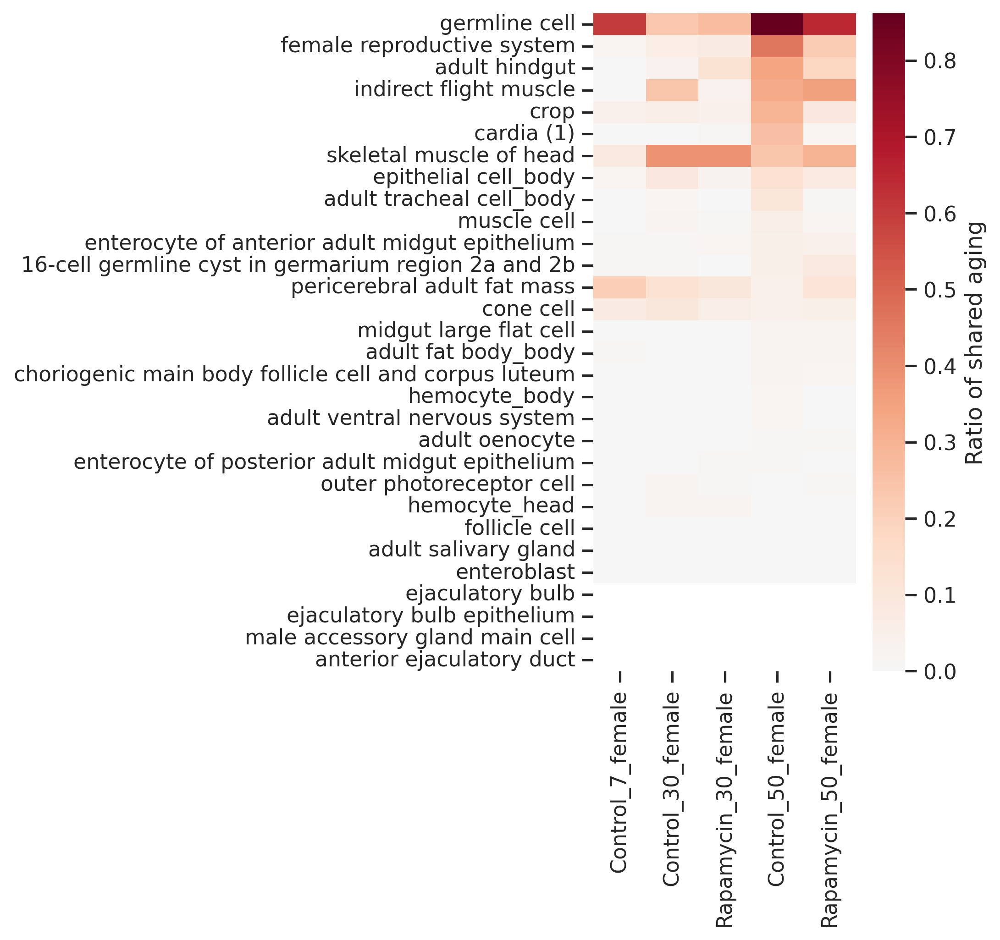

In [56]:
# Female
fig, ax = plt.subplots(figsize=(7, 7))
cmap = plt.cm.RdBu_r.copy() # Start with an existing colormap
cmap.set_bad('white') # Set the color for NaN values
sns.heatmap(data=ratio_Df_F.astype(float), cmap=cmap, center=0, yticklabels=True, ax=ax, vmax=ratioMax, # vmin=-vmax, 
            cbar_kws={'label': 'Ratio'}) # fmt='.1f', annot=True,  # 
# ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
ax.collections[0].colorbar.set_label('Ratio of shared aging')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__sharedAgingRatio__female__no70.pdf', bbox_inches='tight')
plt.show()

In [58]:
ratio_Df_F

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female
germline cell,0.599415,0.234243,0.264325,0.861498,0.651232
female reproductive system,0.017699,0.065217,0.071429,0.46087,0.215909
adult hindgut,0.0,0.039216,0.121951,0.343137,0.181818
indirect flight muscle,0.000718,0.241685,0.035437,0.325029,0.353103
crop,0.041534,0.059028,0.045259,0.295775,0.090586
cardia (1),0.0,0.0,0.010753,0.255814,0.015306
skeletal muscle of head,0.085149,0.384615,0.38806,0.235915,0.300221
epithelial cell_body,0.01375,0.087657,0.03066,0.136232,0.07689
adult tracheal cell_body,0.001344,0.020134,0.002681,0.102881,0.010786
muscle cell,0.001666,0.02454,0.007656,0.05985,0.015237


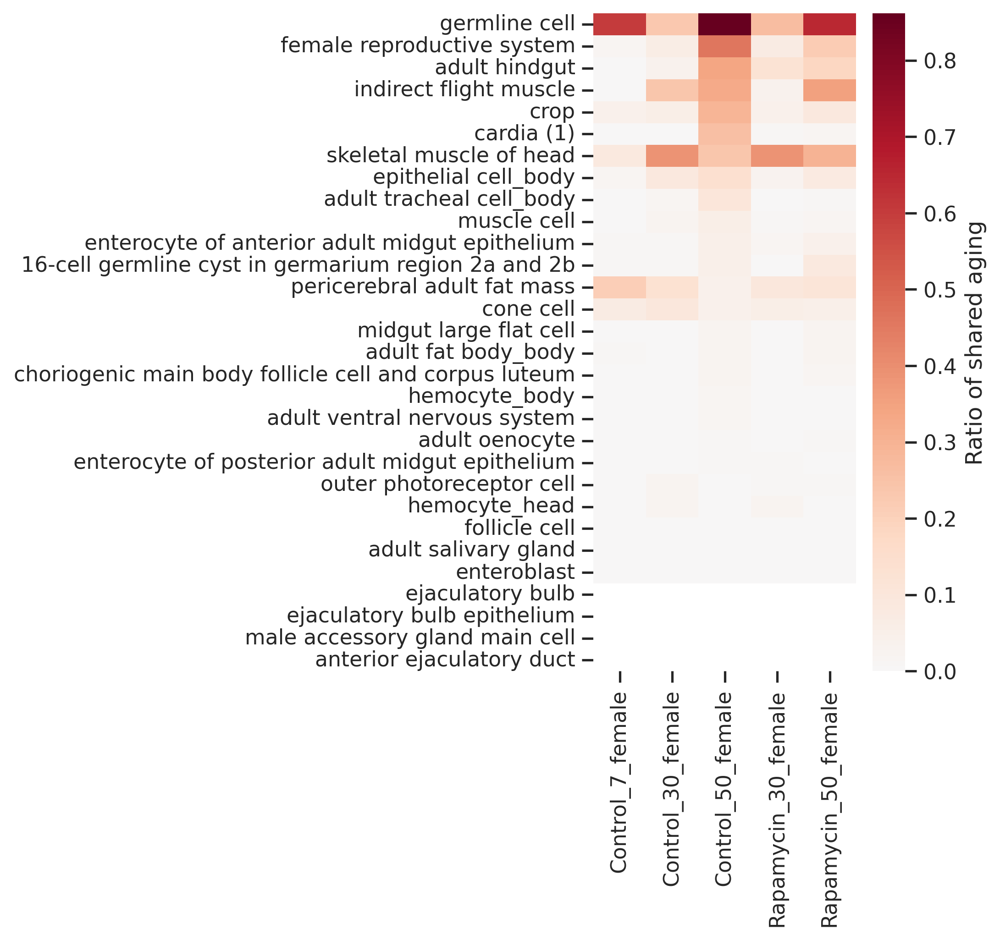

In [59]:
# Female
fig, ax = plt.subplots(figsize=(7, 7))
cmap = plt.cm.RdBu_r.copy() # Start with an existing colormap
cmap.set_bad('white') # Set the color for NaN values
sns.heatmap(data=ratio_Df_F.astype(float).iloc[:, [0,1,3,2,4]], cmap=cmap, center=0, yticklabels=True, ax=ax, vmax=ratioMax, # vmin=-vmax, 
            cbar_kws={'label': 'Ratio'}) # fmt='.1f', annot=True,  # 
# ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
ax.collections[0].colorbar.set_label('Ratio of shared aging')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__sharedAgingRatio__female__no70__sepTreatment.pdf', bbox_inches='tight')
plt.show()

In [36]:
ratio_Df_M = ratio_Df.loc[:, [col for col in ratio_Df.columns if '_male' in col]]
ratio_Df_M

,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,NaN,NaN,NaN,NaN,NaN
female reproductive system,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.000000,0.000000,0.015038,0.197802,0.047170
crop,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000000,0.008673,0.008594,0.052448,0.180915
cardia (1),0.007194,0.000000,0.000000,0.036145,0.040984
skeletal muscle of head,0.114130,0.358400,0.501441,0.488372,0.419580
epithelial cell_body,0.019856,0.047722,0.067568,0.110126,0.068210
adult tracheal cell_body,0.000000,0.000000,0.002646,0.007220,0.004484
16-cell germline cyst in germarium region 2a and 2b,NaN,NaN,NaN,NaN,NaN


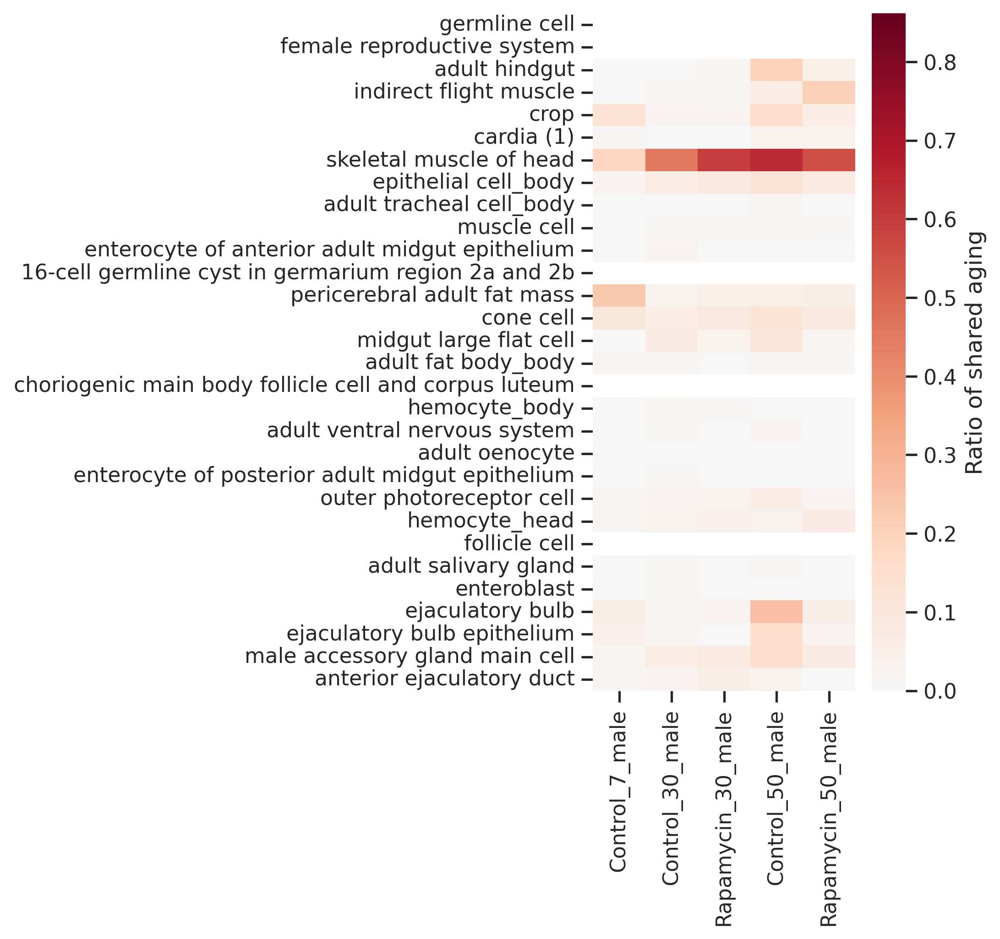

In [62]:
# Male
fig, ax = plt.subplots(figsize=(7, 7))
cmap = plt.cm.RdBu_r.copy() # Start with an existing colormap
cmap.set_bad('white') # Set the color for NaN values
sns.heatmap(data=ratio_Df_M.astype(float), cmap=cmap, center=0, yticklabels=True, ax=ax, vmax=ratioMax, # vmin=-vmax, vmax=vmax, 
            cbar_kws={'label': 'Ratio'}) # fmt='.1f', annot=True,  # 
# ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
ax.collections[0].colorbar.set_label('Ratio of shared aging')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__sharedAgingRatio__male__no70.pdf', bbox_inches='tight')
plt.show()

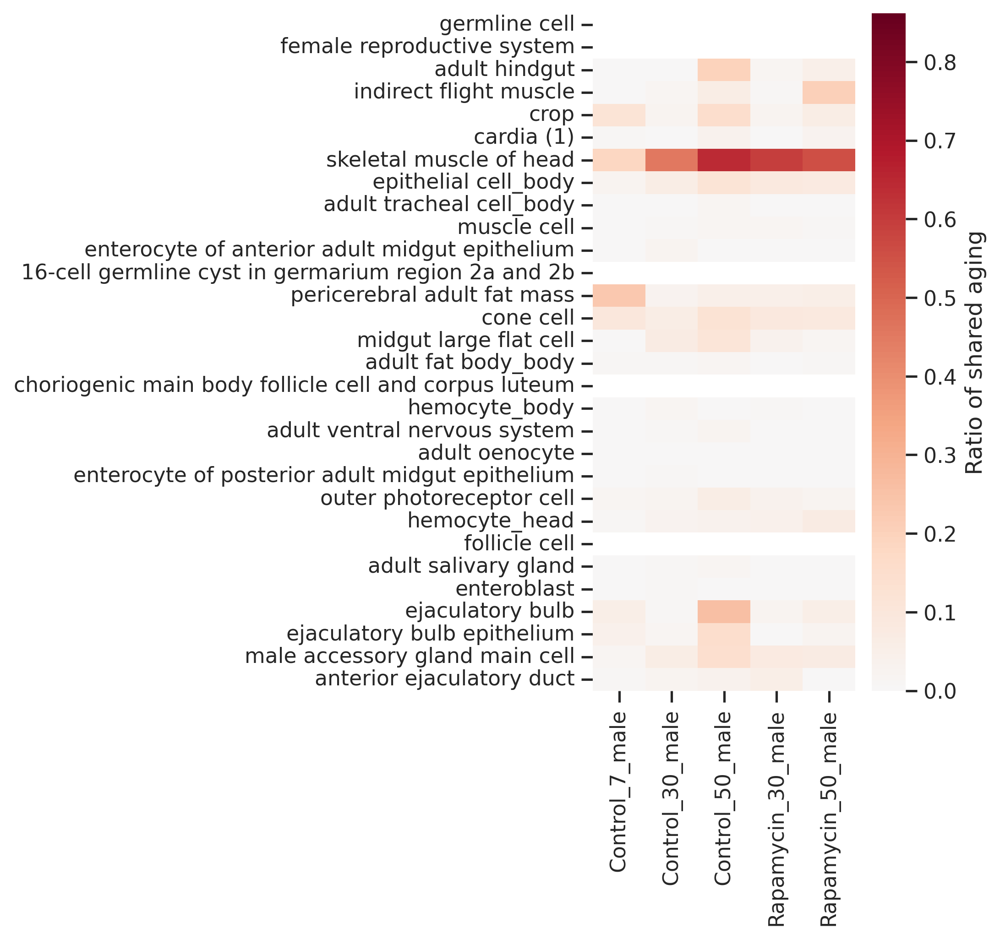

In [63]:
# Male
fig, ax = plt.subplots(figsize=(7, 7))
cmap = plt.cm.RdBu_r.copy() # Start with an existing colormap
cmap.set_bad('white') # Set the color for NaN values
sns.heatmap(data=ratio_Df_M.astype(float).iloc[:, [0,1,3,2,4]], cmap=cmap, center=0, yticklabels=True, ax=ax, vmax=ratioMax, # vmin=-vmax, vmax=vmax, 
            cbar_kws={'label': 'Ratio'}) # fmt='.1f', annot=True,  # 
# ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
ax.collections[0].colorbar.set_label('Ratio of shared aging')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__sharedAgingRatio__male__no70__sepTreatment.pdf', bbox_inches='tight')
plt.show()

In [37]:
# Female
ratioF_com_Df = ratio_Df.iloc[:,[1,3,2,4]]
ratioF_com_Df = ratioF_com_Df.replace(0, 0.0000001)
# ratioF_com_Df = pd.DataFrame(np.log2(ratioF_com_Df.iloc[:,2:].to_numpy()-ratioF_com_Df.iloc[:,:2].to_numpy()), 
#                              index=ratioF_com_Df.index, columns=['Rapa_vs_Control__30d', 'Rapa_vs_Control__50d'])
ratioF_com_Df = pd.DataFrame( ratioF_com_Df.iloc[:,2:].to_numpy()-ratioF_com_Df.iloc[:,:2].to_numpy(), 
                             index=ratioF_com_Df.index, columns=['Rapa_vs_Control__30d__F', 'Rapa_vs_Control__50d__F'])

ratioF_com_Df

,Rapa_vs_Control__30d__F,Rapa_vs_Control__50d__F
germline cell,0.027558,-0.219987
female reproductive system,-0.010153,-0.238142
adult hindgut,0.082736,-0.151515
crop,-0.022390,-0.212904
indirect flight muscle,-0.151352,0.007077
cardia (1),0.010753,-0.245610
skeletal muscle of head,0.013222,0.040753
epithelial cell_body,-0.050980,-0.052039
adult tracheal cell_body,-0.017453,-0.077175
16-cell germline cyst in germarium region 2a and 2b,-0.005618,0.029673


In [38]:
# Male
ratioM_com_Df = ratio_Df.iloc[:,[6,8,7,9]]
ratioM_com_Df = ratioM_com_Df.replace(0, 0.0000001)
# ratioM_com_Df = pd.DataFrame(np.log2(ratioM_com_Df.iloc[:,2:].to_numpy()-ratioM_com_Df.iloc[:,:2].to_numpy()), 
#                              index=ratioM_com_Df.index, columns=['Rapa_vs_Control__30d', 'Rapa_vs_Control__50d'])

ratioM_com_Df = pd.DataFrame( ratioM_com_Df.iloc[:,2:].to_numpy()-ratioM_com_Df.iloc[:,:2].to_numpy(), 
                             index=ratioM_com_Df.index, columns=['Rapa_vs_Control__30d__M', 'Rapa_vs_Control__50d__M'])


ratioM_com_Df

,Rapa_vs_Control__30d__M,Rapa_vs_Control__50d__M
germline cell,NaN,NaN
female reproductive system,NaN,NaN
adult hindgut,0.015037,-0.150632
crop,0.005795,-0.093395
indirect flight muscle,-0.000079,0.128467
cardia (1),0.000000,0.004839
skeletal muscle of head,0.143041,-0.068792
epithelial cell_body,0.019845,-0.041916
adult tracheal cell_body,0.002645,-0.002736
16-cell germline cyst in germarium region 2a and 2b,NaN,NaN


In [39]:
ratio_com_Df = pd.concat([ratioF_com_Df, ratioM_com_Df], axis=1)
ratio_com_Df = ratio_com_Df.iloc[:,[0,2,1,3]]
ratio_com_Df

,Rapa_vs_Control__30d__F,Rapa_vs_Control__30d__M,Rapa_vs_Control__50d__F,Rapa_vs_Control__50d__M
germline cell,0.027558,NaN,-0.219987,NaN
female reproductive system,-0.010153,NaN,-0.238142,NaN
adult hindgut,0.082736,0.015037,-0.151515,-0.150632
crop,-0.022390,0.005795,-0.212904,-0.093395
indirect flight muscle,-0.151352,-0.000079,0.007077,0.128467
cardia (1),0.010753,0.000000,-0.245610,0.004839
skeletal muscle of head,0.013222,0.143041,0.040753,-0.068792
epithelial cell_body,-0.050980,0.019845,-0.052039,-0.041916
adult tracheal cell_body,-0.017453,0.002645,-0.077175,-0.002736
16-cell germline cyst in germarium region 2a and 2b,-0.005618,NaN,0.029673,NaN


In [40]:
vmax = abs(ratio_com_Df).max().max()
vmax

0.24560987185571911

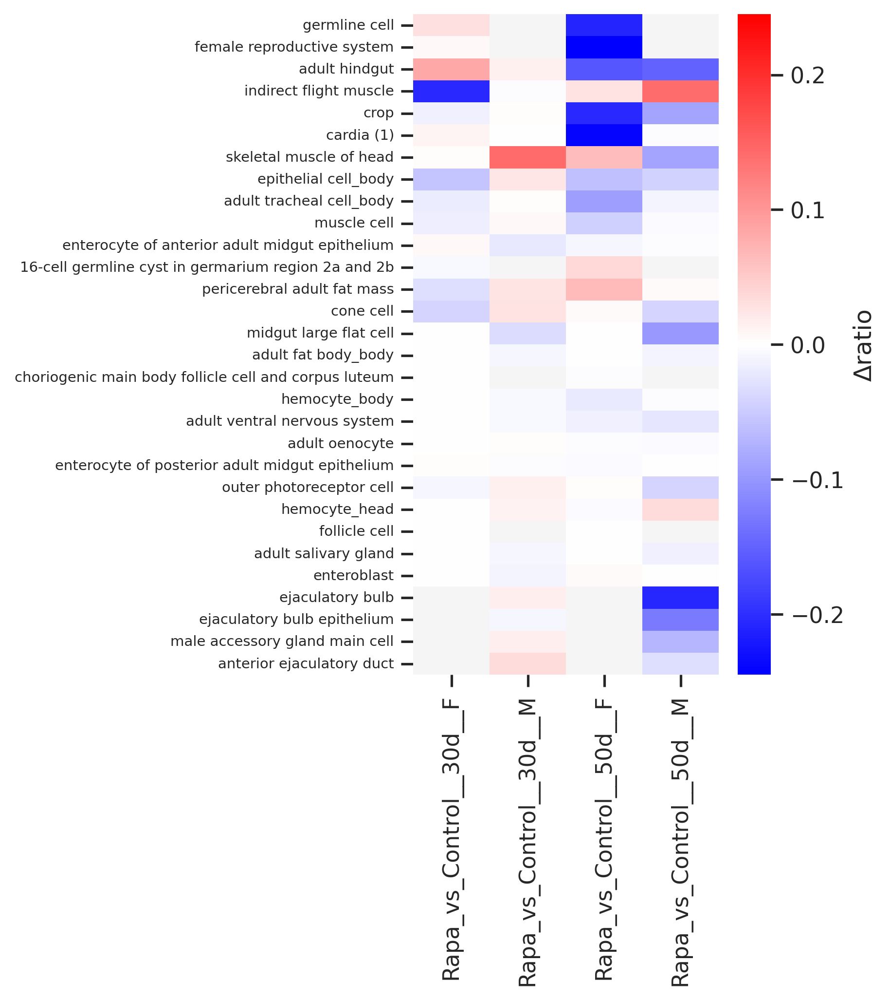

In [68]:
fig, ax = plt.subplots(figsize=(6, 7))
cmap = plt.cm.bwr.copy() # Start with an existing colormap
cmap.set_bad('whitesmoke') # Set the color for NaN values

sns.heatmap(data=ratio_com_Df.astype(float), cmap=cmap, center=0, yticklabels=True, ax=ax,  vmin=-vmax, vmax=vmax, 
            ) # fmt='.1f', annot=True,  # cbar_kws={'label': 'Value'}
ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=7)
ax.collections[0].colorbar.set_label('Δratio')

plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/heatmap__sharedAgingRatio__rapaToControl__no70.pdf', bbox_inches='tight')
plt.show()

In [41]:
ratio_com_Df_long =ratio_com_Df.copy()
ratio_com_Df_long.insert(0, 'annotation', ratio_com_Df_long.index.to_list())

In [42]:
ratio_com_Df_long = ratio_com_Df_long.melt(id_vars=['annotation'], var_name='comparison',value_name='Δratio')
ratio_com_Df_long

,annotation,comparison,Δratio
0,germline cell,Rapa_vs_Control__30d__F,0.027558
1,female reproductive system,Rapa_vs_Control__30d__F,-0.010153
2,adult hindgut,Rapa_vs_Control__30d__F,0.082736
3,crop,Rapa_vs_Control__30d__F,-0.022390
4,indirect flight muscle,Rapa_vs_Control__30d__F,-0.151352
...,...,...,...
115,enteroblast,Rapa_vs_Control__50d__M,0.000000
116,ejaculatory bulb,Rapa_vs_Control__50d__M,-0.206388
117,ejaculatory bulb epithelium,Rapa_vs_Control__50d__M,-0.117921
118,male accessory gland main cell,Rapa_vs_Control__50d__M,-0.067002


### Compare deltaCatRatio

In [43]:
ratio_com_Df = pd.read_csv(f'{figure5Folder}/ratio_com_Df.csv', index_col=0)

In [44]:
ratio_com_Df_long =ratio_com_Df.copy()
ratio_com_Df_long.insert(0, 'annotation', ratio_com_Df_long.index.to_list())

In [45]:
ratio_com_Df_long = ratio_com_Df_long.melt(id_vars=['annotation'], var_name='comparison',value_name='Δratio')
ratio_com_Df_long

,annotation,comparison,Δratio
0,germline cell,Rapa_vs_Control__30d__F,0.027558
1,female reproductive system,Rapa_vs_Control__30d__F,-0.010153
2,adult hindgut,Rapa_vs_Control__30d__F,0.082736
3,crop,Rapa_vs_Control__30d__F,-0.022390
4,indirect flight muscle,Rapa_vs_Control__30d__F,-0.151352
...,...,...,...
115,enteroblast,Rapa_vs_Control__50d__M,0.000000
116,ejaculatory bulb,Rapa_vs_Control__50d__M,-0.206388
117,ejaculatory bulb epithelium,Rapa_vs_Control__50d__M,-0.117921
118,male accessory gland main cell,Rapa_vs_Control__50d__M,-0.067002


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


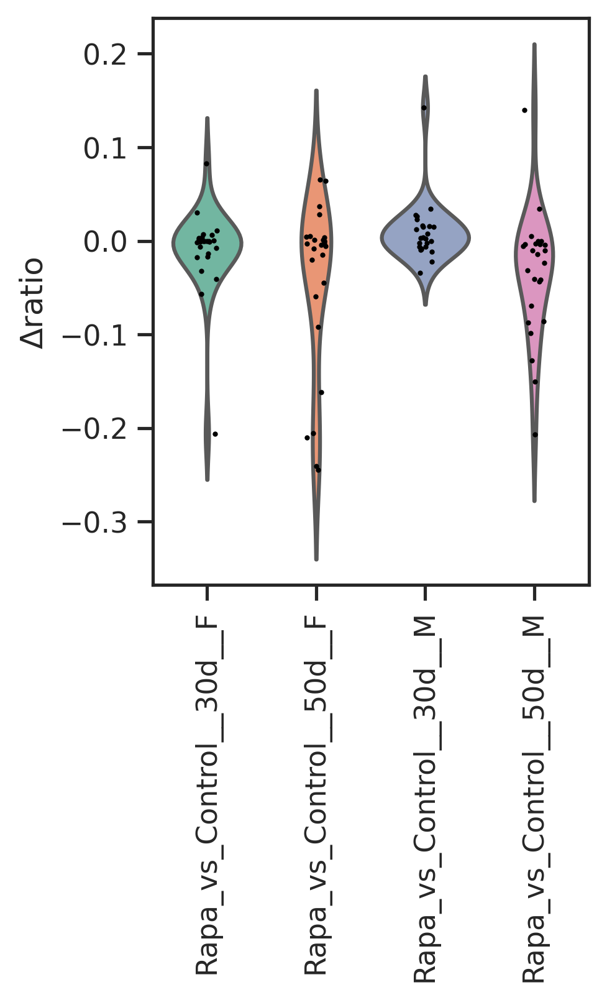

In [79]:
fig, ax = plt.subplots(figsize=(3, 4))
sns.stripplot(data=ratio_com_Df_long, x='comparison', y='Δratio', ax=ax, color='black', s=2,)# order=['30.0_female', '30.0_male', '50.0_female', '50.0_male'])
sns.violinplot(data=ratio_com_Df_long, x='comparison', y='Δratio', inner=None, ax=ax, palette='Set2')# order=['30.0_female', '30.0_male', '50.0_female', '50.0_male'], palette=cmap_sex)

ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set(xlabel='')
# ax.legend(bbox_to_anchor=(1.0, 1.0))
plt.savefig(f'{figure5PicFolder}/violin__ratio_com_Df_long_no70__deltaRatio.pdf', bbox_inches='tight')

In [46]:
ratio_com_Df

,Rapa_vs_Control__30d__F,Rapa_vs_Control__30d__M,Rapa_vs_Control__50d__F,Rapa_vs_Control__50d__M
germline cell,0.027558,NaN,-0.219987,NaN
female reproductive system,-0.010153,NaN,-0.238142,NaN
adult hindgut,0.082736,0.015038,-0.151515,-0.150632
crop,-0.022390,0.005795,-0.212904,-0.093395
indirect flight muscle,-0.151352,-0.000079,0.007077,0.128467
cardia (1),0.010753,0.000000,-0.245610,0.004839
skeletal muscle of head,0.013222,0.143041,0.040753,-0.068792
epithelial cell_body,-0.050980,0.019845,-0.052039,-0.041916
adult tracheal cell_body,-0.017453,0.002646,-0.077175,-0.002736
16-cell germline cyst in germarium region 2a and 2b,-0.005618,NaN,0.029673,NaN


In [47]:
cmap_sex = ['#F5AF4DFF', '#5495CFFF']

In [48]:
ratio_com_Df_long

,annotation,comparison,Δratio
0,germline cell,Rapa_vs_Control__30d__F,0.027558
1,female reproductive system,Rapa_vs_Control__30d__F,-0.010153
2,adult hindgut,Rapa_vs_Control__30d__F,0.082736
3,crop,Rapa_vs_Control__30d__F,-0.022390
4,indirect flight muscle,Rapa_vs_Control__30d__F,-0.151352
...,...,...,...
115,enteroblast,Rapa_vs_Control__50d__M,0.000000
116,ejaculatory bulb,Rapa_vs_Control__50d__M,-0.206388
117,ejaculatory bulb epithelium,Rapa_vs_Control__50d__M,-0.117921
118,male accessory gland main cell,Rapa_vs_Control__50d__M,-0.067002


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


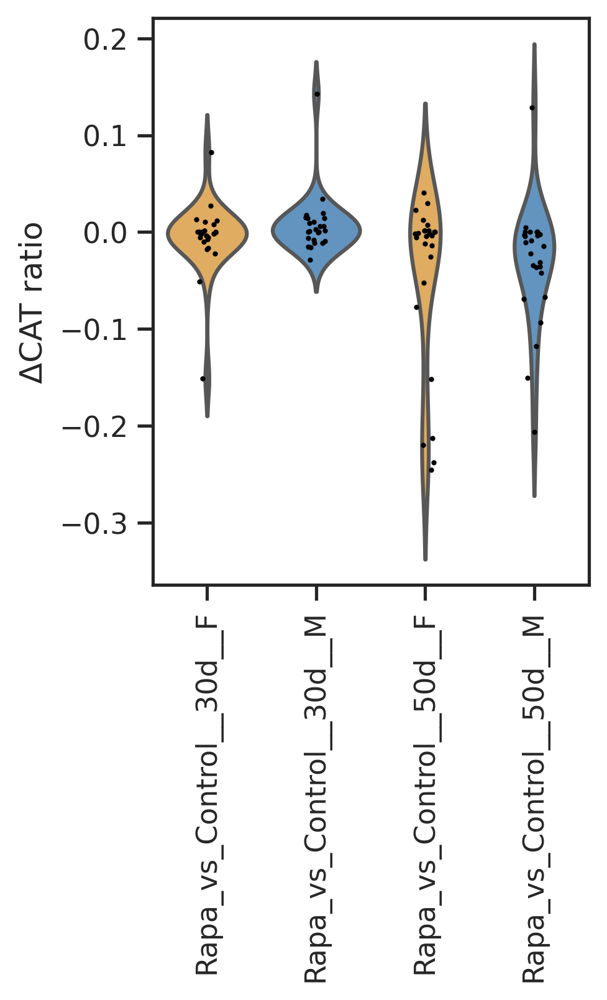

In [52]:
fig, ax = plt.subplots(figsize=(3, 4))
sns.stripplot(data=ratio_com_Df_long, x='comparison', y='Δratio', ax=ax, color='black', s=2,)# order=['30.0_female', '30.0_male', '50.0_female', '50.0_male'])
sns.violinplot(data=ratio_com_Df_long, x='comparison', y='Δratio', inner=None, ax=ax, palette=cmap_sex)# order=['30.0_female', '30.0_male', '50.0_female', '50.0_male'], palette=cmap_sex) # palette='Set2', 

ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set(xlabel='', ylabel='ΔCAT ratio')

plt.savefig(f'{figure5PicFolder}/violin__ratio_com_Df_long__deltaCat__sexCom.pdf', bbox_inches='tight')

In [53]:
from scipy import stats
from scipy.stats import mannwhitneyu

In [54]:
ratio_com_Df.columns

Index(['Rapa_vs_Control__30d__F', 'Rapa_vs_Control__30d__M',
       'Rapa_vs_Control__50d__F', 'Rapa_vs_Control__50d__M'],
      dtype='object')

In [55]:
geroScore_30F_L = ratio_com_Df[ (~ratio_com_Df.Rapa_vs_Control__30d__F.isna()) ]['Rapa_vs_Control__30d__F'].to_list()
geroScore_30M_L = ratio_com_Df[ (~ratio_com_Df.Rapa_vs_Control__30d__M.isna()) ]['Rapa_vs_Control__30d__M'].to_list()

geroScore_50F_L = ratio_com_Df[ (~ratio_com_Df.Rapa_vs_Control__50d__F.isna()) ]['Rapa_vs_Control__50d__F'].to_list()
geroScore_50M_L = ratio_com_Df[ (~ratio_com_Df.Rapa_vs_Control__50d__M.isna()) ]['Rapa_vs_Control__50d__M'].to_list()

print(len(geroScore_30F_L), len(geroScore_30M_L), len(geroScore_50F_L), len(geroScore_50M_L))

26 25 26 25


In [56]:
# 30 day sex differences
stat, p_value = mannwhitneyu(geroScore_30F_L, geroScore_30M_L, alternative='less')
stat, p_value

(252.0, 0.0857899935167099)

In [57]:
# 50 day sex differences
stat, p_value = mannwhitneyu(geroScore_50F_L, geroScore_50M_L, alternative='less')
stat, p_value

(382.0, 0.8607995823147139)

In [58]:
# 30 day sex differences
stat, p_value = mannwhitneyu(geroScore_30F_L, geroScore_30M_L, )
stat, p_value

(252.0, 0.1715799870334198)

In [59]:
# 50 day sex differences
stat, p_value = mannwhitneyu(geroScore_50F_L, geroScore_50M_L, )
stat, p_value

(382.0, 0.28684517385856545)

In [60]:
ratio_Df = pd.read_csv(f'{figure5Folder}/ratio_Df.csv', index_col=0)
ratio_Df

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089,NaN,NaN,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.065934,0.460870,0.222727,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.000000,0.039216,0.121951,0.333333,0.181818,0.000000,0.000000,0.015038,0.197802,0.047170
crop,0.041534,0.059028,0.036638,0.307042,0.094139,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000479,0.170732,0.019380,0.277520,0.284598,0.000000,0.008673,0.008594,0.052448,0.180915
cardia (1),0.000000,0.000000,0.010753,0.255814,0.010204,0.007194,0.000000,0.000000,0.036145,0.040984
skeletal muscle of head,0.047525,0.265385,0.278607,0.186620,0.227373,0.114130,0.358400,0.501441,0.488372,0.419580
epithelial cell_body,0.011250,0.076923,0.025943,0.120290,0.068251,0.019856,0.047722,0.067568,0.110126,0.068210
adult tracheal cell_body,0.001344,0.020134,0.002681,0.086420,0.009245,0.000000,0.000000,0.002646,0.007220,0.004484
16-cell germline cyst in germarium region 2a and 2b,0.005618,0.013986,0.008368,0.049180,0.078853,NaN,NaN,NaN,NaN,NaN


In [61]:
ratio_Df_ctl = ratio_Df.iloc[:, [0,1,3,5,6,8]]
ratio_Df_ctl.head()

,Control_7_female,Control_30_female,Control_50_female,Control_7_male,Control_30_male,Control_50_male
germline cell,0.538012,0.220132,0.814076,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.460870,NaN,NaN,NaN
adult hindgut,0.000000,0.039216,0.333333,0.000000,0.000000,0.197802
crop,0.041534,0.059028,0.307042,0.121019,0.017308,0.156627
indirect flight muscle,0.000479,0.170732,0.277520,0.000000,0.008673,0.052448


In [62]:
ratio_Df_ctl_long =ratio_Df_ctl.copy()
ratio_Df_ctl_long.insert(0, 'annotation', ratio_Df_ctl_long.index.to_list())

In [63]:
ratio_Df_ctl_long = ratio_Df_ctl_long.melt(id_vars=['annotation'], var_name='comparison',value_name='catRatio')
ratio_Df_ctl_long

,annotation,comparison,catRatio
0,germline cell,Control_7_female,0.538012
1,female reproductive system,Control_7_female,0.017699
2,adult hindgut,Control_7_female,0.000000
3,crop,Control_7_female,0.041534
4,indirect flight muscle,Control_7_female,0.000479
...,...,...,...
175,enteroblast,Control_50_male,0.000000
176,ejaculatory bulb,Control_50_male,0.259635
177,ejaculatory bulb epithelium,Control_50_male,0.141176
178,male accessory gland main cell,Control_50_male,0.137192


In [68]:
cmap_sex = ['#F5AF4DFF']*3 + ['#5495CFFF']*3

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


[Text(0.5, 0, ''), Text(0, 0.5, 'CAT ratio')]

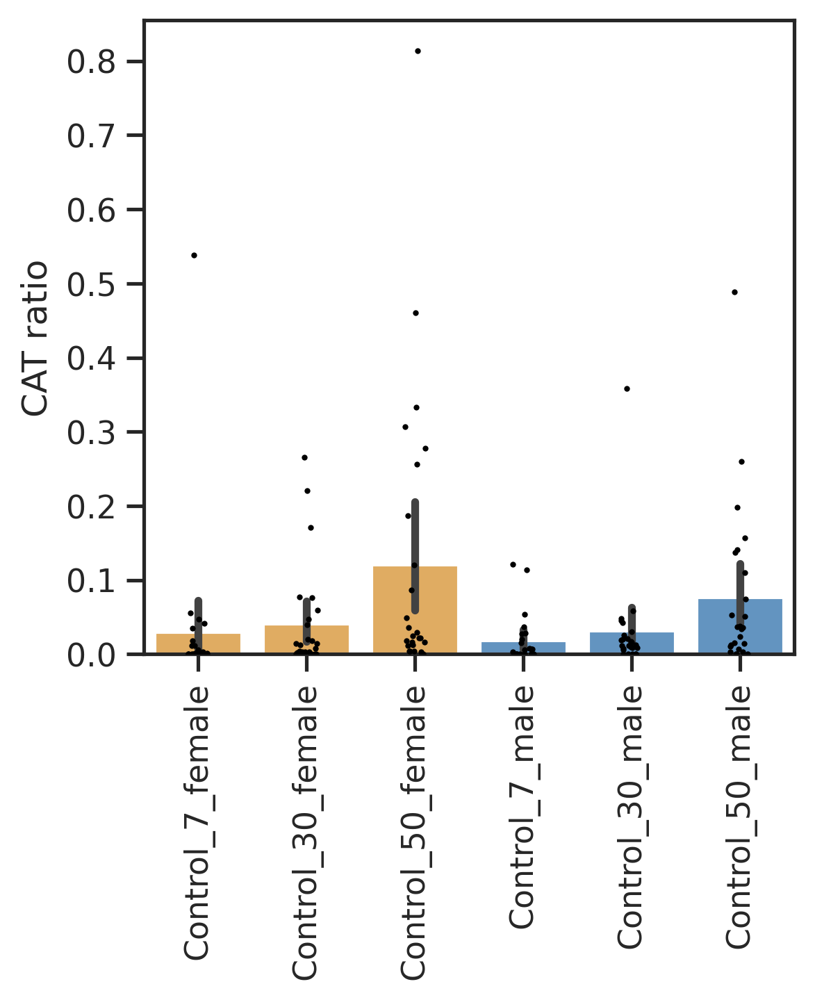

In [78]:
fig, ax = plt.subplots(figsize=(4, 4))
sns.stripplot(data=ratio_Df_ctl_long, x='comparison', y='catRatio', ax=ax, color='black', s=2,)# order=['30.0_female', '30.0_male', '50.0_female', '50.0_male'])
sns.barplot(data=ratio_Df_ctl_long, x='comparison', y='catRatio', ax=ax, palette=cmap_sex, ) # errorbar=None
# sns.violinplot(data=ratio_Df_ctl_long, x='comparison', y='catRatio', inner=None, ax=ax, palette=cmap_sex)# order=['30.0_female', '30.0_male', '50.0_female', '50.0_male'], palette=cmap_sex) # palette='Set2', 

ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set(xlabel='', ylabel='CAT ratio')

In [79]:
ratio_Df_long =ratio_Df.copy()
ratio_Df_long.insert(0, 'annotation', ratio_Df_long.index.to_list())

In [80]:
ratio_Df_long = ratio_Df_long.melt(id_vars=['annotation'], var_name='comparison',value_name='catRatio')
ratio_Df_long

,annotation,comparison,catRatio
0,germline cell,Control_7_female,0.538012
1,female reproductive system,Control_7_female,0.017699
2,adult hindgut,Control_7_female,0.000000
3,crop,Control_7_female,0.041534
4,indirect flight muscle,Control_7_female,0.000479
...,...,...,...
295,enteroblast,Rapamycin_50_male,0.000000
296,ejaculatory bulb,Rapamycin_50_male,0.053247
297,ejaculatory bulb epithelium,Rapamycin_50_male,0.023256
298,male accessory gland main cell,Rapamycin_50_male,0.070190


In [68]:
cmap_sex = ['#F5AF4DFF']*3 + ['#5495CFFF']*3

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


[Text(0.5, 0, ''), Text(0, 0.5, 'CAT ratio')]

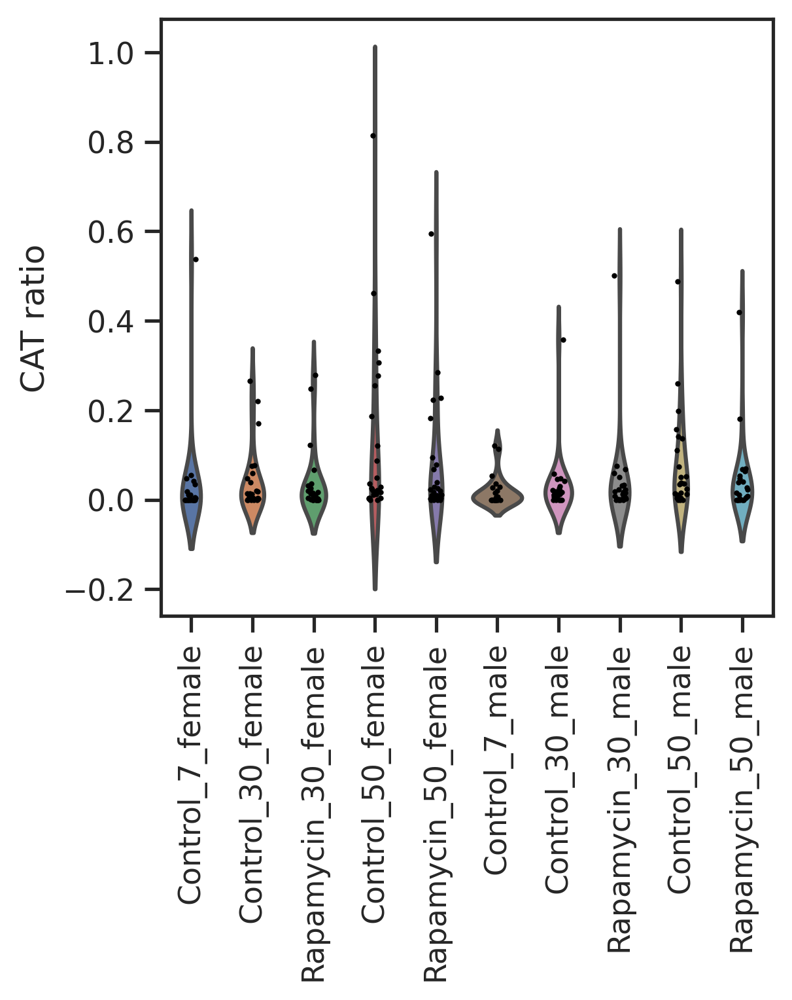

In [84]:
fig, ax = plt.subplots(figsize=(4, 4))
sns.stripplot(data=ratio_Df_long, x='comparison', y='catRatio', ax=ax, color='black', s=2,)# order=['30.0_female', '30.0_male', '50.0_female', '50.0_male'])
# sns.barplot(data=ratio_Df_long, x='comparison', y='catRatio', ax=ax,)# palette=cmap_sex, ) # errorbar=None
sns.violinplot(data=ratio_Df_long, x='comparison', y='catRatio', inner=None, ax=ax,) # palette=cmap_sex)# order=['30.0_female', '30.0_male', '50.0_female', '50.0_male'], palette=cmap_sex) # palette='Set2', 

ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set(xlabel='', ylabel='CAT ratio')

In [85]:
from scipy import stats
from scipy.stats import mannwhitneyu

In [87]:
ratio_Df.head()

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089,NaN,NaN,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.065934,0.460870,0.222727,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.000000,0.039216,0.121951,0.333333,0.181818,0.000000,0.000000,0.015038,0.197802,0.047170
crop,0.041534,0.059028,0.036638,0.307042,0.094139,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000479,0.170732,0.019380,0.277520,0.284598,0.000000,0.008673,0.008594,0.052448,0.180915


In [88]:
geroScore_30F_C_L = ratio_Df[ (~ratio_Df.Control_30_female.isna()) ]['Control_30_female'].to_list()
geroScore_30F_R_L = ratio_Df[ (~ratio_Df.Rapamycin_30_female.isna()) ]['Rapamycin_30_female'].to_list()

geroScore_30M_C_L = ratio_Df[ (~ratio_Df.Control_30_male.isna()) ]['Control_30_male'].to_list()
geroScore_30M_R_L = ratio_Df[ (~ratio_Df.Rapamycin_30_male.isna()) ]['Rapamycin_30_male'].to_list()

geroScore_50F_C_L = ratio_Df[ (~ratio_Df.Control_50_female.isna()) ]['Control_50_female'].to_list()
geroScore_50F_R_L = ratio_Df[ (~ratio_Df.Rapamycin_50_female.isna()) ]['Rapamycin_50_female'].to_list()

geroScore_50M_C_L = ratio_Df[ (~ratio_Df.Control_50_male.isna()) ]['Control_50_male'].to_list()
geroScore_50M_R_L = ratio_Df[ (~ratio_Df.Rapamycin_50_male.isna()) ]['Rapamycin_50_male'].to_list()


print(len(geroScore_30F_C_L), len(geroScore_30F_R_L), len(geroScore_30M_C_L), len(geroScore_30M_R_L), len(geroScore_50F_C_L), len(geroScore_50F_R_L), len(geroScore_50M_C_L), len(geroScore_50M_R_L))

26 26 25 25 26 26 25 25


In [91]:
# female 30 day sex differences
stat, p_value = mannwhitneyu(geroScore_30F_R_L, geroScore_30F_C_L, alternative='less')
stat, p_value

(318.5, 0.3632200573716786)

In [92]:
# male 30 day sex differences
stat, p_value = mannwhitneyu(geroScore_30M_R_L, geroScore_30M_C_L, alternative='less')
stat, p_value

(303.0, 0.4304883666005222)

In [93]:
# female 50 day sex differences
stat, p_value = mannwhitneyu(geroScore_50F_R_L, geroScore_50F_C_L, alternative='less')
stat, p_value

(280.0, 0.1461411747757373)

In [94]:
# male 50 day sex differences
stat, p_value = mannwhitneyu(geroScore_50M_R_L, geroScore_50M_C_L, alternative='less')
stat, p_value

(232.0, 0.059768533376200535)

# Glycolysis score in CAT nuclei

## Load files

In [34]:
adata_body = sc.read(f'{figure5Folder}/adata_body__CAT_score__CAT_group.h5ad')
adata_head = sc.read(f'{figure5Folder}/adata_head__CAT_score__CAT_group.h5ad')

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


In [35]:
# merge roX1+ and roX1-
adata_body.obs.rapamycin_annotation = pd.Categorical([ 'male accessory gland main cell' if 'roX1' in annot else annot for annot in adata_body.obs.rapamycin_annotation ])

In [36]:
adata_body.obs['sex__CAT_group'] = pd.Categorical(adata_body.obs.sex.astype(str) + '_' + adata_body.obs.CAT_group.astype(str))
adata_head.obs['sex__CAT_group'] = pd.Categorical(adata_head.obs.sex.astype(str) + '_' + adata_head.obs.CAT_group.astype(str))

adata_head.obs['annot_sex__CAT_group'] = pd.Categorical(adata_head.obs.rapamycin_annotation.astype(str) + '__' + adata_head.obs.sex.astype(str) + '__' + adata_head.obs.CAT_group.astype(str))
adata_head.obs['broad_sex__CAT_group'] = pd.Categorical(adata_head.obs.rapamycin_annotation_broad.astype(str) + '__' + adata_head.obs.sex.astype(str) + '__' + adata_head.obs.CAT_group.astype(str))

adata_body.obs['annot_sex__CAT_group'] = pd.Categorical(adata_body.obs.rapamycin_annotation.astype(str) + '__' + adata_body.obs.sex.astype(str) + '__' + adata_body.obs.CAT_group.astype(str))
adata_body.obs['broad_sex__CAT_group'] = pd.Categorical(adata_body.obs.rapamycin_annotation_broad.astype(str) + '__' + adata_body.obs.sex.astype(str) + '__' + adata_body.obs.CAT_group.astype(str))


adata_body.obs.sex__CAT_group.cat.categories

Index(['female_CAT', 'female_others', 'male_CAT', 'male_others'], dtype='object')

In [37]:
adata_headBody = adata_head.concatenate(adata_body, join='outer')
adata_headBody.obs_names = [obs[:-2] for obs in adata_headBody.obs_names]

<ipython-input-37-3018bdd93575>:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata_headBody = adata_head.concatenate(adata_body, join='outer')


## Calculate glycolysis score in different CAT groups

In [38]:
glycolysis_L = ['Eno', 'Gapdh1', 'CG32444', 'Pgm1', 'Pgi', 'Aldh', 'Pgk', 'Hex-A', 'Tpi', 'Ald1', 'AcCoAS', 'PyK', 'Pglym78', 'Gapdh2']
lipid_L = ['ACC', 'FASN1', 'FASN3', 'FASN2', 'apolpp'] # Find other lipid genes?

In [39]:
sc.tl.score_genes(adata_headBody, glycolysis_L, score_name='GlycolysisScore',)
sc.tl.score_genes(adata_headBody, lipid_L, score_name='LipidSynScore',)

computing score 'GlycolysisScore'
    finished: added
    'GlycolysisScore', score of gene set (adata.obs).
    299 total control genes are used. (0:00:04)
computing score 'LipidSynScore'
    finished: added
    'LipidSynScore', score of gene set (adata.obs).
    150 total control genes are used. (0:00:03)


In [40]:
# sc.tl.score_genes(adata_body, glycolysis_L, score_name='GlycolysisScore',)
# sc.tl.score_genes(adata_body, lipid_L, score_name='LipidSynScore',)

# sc.tl.score_genes(adata_head, glycolysis_L, score_name='GlycolysisScore',)
# sc.tl.score_genes(adata_head, lipid_L, score_name='LipidSynScore',)

In [41]:
degN_mtx  = pd.read_csv(f'/data/tcl/Project/HongjieLab/rapamycin/Analysis/Figure/Figure2/degSummary/degN_mtx_treatAgeSex_compareToControl_cellN700.csv', index_col=0)
degN_mtx.sort_values(by='totalDegN', ascending=False, inplace=True)
degN_mtx_100 = degN_mtx[degN_mtx.totalDegN > 100]
degN_mtx_100

,Rapamycin_30_female vs. Control_30_female,Rapamycin_50_female vs. Control_50_female,Rapamycin_70_female vs. Control_70_female,Rapamycin_30_male vs. Control_30_male,Rapamycin_50_male vs. Control_50_male,Rapamycin_70_male vs. Control_70_male,totalDegN
adult fat body_body,727,1185,891,460,1243,1169,5675
enterocyte of anterior adult midgut epithelium,974,629,98,20,1063,455,3239
adult oenocyte,473,441,323,215,1013,632,3097
pericerebral adult fat mass,464,454,641,416,200,781,2956
follicle cell,577,1065,555,0,0,0,2197
male accessory gland main cell_roX1+,0,0,0,317,806,543,1666
adult ventral nervous system,895,307,15,52,315,1,1585
indirect flight muscle,352,280,0,350,147,7,1136
choriogenic main body follicle cell and corpus luteum,440,441,172,0,0,0,1053
ejaculatory bulb,0,0,0,216,539,109,864


In [42]:
degN_mtx_100.index.to_list().index('male accessory gland main cell_roX1+')

5

In [43]:
degN_mtx_100.rename(index = {'male accessory gland main cell_roX1+': 'male accessory gland main cell'}, inplace = True)
degNindex_L = degN_mtx_100.index.to_list()
degNindex_L[5] = 'male accessory gland main cell'
degN_mtx_100

<ipython-input-43-8271c8ca9b9e>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  degN_mtx_100.rename(index = {'male accessory gland main cell_roX1+': 'male accessory gland main cell'}, inplace = True)


,Rapamycin_30_female vs. Control_30_female,Rapamycin_50_female vs. Control_50_female,Rapamycin_70_female vs. Control_70_female,Rapamycin_30_male vs. Control_30_male,Rapamycin_50_male vs. Control_50_male,Rapamycin_70_male vs. Control_70_male,totalDegN
adult fat body_body,727,1185,891,460,1243,1169,5675
enterocyte of anterior adult midgut epithelium,974,629,98,20,1063,455,3239
adult oenocyte,473,441,323,215,1013,632,3097
pericerebral adult fat mass,464,454,641,416,200,781,2956
follicle cell,577,1065,555,0,0,0,2197
male accessory gland main cell,0,0,0,317,806,543,1666
adult ventral nervous system,895,307,15,52,315,1,1585
indirect flight muscle,352,280,0,350,147,7,1136
choriogenic main body follicle cell and corpus luteum,440,441,172,0,0,0,1053
ejaculatory bulb,0,0,0,216,539,109,864


In [44]:
ratio_Df = pd.read_csv(f'{figure5Folder}/ratio_Df.csv', index_col=0)
ratio_Df

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089,NaN,NaN,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.065934,0.460870,0.222727,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.000000,0.039216,0.121951,0.333333,0.181818,0.000000,0.000000,0.015038,0.197802,0.047170
crop,0.041534,0.059028,0.036638,0.307042,0.094139,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000479,0.170732,0.019380,0.277520,0.284598,0.000000,0.008673,0.008594,0.052448,0.180915
cardia (1),0.000000,0.000000,0.010753,0.255814,0.010204,0.007194,0.000000,0.000000,0.036145,0.040984
skeletal muscle of head,0.047525,0.265385,0.278607,0.186620,0.227373,0.114130,0.358400,0.501441,0.488372,0.419580
epithelial cell_body,0.011250,0.076923,0.025943,0.120290,0.068251,0.019856,0.047722,0.067568,0.110126,0.068210
adult tracheal cell_body,0.001344,0.020134,0.002681,0.086420,0.009245,0.000000,0.000000,0.002646,0.007220,0.004484
16-cell germline cyst in germarium region 2a and 2b,0.005618,0.013986,0.008368,0.049180,0.078853,NaN,NaN,NaN,NaN,NaN


## Plot glycolysis score

In [45]:
adata_select = adata_headBody[adata_headBody.obs.rapamycin_annotation.isin(degN_mtx_100.index.to_list())]
adata_select.obs.rapamycin_annotation = pd.Categorical(adata_select.obs.rapamycin_annotation , categories=ratio_Df.index.to_list())
adata_select.obs['annot_sex__CAT_group'] = pd.Categorical(adata_select.obs.rapamycin_annotation.astype(str) + '__' + adata_select.obs.sex.astype(str) + '__' + adata_select.obs.CAT_group.astype(str))
adata_select.obs['broad_sex__CAT_group'] = pd.Categorical(adata_select.obs.rapamycin_annotation_broad.astype(str) + '__' + adata_select.obs.sex.astype(str) + '__' + adata_select.obs.CAT_group.astype(str))
adata_select

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/pandas/core/generic.py:6326: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self[name] = value


AnnData object with n_obs × n_vars = 271841 × 15919
    obs: 'latent_RT_efficiency', 'latent_cell_probability', 'latent_scale', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'dataset', 'age', 'sex', 'tissue', 'condition', 'leiden', 'linearR_annotation', 'condAge', 'condSex', 'ageSex', 'condAgeSex', 'condAgeSexTissue', 'leiden_1.0', 'leiden_2.0', 'leiden_3.0', 'leiden_4.0', 'leiden_5.0', 'leiden_6.0', 'leiden_7.0', 'leiden_8.0', 'leiden_9.0', 'leiden_10.0', 'leiden_1.5', 'treatment', 'treatAge', 'treatAgeSex', 'treatSex', 'rapamycin_annotation', 'rapamycin_annotation_broad', 'rapamycin_annotation_subcluster', 'rapamycin_annotation_group', 'sharedAgingAve_up', 'sharedAgingAve_down', 'sharedAgingAve_upMinusDown', 'CAT_score', 'CAT_group', 'sex__CAT_group', 'annot_sex__CAT_group', 'broad_sex__CAT_group', 'batch', 'GlycolysisScore', 'LipidSynScore'
    var: 'gene_ids', 'highly_variable-0', 'means-0', 'dispersions-0', 'dispersions_norm-0', 'highly_variab

In [46]:
adata_headBody.obs['broad_sex__CAT_group'] = pd.Categorical(adata_headBody.obs.rapamycin_annotation_broad.astype(str) + '__' + adata_select.obs.sex.astype(str) + '__' + adata_select.obs.CAT_group.astype(str))

In [47]:
sns.color_palette("deep")

[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725),
 (0.8666666666666667, 0.5176470588235295, 0.3215686274509804),
 (0.3333333333333333, 0.6588235294117647, 0.40784313725490196),
 (0.7686274509803922, 0.3058823529411765, 0.3215686274509804),
 (0.5058823529411764, 0.4470588235294118, 0.7019607843137254),
 (0.5764705882352941, 0.47058823529411764, 0.3764705882352941),
 (0.8549019607843137, 0.5450980392156862, 0.7647058823529411),
 (0.5490196078431373, 0.5490196078431373, 0.5490196078431373),
 (0.8, 0.7254901960784313, 0.4549019607843137),
 (0.39215686274509803, 0.7098039215686275, 0.803921568627451)]

In [48]:
cmap = list(sns.color_palette("tab10"))[:2]
# cmap = list(sns.color_palette("Set2"))[1:3]

In [49]:
geneDict_D = {'Glycolysis': glycolysis_L, 'Lipid synthesis': lipid_L, 'mTORC1 inhibition': ['Fkbp12']}

In [50]:
geneDict_D.values()

dict_values([['Eno', 'Gapdh1', 'CG32444', 'Pgm1', 'Pgi', 'Aldh', 'Pgk', 'Hex-A', 'Tpi', 'Ald1', 'AcCoAS', 'PyK', 'Pglym78', 'Gapdh2'], ['ACC', 'FASN1', 'FASN3', 'FASN2', 'apolpp'], ['Fkbp12']])

In [51]:
allGenes = [gene for geneList in list(geneDict_D.values()) for gene in geneList  ]
allGenes

['Eno',
 'Gapdh1',
 'CG32444',
 'Pgm1',
 'Pgi',
 'Aldh',
 'Pgk',
 'Hex-A',
 'Tpi',
 'Ald1',
 'AcCoAS',
 'PyK',
 'Pglym78',
 'Gapdh2',
 'ACC',
 'FASN1',
 'FASN3',
 'FASN2',
 'apolpp',
 'Fkbp12']

In [52]:
selectGenes_L = ['Eno', 'Gapdh1', 'Ald1', 'ACC', 'FASN1', 'Fkbp12']

In [53]:
geneDictSelect_D = {'Glycolysis': ['Eno', 'Gapdh1', 'Ald1'], 'Lipid synthesis': ['ACC', 'FASN1'], 'mTORC1 inhibition': ['Fkbp12']}

## Calculate aveExp & percentage

In [54]:
clusters = adata_select.obs['annot_sex__CAT_group'].cat.categories
obs = adata_select[:,selectGenes_L].X.toarray()
obs = pd.DataFrame(obs,columns=selectGenes_L,index=adata_select.obs['annot_sex__CAT_group'])
average_obs = obs.groupby(level=0).mean()
obs_bool = obs.astype(bool)
fraction_obs = obs_bool.groupby(level=0).sum()/obs_bool.groupby(level=0).count()

# # output
# average_obs.T.to_csv("average.csv")
# fraction_obs.T.to_csv("fraction.csv")

<ipython-input-54-563d9fa95eb9>:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  average_obs = obs.groupby(level=0).mean()
<ipython-input-54-563d9fa95eb9>:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fraction_obs = obs_bool.groupby(level=0).sum()/obs_bool.groupby(level=0).count()


In [55]:
average_obs

,Eno,Gapdh1,Ald1,ACC,FASN1,Fkbp12
annot_sex__CAT_group,,,,,,
16-cell germline cyst in germarium region 2a and 2b__female__CAT,1.283458,0.964407,1.078619,0.723924,0.210565,1.611124
16-cell germline cyst in germarium region 2a and 2b__female__others,0.396359,0.334020,0.211424,0.310210,0.061979,0.844543
adult fat body_body__female__CAT,1.800861,1.350947,2.364873,1.560997,2.120090,1.457664
adult fat body_body__female__others,1.239978,0.576492,2.158645,2.173218,2.554369,0.588691
adult fat body_body__male__CAT,1.548367,1.245842,2.403910,2.022618,2.678785,0.819528
...,...,...,...,...,...,...
pericerebral adult fat mass__male__others,1.319701,0.672174,2.216329,2.253203,2.303775,0.464322
skeletal muscle of head__female__CAT,1.771123,1.491040,2.917863,0.347606,0.166676,0.447037
skeletal muscle of head__female__others,1.142018,0.928780,2.545608,0.072957,0.009798,0.095719


In [56]:
obs

,Eno,Gapdh1,Ald1,ACC,FASN1,Fkbp12
annot_sex__CAT_group,,,,,,
pericerebral adult fat mass__female__others,0.000000,0.000000,2.514114,2.514114,2.514114,0.000000
pericerebral adult fat mass__female__others,2.185667,0.000000,1.900849,2.425900,2.331236,1.571196
pericerebral adult fat mass__female__others,1.914634,1.583845,2.346149,2.477933,2.200237,1.914634
outer photoreceptor cell__female__others,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
pericerebral adult fat mass__female__others,2.338346,1.907340,2.338346,2.618259,2.470009,0.000000
...,...,...,...,...,...,...
hemocyte_body__male__others,0.000000,0.000000,3.337875,0.000000,0.000000,0.000000
epithelial cell_body__male__others,0.000000,0.000000,3.289800,0.000000,0.000000,0.000000
epithelial cell_body__male__others,3.560447,0.000000,3.560447,0.000000,0.000000,0.000000


In [57]:
fraction_obs

,Eno,Gapdh1,Ald1,ACC,FASN1,Fkbp12
annot_sex__CAT_group,,,,,,
16-cell germline cyst in germarium region 2a and 2b__female__CAT,0.555556,0.462963,0.444444,0.296296,0.092593,0.666667
16-cell germline cyst in germarium region 2a and 2b__female__others,0.196757,0.175135,0.104865,0.156757,0.032973,0.388108
adult fat body_body__female__CAT,0.655914,0.505376,0.817204,0.577061,0.702509,0.548387
adult fat body_body__female__others,0.563670,0.282018,0.860612,0.840000,0.918716,0.290153
adult fat body_body__male__CAT,0.605505,0.495413,0.853211,0.733945,0.866972,0.339450
...,...,...,...,...,...,...
pericerebral adult fat mass__male__others,0.608999,0.331330,0.899804,0.896031,0.892258,0.231554
skeletal muscle of head__female__CAT,0.631455,0.537559,0.927230,0.138498,0.061033,0.178404
skeletal muscle of head__female__others,0.389160,0.315447,0.794038,0.027642,0.003252,0.037940


In [58]:
selectGenes_L = ['Gapdh1', 'Eno', 'ACC', 'FASN1', 'Fkbp12', 'Ald1',]
# selectGenes_L = ['Eno', 'Gapdh1', 'Ald1', 'Fkbp12']

In [59]:
exp_pct_Df = pd.DataFrame(columns=['geneAnnotSexCat', 'annotSexCat', 'gene', 'annotation', 'sex', 'CAT_group', 'aveExp', 'pct'])

for gene in selectGenes_L:
    for ct in degNindex_L:
        for sex in ['female', 'male']:
            for catGroup in ['CAT', 'others']:
                geneAnnotSexCat=f'{gene}__{ct}__{sex}__{catGroup}'
                annotSexCat=f'{ct}__{sex}__{catGroup}'
                # print(geneAnnotSexCat,)
                # print(annotSexCat)
                
                if annotSexCat in average_obs.index.to_list():
                    exp = average_obs.loc[annotSexCat, gene]
                    pct= fraction_obs.loc[annotSexCat, gene]
                else: exp, pct = np.nan, np.nan
                
                exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
                
                
# exp_pct_Df

<ipython-input-59-5514b6c41a6f>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
<ipython-input-59-5514b6c41a6f>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
<ipython-input-59-5514b6c41a6f>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. I

In [60]:
exp_pct_Df

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct
0,Gapdh1__adult fat body_body__female__CAT,adult fat body_body__female__CAT,Gapdh1,adult fat body_body,female,CAT,1.350947,0.505376
1,Gapdh1__adult fat body_body__female__others,adult fat body_body__female__others,Gapdh1,adult fat body_body,female,others,0.576492,0.282018
2,Gapdh1__adult fat body_body__male__CAT,adult fat body_body__male__CAT,Gapdh1,adult fat body_body,male,CAT,1.245842,0.495413
3,Gapdh1__adult fat body_body__male__others,adult fat body_body__male__others,Gapdh1,adult fat body_body,male,others,0.522689,0.240064
4,Gapdh1__enterocyte of anterior adult midgut ep...,enterocyte of anterior adult midgut epithelium...,Gapdh1,enterocyte of anterior adult midgut epithelium,female,CAT,0.417665,0.142857
...,...,...,...,...,...,...,...,...
715,Ald1__hemocyte_head__male__others,hemocyte_head__male__others,Ald1,hemocyte_head,male,others,0.409434,0.158399
716,Ald1__enteroblast__female__CAT,enteroblast__female__CAT,Ald1,enteroblast,female,CAT,NaN,NaN
717,Ald1__enteroblast__female__others,enteroblast__female__others,Ald1,enteroblast,female,others,0.428723,0.173343
718,Ald1__enteroblast__male__CAT,enteroblast__male__CAT,Ald1,enteroblast,male,CAT,3.063672,1.000000


In [58]:
# exp_pct_Df.drop('gene_sex_CAT', axis=1, inplace=True)

In [61]:
categories_L = [f'{gene}__{sex}__{cat}' for gene in selectGenes_L for sex in ['female', 'male'] for cat in ['CAT', 'others']]
categories_L

['Gapdh1__female__CAT',
 'Gapdh1__female__others',
 'Gapdh1__male__CAT',
 'Gapdh1__male__others',
 'Eno__female__CAT',
 'Eno__female__others',
 'Eno__male__CAT',
 'Eno__male__others',
 'ACC__female__CAT',
 'ACC__female__others',
 'ACC__male__CAT',
 'ACC__male__others',
 'FASN1__female__CAT',
 'FASN1__female__others',
 'FASN1__male__CAT',
 'FASN1__male__others',
 'Fkbp12__female__CAT',
 'Fkbp12__female__others',
 'Fkbp12__male__CAT',
 'Fkbp12__male__others',
 'Ald1__female__CAT',
 'Ald1__female__others',
 'Ald1__male__CAT',
 'Ald1__male__others']

In [62]:
ratio_Df = pd.read_csv(f'{figure5Folder}/ratio_Df.csv', index_col=0)
ratio_Df.head()

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089,NaN,NaN,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.065934,0.460870,0.222727,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.000000,0.039216,0.121951,0.333333,0.181818,0.000000,0.000000,0.015038,0.197802,0.047170
crop,0.041534,0.059028,0.036638,0.307042,0.094139,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000479,0.170732,0.019380,0.277520,0.284598,0.000000,0.008673,0.008594,0.052448,0.180915


In [63]:
exp_pct_Df.loc[:,'gene_sex_CAT'] = pd.Categorical(exp_pct_Df.gene.astype(str)+'__'+exp_pct_Df.sex.astype(str)+'__'+exp_pct_Df.CAT_group.astype(str), categories=categories_L) # 

exp_pct_Df

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct,gene_sex_CAT
0,Gapdh1__adult fat body_body__female__CAT,adult fat body_body__female__CAT,Gapdh1,adult fat body_body,female,CAT,1.350947,0.505376,Gapdh1__female__CAT
1,Gapdh1__adult fat body_body__female__others,adult fat body_body__female__others,Gapdh1,adult fat body_body,female,others,0.576492,0.282018,Gapdh1__female__others
2,Gapdh1__adult fat body_body__male__CAT,adult fat body_body__male__CAT,Gapdh1,adult fat body_body,male,CAT,1.245842,0.495413,Gapdh1__male__CAT
3,Gapdh1__adult fat body_body__male__others,adult fat body_body__male__others,Gapdh1,adult fat body_body,male,others,0.522689,0.240064,Gapdh1__male__others
4,Gapdh1__enterocyte of anterior adult midgut ep...,enterocyte of anterior adult midgut epithelium...,Gapdh1,enterocyte of anterior adult midgut epithelium,female,CAT,0.417665,0.142857,Gapdh1__female__CAT
...,...,...,...,...,...,...,...,...,...
715,Ald1__hemocyte_head__male__others,hemocyte_head__male__others,Ald1,hemocyte_head,male,others,0.409434,0.158399,Ald1__male__others
716,Ald1__enteroblast__female__CAT,enteroblast__female__CAT,Ald1,enteroblast,female,CAT,NaN,NaN,Ald1__female__CAT
717,Ald1__enteroblast__female__others,enteroblast__female__others,Ald1,enteroblast,female,others,0.428723,0.173343,Ald1__female__others
718,Ald1__enteroblast__male__CAT,enteroblast__male__CAT,Ald1,enteroblast,male,CAT,3.063672,1.000000,Ald1__male__CAT


In [64]:
exp_pct_Df.gene_sex_CAT.cat.categories

Index(['Gapdh1__female__CAT', 'Gapdh1__female__others', 'Gapdh1__male__CAT',
       'Gapdh1__male__others', 'Eno__female__CAT', 'Eno__female__others',
       'Eno__male__CAT', 'Eno__male__others', 'ACC__female__CAT',
       'ACC__female__others', 'ACC__male__CAT', 'ACC__male__others',
       'FASN1__female__CAT', 'FASN1__female__others', 'FASN1__male__CAT',
       'FASN1__male__others', 'Fkbp12__female__CAT', 'Fkbp12__female__others',
       'Fkbp12__male__CAT', 'Fkbp12__male__others', 'Ald1__female__CAT',
       'Ald1__female__others', 'Ald1__male__CAT', 'Ald1__male__others'],
      dtype='object')

In [65]:
exp_pct_Df.annotation = pd.Categorical(exp_pct_Df.annotation, categories=ratio_Df.index.to_list())

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data f

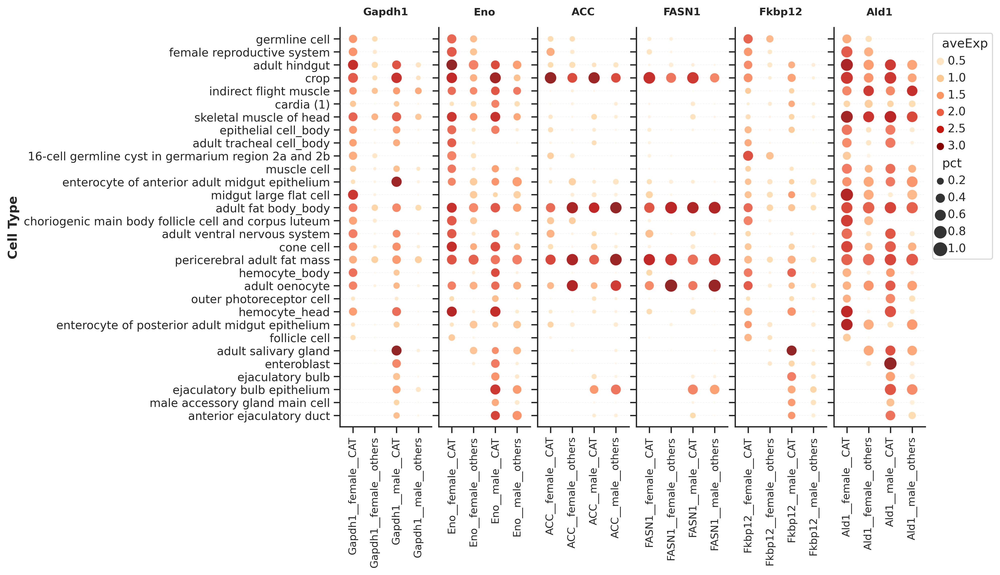

In [70]:
# FIXED PARAMETERS
FIXED_VMIN_PCT = 0.0
FIXED_VMAX_PCT = 1.0
FIXED_VMIN_EXP = 0.0
FIXED_VMAX_EXP = exp_pct_Df.aveExp.max()
FIXED_SIZE_MIN = 2
FIXED_SIZE_MAX = 150

# Color setup for custom legend
cmap = plt.cm.OrRd
norm = plt.Normalize(vmin=FIXED_VMIN_EXP, vmax=FIXED_VMAX_EXP)

# 
exp_pct_Df_clean = exp_pct_Df.copy()
# exp_pct_Df_clean[['aveExp', 'pct']] = exp_pct_Df_clean[['aveExp', 'pct']].fillna(0)


fig, axs = plt.subplots(1, 6, figsize=(10, 7), 
                        gridspec_kw={'wspace': 0.08})

for n, gene in enumerate(selectGenes_L):
    gene_data = exp_pct_Df_clean[exp_pct_Df_clean['gene'] == gene].copy()
    # gene_data = gene_data.sort_values('annotation')
    
    # gene_data.annotation = pd.Categorical(gene_data.annotation, categories=degNindex_L)
    scatter = sns.scatterplot(
        data=gene_data,
        x='gene_sex_CAT',
        y='annotation',
        size='pct',
        hue='aveExp',
        palette='OrRd',
        vmin=FIXED_VMIN_EXP,
        vmax=FIXED_VMAX_EXP,
        sizes=(FIXED_SIZE_MIN, FIXED_SIZE_MAX), 
        size_norm=plt.Normalize(FIXED_VMIN_PCT, FIXED_VMAX_PCT),
        alpha=0.85,
        linewidth=0.5,
        edgecolor='white',
        ax=axs[n],
        hue_order=degNindex_L,
        legend=(n == 5)  # Turn off automatic legend
    )

    # Optional: fine-tune legend position
    if n == 5 and axs[n].get_legend():
        axs[n].get_legend().set_bbox_to_anchor((1.02, 1.0))
    
        # axs[n].legend(bbox_to_anchor=(1.1, 1.0))

    # Styling
    axs[n].set_xlabel('')
    axs[n].set_title(gene, fontsize=10, fontweight='bold', pad=12)
    axs[n].tick_params(axis='x', rotation=90, labelsize=10)
    axs[n].margins(x=0.2, y=0.03)
    axs[n].grid(axis='y', alpha=0.2, linestyle='--', linewidth=0.5)
    
    # Y-axis (only show labels on first panel)
    if n == 0:
        axs[n].set_ylabel('Cell Type', fontsize=12, fontweight='bold')
    else:
        axs[n].set_ylabel('')
        axs[n].set_yticklabels([])
        
#     # # Add separator line
#     # if n < len(selectGenes_L) - 1:
#     #     axs[n].axvline(x=axs[n].get_xlim()[1], color='gray', 
#     #                   linewidth=1.5, alpha=0.3)
    
    # Clean spines
    axs[n].spines['top'].set_visible(False)
    axs[n].spines['right'].set_visible(False)
    
    # # legend position
    # if n = 5:
    #     axs[n].spines['right'].set_visible(False)
    
plt.tight_layout()

plt.savefig(f'{figure5PicFolder}/dotplot__cat_sex__glycolysis_lipid_Fkbp12__OrRd.pdf', dpi=300, bbox_inches='tight')
plt.show()

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data f

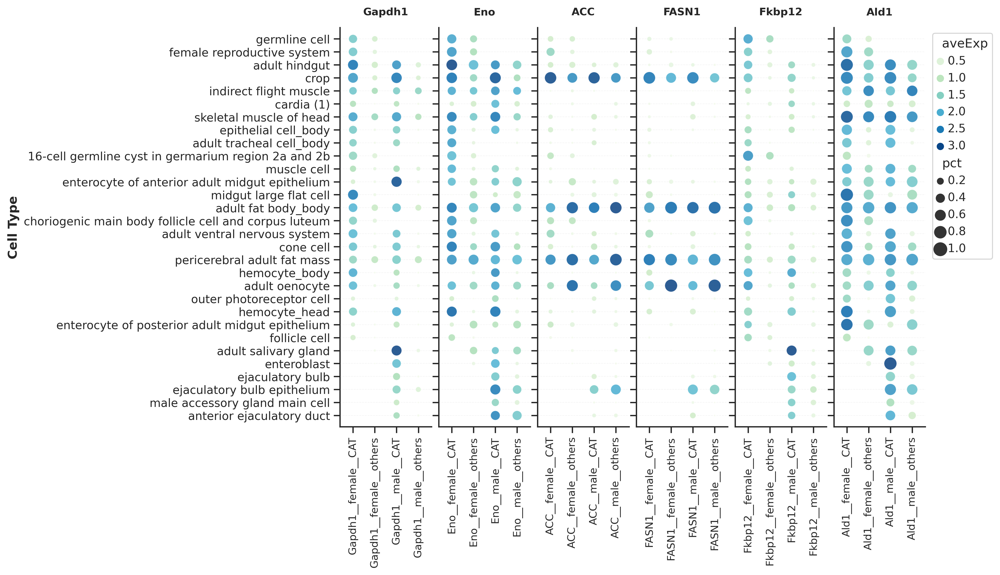

In [71]:
# FIXED PARAMETERS
FIXED_VMIN_PCT = 0.0
FIXED_VMAX_PCT = 1.0
FIXED_VMIN_EXP = 0.0
FIXED_VMAX_EXP = exp_pct_Df.aveExp.max()
FIXED_SIZE_MIN = 2
FIXED_SIZE_MAX = 150

# Color setup for custom legend
cmap = plt.cm.GnBu
norm = plt.Normalize(vmin=FIXED_VMIN_EXP, vmax=FIXED_VMAX_EXP)

# 
exp_pct_Df_clean = exp_pct_Df.copy()
# exp_pct_Df_clean[['aveExp', 'pct']] = exp_pct_Df_clean[['aveExp', 'pct']].fillna(0)


fig, axs = plt.subplots(1, 6, figsize=(10, 7), 
                        gridspec_kw={'wspace': 0.08})

for n, gene in enumerate(selectGenes_L):
    gene_data = exp_pct_Df_clean[exp_pct_Df_clean['gene'] == gene].copy()
    # gene_data = gene_data.sort_values('annotation')
    
    # gene_data.annotation = pd.Categorical(gene_data.annotation, categories=degNindex_L)
    scatter = sns.scatterplot(
        data=gene_data,
        x='gene_sex_CAT',
        y='annotation',
        size='pct',
        hue='aveExp',
        palette='GnBu',
        vmin=FIXED_VMIN_EXP,
        vmax=FIXED_VMAX_EXP,
        sizes=(FIXED_SIZE_MIN, FIXED_SIZE_MAX), 
        size_norm=plt.Normalize(FIXED_VMIN_PCT, FIXED_VMAX_PCT),
        alpha=0.85,
        linewidth=0.5,
        edgecolor='white',
        ax=axs[n],
        hue_order=degNindex_L,
        legend=(n == 5)  # Turn off automatic legend
    )

    # Optional: fine-tune legend position
    if n == 5 and axs[n].get_legend():
        axs[n].get_legend().set_bbox_to_anchor((1.02, 1.0))
    
        # axs[n].legend(bbox_to_anchor=(1.1, 1.0))

    # Styling
    axs[n].set_xlabel('')
    axs[n].set_title(gene, fontsize=10, fontweight='bold', pad=12)
    axs[n].tick_params(axis='x', rotation=90, labelsize=10)
    axs[n].margins(x=0.2, y=0.03)
    axs[n].grid(axis='y', alpha=0.2, linestyle='--', linewidth=0.5)
    
    # Y-axis (only show labels on first panel)
    if n == 0:
        axs[n].set_ylabel('Cell Type', fontsize=12, fontweight='bold')
    else:
        axs[n].set_ylabel('')
        axs[n].set_yticklabels([])
        
#     # # Add separator line
#     # if n < len(selectGenes_L) - 1:
#     #     axs[n].axvline(x=axs[n].get_xlim()[1], color='gray', 
#     #                   linewidth=1.5, alpha=0.3)
    
    # Clean spines
    axs[n].spines['top'].set_visible(False)
    axs[n].spines['right'].set_visible(False)
    
    # # legend position
    # if n = 5:
    #     axs[n].spines['right'].set_visible(False)
    
plt.tight_layout()
    
plt.savefig(f'{figure5PicFolder}/dotplot__cat_sex__glycolysis_lipid_Fkbp12_GnBu.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [77]:
exp_pct_Df

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct,gene_sex_CAT
0,Gapdh1__adult fat body_body__female__CAT,adult fat body_body__female__CAT,Gapdh1,adult fat body_body,female,CAT,1.350947,0.505376,Gapdh1__female__CAT
1,Gapdh1__adult fat body_body__female__others,adult fat body_body__female__others,Gapdh1,adult fat body_body,female,others,0.576492,0.282018,Gapdh1__female__others
2,Gapdh1__adult fat body_body__male__CAT,adult fat body_body__male__CAT,Gapdh1,adult fat body_body,male,CAT,1.245842,0.495413,Gapdh1__male__CAT
3,Gapdh1__adult fat body_body__male__others,adult fat body_body__male__others,Gapdh1,adult fat body_body,male,others,0.522689,0.240064,Gapdh1__male__others
4,Gapdh1__enterocyte of anterior adult midgut ep...,enterocyte of anterior adult midgut epithelium...,Gapdh1,enterocyte of anterior adult midgut epithelium,female,CAT,0.417665,0.142857,Gapdh1__female__CAT
...,...,...,...,...,...,...,...,...,...
715,Ald1__hemocyte_head__male__others,hemocyte_head__male__others,Ald1,hemocyte_head,male,others,0.409434,0.158399,Ald1__male__others
716,Ald1__enteroblast__female__CAT,enteroblast__female__CAT,Ald1,enteroblast,female,CAT,NaN,NaN,Ald1__female__CAT
717,Ald1__enteroblast__female__others,enteroblast__female__others,Ald1,enteroblast,female,others,0.428723,0.173343,Ald1__female__others
718,Ald1__enteroblast__male__CAT,enteroblast__male__CAT,Ald1,enteroblast,male,CAT,3.063672,1.000000,Ald1__male__CAT


In [156]:
exp_pct_Df_glyFkbp12 = exp_pct_Df[exp_pct_Df.gene.isin(['Gapdh1', 'Eno', 'Fkbp12'])]
exp_pct_Df_glyFkbp12.reset_index(drop=True, inplace=True)
exp_pct_Df_glyFkbp12

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct,gene_sex_CAT
0,Gapdh1__adult fat body_body__female__CAT,adult fat body_body__female__CAT,Gapdh1,adult fat body_body,female,CAT,1.350947,0.505376,Gapdh1__female__CAT
1,Gapdh1__adult fat body_body__female__others,adult fat body_body__female__others,Gapdh1,adult fat body_body,female,others,0.576492,0.282018,Gapdh1__female__others
2,Gapdh1__adult fat body_body__male__CAT,adult fat body_body__male__CAT,Gapdh1,adult fat body_body,male,CAT,1.245842,0.495413,Gapdh1__male__CAT
3,Gapdh1__adult fat body_body__male__others,adult fat body_body__male__others,Gapdh1,adult fat body_body,male,others,0.522689,0.240064,Gapdh1__male__others
4,Gapdh1__enterocyte of anterior adult midgut ep...,enterocyte of anterior adult midgut epithelium...,Gapdh1,enterocyte of anterior adult midgut epithelium,female,CAT,0.417665,0.142857,Gapdh1__female__CAT
...,...,...,...,...,...,...,...,...,...
355,Fkbp12__hemocyte_head__male__others,hemocyte_head__male__others,Fkbp12,hemocyte_head,male,others,0.101773,0.040905,Fkbp12__male__others
356,Fkbp12__enteroblast__female__CAT,enteroblast__female__CAT,Fkbp12,enteroblast,female,CAT,NaN,NaN,Fkbp12__female__CAT
357,Fkbp12__enteroblast__female__others,enteroblast__female__others,Fkbp12,enteroblast,female,others,0.329244,0.135359,Fkbp12__female__others
358,Fkbp12__enteroblast__male__CAT,enteroblast__male__CAT,Fkbp12,enteroblast,male,CAT,0.571856,0.250000,Fkbp12__male__CAT


In [157]:
exp_pct_Df_glyFkbp12.gene_sex_CAT = pd.Categorical(exp_pct_Df_glyFkbp12.gene_sex_CAT, 
                                                   categories=['Gapdh1__female__CAT', 'Gapdh1__female__others', 'Gapdh1__male__CAT', 'Gapdh1__male__others',
                                                               'Eno__female__CAT', 'Eno__female__others', 'Eno__male__CAT', 'Eno__male__others',
                                                               'Fkbp12__female__CAT', 'Fkbp12__female__others', 'Fkbp12__male__CAT', 'Fkbp12__male__others',
                                                              ])
exp_pct_Df_glyFkbp12.gene_sex_CAT.cat.categories

<ipython-input-157-88c807cdab0c>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  exp_pct_Df_glyFkbp12.gene_sex_CAT = pd.Categorical(exp_pct_Df_glyFkbp12.gene_sex_CAT,


Index(['Gapdh1__female__CAT', 'Gapdh1__female__others', 'Gapdh1__male__CAT',
       'Gapdh1__male__others', 'Eno__female__CAT', 'Eno__female__others',
       'Eno__male__CAT', 'Eno__male__others', 'Fkbp12__female__CAT',
       'Fkbp12__female__others', 'Fkbp12__male__CAT', 'Fkbp12__male__others'],
      dtype='object')

In [158]:
exp_pct_Df_glyFkbp12.gene_sex_CAT.value_counts()

gene_sex_CAT
Gapdh1__female__CAT       30
Gapdh1__female__others    30
Gapdh1__male__CAT         30
Gapdh1__male__others      30
Eno__female__CAT          30
Eno__female__others       30
Eno__male__CAT            30
Eno__male__others         30
Fkbp12__female__CAT       30
Fkbp12__female__others    30
Fkbp12__male__CAT         30
Fkbp12__male__others      30
Name: count, dtype: int64

In [159]:
exp_pct_Df_glyFkbp12['geneSex'] = pd.Categorical(exp_pct_Df_glyFkbp12.gene.astype(str) + '__' + exp_pct_Df_glyFkbp12.sex.astype(str), 
                                                 categories= ['Gapdh1__female', 'Gapdh1__male', 'Eno__female', 'Eno__male', 'Fkbp12__female', 'Fkbp12__male'])
exp_pct_Df_glyFkbp12.geneSex.cat.categories

<ipython-input-159-ead7a305c972>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  exp_pct_Df_glyFkbp12['geneSex'] = pd.Categorical(exp_pct_Df_glyFkbp12.gene.astype(str) + '__' + exp_pct_Df_glyFkbp12.sex.astype(str),


Index(['Gapdh1__female', 'Gapdh1__male', 'Eno__female', 'Eno__male',
       'Fkbp12__female', 'Fkbp12__male'],
      dtype='object')

In [160]:
geneN_D = {'Gapdh1': '1', 'Eno': '2', 'Fkbp12': '3'}
geneSexN_D = {'Gapdh1__female': '1', 'Gapdh1__male': '2', 'Eno__female': '3', 'Eno__male': '4', 'Fkbp12__female': '5', 'Fkbp12__male': '6', }
annot_D = dict(zip(exp_pct_Df_glyFkbp12.annotation.cat.categories, range(len(exp_pct_Df_glyFkbp12.annotation.cat.categories))))

In [161]:
exp_pct_Df_glyFkbp12['annotNum'] = [ annot_D[annot] for annot in exp_pct_Df_glyFkbp12.annotation]

<ipython-input-161-d49aa3b13e56>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  exp_pct_Df_glyFkbp12['annotNum'] = [ annot_D[annot] for annot in exp_pct_Df_glyFkbp12.annotation]


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
<ipython-input-179-3e8dfb2547cc>:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for (geneSex, annotNum), grp in df.groupby(['geneSex', 'annotNum']):


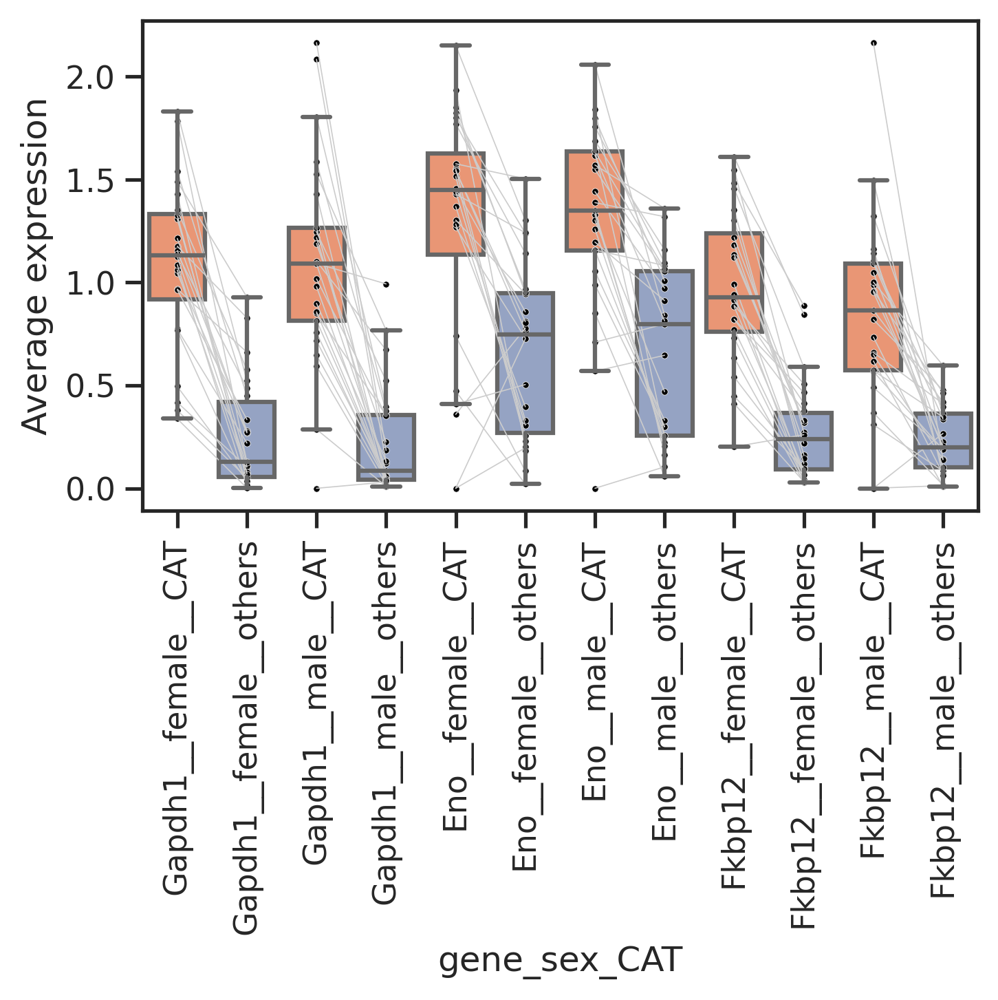

In [179]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = exp_pct_Df_glyFkbp12.copy()

fig, ax = plt.subplots(figsize=(5, 5))

# Get ordered x-axis categories
# x_order = sorted(df['gene_sex_CAT'].unique())
x_order = df.gene_sex_CAT.cat.categories
x_pos = {cat: i for i, cat in enumerate(x_order)}

# Draw boxplot and scatterplot as before
sns.boxplot(x='gene_sex_CAT', y='aveExp', data=df, order=x_order,
            fliersize=0, palette=['#fc8d62', '#8da0cb'], ax=ax)
sns.scatterplot(x='gene_sex_CAT', y='aveExp', data=df, s=5, color='black', ax=ax)

# Draw connecting lines manually for each (geneSex, annotNum) pair
for (geneSex, annotNum), grp in df.groupby(['geneSex', 'annotNum']):
    cat_row    = grp[grp['CAT_group'] == 'CAT']
    others_row = grp[grp['CAT_group'] == 'others']
    
    if cat_row.empty or others_row.empty:
        continue
    
    # There may be multiple annotations per geneSex/annotNum — iterate each annotation
    for ann in grp['annotation'].unique():
        sub = grp[grp['annotation'] == ann]
        cat_val    = sub[sub['CAT_group'] == 'CAT']['aveExp'].values
        others_val = sub[sub['CAT_group'] == 'others']['aveExp'].values
        
        if len(cat_val) == 0 or len(others_val) == 0:
            continue
        
        # Build the x labels used in gene_sex_CAT for this gene/sex
        gene = sub['gene'].iloc[0]
        sex  = sub['sex'].iloc[0]
        x_cat    = f"{gene}__{sex}__CAT"
        x_others = f"{gene}__{sex}__others"
        
        if x_cat in x_pos and x_others in x_pos:
            ax.plot(
                [x_pos[x_cat], x_pos[x_others]],
                [cat_val[0],   others_val[0]],
                color='0.8', linewidth=0.4, zorder=1
            )
ax.set(ylabel='Average expression')
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
plt.tight_layout()
plt.savefig(f'{figure5PicFolder}/boxplot__pairedExp.pdf')
plt.show()

In [164]:
import scipy.stats as stats

In [166]:
catExp

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct,gene_sex_CAT,geneSex,annotNum
0,Gapdh1__adult fat body_body__female__CAT,adult fat body_body__female__CAT,Gapdh1,adult fat body_body,female,CAT,1.350947,0.505376,Gapdh1__female__CAT,Gapdh1__female,13
4,Gapdh1__enterocyte of anterior adult midgut ep...,enterocyte of anterior adult midgut epithelium...,Gapdh1,enterocyte of anterior adult midgut epithelium,female,CAT,0.417665,0.142857,Gapdh1__female__CAT,Gapdh1__female,11
8,Gapdh1__adult oenocyte__female__CAT,adult oenocyte__female__CAT,Gapdh1,adult oenocyte,female,CAT,1.307927,0.475000,Gapdh1__female__CAT,Gapdh1__female,19
12,Gapdh1__pericerebral adult fat mass__female__CAT,pericerebral adult fat mass__female__CAT,Gapdh1,pericerebral adult fat mass,female,CAT,0.967543,0.414414,Gapdh1__female__CAT,Gapdh1__female,17
24,Gapdh1__adult ventral nervous system__female__CAT,adult ventral nervous system__female__CAT,Gapdh1,adult ventral nervous system,female,CAT,1.326744,0.526316,Gapdh1__female__CAT,Gapdh1__female,15
28,Gapdh1__indirect flight muscle__female__CAT,indirect flight muscle__female__CAT,Gapdh1,indirect flight muscle,female,CAT,1.176288,0.383306,Gapdh1__female__CAT,Gapdh1__female,4
40,Gapdh1__outer photoreceptor cell__female__CAT,outer photoreceptor cell__female__CAT,Gapdh1,outer photoreceptor cell,female,CAT,0.337748,0.121622,Gapdh1__female__CAT,Gapdh1__female,20
44,Gapdh1__enterocyte of posterior adult midgut e...,enterocyte of posterior adult midgut epitheliu...,Gapdh1,enterocyte of posterior adult midgut epithelium,female,CAT,0.378886,0.125000,Gapdh1__female__CAT,Gapdh1__female,22
48,Gapdh1__muscle cell__female__CAT,muscle cell__female__CAT,Gapdh1,muscle cell,female,CAT,0.773193,0.264368,Gapdh1__female__CAT,Gapdh1__female,10
52,Gapdh1__epithelial cell_body__female__CAT,epithelial cell_body__female__CAT,Gapdh1,epithelial cell_body,female,CAT,1.124164,0.426716,Gapdh1__female__CAT,Gapdh1__female,7


In [167]:
otherExp

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct,gene_sex_CAT,geneSex,annotNum
1,Gapdh1__adult fat body_body__female__others,adult fat body_body__female__others,Gapdh1,adult fat body_body,female,others,0.576492,0.282018,Gapdh1__female__others,Gapdh1__female,13
5,Gapdh1__enterocyte of anterior adult midgut ep...,enterocyte of anterior adult midgut epithelium...,Gapdh1,enterocyte of anterior adult midgut epithelium,female,others,0.103111,0.047878,Gapdh1__female__others,Gapdh1__female,11
9,Gapdh1__adult oenocyte__female__others,adult oenocyte__female__others,Gapdh1,adult oenocyte,female,others,0.128114,0.058813,Gapdh1__female__others,Gapdh1__female,19
13,Gapdh1__pericerebral adult fat mass__female__o...,pericerebral adult fat mass__female__others,Gapdh1,pericerebral adult fat mass,female,others,0.661667,0.318360,Gapdh1__female__others,Gapdh1__female,17
25,Gapdh1__adult ventral nervous system__female__...,adult ventral nervous system__female__others,Gapdh1,adult ventral nervous system,female,others,0.070409,0.032189,Gapdh1__female__others,Gapdh1__female,15
29,Gapdh1__indirect flight muscle__female__others,indirect flight muscle__female__others,Gapdh1,indirect flight muscle,female,others,0.828299,0.259111,Gapdh1__female__others,Gapdh1__female,4
41,Gapdh1__outer photoreceptor cell__female__others,outer photoreceptor cell__female__others,Gapdh1,outer photoreceptor cell,female,others,0.001430,0.000623,Gapdh1__female__others,Gapdh1__female,20
45,Gapdh1__enterocyte of posterior adult midgut e...,enterocyte of posterior adult midgut epitheliu...,Gapdh1,enterocyte of posterior adult midgut epithelium,female,others,0.050638,0.023515,Gapdh1__female__others,Gapdh1__female,22
49,Gapdh1__muscle cell__female__others,muscle cell__female__others,Gapdh1,muscle cell,female,others,0.219987,0.070746,Gapdh1__female__others,Gapdh1__female,10
53,Gapdh1__epithelial cell_body__female__others,epithelial cell_body__female__others,Gapdh1,epithelial cell_body,female,others,0.109527,0.038946,Gapdh1__female__others,Gapdh1__female,7


In [172]:
for geneSex in exp_pct_Df_glyFkbp12.geneSex.cat.categories:
    print(geneSex)
    
    
    df = exp_pct_Df_glyFkbp12[exp_pct_Df_glyFkbp12.geneSex == geneSex]
    df.reset_index(drop=True, inplace=True)
    # remove na annotations
    removeCt_L = df[df.aveExp.isna()].annotation.tolist()
        
    
    catExp = df[ (df.geneSex == geneSex) & (df.CAT_group == 'CAT') & (~df.annotation.isin(removeCt_L)) ].aveExp.to_list()
    otherExp = df[ (df.geneSex == geneSex) & (df.CAT_group == 'others')  & (~df.annotation.isin(removeCt_L)) ].aveExp.to_list()
    
    statistic, pvalue = stats.wilcoxon(catExp, otherExp)
    print(f"Wilcoxon statistic: {statistic}", f"P-value: {pvalue}")
    print(removeCt_L)
    print()


Gapdh1__female
Wilcoxon statistic: 0.0 P-value: 1.1920928955078125e-07
['male accessory gland main cell', 'male accessory gland main cell', 'ejaculatory bulb', 'ejaculatory bulb', 'anterior ejaculatory duct', 'anterior ejaculatory duct', 'ejaculatory bulb epithelium', 'ejaculatory bulb epithelium', 'adult salivary gland', 'enteroblast']

Gapdh1__male
Wilcoxon statistic: 1.0 P-value: 1.1920928955078125e-07
['follicle cell', 'follicle cell', 'choriogenic main body follicle cell and corpus luteum', 'choriogenic main body follicle cell and corpus luteum', 'female reproductive system', 'female reproductive system', 'germline cell', 'germline cell', '16-cell germline cyst in germarium region 2a and 2b', '16-cell germline cyst in germarium region 2a and 2b']

Eno__female
Wilcoxon statistic: 25.0 P-value: 0.00010764598846435547
['male accessory gland main cell', 'male accessory gland main cell', 'ejaculatory bulb', 'ejaculatory bulb', 'anterior ejaculatory duct', 'anterior ejaculatory duct', '

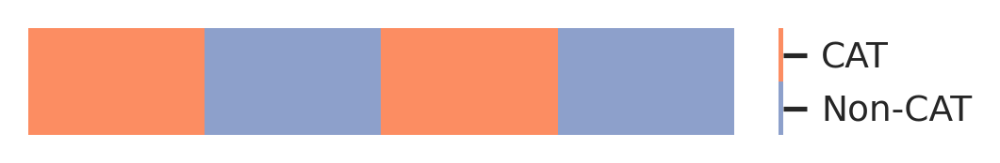

In [69]:
df = pd.DataFrame(index=['CAT group'], data=[[1, 0, 1, 0]])
value_to_int={'Non-CAT':0, 'CAT': 1,}
n = len(value_to_int)    

plt.figure(figsize=(4, 0.5))
parameters = {'xtick.labelsize': 9,'ytick.labelsize': 9, 'legend.fontsize':9}
plt.rcParams.update(parameters)

ax = sns.heatmap(df, cmap=['#8da0cb', '#fc8d62',], xticklabels=False ) # [cmap[4], cmap[6]]
colorbar=ax.collections[0].colorbar
r = colorbar.vmax - colorbar.vmin 
colorbar.set_ticks([colorbar.vmin + r / n * (0.5 + i) for i in range(n)])
colorbar.set_ticklabels(value_to_int.keys()) #not in the right order # sorted(list(value_to_int.keys()))

plt.ylabel('')
plt.yticks([])

plt.savefig(f'{figure5PicFolder}/heatmap__annotation__cat.pdf', dpi=300, bbox_inches='tight')
plt.show()

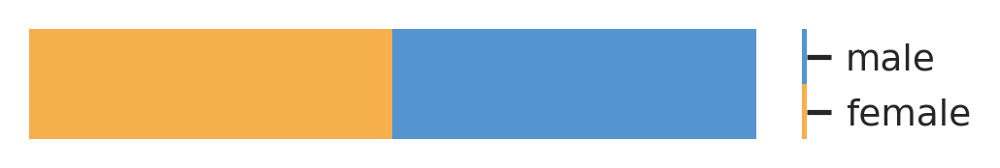

In [70]:
df = pd.DataFrame(index=['sex'], data=[[0, 0, 1, 1]])
value_to_int={'female':0, 'male': 1,}
n = len(value_to_int)    

plt.figure(figsize=(4, 0.5))
parameters = {'xtick.labelsize': 9,'ytick.labelsize': 9, 'legend.fontsize':9}
plt.rcParams.update(parameters)

ax = sns.heatmap(df, cmap=['#f5af4d', '#5495cf',], xticklabels=False ) # [cmap[4], cmap[6]]
colorbar=ax.collections[0].colorbar
r = colorbar.vmax - colorbar.vmin 
colorbar.set_ticks([colorbar.vmin + r / n * (0.5 + i) for i in range(n)])
colorbar.set_ticklabels(value_to_int.keys()) #not in the right order # sorted(list(value_to_int.keys()))

plt.ylabel('')
plt.yticks([])

plt.savefig(f'{figure5PicFolder}/heatmap__annotation__sex.pdf', dpi=300, bbox_inches='tight')
plt.show()

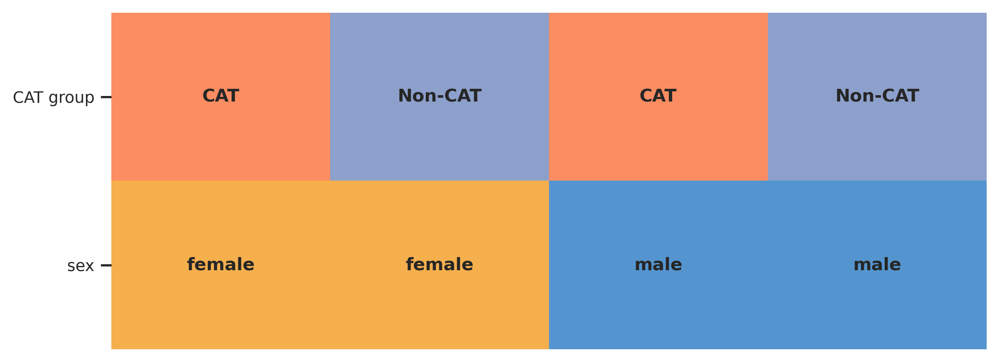

In [71]:
# Define colors for annotations
sex_colors = {'female': '#F5AF4DFF', 'male': '#5495CFFF'}
cat_colors = {'CAT': sns.color_palette("Set2")[1], 'Non-CAT': sns.color_palette("Set2")[2]}

# Create annotation DataFrame
annot_Df = pd.DataFrame(
    index=['CAT group', 'sex'], 
    data=[['CAT', 'Non-CAT', 'CAT', 'Non-CAT'], 
          ['female', 'female', 'male', 'male']]
)

# Create a numeric matrix for the heatmap (using the category mappings)
# Map categories to colors
cat_map = {'CAT': 0, 'Non-CAT': 1}
sex_map = {'female': 0, 'male': 1}

# Create numeric data for heatmap
numeric_data = pd.DataFrame(index=annot_Df.index, columns=annot_Df.columns)
numeric_data.loc['CAT group'] = annot_Df.loc['CAT group'].map(cat_map)
numeric_data.loc['sex'] = annot_Df.loc['sex'].map(sex_map)

# Create the figure
fig, ax = plt.subplots(figsize=(8, 3))

# Create color matrices for each row
cat_row_colors = [cat_colors[val] for val in annot_Df.loc['CAT group']]
sex_row_colors = [sex_colors[val] for val in annot_Df.loc['sex']]

# Convert hex colors to RGB if needed
from matplotlib.colors import to_rgb

cat_row_colors_rgb = [to_rgb(c) if isinstance(c, str) else c for c in cat_row_colors]
sex_row_colors_rgb = [to_rgb(c) if isinstance(c, str) else c for c in sex_row_colors]

# Combine into a 2D array with shape (2, 4, 3) for RGB
color_matrix = np.array([cat_row_colors_rgb, sex_row_colors_rgb])

# Create the heatmap using imshow for direct color control
ax.imshow(color_matrix, aspect='auto', interpolation='nearest')

# Set labels
ax.set_yticks([0, 1])
ax.set_yticklabels(['CAT group', 'sex'])
# ax.set_xticks(range(4))
# ax.set_xticklabels([f'Sample {i+1}' for i in range(4)])
ax.set_xticklabels([])
ax.tick_params(axis='x', length=0) 

for spine in ax.spines:
    ax.spines[spine].set_visible(False)

# Add text annotations
for i in range(2):
    for j in range(4):
        text = annot_Df.iloc[i, j]
        ax.text(j, i, text, ha='center', va='center', fontsize=10, fontweight='bold')

# plt.title('Annotation Heatmap', fontsize=12, fontweight='bold', pad=10)
plt.tight_layout()

# Save the figure
plt.savefig(f'{figure5PicFolder}/heatmap__annotation__cat_sex.pdf', dpi=300, bbox_inches='tight')

plt.show()

## Calculate aveExp & percentage (broad)

In [72]:
clusters = adata_body.obs['broad_sex__CAT_group'].cat.categories
obs = adata_body[:,selectGenes_L].X.toarray()
obs = pd.DataFrame(obs,columns=selectGenes_L,index=adata_body.obs['broad_sex__CAT_group'])
average_obs = obs.groupby(level=0).mean()
obs_bool = obs.astype(bool)
fraction_obs = obs_bool.groupby(level=0).sum()/obs_bool.groupby(level=0).count()

# # output
# average_obs.T.to_csv("average.csv")
# fraction_obs.T.to_csv("fraction.csv")

<ipython-input-72-1a194d628e8a>:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  average_obs = obs.groupby(level=0).mean()
<ipython-input-72-1a194d628e8a>:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fraction_obs = obs_bool.groupby(level=0).sum()/obs_bool.groupby(level=0).count()


In [73]:
average_obs

,Gapdh1,Eno,ACC,FASN1,Fkbp12,Ald1
broad_sex__CAT_group,,,,,,
CNS neuron__female__CAT,1.326744,1.551710,1.001497,1.150876,0.540805,2.078989
CNS neuron__female__others,0.070397,0.260964,0.108498,0.074608,0.100187,0.475328
CNS neuron__male__CAT,1.217780,1.260105,0.561283,0.618938,0.309006,2.251071
CNS neuron__male__others,0.079695,0.256878,0.122983,0.099806,0.087321,0.433568
PNS neuron__female__CAT,0.000000,1.348534,0.000000,0.000000,1.230935,2.015226
...,...,...,...,...,...,...
tracheal cell__male__others,0.044054,0.104254,0.032448,0.025614,0.013149,0.278858
unannotated__female__CAT,1.340093,1.892616,1.123025,0.938793,1.062672,2.273553
unannotated__female__others,0.261195,0.705263,0.614985,0.387668,0.198251,1.105899


In [74]:
obs

,Gapdh1,Eno,ACC,FASN1,Fkbp12,Ald1
broad_sex__CAT_group,,,,,,
gut cell__female__others,0.0,0.000000,0.000000,0.0,0.000000,1.583663
gut cell__female__others,0.0,1.871237,0.000000,0.0,1.119359,1.651388
female reproductive system__female__others,0.0,1.937213,2.244508,0.0,0.000000,2.168491
gut cell__female__others,0.0,1.503965,1.696017,0.0,0.000000,2.294031
gut cell__female__others,0.0,0.000000,0.000000,0.0,0.000000,2.131328
...,...,...,...,...,...,...
epithelial cell__male__others,0.0,0.000000,0.000000,0.0,0.000000,3.289800
epithelial cell__male__others,0.0,3.560447,0.000000,0.0,0.000000,3.560447
fat cell__male__others,0.0,0.000000,0.000000,0.0,0.000000,0.000000


In [75]:
fraction_obs

,Gapdh1,Eno,ACC,FASN1,Fkbp12,Ald1
broad_sex__CAT_group,,,,,,
CNS neuron__female__CAT,0.526316,0.578947,0.421053,0.421053,0.210526,0.736842
CNS neuron__female__others,0.032687,0.112038,0.047340,0.030884,0.045762,0.191839
CNS neuron__male__CAT,0.410256,0.435897,0.179487,0.205128,0.102564,0.717949
CNS neuron__male__others,0.036900,0.111812,0.053403,0.039125,0.040794,0.176525
PNS neuron__female__CAT,0.000000,0.500000,0.000000,0.000000,0.500000,0.750000
...,...,...,...,...,...,...
tracheal cell__male__others,0.016102,0.037985,0.012799,0.009496,0.005780,0.094963
unannotated__female__CAT,0.526316,0.694737,0.436842,0.363158,0.421053,0.789474
unannotated__female__others,0.115610,0.289756,0.251707,0.163902,0.087317,0.426341


In [76]:
broad_L = [annot for annot in list(adata_headBody.obs.rapamycin_annotation_broad.cat.categories) if annot not in ['cardial cell', 'unannotated']]
broad_L

['CNS neuron',
 'PNS neuron',
 'epithelial cell',
 'excretory system',
 'fat cell',
 'female germline cell',
 'female reproductive system',
 'gland',
 'glial cell',
 'gut cell',
 'hemocyte',
 'male germline cell',
 'male reproductive system',
 'muscle cell',
 'oenocyte',
 'sensory neuron',
 'tracheal cell']

In [77]:
selectGenes_L = ['Gapdh1', 'Eno', 'ACC', 'FASN1', 'Fkbp12', 'Ald1',]
# selectGenes_L = ['Eno', 'Gapdh1', 'Ald1', 'Fkbp12']

In [78]:
exp_pct_Df = pd.DataFrame(columns=['geneAnnotSexCat', 'annotSexCat', 'gene', 'annotation', 'sex', 'CAT_group', 'aveExp', 'pct'])

for gene in selectGenes_L:
    for ct in broad_L:
        for sex in ['female', 'male']:
            for catGroup in ['CAT', 'others']:
                geneAnnotSexCat=f'{gene}__{ct}__{sex}__{catGroup}'
                annotSexCat=f'{ct}__{sex}__{catGroup}'
                # print(geneAnnotSexCat,)
                # print(annotSexCat)
                
                if annotSexCat in average_obs.index.to_list():
                    exp = average_obs.loc[annotSexCat, gene]
                    pct= fraction_obs.loc[annotSexCat, gene]
                else: exp, pct = np.nan, np.nan
                
                exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
                
                
# exp_pct_Df

<ipython-input-78-0fd17a21759b>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
<ipython-input-78-0fd17a21759b>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
<ipython-input-78-0fd17a21759b>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. I

In [79]:
exp_pct_Df

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct
0,Gapdh1__CNS neuron__female__CAT,CNS neuron__female__CAT,Gapdh1,CNS neuron,female,CAT,1.326744,0.526316
1,Gapdh1__CNS neuron__female__others,CNS neuron__female__others,Gapdh1,CNS neuron,female,others,0.070397,0.032687
2,Gapdh1__CNS neuron__male__CAT,CNS neuron__male__CAT,Gapdh1,CNS neuron,male,CAT,1.217780,0.410256
3,Gapdh1__CNS neuron__male__others,CNS neuron__male__others,Gapdh1,CNS neuron,male,others,0.079695,0.036900
4,Gapdh1__PNS neuron__female__CAT,PNS neuron__female__CAT,Gapdh1,PNS neuron,female,CAT,0.000000,0.000000
...,...,...,...,...,...,...,...,...
403,Ald1__sensory neuron__male__others,sensory neuron__male__others,Ald1,sensory neuron,male,others,0.371129,0.132353
404,Ald1__tracheal cell__female__CAT,tracheal cell__female__CAT,Ald1,tracheal cell,female,CAT,1.770612,0.600000
405,Ald1__tracheal cell__female__others,tracheal cell__female__others,Ald1,tracheal cell,female,others,0.561795,0.196848
406,Ald1__tracheal cell__male__CAT,tracheal cell__male__CAT,Ald1,tracheal cell,male,CAT,1.963456,0.666667


In [80]:
categories_L = [f'{gene}__{sex}__{cat}' for gene in selectGenes_L for sex in ['female', 'male'] for cat in ['CAT', 'others']]
categories_L

['Gapdh1__female__CAT',
 'Gapdh1__female__others',
 'Gapdh1__male__CAT',
 'Gapdh1__male__others',
 'Eno__female__CAT',
 'Eno__female__others',
 'Eno__male__CAT',
 'Eno__male__others',
 'ACC__female__CAT',
 'ACC__female__others',
 'ACC__male__CAT',
 'ACC__male__others',
 'FASN1__female__CAT',
 'FASN1__female__others',
 'FASN1__male__CAT',
 'FASN1__male__others',
 'Fkbp12__female__CAT',
 'Fkbp12__female__others',
 'Fkbp12__male__CAT',
 'Fkbp12__male__others',
 'Ald1__female__CAT',
 'Ald1__female__others',
 'Ald1__male__CAT',
 'Ald1__male__others']

In [81]:
exp_pct_Df.loc[:,'gene_sex_CAT'] = pd.Categorical(exp_pct_Df.gene.astype(str)+'__'+exp_pct_Df.sex.astype(str)+'__'+exp_pct_Df.CAT_group.astype(str), categories=categories_L) # 

exp_pct_Df

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct,gene_sex_CAT
0,Gapdh1__CNS neuron__female__CAT,CNS neuron__female__CAT,Gapdh1,CNS neuron,female,CAT,1.326744,0.526316,Gapdh1__female__CAT
1,Gapdh1__CNS neuron__female__others,CNS neuron__female__others,Gapdh1,CNS neuron,female,others,0.070397,0.032687,Gapdh1__female__others
2,Gapdh1__CNS neuron__male__CAT,CNS neuron__male__CAT,Gapdh1,CNS neuron,male,CAT,1.217780,0.410256,Gapdh1__male__CAT
3,Gapdh1__CNS neuron__male__others,CNS neuron__male__others,Gapdh1,CNS neuron,male,others,0.079695,0.036900,Gapdh1__male__others
4,Gapdh1__PNS neuron__female__CAT,PNS neuron__female__CAT,Gapdh1,PNS neuron,female,CAT,0.000000,0.000000,Gapdh1__female__CAT
...,...,...,...,...,...,...,...,...,...
403,Ald1__sensory neuron__male__others,sensory neuron__male__others,Ald1,sensory neuron,male,others,0.371129,0.132353,Ald1__male__others
404,Ald1__tracheal cell__female__CAT,tracheal cell__female__CAT,Ald1,tracheal cell,female,CAT,1.770612,0.600000,Ald1__female__CAT
405,Ald1__tracheal cell__female__others,tracheal cell__female__others,Ald1,tracheal cell,female,others,0.561795,0.196848,Ald1__female__others
406,Ald1__tracheal cell__male__CAT,tracheal cell__male__CAT,Ald1,tracheal cell,male,CAT,1.963456,0.666667,Ald1__male__CAT


In [82]:
exp_pct_Df.gene_sex_CAT.cat.categories

Index(['Gapdh1__female__CAT', 'Gapdh1__female__others', 'Gapdh1__male__CAT',
       'Gapdh1__male__others', 'Eno__female__CAT', 'Eno__female__others',
       'Eno__male__CAT', 'Eno__male__others', 'ACC__female__CAT',
       'ACC__female__others', 'ACC__male__CAT', 'ACC__male__others',
       'FASN1__female__CAT', 'FASN1__female__others', 'FASN1__male__CAT',
       'FASN1__male__others', 'Fkbp12__female__CAT', 'Fkbp12__female__others',
       'Fkbp12__male__CAT', 'Fkbp12__male__others', 'Ald1__female__CAT',
       'Ald1__female__others', 'Ald1__male__CAT', 'Ald1__male__others'],
      dtype='object')

In [83]:
exp_pct_Df.annotation = pd.Categorical(exp_pct_Df.annotation, categories=ratio_Df.index.to_list())

In [86]:
exp_pct_Df

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct,gene_sex_CAT
0,Gapdh1__CNS neuron__female__CAT,CNS neuron__female__CAT,Gapdh1,NaN,female,CAT,1.326744,0.526316,Gapdh1__female__CAT
1,Gapdh1__CNS neuron__female__others,CNS neuron__female__others,Gapdh1,NaN,female,others,0.070397,0.032687,Gapdh1__female__others
2,Gapdh1__CNS neuron__male__CAT,CNS neuron__male__CAT,Gapdh1,NaN,male,CAT,1.217780,0.410256,Gapdh1__male__CAT
3,Gapdh1__CNS neuron__male__others,CNS neuron__male__others,Gapdh1,NaN,male,others,0.079695,0.036900,Gapdh1__male__others
4,Gapdh1__PNS neuron__female__CAT,PNS neuron__female__CAT,Gapdh1,NaN,female,CAT,0.000000,0.000000,Gapdh1__female__CAT
...,...,...,...,...,...,...,...,...,...
403,Ald1__sensory neuron__male__others,sensory neuron__male__others,Ald1,NaN,male,others,0.371129,0.132353,Ald1__male__others
404,Ald1__tracheal cell__female__CAT,tracheal cell__female__CAT,Ald1,NaN,female,CAT,1.770612,0.600000,Ald1__female__CAT
405,Ald1__tracheal cell__female__others,tracheal cell__female__others,Ald1,NaN,female,others,0.561795,0.196848,Ald1__female__others
406,Ald1__tracheal cell__male__CAT,tracheal cell__male__CAT,Ald1,NaN,male,CAT,1.963456,0.666667,Ald1__male__CAT


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data f

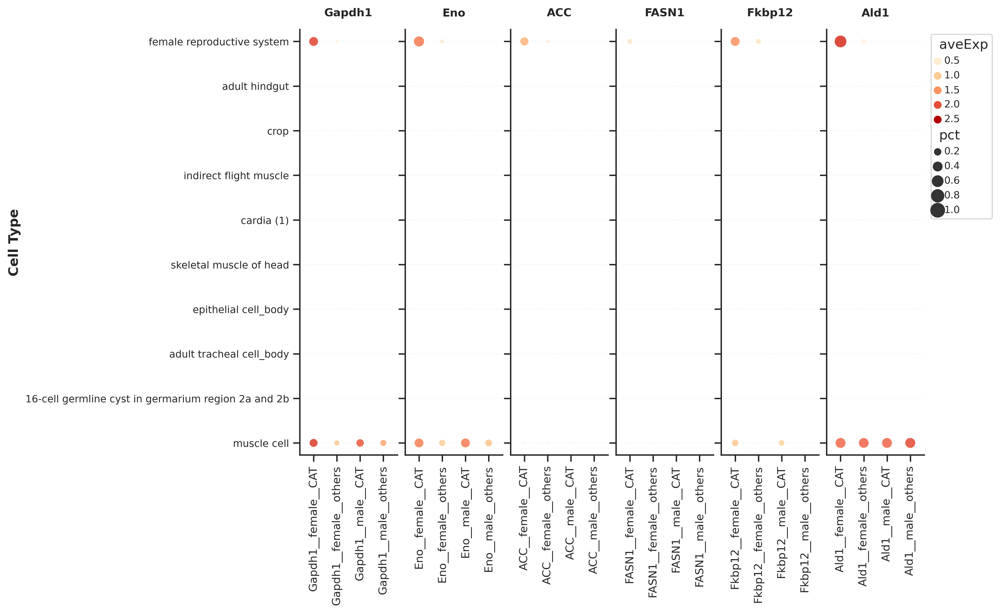

In [85]:
# FIXED PARAMETERS
FIXED_VMIN_PCT = 0.0
FIXED_VMAX_PCT = 1.0
FIXED_VMIN_EXP = 0.0
FIXED_VMAX_EXP = exp_pct_Df.aveExp.max()
FIXED_SIZE_MIN = 2
FIXED_SIZE_MAX = 150

# Color setup for custom legend
cmap = plt.cm.OrRd
norm = plt.Normalize(vmin=FIXED_VMIN_EXP, vmax=FIXED_VMAX_EXP)

# 
exp_pct_Df_clean = exp_pct_Df.copy()
# exp_pct_Df_clean[['aveExp', 'pct']] = exp_pct_Df_clean[['aveExp', 'pct']].fillna(0)


fig, axs = plt.subplots(1, 6, figsize=(10, 7), 
                        gridspec_kw={'wspace': 0.08})

for n, gene in enumerate(selectGenes_L):
    gene_data = exp_pct_Df_clean[exp_pct_Df_clean['gene'] == gene].copy()
    # gene_data = gene_data.sort_values('annotation')
    
    # gene_data.annotation = pd.Categorical(gene_data.annotation, categories=degNindex_L)
    scatter = sns.scatterplot(
        data=gene_data,
        x='gene_sex_CAT',
        y='annotation',
        size='pct',
        hue='aveExp',
        palette='OrRd',
        vmin=FIXED_VMIN_EXP,
        vmax=FIXED_VMAX_EXP,
        sizes=(FIXED_SIZE_MIN, FIXED_SIZE_MAX), 
        size_norm=plt.Normalize(FIXED_VMIN_PCT, FIXED_VMAX_PCT),
        alpha=0.85,
        linewidth=0.5,
        edgecolor='white',
        ax=axs[n],
        hue_order=broad_L,
        legend=(n == 5)  # Turn off automatic legend
    )

    # Optional: fine-tune legend position
    if n == 5 and axs[n].get_legend():
        axs[n].get_legend().set_bbox_to_anchor((1.02, 1.0))
    
        # axs[n].legend(bbox_to_anchor=(1.1, 1.0))

    # Styling
    axs[n].set_xlabel('')
    axs[n].set_title(gene, fontsize=10, fontweight='bold', pad=12)
    axs[n].tick_params(axis='x', rotation=90, labelsize=10)
    axs[n].margins(x=0.2, y=0.03)
    axs[n].grid(axis='y', alpha=0.2, linestyle='--', linewidth=0.5)
    
    # Y-axis (only show labels on first panel)
    if n == 0:
        axs[n].set_ylabel('Cell Type', fontsize=12, fontweight='bold')
    else:
        axs[n].set_ylabel('')
        axs[n].set_yticklabels([])
        
#     # # Add separator line
#     # if n < len(selectGenes_L) - 1:
#     #     axs[n].axvline(x=axs[n].get_xlim()[1], color='gray', 
#     #                   linewidth=1.5, alpha=0.3)
    
    # Clean spines
    axs[n].spines['top'].set_visible(False)
    axs[n].spines['right'].set_visible(False)
    
    # # legend position
    # if n = 5:
    #     axs[n].spines['right'].set_visible(False)
    
plt.tight_layout()

plt.savefig(f'{figure5PicFolder}/dotplot__cat_sex__glycolysis_lipid_Fkbp12__broad__OrRd.pdf', dpi=600, bbox_inches='tight')
plt.show()

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data f

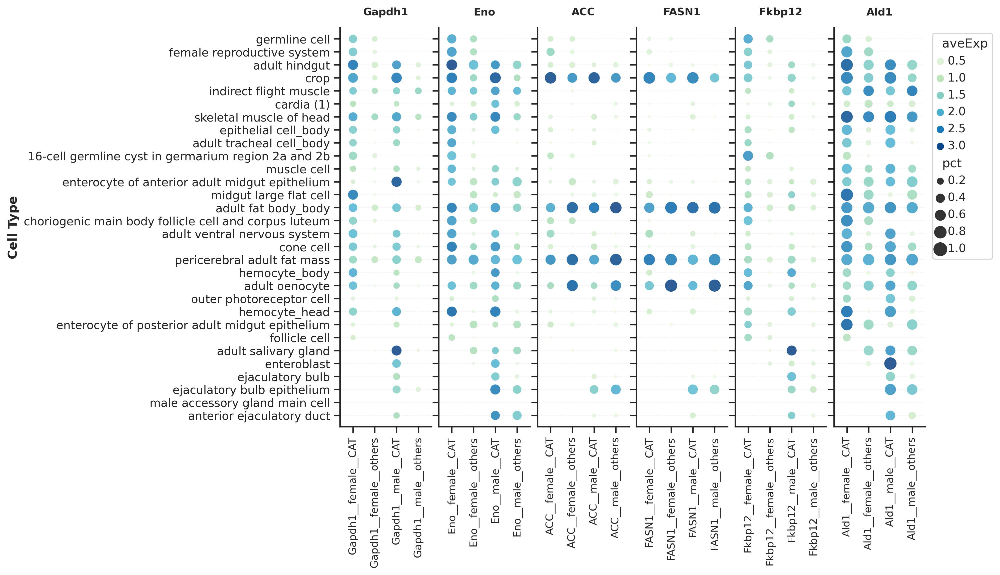

In [234]:
# FIXED PARAMETERS
FIXED_VMIN_PCT = 0.0
FIXED_VMAX_PCT = 1.0
FIXED_VMIN_EXP = 0.0
FIXED_VMAX_EXP = exp_pct_Df.aveExp.max()
FIXED_SIZE_MIN = 2
FIXED_SIZE_MAX = 150

# Color setup for custom legend
cmap = plt.cm.GnBu
norm = plt.Normalize(vmin=FIXED_VMIN_EXP, vmax=FIXED_VMAX_EXP)

# 
exp_pct_Df_clean = exp_pct_Df.copy()
# exp_pct_Df_clean[['aveExp', 'pct']] = exp_pct_Df_clean[['aveExp', 'pct']].fillna(0)


fig, axs = plt.subplots(1, 6, figsize=(10, 7), 
                        gridspec_kw={'wspace': 0.08})

for n, gene in enumerate(selectGenes_L):
    gene_data = exp_pct_Df_clean[exp_pct_Df_clean['gene'] == gene].copy()
    # gene_data = gene_data.sort_values('annotation')
    
    # gene_data.annotation = pd.Categorical(gene_data.annotation, categories=degNindex_L)
    scatter = sns.scatterplot(
        data=gene_data,
        x='gene_sex_CAT',
        y='annotation',
        size='pct',
        hue='aveExp',
        palette='GnBu',
        vmin=FIXED_VMIN_EXP,
        vmax=FIXED_VMAX_EXP,
        sizes=(FIXED_SIZE_MIN, FIXED_SIZE_MAX), 
        size_norm=plt.Normalize(FIXED_VMIN_PCT, FIXED_VMAX_PCT),
        alpha=0.85,
        linewidth=0.5,
        edgecolor='white',
        ax=axs[n],
        hue_order=degNindex_L,
        legend=(n == 5)  # Turn off automatic legend
    )

    # Optional: fine-tune legend position
    if n == 5 and axs[n].get_legend():
        axs[n].get_legend().set_bbox_to_anchor((1.02, 1.0))
    
        # axs[n].legend(bbox_to_anchor=(1.1, 1.0))

    # Styling
    axs[n].set_xlabel('')
    axs[n].set_title(gene, fontsize=10, fontweight='bold', pad=12)
    axs[n].tick_params(axis='x', rotation=90, labelsize=10)
    axs[n].margins(x=0.2, y=0.03)
    axs[n].grid(axis='y', alpha=0.2, linestyle='--', linewidth=0.5)
    
    # Y-axis (only show labels on first panel)
    if n == 0:
        axs[n].set_ylabel('Cell Type', fontsize=12, fontweight='bold')
    else:
        axs[n].set_ylabel('')
        axs[n].set_yticklabels([])
        
#     # # Add separator line
#     # if n < len(selectGenes_L) - 1:
#     #     axs[n].axvline(x=axs[n].get_xlim()[1], color='gray', 
#     #                   linewidth=1.5, alpha=0.3)
    
    # Clean spines
    axs[n].spines['top'].set_visible(False)
    axs[n].spines['right'].set_visible(False)
    
    # # legend position
    # if n = 5:
    #     axs[n].spines['right'].set_visible(False)
    
plt.tight_layout()
    
plt.savefig(f'{figure5PicFolder}/dotplot__cat_sex__glycolysis_lipid_Fkbp12_GnBu.pdf', dpi=300, bbox_inches='tight')
plt.show()

## Calculate aveExp & percentage (broad)

In [53]:
from matplotlib.colors import Normalize
from matplotlib.patches import Rectangle

In [218]:
# clusters = adata_headBody.obs['broad_sex__CAT_group'].cat.categories
# obs = adata_headBody[:,selectGenes_L].X.toarray()
# obs = pd.DataFrame(obs,columns=selectGenes_L,index=adata_headBody.obs['broad_sex__CAT_group'])
# average_obs = obs.groupby(level=0).mean()
# obs_bool = obs.astype(bool)
# fraction_obs = obs_bool.groupby(level=0).sum()/obs_bool.groupby(level=0).count()

# # # output
# # average_obs.T.to_csv("average.csv")
# # fraction_obs.T.to_csv("fraction.csv")

In [54]:
clusters = adata_body.obs['broad_sex__CAT_group'].cat.categories
obs = adata_body[:,selectGenes_L].X.toarray()
obs = pd.DataFrame(obs,columns=selectGenes_L,index=adata_body.obs['broad_sex__CAT_group'])
average_obs = obs.groupby(level=0).mean()
obs_bool = obs.astype(bool)
fraction_obs = obs_bool.groupby(level=0).sum()/obs_bool.groupby(level=0).count()

# # output
# average_obs.T.to_csv("average.csv")
# fraction_obs.T.to_csv("fraction.csv")

<ipython-input-54-1a194d628e8a>:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  average_obs = obs.groupby(level=0).mean()
<ipython-input-54-1a194d628e8a>:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fraction_obs = obs_bool.groupby(level=0).sum()/obs_bool.groupby(level=0).count()


In [55]:
average_obs

,Eno,Gapdh1,Ald1,ACC,FASN1,Fkbp12
broad_sex__CAT_group,,,,,,
CNS neuron__female__CAT,1.551710,1.326744,2.078989,1.001497,1.150876,0.540805
CNS neuron__female__others,0.260964,0.070397,0.475328,0.108498,0.074608,0.100187
CNS neuron__male__CAT,1.260105,1.217780,2.251071,0.561283,0.618938,0.309006
CNS neuron__male__others,0.256878,0.079695,0.433568,0.122983,0.099806,0.087321
PNS neuron__female__CAT,1.348534,0.000000,2.015226,0.000000,0.000000,1.230935
...,...,...,...,...,...,...
tracheal cell__male__others,0.104254,0.044054,0.278858,0.032448,0.025614,0.013149
unannotated__female__CAT,1.892616,1.340093,2.273553,1.123025,0.938793,1.062672
unannotated__female__others,0.705263,0.261195,1.105899,0.614985,0.387668,0.198251


In [56]:
obs

,Eno,Gapdh1,Ald1,ACC,FASN1,Fkbp12
broad_sex__CAT_group,,,,,,
gut cell__female__others,0.000000,0.0,1.583663,0.000000,0.0,0.000000
gut cell__female__others,1.871237,0.0,1.651388,0.000000,0.0,1.119359
female reproductive system__female__others,1.937213,0.0,2.168491,2.244508,0.0,0.000000
gut cell__female__others,1.503965,0.0,2.294031,1.696017,0.0,0.000000
gut cell__female__others,0.000000,0.0,2.131328,0.000000,0.0,0.000000
...,...,...,...,...,...,...
epithelial cell__male__others,0.000000,0.0,3.289800,0.000000,0.0,0.000000
epithelial cell__male__others,3.560447,0.0,3.560447,0.000000,0.0,0.000000
fat cell__male__others,0.000000,0.0,0.000000,0.000000,0.0,0.000000


In [57]:
fraction_obs

,Eno,Gapdh1,Ald1,ACC,FASN1,Fkbp12
broad_sex__CAT_group,,,,,,
CNS neuron__female__CAT,0.578947,0.526316,0.736842,0.421053,0.421053,0.210526
CNS neuron__female__others,0.112038,0.032687,0.191839,0.047340,0.030884,0.045762
CNS neuron__male__CAT,0.435897,0.410256,0.717949,0.179487,0.205128,0.102564
CNS neuron__male__others,0.111812,0.036900,0.176525,0.053403,0.039125,0.040794
PNS neuron__female__CAT,0.500000,0.000000,0.750000,0.000000,0.000000,0.500000
...,...,...,...,...,...,...
tracheal cell__male__others,0.037985,0.016102,0.094963,0.012799,0.009496,0.005780
unannotated__female__CAT,0.694737,0.526316,0.789474,0.436842,0.363158,0.421053
unannotated__female__others,0.289756,0.115610,0.426341,0.251707,0.163902,0.087317


In [58]:
broad_L = [annot for annot in list(adata_headBody.obs.rapamycin_annotation_broad.cat.categories) if annot not in ['cardial cell', 'unannotated']]
broad_L

['CNS neuron',
 'PNS neuron',
 'epithelial cell',
 'excretory system',
 'fat cell',
 'female germline cell',
 'female reproductive system',
 'gland',
 'glial cell',
 'gut cell',
 'hemocyte',
 'male germline cell',
 'male reproductive system',
 'muscle cell',
 'oenocyte',
 'sensory neuron',
 'tracheal cell']

In [144]:
selectGenes_L = ['Eno', 'Gapdh1', 'ACC', 'FASN1', 'Fkbp12', 'Ald1',]
# selectGenes_L = ['Eno', 'Gapdh1', 'Ald1', 'Fkbp12']

In [145]:
exp_pct_Df = pd.DataFrame(columns=['geneAnnotSexCat', 'annotSexCat', 'gene', 'annotation', 'sex', 'CAT_group', 'aveExp', 'pct'])

for gene in selectGenes_L:
    for ct in broad_L:
        for sex in ['female', 'male']:
            for catGroup in ['CAT', 'others']:
                geneAnnotSexCat=f'{gene}__{ct}__{sex}__{catGroup}'
                annotSexCat=f'{ct}__{sex}__{catGroup}'
                # print(geneAnnotSexCat,)
                # print(annotSexCat)
                
                if annotSexCat in average_obs.index.to_list():
                    exp = average_obs.loc[annotSexCat, gene]
                    pct= fraction_obs.loc[annotSexCat, gene]
                else: exp, pct = np.nan, np.nan
                
                exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
                
                
exp_pct_Df

<ipython-input-145-ee52235bf7d7>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
<ipython-input-145-ee52235bf7d7>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
<ipython-input-145-ee52235bf7d7>:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct
0,Eno__CNS neuron__female__CAT,CNS neuron__female__CAT,Eno,CNS neuron,female,CAT,1.551710,0.578947
1,Eno__CNS neuron__female__others,CNS neuron__female__others,Eno,CNS neuron,female,others,0.260964,0.112038
2,Eno__CNS neuron__male__CAT,CNS neuron__male__CAT,Eno,CNS neuron,male,CAT,1.260105,0.435897
3,Eno__CNS neuron__male__others,CNS neuron__male__others,Eno,CNS neuron,male,others,0.256878,0.111812
4,Eno__PNS neuron__female__CAT,PNS neuron__female__CAT,Eno,PNS neuron,female,CAT,1.348534,0.500000
...,...,...,...,...,...,...,...,...
403,Ald1__sensory neuron__male__others,sensory neuron__male__others,Ald1,sensory neuron,male,others,0.371129,0.132353
404,Ald1__tracheal cell__female__CAT,tracheal cell__female__CAT,Ald1,tracheal cell,female,CAT,1.770612,0.600000
405,Ald1__tracheal cell__female__others,tracheal cell__female__others,Ald1,tracheal cell,female,others,0.561795,0.196848
406,Ald1__tracheal cell__male__CAT,tracheal cell__male__CAT,Ald1,tracheal cell,male,CAT,1.963456,0.666667


In [146]:
# exp_pct_Df.drop('gene_sex_CAT', axis=1, inplace=True)

In [147]:
categories_L = [f'{gene}__{sex}__{cat}' for gene in selectGenes_L for sex in ['female', 'male'] for cat in ['CAT', 'others']]
categories_L

['Eno__female__CAT',
 'Eno__female__others',
 'Eno__male__CAT',
 'Eno__male__others',
 'Gapdh1__female__CAT',
 'Gapdh1__female__others',
 'Gapdh1__male__CAT',
 'Gapdh1__male__others',
 'ACC__female__CAT',
 'ACC__female__others',
 'ACC__male__CAT',
 'ACC__male__others',
 'FASN1__female__CAT',
 'FASN1__female__others',
 'FASN1__male__CAT',
 'FASN1__male__others',
 'Fkbp12__female__CAT',
 'Fkbp12__female__others',
 'Fkbp12__male__CAT',
 'Fkbp12__male__others',
 'Ald1__female__CAT',
 'Ald1__female__others',
 'Ald1__male__CAT',
 'Ald1__male__others']

In [148]:
ratio_Df = pd.read_csv(f'{figure5Folder}/ratio_Df.csv', index_col=0)
ratio_Df

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089,NaN,NaN,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.065934,0.460870,0.222727,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.000000,0.039216,0.121951,0.333333,0.181818,0.000000,0.000000,0.015038,0.197802,0.047170
crop,0.041534,0.059028,0.036638,0.307042,0.094139,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000479,0.170732,0.019380,0.277520,0.284598,0.000000,0.008673,0.008594,0.052448,0.180915
cardia (1),0.000000,0.000000,0.010753,0.255814,0.010204,0.007194,0.000000,0.000000,0.036145,0.040984
skeletal muscle of head,0.047525,0.265385,0.278607,0.186620,0.227373,0.114130,0.358400,0.501441,0.488372,0.419580
epithelial cell_body,0.011250,0.076923,0.025943,0.120290,0.068251,0.019856,0.047722,0.067568,0.110126,0.068210
adult tracheal cell_body,0.001344,0.020134,0.002681,0.086420,0.009245,0.000000,0.000000,0.002646,0.007220,0.004484
16-cell germline cyst in germarium region 2a and 2b,0.005618,0.013986,0.008368,0.049180,0.078853,NaN,NaN,NaN,NaN,NaN


In [149]:
exp_pct_Df.loc[:,'gene_sex_CAT'] = pd.Categorical(exp_pct_Df.gene.astype(str)+'__'+exp_pct_Df.sex.astype(str)+'__'+exp_pct_Df.CAT_group.astype(str), categories=categories_L) # 

exp_pct_Df

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct,gene_sex_CAT
0,Eno__CNS neuron__female__CAT,CNS neuron__female__CAT,Eno,CNS neuron,female,CAT,1.551710,0.578947,Eno__female__CAT
1,Eno__CNS neuron__female__others,CNS neuron__female__others,Eno,CNS neuron,female,others,0.260964,0.112038,Eno__female__others
2,Eno__CNS neuron__male__CAT,CNS neuron__male__CAT,Eno,CNS neuron,male,CAT,1.260105,0.435897,Eno__male__CAT
3,Eno__CNS neuron__male__others,CNS neuron__male__others,Eno,CNS neuron,male,others,0.256878,0.111812,Eno__male__others
4,Eno__PNS neuron__female__CAT,PNS neuron__female__CAT,Eno,PNS neuron,female,CAT,1.348534,0.500000,Eno__female__CAT
...,...,...,...,...,...,...,...,...,...
403,Ald1__sensory neuron__male__others,sensory neuron__male__others,Ald1,sensory neuron,male,others,0.371129,0.132353,Ald1__male__others
404,Ald1__tracheal cell__female__CAT,tracheal cell__female__CAT,Ald1,tracheal cell,female,CAT,1.770612,0.600000,Ald1__female__CAT
405,Ald1__tracheal cell__female__others,tracheal cell__female__others,Ald1,tracheal cell,female,others,0.561795,0.196848,Ald1__female__others
406,Ald1__tracheal cell__male__CAT,tracheal cell__male__CAT,Ald1,tracheal cell,male,CAT,1.963456,0.666667,Ald1__male__CAT


In [150]:
exp_pct_Df.gene_sex_CAT.cat.categories

Index(['Eno__female__CAT', 'Eno__female__others', 'Eno__male__CAT',
       'Eno__male__others', 'Gapdh1__female__CAT', 'Gapdh1__female__others',
       'Gapdh1__male__CAT', 'Gapdh1__male__others', 'ACC__female__CAT',
       'ACC__female__others', 'ACC__male__CAT', 'ACC__male__others',
       'FASN1__female__CAT', 'FASN1__female__others', 'FASN1__male__CAT',
       'FASN1__male__others', 'Fkbp12__female__CAT', 'Fkbp12__female__others',
       'Fkbp12__male__CAT', 'Fkbp12__male__others', 'Ald1__female__CAT',
       'Ald1__female__others', 'Ald1__male__CAT', 'Ald1__male__others'],
      dtype='object')

In [151]:
# exp_pct_Df.annotation = pd.Categorical(exp_pct_Df.annotation, categories=ratio_Df.index.to_list())

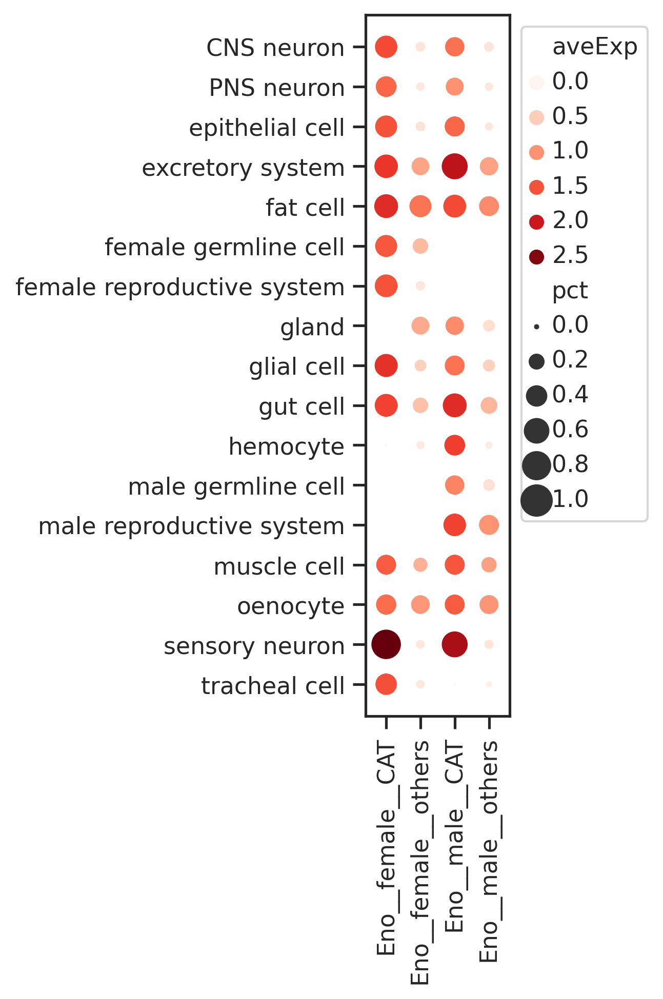

In [152]:
# # Define normalization parameters
vmin = 0  # Force the minimum to be 0
vmax = exp_pct_Df['pct'].max()

expMax=exp_pct_Df.aveExp.max()

with rc_context({'figure.figsize': (1.2, 6)}):
    ax = sns.scatterplot(data=exp_pct_Df[exp_pct_Df.gene == 'Eno'], x= 'gene_sex_CAT', y= 'annotation', size='pct', hue='aveExp', palette='Reds',
                         sizes=(2, 200), size_norm=plt.Normalize(vmin, vmax)) #  palette=list(colodr_D.values()) 
    plt.legend(bbox_to_anchor=(1, 1.0))
    # plt.margins(x=0.1, y=0.2)
    plt.xlabel('')
    plt.ylabel('')
    plt.xticks(rotation=90,)
    # plt.title('Differential expression of Nrx-1\nupon Rapamycin treatment')
    plt.margins(x=0.2,)

    # plt.savefig(f'{figure4PicFolder}/dotplot__VNC__Nrx1__deg.pdf', bbox_inches='tight')
    plt.show()

In [153]:
exp_pct_Df

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct,gene_sex_CAT
0,Eno__CNS neuron__female__CAT,CNS neuron__female__CAT,Eno,CNS neuron,female,CAT,1.551710,0.578947,Eno__female__CAT
1,Eno__CNS neuron__female__others,CNS neuron__female__others,Eno,CNS neuron,female,others,0.260964,0.112038,Eno__female__others
2,Eno__CNS neuron__male__CAT,CNS neuron__male__CAT,Eno,CNS neuron,male,CAT,1.260105,0.435897,Eno__male__CAT
3,Eno__CNS neuron__male__others,CNS neuron__male__others,Eno,CNS neuron,male,others,0.256878,0.111812,Eno__male__others
4,Eno__PNS neuron__female__CAT,PNS neuron__female__CAT,Eno,PNS neuron,female,CAT,1.348534,0.500000,Eno__female__CAT
...,...,...,...,...,...,...,...,...,...
403,Ald1__sensory neuron__male__others,sensory neuron__male__others,Ald1,sensory neuron,male,others,0.371129,0.132353,Ald1__male__others
404,Ald1__tracheal cell__female__CAT,tracheal cell__female__CAT,Ald1,tracheal cell,female,CAT,1.770612,0.600000,Ald1__female__CAT
405,Ald1__tracheal cell__female__others,tracheal cell__female__others,Ald1,tracheal cell,female,others,0.561795,0.196848,Ald1__female__others
406,Ald1__tracheal cell__male__CAT,tracheal cell__male__CAT,Ald1,tracheal cell,male,CAT,1.963456,0.666667,Ald1__male__CAT


In [154]:
exp_pct_Df.to_csv(f'{figure5Folder}/exp_pct_Df.csv', index=None)

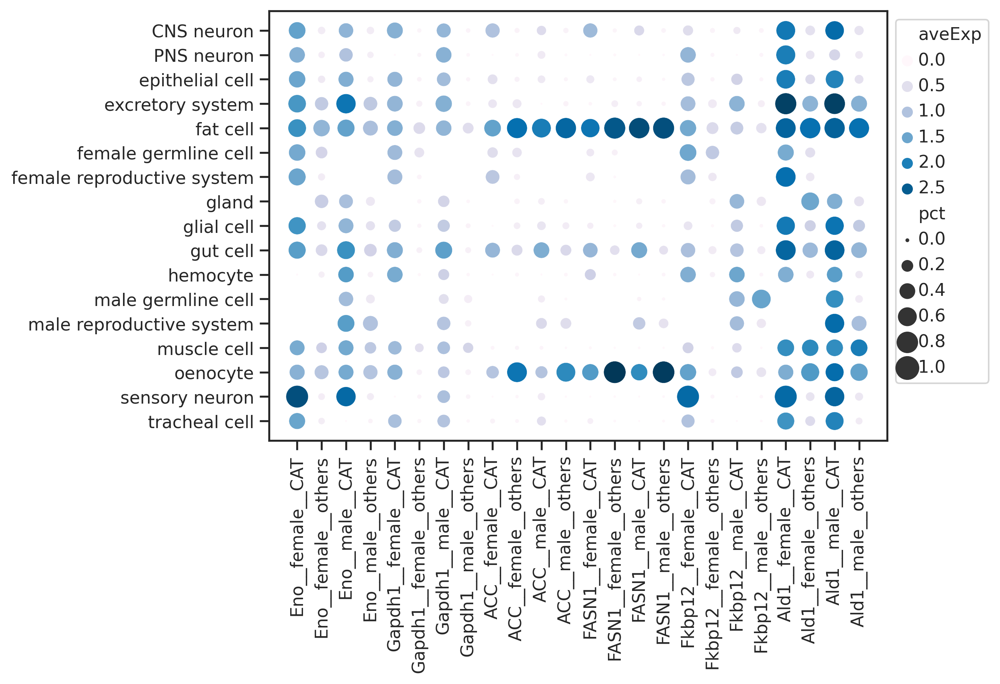

In [155]:
# # Define normalization parameters
vmin = 0  # Force the minimum to be 0
vmax = exp_pct_Df['pct'].max()

expMax=exp_pct_Df.aveExp.max()

with rc_context({'figure.figsize': (7, 5)}):
    ax = sns.scatterplot(data=exp_pct_Df, x= 'gene_sex_CAT', y= 'annotation', size='pct', hue='aveExp', palette='PuBu',
                         sizes=(2, 200), size_norm=plt.Normalize(vmin, vmax)) #  palette=list(colodr_D.values()) 
    plt.legend(bbox_to_anchor=(1, 1.0))
    # plt.margins(x=0.1, y=0.2)
    plt.xlabel('')
    plt.ylabel('')
    plt.xticks(rotation=90,)
    # plt.title('Differential expression of Nrx-1\nupon Rapamycin treatment')
    # plt.margins(x=0.2,)

    # plt.savefig(f'{figure4PicFolder}/dotplot__VNC__Nrx1__deg.pdf', bbox_inches='tight')
    plt.show()

In [156]:
exp_pct_Df_clean = exp_pct_Df.copy()
exp_pct_Df_clean[['aveExp', 'pct']] = exp_pct_Df_clean[['aveExp', 'pct']].fillna(0)
exp_pct_Df_clean

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct,gene_sex_CAT
0,Eno__CNS neuron__female__CAT,CNS neuron__female__CAT,Eno,CNS neuron,female,CAT,1.551710,0.578947,Eno__female__CAT
1,Eno__CNS neuron__female__others,CNS neuron__female__others,Eno,CNS neuron,female,others,0.260964,0.112038,Eno__female__others
2,Eno__CNS neuron__male__CAT,CNS neuron__male__CAT,Eno,CNS neuron,male,CAT,1.260105,0.435897,Eno__male__CAT
3,Eno__CNS neuron__male__others,CNS neuron__male__others,Eno,CNS neuron,male,others,0.256878,0.111812,Eno__male__others
4,Eno__PNS neuron__female__CAT,PNS neuron__female__CAT,Eno,PNS neuron,female,CAT,1.348534,0.500000,Eno__female__CAT
...,...,...,...,...,...,...,...,...,...
403,Ald1__sensory neuron__male__others,sensory neuron__male__others,Ald1,sensory neuron,male,others,0.371129,0.132353,Ald1__male__others
404,Ald1__tracheal cell__female__CAT,tracheal cell__female__CAT,Ald1,tracheal cell,female,CAT,1.770612,0.600000,Ald1__female__CAT
405,Ald1__tracheal cell__female__others,tracheal cell__female__others,Ald1,tracheal cell,female,others,0.561795,0.196848,Ald1__female__others
406,Ald1__tracheal cell__male__CAT,tracheal cell__male__CAT,Ald1,tracheal cell,male,CAT,1.963456,0.666667,Ald1__male__CAT


In [157]:
# Create normalizers with fixed ranges
size_norm = Normalize(vmin=FIXED_VMIN_PCT, vmax=FIXED_VMAX_PCT)
color_norm = Normalize(vmin=FIXED_VMIN_EXP, vmax=FIXED_VMAX_EXP)

# Define colors for annotations
sex_colors = {'female': '#F5AF4DFF', 'male': '#5495CFFF'}
cat_colors = {'CAT': sns.color_palette("Set2")[1], 'others': sns.color_palette("Set2")[2]}

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data f

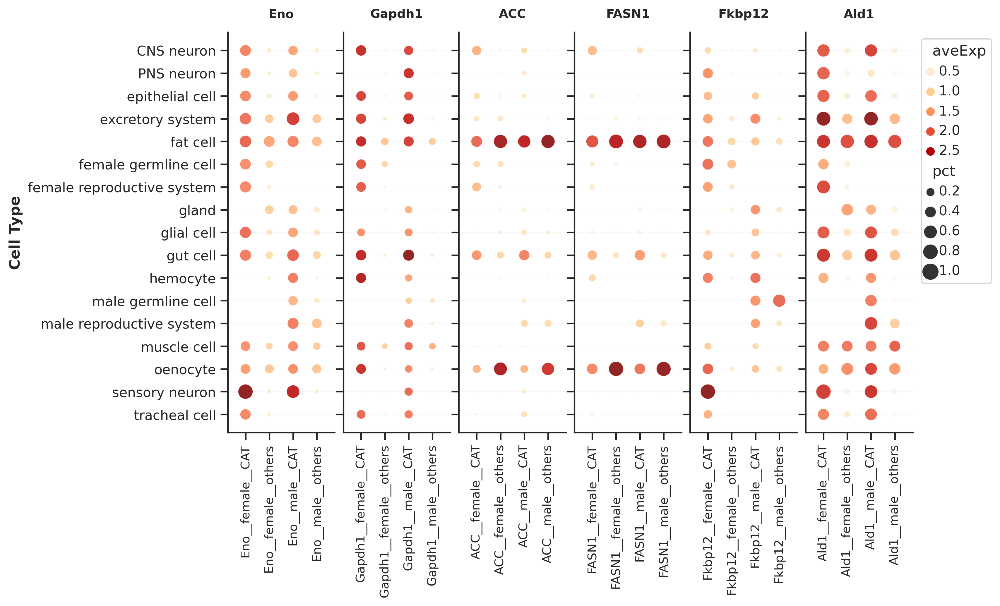

In [158]:
# FIXED PARAMETERS
FIXED_VMIN_PCT = 0.0
FIXED_VMAX_PCT = 1.0
FIXED_VMIN_EXP = 0.0
FIXED_VMAX_EXP = exp_pct_Df.aveExp.max()
FIXED_SIZE_MIN = 2
FIXED_SIZE_MAX = 150

# Color setup for custom legend
cmap = plt.cm.OrRd
norm = plt.Normalize(vmin=FIXED_VMIN_EXP, vmax=FIXED_VMAX_EXP)

# 
exp_pct_Df_clean = exp_pct_Df.copy()
# exp_pct_Df_clean[['aveExp', 'pct']] = exp_pct_Df_clean[['aveExp', 'pct']].fillna(0)


fig, axs = plt.subplots(1, 6, figsize=(10, 6), 
                        gridspec_kw={'wspace': 0.08})

for n, gene in enumerate(selectGenes_L):
    gene_data = exp_pct_Df_clean[exp_pct_Df_clean['gene'] == gene].copy()
    # gene_data = gene_data.sort_values('annotation')
    
    scatter = sns.scatterplot(
        data=gene_data,
        x='gene_sex_CAT',
        y='annotation',
        size='pct',
        hue='aveExp',
        palette='OrRd',
        vmin=FIXED_VMIN_EXP,
        vmax=FIXED_VMAX_EXP,
        sizes=(FIXED_SIZE_MIN, FIXED_SIZE_MAX), 
        size_norm=plt.Normalize(FIXED_VMIN_PCT, FIXED_VMAX_PCT),
        alpha=0.85,
        linewidth=0.5,
        edgecolor='white',
        ax=axs[n],
        legend=(n == 5)  # Turn off automatic legend
    )

    # Optional: fine-tune legend position
    if n == 5 and axs[n].get_legend():
        axs[n].get_legend().set_bbox_to_anchor((1.02, 1.0))
    
        # axs[n].legend(bbox_to_anchor=(1.1, 1.0))

    # Styling
    axs[n].set_xlabel('')
    axs[n].set_title(gene, fontsize=10, fontweight='bold', pad=12)
    axs[n].tick_params(axis='x', rotation=90, labelsize=10)
    axs[n].margins(x=0.25, y=0.05)
    axs[n].grid(axis='y', alpha=0.2, linestyle='--', linewidth=0.5)
    
    # Y-axis (only show labels on first panel)
    if n == 0:
        axs[n].set_ylabel('Cell Type', fontsize=12, fontweight='bold')
    else:
        axs[n].set_ylabel('')
        axs[n].set_yticklabels([])
        
#     # # Add separator line
#     # if n < len(selectGenes_L) - 1:
#     #     axs[n].axvline(x=axs[n].get_xlim()[1], color='gray', 
#     #                   linewidth=1.5, alpha=0.3)
    
    # Clean spines
    axs[n].spines['top'].set_visible(False)
    axs[n].spines['right'].set_visible(False)
    
    # # legend position
    # if n = 5:
    #     axs[n].spines['right'].set_visible(False)
    
plt.tight_layout()
    
plt.show()

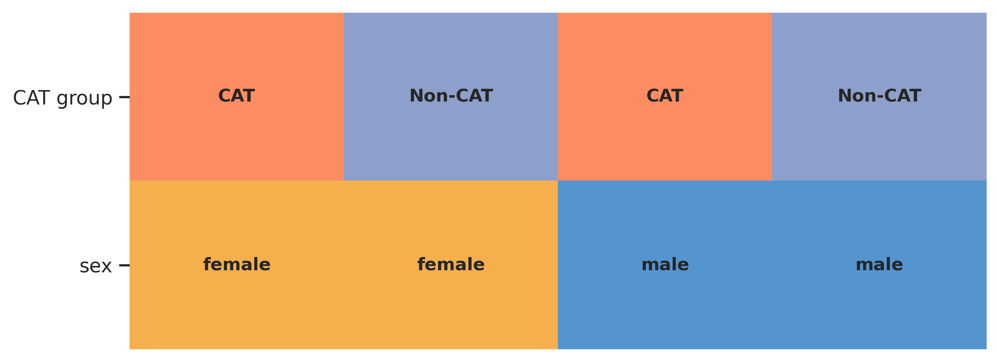

In [181]:
# Define colors for annotations
sex_colors = {'female': '#F5AF4DFF', 'male': '#5495CFFF'}
cat_colors = {'CAT': sns.color_palette("Set2")[1], 'Non-CAT': sns.color_palette("Set2")[2]}

# Create annotation DataFrame
annot_Df = pd.DataFrame(
    index=['CAT group', 'sex'], 
    data=[['CAT', 'Non-CAT', 'CAT', 'Non-CAT'], 
          ['female', 'female', 'male', 'male']]
)

# Create a numeric matrix for the heatmap (using the category mappings)
# Map categories to colors
cat_map = {'CAT': 0, 'Non-CAT': 1}
sex_map = {'female': 0, 'male': 1}

# Create numeric data for heatmap
numeric_data = pd.DataFrame(index=annot_Df.index, columns=annot_Df.columns)
numeric_data.loc['CAT group'] = annot_Df.loc['CAT group'].map(cat_map)
numeric_data.loc['sex'] = annot_Df.loc['sex'].map(sex_map)

# Create the figure
fig, ax = plt.subplots(figsize=(8, 3))

# Create color matrices for each row
cat_row_colors = [cat_colors[val] for val in annot_Df.loc['CAT group']]
sex_row_colors = [sex_colors[val] for val in annot_Df.loc['sex']]

# Convert hex colors to RGB if needed
from matplotlib.colors import to_rgb

cat_row_colors_rgb = [to_rgb(c) if isinstance(c, str) else c for c in cat_row_colors]
sex_row_colors_rgb = [to_rgb(c) if isinstance(c, str) else c for c in sex_row_colors]

# Combine into a 2D array with shape (2, 4, 3) for RGB
color_matrix = np.array([cat_row_colors_rgb, sex_row_colors_rgb])

# Create the heatmap using imshow for direct color control
ax.imshow(color_matrix, aspect='auto', interpolation='nearest')

# Set labels
ax.set_yticks([0, 1])
ax.set_yticklabels(['CAT group', 'sex'])
# ax.set_xticks(range(4))
# ax.set_xticklabels([f'Sample {i+1}' for i in range(4)])
ax.set_xticklabels([])
ax.tick_params(axis='x', length=0) 

for spine in ax.spines:
    ax.spines[spine].set_visible(False)

# Add text annotations
for i in range(2):
    for j in range(4):
        text = annot_Df.iloc[i, j]
        ax.text(j, i, text, ha='center', va='center', fontsize=10, fontweight='bold')

# plt.title('Annotation Heatmap', fontsize=12, fontweight='bold', pad=10)
plt.tight_layout()

# Save the figure
plt.savefig(f'{figure5PicFolder}/heatmap__annotation__cat_sex.pdf', dpi=300, bbox_inches='tight')

plt.show()

In [214]:
adata_headBody.obs['nervousSystem'] = pd.Categorical(
    ['nervous system' if ctBroad in ['CNS neuron', 'PNS neuron', 'sensory neuron', 'glial cell'] else 'other cell' for ctBroad in adata_headBody.obs.rapamycin_annotation_broad])

In [215]:
adata_headBody.obs['nervousSystem'].value_counts()

nervousSystem
other cell        283636
nervous system    222095
Name: count, dtype: int64

In [216]:
ct2NervousSys_D = dict(zip(adata_headBody.obs.rapamycin_annotation, adata_headBody.obs.nervousSystem))

In [217]:
value_to_int={'nervous system':0, 'other cell': 1}
n = len(value_to_int)    

In [218]:
cmap=sns.color_palette("Set3", 8) # Pastel2
cmap

[(0.5529411764705883, 0.8274509803921568, 0.7803921568627451),
 (1.0, 1.0, 0.7019607843137254),
 (0.7450980392156863, 0.7294117647058823, 0.8549019607843137),
 (0.984313725490196, 0.5019607843137255, 0.4470588235294118),
 (0.5019607843137255, 0.6941176470588235, 0.8274509803921568),
 (0.9921568627450981, 0.7058823529411765, 0.3843137254901961),
 (0.7019607843137254, 0.8705882352941177, 0.4117647058823529),
 (0.9882352941176471, 0.803921568627451, 0.8980392156862745)]

In [221]:
df=pd.DataFrame( [{ct: value_to_int[ct2NervousSys_D[ct]] for ct in order_L}] )
df

,adult fat body_body,follicle cell,male accessory gland main cell_roX1+,enterocyte of anterior adult midgut epithelium,adult oenocyte,pericerebral adult fat mass,choriogenic main body follicle cell and corpus luteum,ejaculatory bulb,adult ventral nervous system,female reproductive system,...,distal medullary amacrine neuron Dm8,optic-lobe-associated cortex glial cell,auditory sensory neuron,centrifugal neuron C2,neuron 1,photoreceptor cell R7,neuron 2,neuron 5,neuron 6,transmedullary neuron Tm9
0,1,1,1,1,1,1,1,1,0,1,...,0,0,0,0,0,0,0,0,0,0


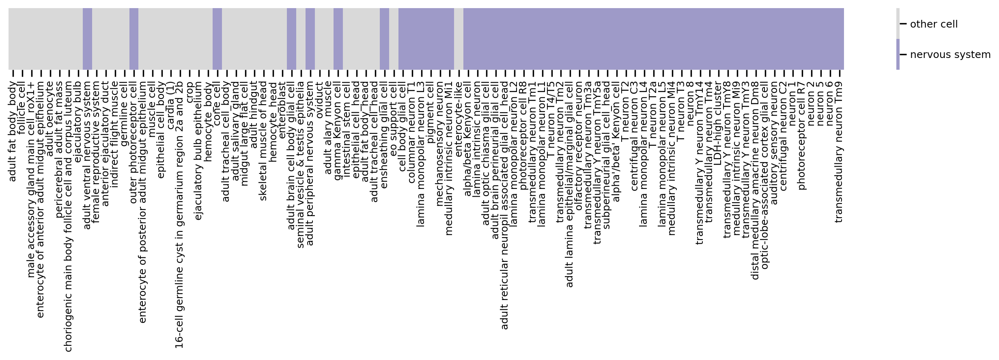

In [224]:
plt.figure(figsize=(16.5, 1))
parameters = {'xtick.labelsize': 9,'ytick.labelsize': 9, 'legend.fontsize':9}
plt.rcParams.update(parameters)

# ax = sns.heatmap(df, cmap=[cmap[0], cmap[5]], xticklabels=True ) # [cmap[4], cmap[6]]
ax = sns.heatmap(df, cmap=['#9e9ac8', '#d9d9d9'], xticklabels=True ) # [cmap[4], cmap[6]]
colorbar=ax.collections[0].colorbar
r = colorbar.vmax - colorbar.vmin 
colorbar.set_ticks([colorbar.vmin + r / n * (0.5 + i) for i in range(n)])
colorbar.set_ticklabels(value_to_int.keys()) #not in the right order # sorted(list(value_to_int.keys()))

plt.ylabel('')
plt.yticks([])

plt.savefig(f'{figure2PicFolder}/barplot__degN_long_Df__nervousSystem.pdf', bbox_inches='tight')

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data f

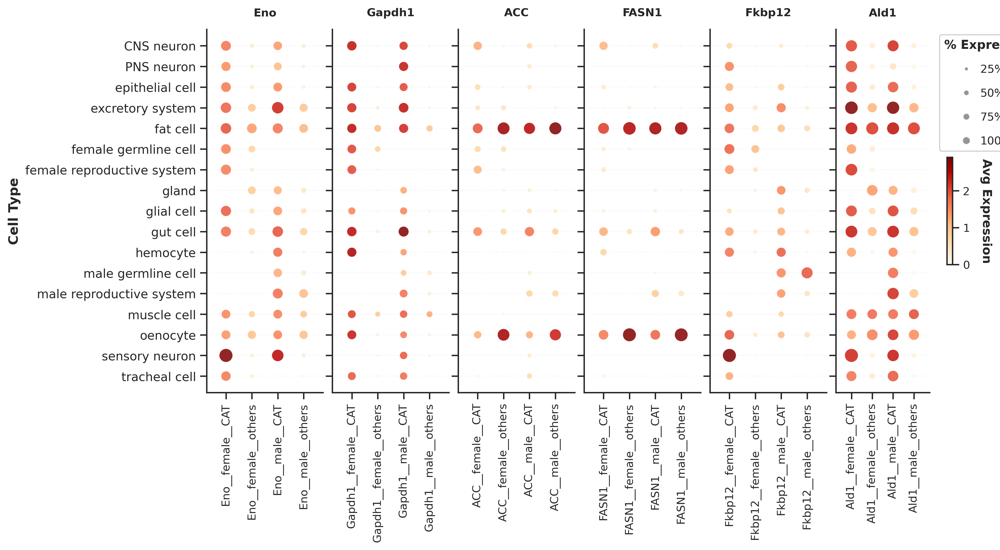

In [159]:
# FIXED PARAMETERS
FIXED_VMIN_PCT = 0.0
FIXED_VMAX_PCT = 1.0
FIXED_VMIN_EXP = 0.0
FIXED_VMAX_EXP = exp_pct_Df.aveExp.max()
FIXED_SIZE_MIN = 2
FIXED_SIZE_MAX = 150

# Color setup for custom legend
cmap = plt.cm.OrRd
norm = plt.Normalize(vmin=FIXED_VMIN_EXP, vmax=FIXED_VMAX_EXP)

# 
exp_pct_Df_clean = exp_pct_Df.copy()
# exp_pct_Df_clean[['aveExp', 'pct']] = exp_pct_Df_clean[['aveExp', 'pct']].fillna(0)


fig, axs = plt.subplots(1, 6, figsize=(12, 6), 
                        gridspec_kw={'wspace': 0.08})

for n, gene in enumerate(selectGenes_L):
    gene_data = exp_pct_Df_clean[exp_pct_Df_clean['gene'] == gene].copy()
    # gene_data = gene_data.sort_values('annotation')
    
    scatter = sns.scatterplot(
        data=gene_data,
        x='gene_sex_CAT',
        y='annotation',
        size='pct',
        hue='aveExp',
        palette='OrRd',
        vmin=FIXED_VMIN_EXP,
        vmax=FIXED_VMAX_EXP,
        sizes=(FIXED_SIZE_MIN, FIXED_SIZE_MAX), 
        size_norm=plt.Normalize(FIXED_VMIN_PCT, FIXED_VMAX_PCT),
        alpha=0.85,
        linewidth=0.5,
        edgecolor='white',
        ax=axs[n],
        legend=False  # Turn off automatic legend
    )

    # Styling
    axs[n].set_xlabel('')
    axs[n].set_title(gene, fontsize=10, fontweight='bold', pad=12)
    axs[n].tick_params(axis='x', rotation=90, labelsize=10)
    axs[n].margins(x=0.25, y=0.05)
    axs[n].grid(axis='y', alpha=0.2, linestyle='--', linewidth=0.5)
    
    # Y-axis (only show labels on first panel)
    if n == 0:
        axs[n].set_ylabel('Cell Type', fontsize=12, fontweight='bold')
    else:
        axs[n].set_ylabel('')
        axs[n].set_yticklabels([])
        
#     # # Add separator line
#     # if n < len(selectGenes_L) - 1:
#     #     axs[n].axvline(x=axs[n].get_xlim()[1], color='gray', 
#     #                   linewidth=1.5, alpha=0.3)
    
    # Clean spines
    axs[n].spines['top'].set_visible(False)
    axs[n].spines['right'].set_visible(False)
    
#     # # Alternating background
#     # colors = ['#f7f7f7', '#ffffff']
#     # axs[n].set_facecolor(colors[n % 2])
        
    
# Add custom legends to last panel
ax_legend = axs[-1]

# Size legend (% expressed)
size_values = [0.25, 0.5, 0.75, 1.0]
size_handles = []
for size_val in size_values:
    size_points = FIXED_SIZE_MIN + (FIXED_SIZE_MAX - FIXED_SIZE_MIN) * size_val
    handle = plt.Line2D([0], [0], marker='o', color='w', 
                       markerfacecolor='gray', markersize=np.sqrt(size_points/3),
                       alpha=0.8, linestyle='')
    size_handles.append(handle)

size_legend = ax_legend.legend(size_handles, 
                              [f'{int(v*100)}%' for v in size_values],
                              title='% Expressed',
                              loc='upper left',
                              bbox_to_anchor=(1.05, 1.0),
                              frameon=True,
                              fontsize=10,
                              title_fontsize=11,
                              handletextpad=1,
                              labelspacing=1.2)
size_legend.get_title().set_fontweight('bold')
ax_legend.add_artist(size_legend)

# Color legend (average expression)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax_legend, pad=0.15, aspect=20, 
                    fraction=0.046)
cbar.set_label('Avg Expression', fontsize=11, fontweight='bold', rotation=270, labelpad=20)
cbar.ax.tick_params(labelsize=10)


plt.tight_layout()
    
plt.show()


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/relational.py:573: UserWarning: No data f

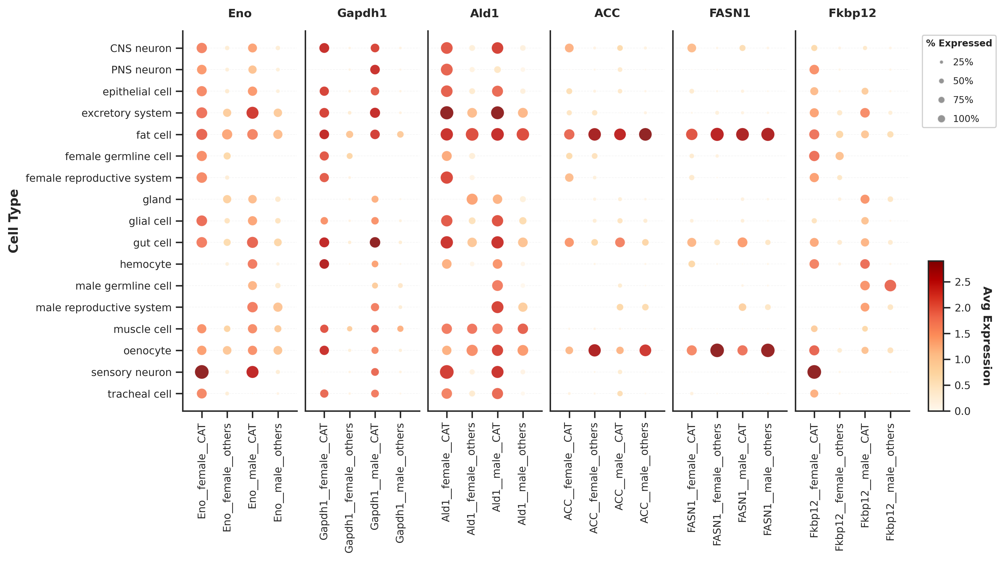

In [106]:
# FIXED PARAMETERS
FIXED_VMIN_PCT = 0.0
FIXED_VMAX_PCT = 1.0
FIXED_VMIN_EXP = 0.0
FIXED_VMAX_EXP = exp_pct_Df.aveExp.max()
FIXED_SIZE_MIN = 2
FIXED_SIZE_MAX = 150

# Color setup for custom legend
cmap = plt.cm.OrRd
norm = plt.Normalize(vmin=FIXED_VMIN_EXP, vmax=FIXED_VMAX_EXP)

# Clean data
exp_pct_Df_clean = exp_pct_Df.copy()

# ============================================================================
# KEY CHANGE: Create 7 subplots instead of 6 (6 genes + 1 dedicated for legend)
# ============================================================================
fig, axs = plt.subplots(1, 7, figsize=(12, 6), 
                        gridspec_kw={'wspace': 0.08, 
                                    'width_ratios': [1, 1, 1, 1, 1, 1, 0.4]})

# Plot genes in FIRST 6 AXES only
for n, gene in enumerate(selectGenes_L):
    gene_data = exp_pct_Df_clean[exp_pct_Df_clean['gene'] == gene].copy()
    
    scatter = sns.scatterplot(
        data=gene_data,
        x='gene_sex_CAT',
        y='annotation',
        size='pct',
        hue='aveExp',
        palette='OrRd',
        vmin=FIXED_VMIN_EXP,
        vmax=FIXED_VMAX_EXP,
        sizes=(FIXED_SIZE_MIN, FIXED_SIZE_MAX), 
        size_norm=plt.Normalize(FIXED_VMIN_PCT, FIXED_VMAX_PCT),
        alpha=0.85,
        linewidth=0.5,
        edgecolor='white',
        ax=axs[n],  # Use axs[n], NOT axs[-1]
        legend=False
    )

    # Styling
    axs[n].set_xlabel('')
    axs[n].set_title(gene, fontsize=10, fontweight='bold', pad=12)
    axs[n].tick_params(axis='x', rotation=90, labelsize=9)
    axs[n].margins(x=0.25, y=0.05)
    axs[n].grid(axis='y', alpha=0.2, linestyle='--', linewidth=0.5)
    
    # Y-axis (only show labels on first panel)
    if n == 0:
        axs[n].set_ylabel('Cell Type', fontsize=11, fontweight='bold')
        axs[n].tick_params(axis='y', labelsize=9)
    else:
        axs[n].set_ylabel('')
        axs[n].set_yticklabels([])
        axs[n].tick_params(axis='y', length=0)
    
    # Clean spines
    axs[n].spines['top'].set_visible(False)
    axs[n].spines['right'].set_visible(False)

# ============================================================================
# LEGENDS ON THE 7TH AXIS (index 6)
# ============================================================================
ax_legend = axs[6]  # The 7th subplot
ax_legend.axis('off')  # Turn off axis lines and ticks

# Size legend (% expressed)
size_values = [0.25, 0.5, 0.75, 1.0]
size_handles = []
for size_val in size_values:
    size_points = FIXED_SIZE_MIN + (FIXED_SIZE_MAX - FIXED_SIZE_MIN) * size_val
    handle = plt.Line2D([0], [0], marker='o', color='w', 
                       markerfacecolor='gray', markersize=np.sqrt(size_points/3),
                       alpha=0.8, linestyle='')
    size_handles.append(handle)

size_legend = ax_legend.legend(size_handles, 
                              [f'{int(v*100)}%' for v in size_values],
                              title='% Expressed',
                              loc='upper left',
                              bbox_to_anchor=(0, 1.0),
                              frameon=True,
                              fontsize=8,
                              title_fontsize=8,
                              handletextpad=1,
                              labelspacing=1.05)
size_legend.get_title().set_fontweight('bold')
ax_legend.add_artist(size_legend)

# Color legend (average expression)
# Create a new axes for the colorbar within the figure
cbar_ax = fig.add_axes([0.925, 0.15, 0.015, 0.3])  # [left, bottom, width, height]
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, cax=cbar_ax)
cbar.set_label('Avg Expression', fontsize=10, fontweight='bold', 
              rotation=270, labelpad=18)
cbar.ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()

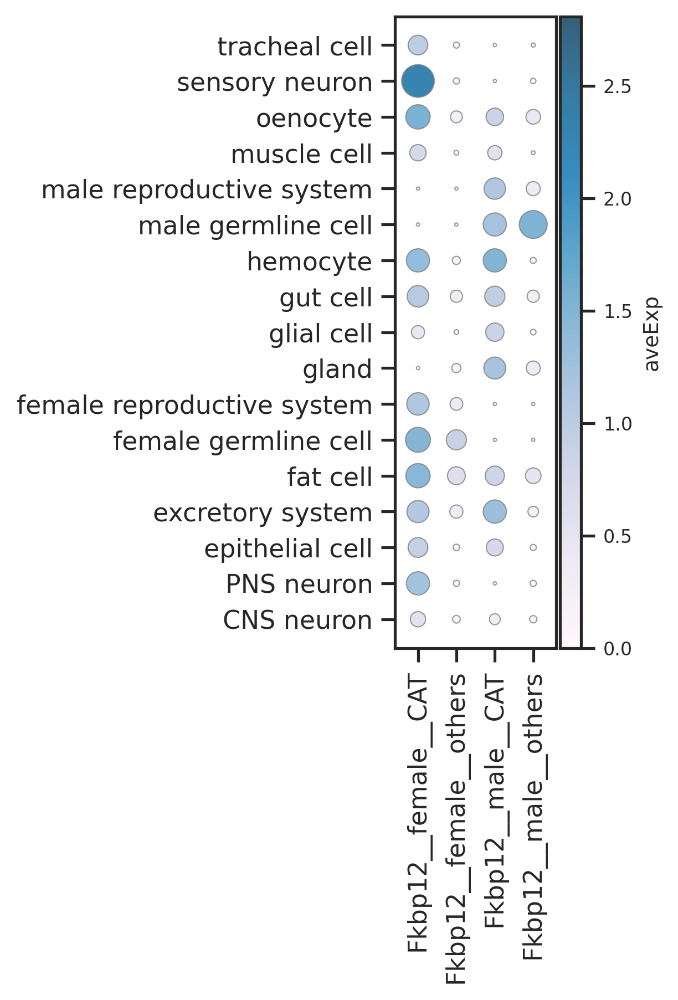

In [161]:
gene_data = exp_pct_Df_clean[exp_pct_Df_clean['gene'] == 'Fkbp12'].copy()
gene_data = gene_data.sort_values('annotation')

# with rc_context({'figure.figsize': (1, 5)}):
fig, ax = plt.subplots(figsize=(1.5, 5))

# sns.scatterplot(
#     x=gene_data['gene_sex_CAT'],
#     y=gene_data['annotation'],
#     s=gene_data['pct'] * (FIXED_SIZE_MAX - FIXED_SIZE_MIN) + FIXED_SIZE_MIN,
#     c=gene_data['aveExp'],
#     cmap='PuBu',
#     vmin=FIXED_VMIN_EXP,
#     vmax=FIXED_VMAX_EXP,
#     alpha=0.8,
#     # edgecolors='gray',
#     linewidth=0.5
# )

scatter= ax.scatter(
    x=gene_data['gene_sex_CAT'],
    y=gene_data['annotation'],
    s=gene_data['pct'] * (FIXED_SIZE_MAX - FIXED_SIZE_MIN) + FIXED_SIZE_MIN,
    c=gene_data['aveExp'],
    cmap='PuBu',
    vmin=FIXED_VMIN_EXP,
    vmax=FIXED_VMAX_EXP,
    alpha=0.8,
    edgecolors='gray',
    linewidth=0.5
)

# plt.legend(bbox_to_anchor=(1, 1.0))
# plt.margins(x=0.1, y=0.2)
plt.xlabel('')
plt.ylabel('')
plt.xticks(rotation=90,)
# plt.title('Differential expression of Nrx-1\nupon Rapamycin treatment')
plt.margins(x=0.2,)

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax, pad=0.02, aspect=30)
if idx == n_genes - 1:
    cbar.set_label('aveExp', fontsize=10, fontweight='bold')
else:
    cbar.set_label('aveExp', fontsize=9)
cbar.ax.tick_params(labelsize=8)

# plt.savefig(f'{figure4PicFolder}/dotplot__VNC__Nrx1__deg.pdf', bbox_inches='tight')
plt.show()
    

In [93]:
adata_body.obs.drop('Fkbp12', axis=1, inplace=True)

In [94]:
adata_body.obs['Fkbp12_Expression'] = adata_body[:, 'Fkbp12'].X.todense()

In [96]:
obs = adata_body.obs[~adata_body.obs.rapamycin_annotation_broad.isin(['cardial cell', 'unannotated'])]
obs.rapamycin_annotation_broad = pd.Categorical(obs.rapamycin_annotation_broad, categories= ct_L)

<ipython-input-96-7dffb79b5272>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  obs.rapamycin_annotation_broad = pd.Categorical(obs.rapamycin_annotation_broad, categories= ct_L)


/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


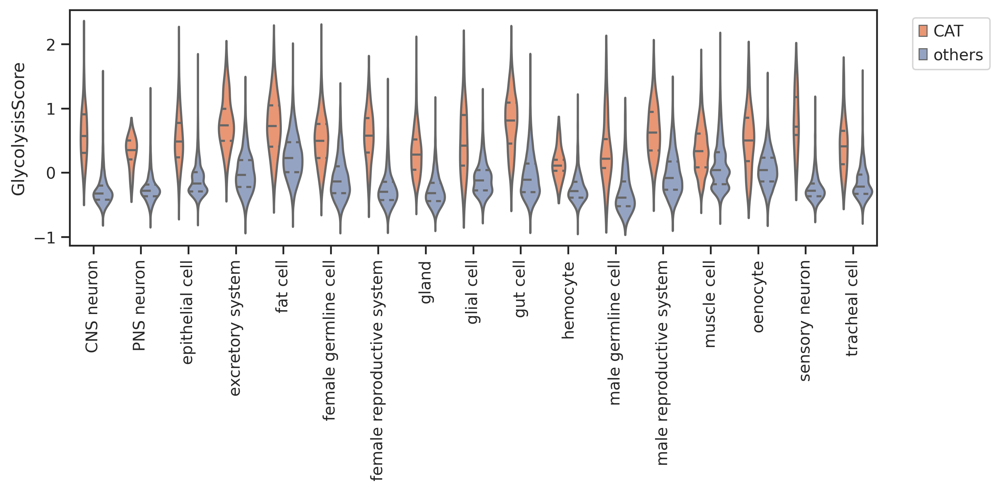

In [97]:
with rc_context({'figure.figsize': (10, 3) }):
    sns.violinplot(data=obs, x='rapamycin_annotation_broad', y='GlycolysisScore', hue='CAT_group', inner='quartile', palette=cmap)
    plt.xticks(rotation=90,)
    plt.legend(bbox_to_anchor=(1.15, 1.0))
    plt.xlabel('')
    
    plt.savefig(f'{figure5PicFolder}/violin__adata_body__GlycolysisScore__CAT_group__broad.pdf')

In [108]:
adata_body.obs['broad__CAT_group'] = pd.Categorical( adata_body.obs.rapamycin_annotation_broad.astype(str) + '_' + adata_body.obs.CAT_group.astype(str) )

adata_body.obs['annot__CAT_group'] = pd.Categorical( adata_body.obs.rapamycin_annotation.astype(str) + '_' + adata_body.obs.CAT_group.astype(str) )

In [100]:
adata_body

AnnData object with n_obs × n_vars = 238034 × 15919
    obs: 'latent_RT_efficiency', 'latent_cell_probability', 'latent_scale', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'dataset', 'age', 'sex', 'tissue', 'condition', 'leiden', 'linearR_annotation', 'condAge', 'condSex', 'ageSex', 'condAgeSex', 'condAgeSexTissue', 'leiden_1.0', 'leiden_2.0', 'leiden_3.0', 'leiden_4.0', 'leiden_5.0', 'leiden_6.0', 'leiden_7.0', 'leiden_8.0', 'leiden_9.0', 'leiden_10.0', 'leiden_1.5', 'treatment', 'treatAge', 'treatAgeSex', 'treatSex', 'rapamycin_annotation', 'rapamycin_annotation_subcluster', 'rapamycin_annotation_broad', 'rapamycin_annotation_group', 'sharedAgingAve_up', 'sharedAgingAve_down', 'sharedAgingAve_upMinusDown', 'CAT_score', 'CAT_group', 'GlycolysisScore', 'LipidSynScore', 'broad__CAT_group', 'Fkbp12_Expression'
    var: 'gene_ids', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'CAT_group_colors', 'annotation_rapamycin_colors

Dotplot visualization is not good. Find other approaches to present the results

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:169: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:179: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds

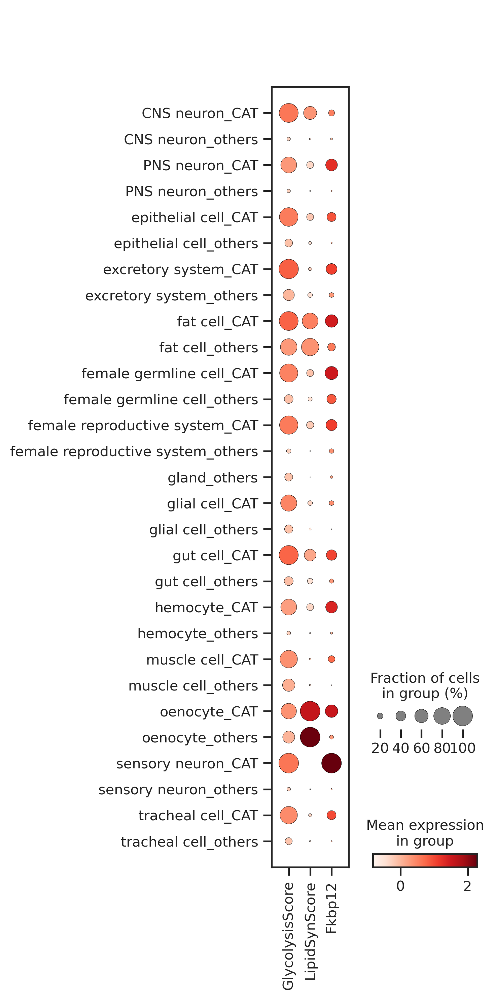

In [118]:
sc.pl.dotplot(adata_body[ (~adata_body.obs.rapamycin_annotation_broad.isin(['cardial cell', 'unannotated'])) & (adata_body.obs.sex == 'female') ], var_names=['GlycolysisScore', 'LipidSynScore', 'Fkbp12'], groupby=['broad__CAT_group'])

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:169: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:179: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds

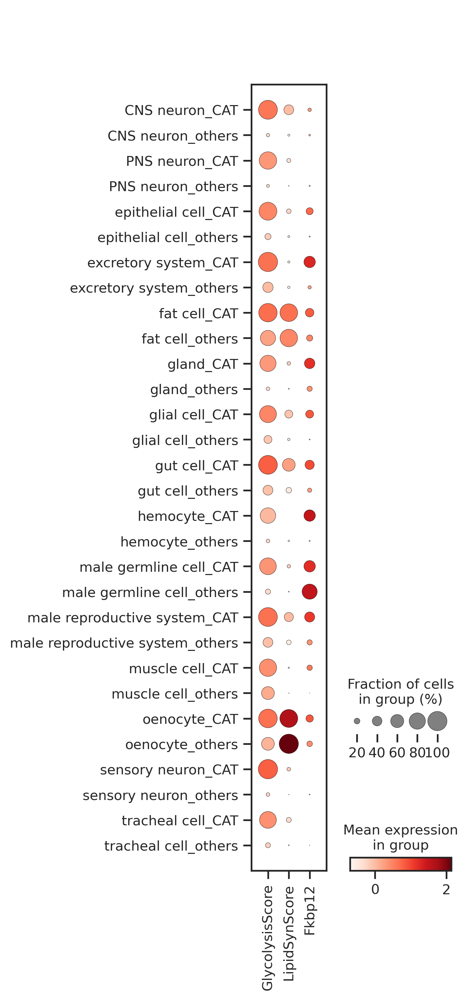

In [130]:
sc.pl.dotplot(adata_body[ (~adata_body.obs.rapamycin_annotation_broad.isin(['cardial cell', 'unannotated'])) & (adata_body.obs.sex == 'male') ], var_names=['GlycolysisScore', 'LipidSynScore', 'Fkbp12'], groupby=['broad__CAT_group'])

In [72]:
adata_body[adata_body.obs.rapamycin_annotation_broad == 'gut cell']

View of AnnData object with n_obs × n_vars = 24743 × 15919
    obs: 'latent_RT_efficiency', 'latent_cell_probability', 'latent_scale', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'dataset', 'age', 'sex', 'tissue', 'condition', 'leiden', 'linearR_annotation', 'condAge', 'condSex', 'ageSex', 'condAgeSex', 'condAgeSexTissue', 'leiden_1.0', 'leiden_2.0', 'leiden_3.0', 'leiden_4.0', 'leiden_5.0', 'leiden_6.0', 'leiden_7.0', 'leiden_8.0', 'leiden_9.0', 'leiden_10.0', 'leiden_1.5', 'treatment', 'treatAge', 'treatAgeSex', 'treatSex', 'rapamycin_annotation', 'rapamycin_annotation_subcluster', 'rapamycin_annotation_broad', 'rapamycin_annotation_group', 'sharedAgingAve_up', 'sharedAgingAve_down', 'sharedAgingAve_upMinusDown', 'CAT_score', 'CAT_group'
    var: 'gene_ids', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'CAT_group_colors', 'annotation_rapamycin_colors', 'hvg', 'leiden', 'linearR_annotation_colors', 'log1p', 'neighbors',

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcor

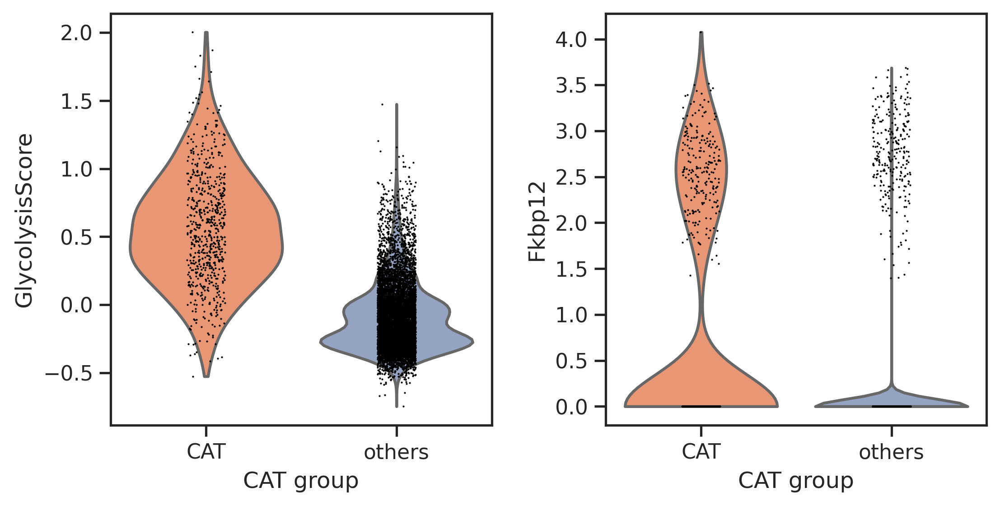

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/seaborn/_oldcor

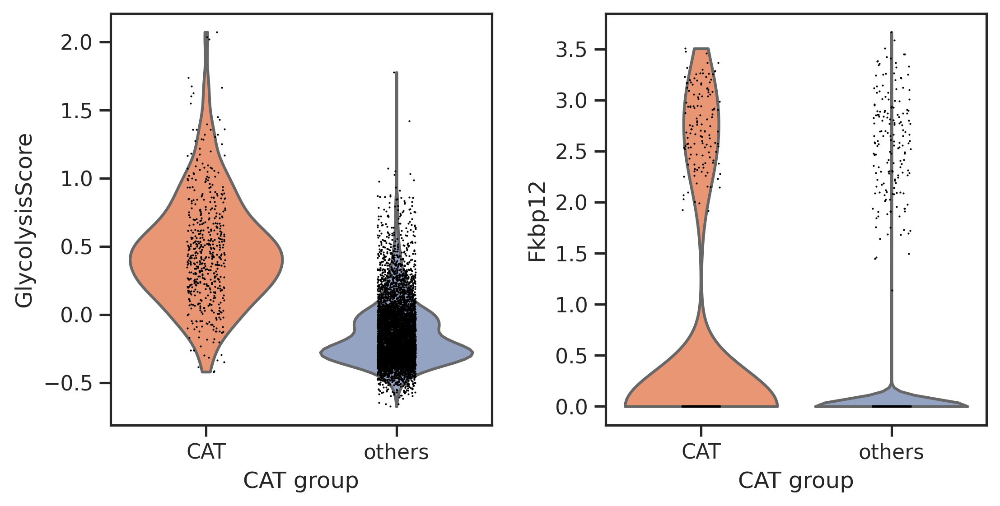

In [129]:
sc.pl.violin(adata_body[ (adata_body.obs.rapamycin_annotation_broad == 'epithelial cell') & (adata_body.obs.sex == 'female') ], keys=['GlycolysisScore', 'Fkbp12'], groupby='CAT_group')
sc.pl.violin(adata_body[ (adata_body.obs.rapamycin_annotation_broad == 'epithelial cell') & (adata_body.obs.sex == 'male') ], keys=['GlycolysisScore', 'Fkbp12'], groupby='CAT_group')

/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:169: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:179: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/data/tcl/miniconda3/envs/scvi/lib/python3.9/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds

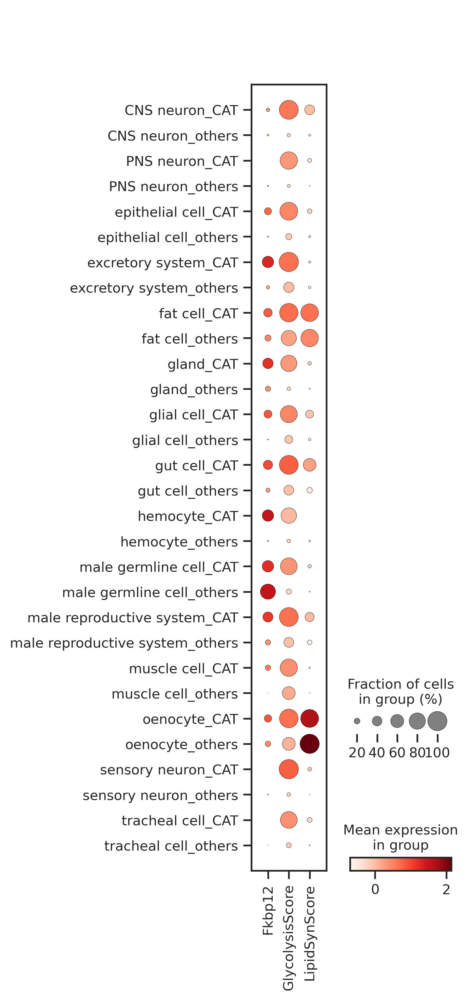

In [117]:
sc.pl.dotplot(adata_body[ (~adata_body.obs.rapamycin_annotation_broad.isin(['cardial cell', 'unannotated'])) & (adata_body.obs.sex == 'male') ], var_names=['GlycolysisScore', 'LipidSynScore', 'Fkbp12'], groupby=['broad__CAT_group'])

# Expression of CAT marker

## Load files

In [34]:
adata_body = sc.read(f'{figure5Folder}/adata_body__CAT_score__CAT_group.h5ad')
adata_head = sc.read(f'{figure5Folder}/adata_head__CAT_score__CAT_group.h5ad')

/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/anndata/__init__.py:42: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/anndata/__init__.py:42: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(


In [35]:
# merge roX1+ and roX1-
adata_body.obs.rapamycin_annotation = pd.Categorical([ 'male accessory gland main cell' if 'roX1' in annot else annot for annot in adata_body.obs.rapamycin_annotation ])

In [36]:
adata_body.obs['sex__CAT_group'] = pd.Categorical(adata_body.obs.sex.astype(str) + '_' + adata_body.obs.CAT_group.astype(str))
adata_head.obs['sex__CAT_group'] = pd.Categorical(adata_head.obs.sex.astype(str) + '_' + adata_head.obs.CAT_group.astype(str))

adata_head.obs['annot_sex__CAT_group'] = pd.Categorical(adata_head.obs.rapamycin_annotation.astype(str) + '__' + adata_head.obs.sex.astype(str) + '__' + adata_head.obs.CAT_group.astype(str))
adata_head.obs['broad_sex__CAT_group'] = pd.Categorical(adata_head.obs.rapamycin_annotation_broad.astype(str) + '__' + adata_head.obs.sex.astype(str) + '__' + adata_head.obs.CAT_group.astype(str))

adata_body.obs['annot_sex__CAT_group'] = pd.Categorical(adata_body.obs.rapamycin_annotation.astype(str) + '__' + adata_body.obs.sex.astype(str) + '__' + adata_body.obs.CAT_group.astype(str))
adata_body.obs['broad_sex__CAT_group'] = pd.Categorical(adata_body.obs.rapamycin_annotation_broad.astype(str) + '__' + adata_body.obs.sex.astype(str) + '__' + adata_body.obs.CAT_group.astype(str))


adata_body.obs.sex__CAT_group.cat.categories

Index(['female_CAT', 'female_others', 'male_CAT', 'male_others'], dtype='object')

In [37]:
adata_headBody = adata_head.concatenate(adata_body, join='outer')
adata_headBody.obs_names = [obs[:-2] for obs in adata_headBody.obs_names]

/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn/T/ipykernel_63962/2525953110.py:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata_headBody = adata_head.concatenate(adata_body, join='outer')


## dotplot

/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:169: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:179: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **k

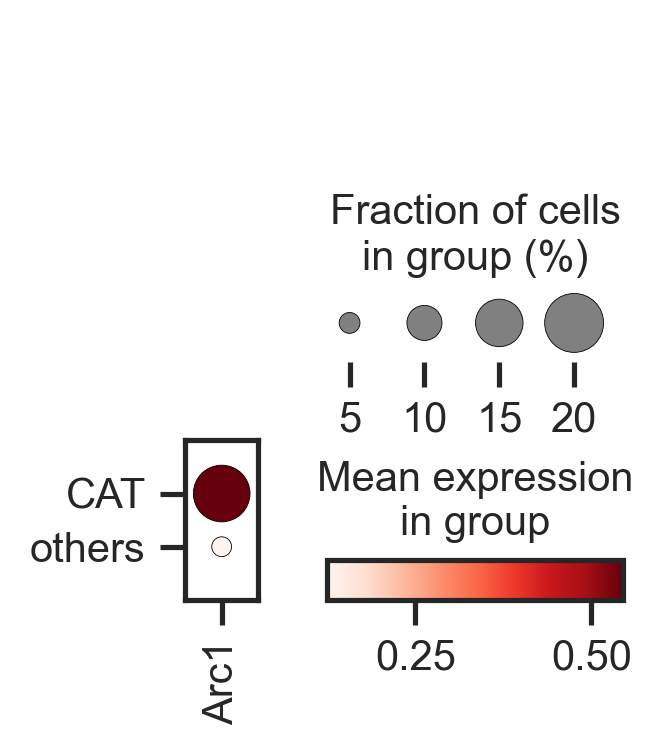

In [38]:
sc.pl.dotplot(adata_body[~adata_body.obs.age.isin(['70'])], var_names=['Arc1'], groupby='CAT_group', #dot_max=0.50,
              # save=f'__adata_germline__glycolysisLipid_fraction50.pdf',
             )

/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:169: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:179: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **k

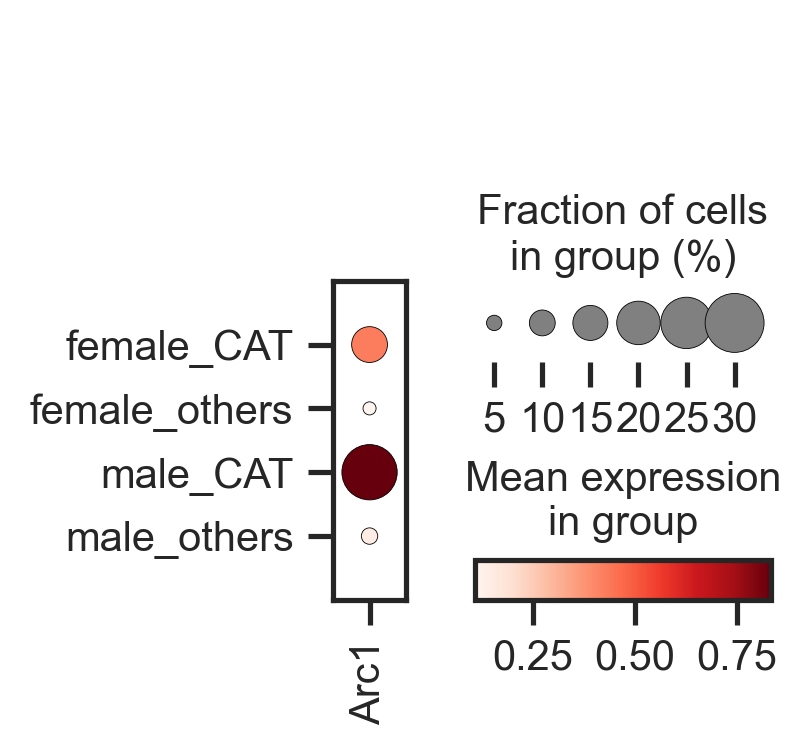

In [39]:
sc.pl.dotplot(adata_body[~adata_body.obs.age.isin(['70'])], var_names=['Arc1', ], groupby='sex__CAT_group', #dot_max=0.50,
              # save=f'__adata_germline__glycolysisLipid_fraction50.pdf',
             )

/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:169: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:179: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **k

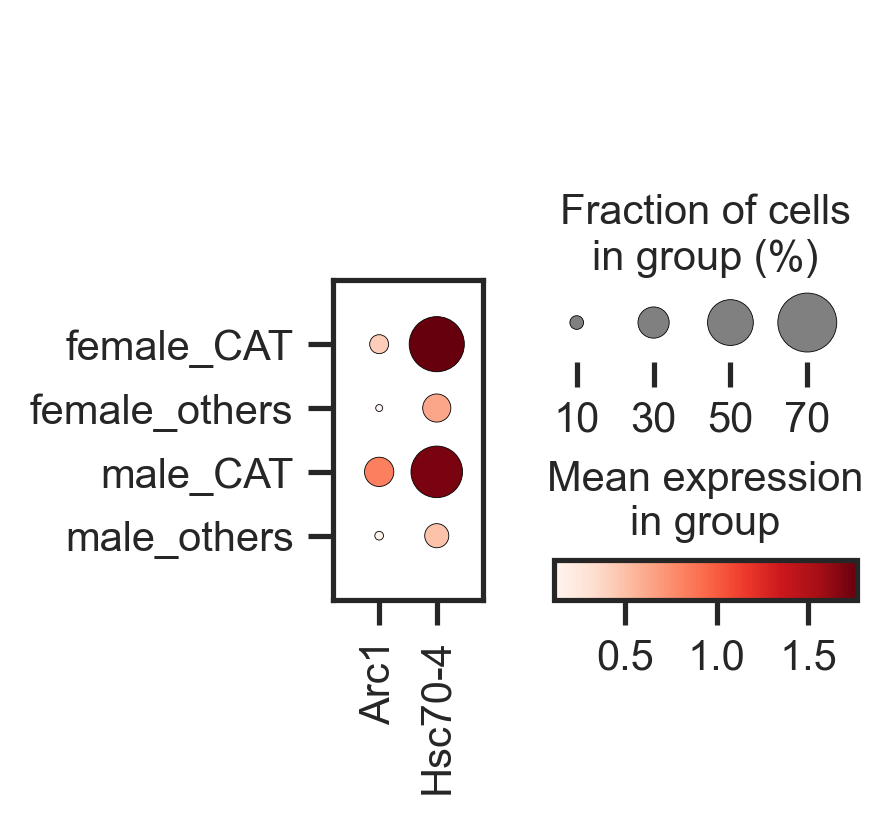

In [40]:
sc.pl.dotplot(adata_body[~adata_body.obs.age.isin(['70'])], var_names=['Arc1', 'Hsc70-4',], groupby='sex__CAT_group', #dot_max=0.50,
              # save=f'__adata_germline__glycolysisLipid_fraction50.pdf',
             )

/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:169: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:179: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:749: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **k

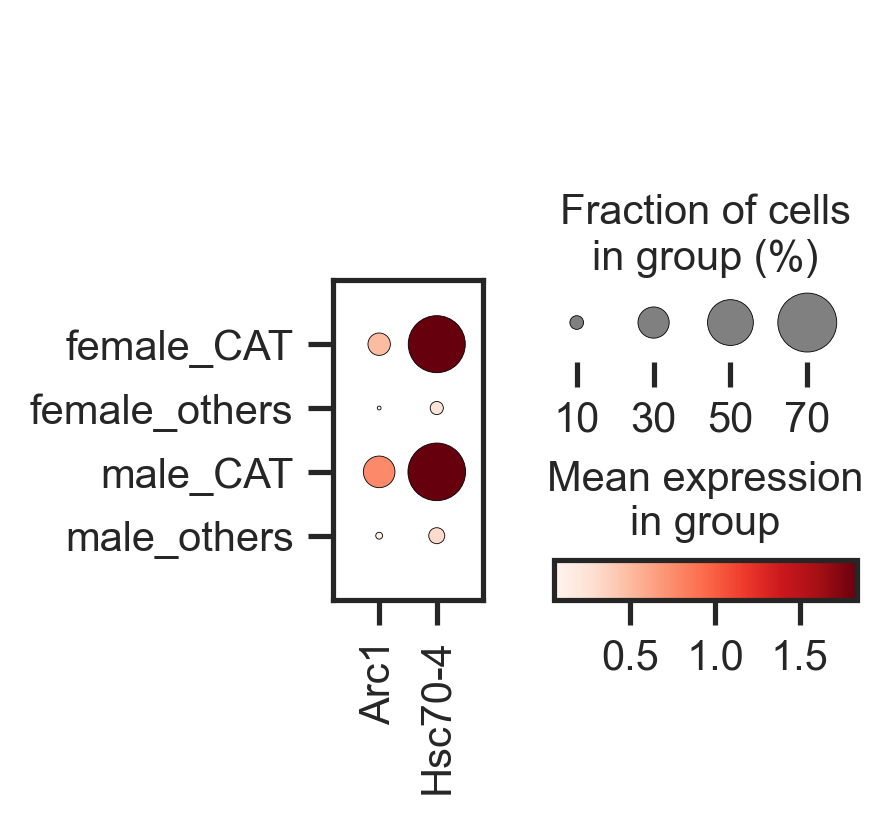

In [41]:
sc.pl.dotplot(adata_head[~adata_head.obs.age.isin(['70'])], var_names=['Arc1', 'Hsc70-4',], groupby='sex__CAT_group', #dot_max=0.50,
              # save=f'__adata_germline__glycolysisLipid_fraction50.pdf',
             )

## Calculate glycolysis score in different CAT groups

In [42]:
degN_mtx  = pd.read_csv(f'Analysis/Figure/Figure2/degSummary/degN_mtx_treatAgeSex_compareToControl_cellN700.csv', index_col=0)
degN_mtx.sort_values(by='totalDegN', ascending=False, inplace=True)
degN_mtx_100 = degN_mtx[degN_mtx.totalDegN > 100]
degN_mtx_100

,Rapamycin_30_female vs. Control_30_female,Rapamycin_50_female vs. Control_50_female,Rapamycin_70_female vs. Control_70_female,Rapamycin_30_male vs. Control_30_male,Rapamycin_50_male vs. Control_50_male,Rapamycin_70_male vs. Control_70_male,totalDegN
adult fat body_body,727,1185,891,460,1243,1169,5675
enterocyte of anterior adult midgut epithelium,974,629,98,20,1063,455,3239
adult oenocyte,473,441,323,215,1013,632,3097
pericerebral adult fat mass,464,454,641,416,200,781,2956
follicle cell,577,1065,555,0,0,0,2197
male accessory gland main cell_roX1+,0,0,0,317,806,543,1666
adult ventral nervous system,895,307,15,52,315,1,1585
indirect flight muscle,352,280,0,350,147,7,1136
choriogenic main body follicle cell and corpus luteum,440,441,172,0,0,0,1053
ejaculatory bulb,0,0,0,216,539,109,864


In [43]:
degN_mtx_100.index.to_list().index('male accessory gland main cell_roX1+')

5

In [44]:
degN_mtx_100.rename(index = {'male accessory gland main cell_roX1+': 'male accessory gland main cell'}, inplace = True)
degNindex_L = degN_mtx_100.index.to_list()
degNindex_L[5] = 'male accessory gland main cell'
degN_mtx_100

/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn/T/ipykernel_63962/2209994111.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  degN_mtx_100.rename(index = {'male accessory gland main cell_roX1+': 'male accessory gland main cell'}, inplace = True)


,Rapamycin_30_female vs. Control_30_female,Rapamycin_50_female vs. Control_50_female,Rapamycin_70_female vs. Control_70_female,Rapamycin_30_male vs. Control_30_male,Rapamycin_50_male vs. Control_50_male,Rapamycin_70_male vs. Control_70_male,totalDegN
adult fat body_body,727,1185,891,460,1243,1169,5675
enterocyte of anterior adult midgut epithelium,974,629,98,20,1063,455,3239
adult oenocyte,473,441,323,215,1013,632,3097
pericerebral adult fat mass,464,454,641,416,200,781,2956
follicle cell,577,1065,555,0,0,0,2197
male accessory gland main cell,0,0,0,317,806,543,1666
adult ventral nervous system,895,307,15,52,315,1,1585
indirect flight muscle,352,280,0,350,147,7,1136
choriogenic main body follicle cell and corpus luteum,440,441,172,0,0,0,1053
ejaculatory bulb,0,0,0,216,539,109,864


In [45]:
ratio_Df = pd.read_csv(f'{figure5Folder}/ratio_Df.csv', index_col=0)
ratio_Df

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089,NaN,NaN,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.065934,0.460870,0.222727,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.000000,0.039216,0.121951,0.333333,0.181818,0.000000,0.000000,0.015038,0.197802,0.047170
crop,0.041534,0.059028,0.036638,0.307042,0.094139,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000479,0.170732,0.019380,0.277520,0.284598,0.000000,0.008673,0.008594,0.052448,0.180915
cardia (1),0.000000,0.000000,0.010753,0.255814,0.010204,0.007194,0.000000,0.000000,0.036145,0.040984
skeletal muscle of head,0.047525,0.265385,0.278607,0.186620,0.227373,0.114130,0.358400,0.501441,0.488372,0.419580
epithelial cell_body,0.011250,0.076923,0.025943,0.120290,0.068251,0.019856,0.047722,0.067568,0.110126,0.068210
adult tracheal cell_body,0.001344,0.020134,0.002681,0.086420,0.009245,0.000000,0.000000,0.002646,0.007220,0.004484
16-cell germline cyst in germarium region 2a and 2b,0.005618,0.013986,0.008368,0.049180,0.078853,NaN,NaN,NaN,NaN,NaN


## Gene list: 3 CAT genes

### select genes

In [46]:
adata_select = adata_headBody[adata_headBody.obs.rapamycin_annotation.isin(degN_mtx_100.index.to_list())]
adata_select.obs.rapamycin_annotation = pd.Categorical(adata_select.obs.rapamycin_annotation , categories=ratio_Df.index.to_list())
adata_select.obs['annot_sex__CAT_group'] = pd.Categorical(adata_select.obs.rapamycin_annotation.astype(str) + '__' + adata_select.obs.sex.astype(str) + '__' + adata_select.obs.CAT_group.astype(str))
adata_select.obs['broad_sex__CAT_group'] = pd.Categorical(adata_select.obs.rapamycin_annotation_broad.astype(str) + '__' + adata_select.obs.sex.astype(str) + '__' + adata_select.obs.CAT_group.astype(str))
adata_select

/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/pandas/core/generic.py:6351: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self[name] = value


AnnData object with n_obs × n_vars = 271841 × 15919
    obs: 'latent_RT_efficiency', 'latent_cell_probability', 'latent_scale', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'dataset', 'age', 'sex', 'tissue', 'condition', 'leiden', 'linearR_annotation', 'condAge', 'condSex', 'ageSex', 'condAgeSex', 'condAgeSexTissue', 'leiden_1.0', 'leiden_2.0', 'leiden_3.0', 'leiden_4.0', 'leiden_5.0', 'leiden_6.0', 'leiden_7.0', 'leiden_8.0', 'leiden_9.0', 'leiden_10.0', 'leiden_1.5', 'treatment', 'treatAge', 'treatAgeSex', 'treatSex', 'rapamycin_annotation', 'rapamycin_annotation_broad', 'rapamycin_annotation_subcluster', 'rapamycin_annotation_group', 'sharedAgingAve_up', 'sharedAgingAve_down', 'sharedAgingAve_upMinusDown', 'CAT_score', 'CAT_group', 'sex__CAT_group', 'annot_sex__CAT_group', 'broad_sex__CAT_group', 'batch'
    var: 'gene_ids', 'highly_variable-0', 'means-0', 'dispersions-0', 'dispersions_norm-0', 'highly_variable-1', 'means-1', 'dispersions-1', '

In [47]:
adata_headBody.obs['broad_sex__CAT_group'] = pd.Categorical(adata_headBody.obs.rapamycin_annotation_broad.astype(str) + '__' + adata_select.obs.sex.astype(str) + '__' + adata_select.obs.CAT_group.astype(str))

In [48]:
sns.color_palette("deep")

[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725),
 (0.8666666666666667, 0.5176470588235295, 0.3215686274509804),
 (0.3333333333333333, 0.6588235294117647, 0.40784313725490196),
 (0.7686274509803922, 0.3058823529411765, 0.3215686274509804),
 (0.5058823529411764, 0.4470588235294118, 0.7019607843137254),
 (0.5764705882352941, 0.47058823529411764, 0.3764705882352941),
 (0.8549019607843137, 0.5450980392156862, 0.7647058823529411),
 (0.5490196078431373, 0.5490196078431373, 0.5490196078431373),
 (0.8, 0.7254901960784313, 0.4549019607843137),
 (0.39215686274509803, 0.7098039215686275, 0.803921568627451)]

In [49]:
cmap = list(sns.color_palette("tab10"))[:2]
# cmap = list(sns.color_palette("Set2"))[1:3]

In [52]:
cat_L = ['Arc1', 'Hsc70-4', 'Tctp']

In [53]:
geneDict_D = {'CAT': cat_L,}

In [54]:
geneDict_D.values()

dict_values([['Arc1', 'Hsc70-4', 'Tctp']])

In [55]:
allGenes = [gene for geneList in list(geneDict_D.values()) for gene in geneList  ]
allGenes

['Arc1', 'Hsc70-4', 'Tctp']

In [56]:
selectGenes_L = ['Arc1', 'Hsc70-4', 'Tctp']

In [57]:
geneDictSelect_D = {'CAT': cat_L,}

### Calculate aveExp & percentage

In [58]:
clusters = adata_select.obs['annot_sex__CAT_group'].cat.categories
obs = adata_select[:,selectGenes_L].X.toarray()
obs = pd.DataFrame(obs,columns=selectGenes_L,index=adata_select.obs['annot_sex__CAT_group'])
average_obs = obs.groupby(level=0).mean()
obs_bool = obs.astype(bool)
fraction_obs = obs_bool.groupby(level=0).sum()/obs_bool.groupby(level=0).count()

# # output
# average_obs.T.to_csv("average.csv")
# fraction_obs.T.to_csv("fraction.csv")

/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn/T/ipykernel_63962/2218739892.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  average_obs = obs.groupby(level=0).mean()
/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn/T/ipykernel_63962/2218739892.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fraction_obs = obs_bool.groupby(level=0).sum()/obs_bool.groupby(level=0).count()


In [59]:
average_obs

,Arc1,Hsc70-4,Tctp
annot_sex__CAT_group,,,
16-cell germline cyst in germarium region 2a and 2b__female__CAT,0.049185,2.178273,2.165968
16-cell germline cyst in germarium region 2a and 2b__female__others,0.021474,0.982608,1.126862
adult fat body_body__female__CAT,0.204777,2.127038,2.242271
adult fat body_body__female__others,0.043751,1.331215,0.411530
adult fat body_body__male__CAT,0.268631,1.852975,1.897094
...,...,...,...
pericerebral adult fat mass__male__others,0.030234,0.941276,0.474715
skeletal muscle of head__female__CAT,1.117503,1.800200,2.082687
skeletal muscle of head__female__others,0.406591,0.394769,0.181036


In [60]:
obs

,Arc1,Hsc70-4,Tctp
annot_sex__CAT_group,,,
pericerebral adult fat mass__female__others,0.0,0.000000,1.948376
pericerebral adult fat mass__female__others,0.0,2.382807,0.000000
pericerebral adult fat mass__female__others,0.0,2.087397,0.000000
outer photoreceptor cell__female__others,0.0,0.000000,0.000000
pericerebral adult fat mass__female__others,0.0,0.000000,0.000000
...,...,...,...
hemocyte_body__male__others,0.0,0.000000,0.000000
epithelial cell_body__male__others,0.0,0.000000,3.478646
epithelial cell_body__male__others,0.0,0.000000,0.000000


In [61]:
fraction_obs

,Arc1,Hsc70-4,Tctp
annot_sex__CAT_group,,,
16-cell germline cyst in germarium region 2a and 2b__female__CAT,0.018519,0.833333,0.814815
16-cell germline cyst in germarium region 2a and 2b__female__others,0.009189,0.440000,0.484865
adult fat body_body__female__CAT,0.078853,0.759857,0.781362
adult fat body_body__female__others,0.020367,0.594618,0.195535
adult fat body_body__male__CAT,0.100917,0.692661,0.706422
...,...,...,...
pericerebral adult fat mass__male__others,0.014254,0.439212,0.229318
skeletal muscle of head__female__CAT,0.410798,0.640845,0.715962
skeletal muscle of head__female__others,0.139837,0.143089,0.066125


In [62]:
exp_pct_Df = pd.DataFrame(columns=['geneAnnotSexCat', 'annotSexCat', 'gene', 'annotation', 'sex', 'CAT_group', 'aveExp', 'pct'])

for gene in selectGenes_L:
    for ct in degNindex_L:
        for sex in ['female', 'male']:
            for catGroup in ['CAT', 'others']:
                geneAnnotSexCat=f'{gene}__{ct}__{sex}__{catGroup}'
                annotSexCat=f'{ct}__{sex}__{catGroup}'
                # print(geneAnnotSexCat,)
                # print(annotSexCat)
                
                if annotSexCat in average_obs.index.to_list():
                    exp = average_obs.loc[annotSexCat, gene]
                    pct= fraction_obs.loc[annotSexCat, gene]
                else: exp, pct = np.nan, np.nan
                
                exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
                
                
# exp_pct_Df

/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn/T/ipykernel_63962/57712639.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn/T/ipykernel_63962/57712639.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn

In [63]:
exp_pct_Df

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct
0,Arc1__adult fat body_body__female__CAT,adult fat body_body__female__CAT,Arc1,adult fat body_body,female,CAT,0.204777,0.078853
1,Arc1__adult fat body_body__female__others,adult fat body_body__female__others,Arc1,adult fat body_body,female,others,0.043751,0.020367
2,Arc1__adult fat body_body__male__CAT,adult fat body_body__male__CAT,Arc1,adult fat body_body,male,CAT,0.268631,0.100917
3,Arc1__adult fat body_body__male__others,adult fat body_body__male__others,Arc1,adult fat body_body,male,others,0.014305,0.005853
4,Arc1__enterocyte of anterior adult midgut epit...,enterocyte of anterior adult midgut epithelium...,Arc1,enterocyte of anterior adult midgut epithelium,female,CAT,0.122907,0.047619
...,...,...,...,...,...,...,...,...
355,Tctp__hemocyte_head__male__others,hemocyte_head__male__others,Tctp,hemocyte_head,male,others,0.062436,0.026110
356,Tctp__enteroblast__female__CAT,enteroblast__female__CAT,Tctp,enteroblast,female,CAT,NaN,NaN
357,Tctp__enteroblast__female__others,enteroblast__female__others,Tctp,enteroblast,female,others,0.088665,0.036602
358,Tctp__enteroblast__male__CAT,enteroblast__male__CAT,Tctp,enteroblast,male,CAT,3.092393,1.000000


In [64]:
categories_L = [f'{gene}__{sex}__{cat}' for gene in selectGenes_L for sex in ['female', 'male'] for cat in ['CAT', 'others']]
categories_L

['Arc1__female__CAT',
 'Arc1__female__others',
 'Arc1__male__CAT',
 'Arc1__male__others',
 'Hsc70-4__female__CAT',
 'Hsc70-4__female__others',
 'Hsc70-4__male__CAT',
 'Hsc70-4__male__others',
 'Tctp__female__CAT',
 'Tctp__female__others',
 'Tctp__male__CAT',
 'Tctp__male__others']

In [65]:
ratio_Df = pd.read_csv(f'{figure5Folder}/ratio_Df.csv', index_col=0)
ratio_Df.head()

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089,NaN,NaN,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.065934,0.460870,0.222727,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.000000,0.039216,0.121951,0.333333,0.181818,0.000000,0.000000,0.015038,0.197802,0.047170
crop,0.041534,0.059028,0.036638,0.307042,0.094139,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000479,0.170732,0.019380,0.277520,0.284598,0.000000,0.008673,0.008594,0.052448,0.180915


In [66]:
exp_pct_Df.loc[:,'gene_sex_CAT'] = pd.Categorical(exp_pct_Df.gene.astype(str)+'__'+exp_pct_Df.sex.astype(str)+'__'+exp_pct_Df.CAT_group.astype(str), categories=categories_L) # 

exp_pct_Df

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct,gene_sex_CAT
0,Arc1__adult fat body_body__female__CAT,adult fat body_body__female__CAT,Arc1,adult fat body_body,female,CAT,0.204777,0.078853,Arc1__female__CAT
1,Arc1__adult fat body_body__female__others,adult fat body_body__female__others,Arc1,adult fat body_body,female,others,0.043751,0.020367,Arc1__female__others
2,Arc1__adult fat body_body__male__CAT,adult fat body_body__male__CAT,Arc1,adult fat body_body,male,CAT,0.268631,0.100917,Arc1__male__CAT
3,Arc1__adult fat body_body__male__others,adult fat body_body__male__others,Arc1,adult fat body_body,male,others,0.014305,0.005853,Arc1__male__others
4,Arc1__enterocyte of anterior adult midgut epit...,enterocyte of anterior adult midgut epithelium...,Arc1,enterocyte of anterior adult midgut epithelium,female,CAT,0.122907,0.047619,Arc1__female__CAT
...,...,...,...,...,...,...,...,...,...
355,Tctp__hemocyte_head__male__others,hemocyte_head__male__others,Tctp,hemocyte_head,male,others,0.062436,0.026110,Tctp__male__others
356,Tctp__enteroblast__female__CAT,enteroblast__female__CAT,Tctp,enteroblast,female,CAT,NaN,NaN,Tctp__female__CAT
357,Tctp__enteroblast__female__others,enteroblast__female__others,Tctp,enteroblast,female,others,0.088665,0.036602,Tctp__female__others
358,Tctp__enteroblast__male__CAT,enteroblast__male__CAT,Tctp,enteroblast,male,CAT,3.092393,1.000000,Tctp__male__CAT


In [67]:
exp_pct_Df.gene_sex_CAT.cat.categories

Index(['Arc1__female__CAT', 'Arc1__female__others', 'Arc1__male__CAT',
       'Arc1__male__others', 'Hsc70-4__female__CAT', 'Hsc70-4__female__others',
       'Hsc70-4__male__CAT', 'Hsc70-4__male__others', 'Tctp__female__CAT',
       'Tctp__female__others', 'Tctp__male__CAT', 'Tctp__male__others'],
      dtype='object')

In [68]:
exp_pct_Df.annotation = pd.Categorical(exp_pct_Df.annotation, categories=ratio_Df.index.to_list())

/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/seaborn/relational.py:438: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/seaborn/relational.py:438: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)
/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/seaborn/relational.py:438: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored
  points = ax.scatter(x=x, y=y, **kws)


AttributeError: Line2D.set() got an unexpected keyword argument 'vmin'

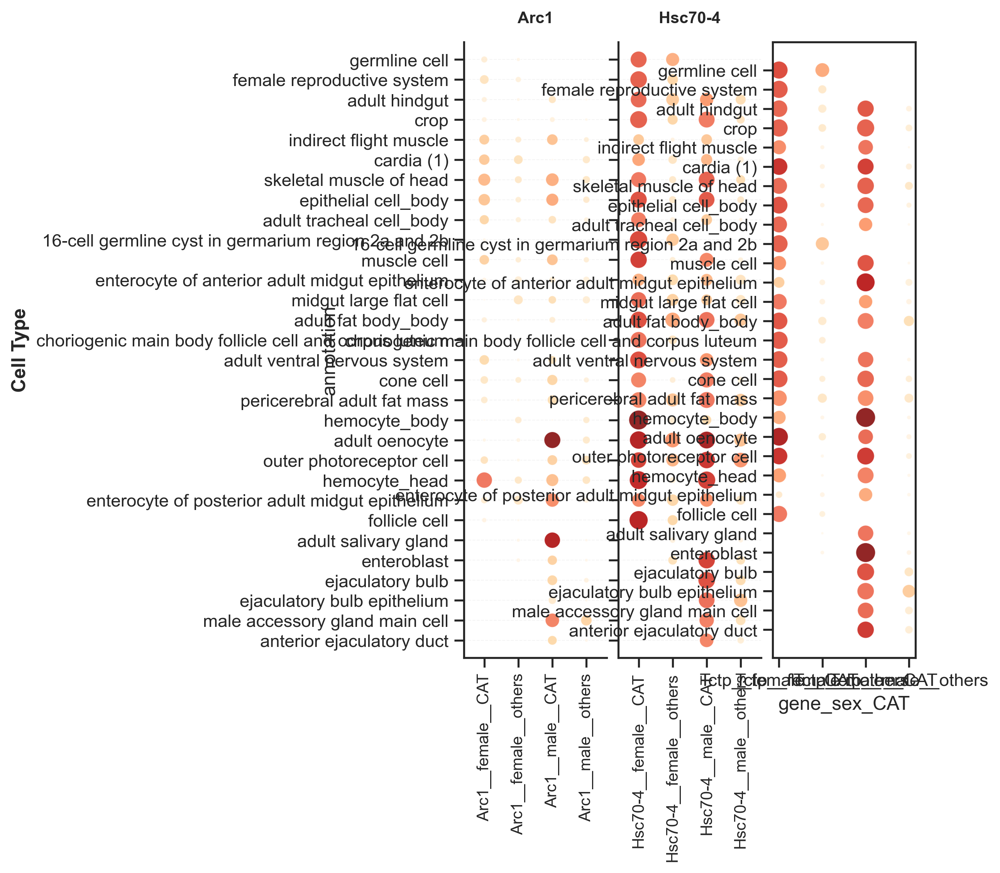

In [69]:
# FIXED PARAMETERS
FIXED_VMIN_PCT = 0.0
FIXED_VMAX_PCT = 1.0
FIXED_VMIN_EXP = 0.0
FIXED_VMAX_EXP = exp_pct_Df.aveExp.max()
FIXED_SIZE_MIN = 2
FIXED_SIZE_MAX = 150

# Color setup for custom legend
cmap = plt.cm.OrRd
norm = plt.Normalize(vmin=FIXED_VMIN_EXP, vmax=FIXED_VMAX_EXP)

# 
exp_pct_Df_clean = exp_pct_Df.copy()
# exp_pct_Df_clean[['aveExp', 'pct']] = exp_pct_Df_clean[['aveExp', 'pct']].fillna(0)


fig, axs = plt.subplots(1, 3, figsize=(5, 7), 
                        gridspec_kw={'wspace': 0.08})

for n, gene in enumerate(selectGenes_L):
    gene_data = exp_pct_Df_clean[exp_pct_Df_clean['gene'] == gene].copy()
    # gene_data = gene_data.sort_values('annotation')
    
    # gene_data.annotation = pd.Categorical(gene_data.annotation, categories=degNindex_L)
    scatter = sns.scatterplot(
        data=gene_data,
        x='gene_sex_CAT',
        y='annotation',
        size='pct',
        hue='aveExp',
        palette='OrRd',
        vmin=FIXED_VMIN_EXP,
        vmax=FIXED_VMAX_EXP,
        sizes=(FIXED_SIZE_MIN, FIXED_SIZE_MAX), 
        size_norm=plt.Normalize(FIXED_VMIN_PCT, FIXED_VMAX_PCT),
        alpha=0.85,
        linewidth=0.5,
        edgecolor='white',
        ax=axs[n],
        hue_order=degNindex_L,
        legend=(n == 2)  # Turn off automatic legend
    )

    # Optional: fine-tune legend position
    if n == 2 and axs[n].get_legend():
        axs[n].get_legend().set_bbox_to_anchor((1.02, 1.0))
    
        # axs[n].legend(bbox_to_anchor=(1.1, 1.0))

    # Styling
    axs[n].set_xlabel('')
    axs[n].set_title(gene, fontsize=10, fontweight='bold', pad=12)
    axs[n].tick_params(axis='x', rotation=90, labelsize=10)
    axs[n].margins(x=0.2, y=0.03)
    axs[n].grid(axis='y', alpha=0.2, linestyle='--', linewidth=0.5)
    
    # Y-axis (only show labels on first panel)
    if n == 0:
        axs[n].set_ylabel('Cell Type', fontsize=12, fontweight='bold')
    else:
        axs[n].set_ylabel('')
        axs[n].set_yticklabels([])
        
#     # # Add separator line
#     # if n < len(selectGenes_L) - 1:
#     #     axs[n].axvline(x=axs[n].get_xlim()[1], color='gray', 
#     #                   linewidth=1.5, alpha=0.3)
    
    # Clean spines
    axs[n].spines['top'].set_visible(False)
    axs[n].spines['right'].set_visible(False)
    
    # # legend position
    # if n = 5:
    #     axs[n].spines['right'].set_visible(False)
    
plt.tight_layout()

# plt.savefig(f'{figure5PicFolder}/dotplot__cat_sex__glycolysis_lipid_Fkbp12__OrRd.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [85]:
selectGenes_L

['Arc1', 'Hsc70-4', 'Tctp']

0
1
2


/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn/T/ipykernel_63962/2977312160.py:80: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


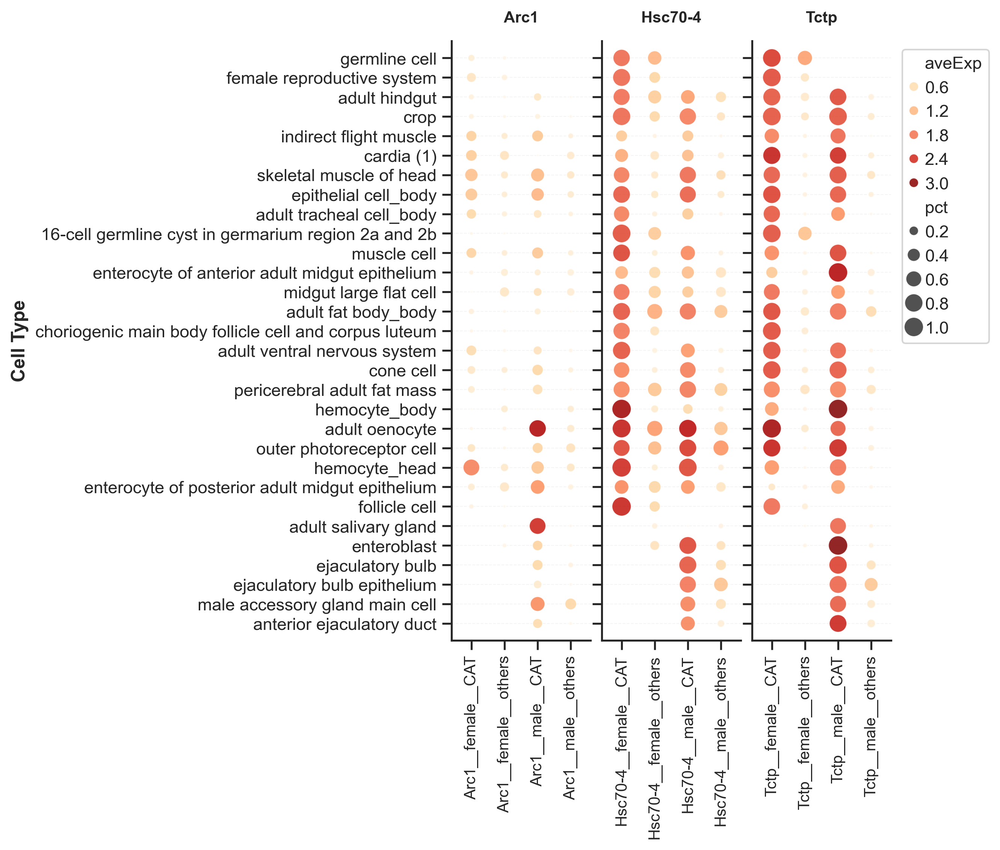

In [72]:
# FIXED PARAMETERS
FIXED_VMIN_PCT = 0.0
FIXED_VMAX_PCT = 0.9
FIXED_VMIN_EXP = 0.0
FIXED_VMAX_EXP = exp_pct_Df.aveExp.max()
FIXED_SIZE_MIN = 2
FIXED_SIZE_MAX = 150

# Color setup for custom legend
cmap = plt.cm.OrRd
norm = plt.Normalize(vmin=FIXED_VMIN_EXP, vmax=FIXED_VMAX_EXP)

# 
exp_pct_Df_clean = exp_pct_Df.copy()
# exp_pct_Df_clean[['aveExp', 'pct']] = exp_pct_Df_clean[['aveExp', 'pct']].fillna(0)


fig, axs = plt.subplots(1, 3, figsize=(5, 7), 
                        gridspec_kw={'wspace': 0.08})

for n, gene in enumerate(selectGenes_L):
    print(n)
    gene_data = exp_pct_Df_clean[exp_pct_Df_clean['gene'] == gene].copy()
    # gene_data = gene_data.sort_values('annotation')
    
    # gene_data.annotation = pd.Categorical(gene_data.annotation, categories=degNindex_L)
    scatter = sns.scatterplot(
        data=gene_data,
        x='gene_sex_CAT',
        y='annotation',
        size='pct',
        hue='aveExp',
        palette='OrRd',
        hue_norm=plt.Normalize(vmin=FIXED_VMIN_EXP,vmax=FIXED_VMAX_EXP),
        # vmin=FIXED_VMIN_EXP,
        # vmax=FIXED_VMAX_EXP,
        sizes=(FIXED_SIZE_MIN, FIXED_SIZE_MAX), 
        size_norm=plt.Normalize(FIXED_VMIN_PCT, FIXED_VMAX_PCT),
        alpha=0.85,
        linewidth=0.5,
        edgecolor='white',
        ax=axs[n],
        hue_order=degNindex_L,
        legend=(n == 2)  # Turn off automatic legend
    )

    # Optional: fine-tune legend position
    if n == 2 and axs[n].get_legend():
        axs[n].get_legend().set_bbox_to_anchor((1.02, 1.0))
    
        # axs[n].legend(bbox_to_anchor=(1.1, 1.0))

    # Styling
    axs[n].set_xlabel('')
    axs[n].set_title(gene, fontsize=10, fontweight='bold', pad=12)
    axs[n].tick_params(axis='x', rotation=90, labelsize=10)
    axs[n].margins(x=0.2, y=0.03)
    axs[n].grid(axis='y', alpha=0.2, linestyle='--', linewidth=0.5)
    
    # Y-axis (only show labels on first panel)
    if n == 0:
        axs[n].set_ylabel('Cell Type', fontsize=12, fontweight='bold')
    else:
        axs[n].set_ylabel('')
        axs[n].set_yticklabels([])
        
#     # # Add separator line
#     # if n < len(selectGenes_L) - 1:
#     #     axs[n].axvline(x=axs[n].get_xlim()[1], color='gray', 
#     #                   linewidth=1.5, alpha=0.3)
    
    # Clean spines
    axs[n].spines['top'].set_visible(False)
    axs[n].spines['right'].set_visible(False)
    
    # # legend position
    # if n = 5:
    #     axs[n].spines['right'].set_visible(False)
    
plt.tight_layout()
    
plt.savefig(f'{figure5PicFolder}/dotplot__cat_sex__Arc1_Hsc70-4_Tctp_GnBu.pdf', dpi=300, bbox_inches='tight')
plt.show()

## Gene list: 1 CAT gene

### select genes

In [46]:
adata_select = adata_headBody[adata_headBody.obs.rapamycin_annotation.isin(degN_mtx_100.index.to_list())]
adata_select.obs.rapamycin_annotation = pd.Categorical(adata_select.obs.rapamycin_annotation , categories=ratio_Df.index.to_list())
adata_select.obs['annot_sex__CAT_group'] = pd.Categorical(adata_select.obs.rapamycin_annotation.astype(str) + '__' + adata_select.obs.sex.astype(str) + '__' + adata_select.obs.CAT_group.astype(str))
adata_select.obs['broad_sex__CAT_group'] = pd.Categorical(adata_select.obs.rapamycin_annotation_broad.astype(str) + '__' + adata_select.obs.sex.astype(str) + '__' + adata_select.obs.CAT_group.astype(str))
adata_select

/opt/miniconda3/envs/scanpy193/lib/python3.10/site-packages/pandas/core/generic.py:6351: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  self[name] = value


AnnData object with n_obs × n_vars = 271841 × 15919
    obs: 'latent_RT_efficiency', 'latent_cell_probability', 'latent_scale', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'dataset', 'age', 'sex', 'tissue', 'condition', 'leiden', 'linearR_annotation', 'condAge', 'condSex', 'ageSex', 'condAgeSex', 'condAgeSexTissue', 'leiden_1.0', 'leiden_2.0', 'leiden_3.0', 'leiden_4.0', 'leiden_5.0', 'leiden_6.0', 'leiden_7.0', 'leiden_8.0', 'leiden_9.0', 'leiden_10.0', 'leiden_1.5', 'treatment', 'treatAge', 'treatAgeSex', 'treatSex', 'rapamycin_annotation', 'rapamycin_annotation_broad', 'rapamycin_annotation_subcluster', 'rapamycin_annotation_group', 'sharedAgingAve_up', 'sharedAgingAve_down', 'sharedAgingAve_upMinusDown', 'CAT_score', 'CAT_group', 'sex__CAT_group', 'annot_sex__CAT_group', 'broad_sex__CAT_group', 'batch'
    var: 'gene_ids', 'highly_variable-0', 'means-0', 'dispersions-0', 'dispersions_norm-0', 'highly_variable-1', 'means-1', 'dispersions-1', '

In [47]:
adata_headBody.obs['broad_sex__CAT_group'] = pd.Categorical(adata_headBody.obs.rapamycin_annotation_broad.astype(str) + '__' + adata_select.obs.sex.astype(str) + '__' + adata_select.obs.CAT_group.astype(str))

In [48]:
sns.color_palette("deep")

[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725),
 (0.8666666666666667, 0.5176470588235295, 0.3215686274509804),
 (0.3333333333333333, 0.6588235294117647, 0.40784313725490196),
 (0.7686274509803922, 0.3058823529411765, 0.3215686274509804),
 (0.5058823529411764, 0.4470588235294118, 0.7019607843137254),
 (0.5764705882352941, 0.47058823529411764, 0.3764705882352941),
 (0.8549019607843137, 0.5450980392156862, 0.7647058823529411),
 (0.5490196078431373, 0.5490196078431373, 0.5490196078431373),
 (0.8, 0.7254901960784313, 0.4549019607843137),
 (0.39215686274509803, 0.7098039215686275, 0.803921568627451)]

In [49]:
cmap = list(sns.color_palette("tab10"))[:2]
# cmap = list(sns.color_palette("Set2"))[1:3]

In [73]:
cat_L = ['Arc1', 'Hsc70-4', 'Tctp'][:1]
cat_L

['Arc1']

In [74]:
geneDict_D = {'CAT': cat_L,}

In [75]:
geneDict_D.values()

dict_values([['Arc1']])

In [76]:
allGenes = [gene for geneList in list(geneDict_D.values()) for gene in geneList  ]
allGenes

['Arc1']

In [77]:
selectGenes_L = ['Arc1', 'Hsc70-4', 'Tctp'][:1]

In [78]:
geneDictSelect_D = {'CAT': cat_L,}

### Calculate aveExp & percentage

In [79]:
clusters = adata_select.obs['annot_sex__CAT_group'].cat.categories
obs = adata_select[:,selectGenes_L].X.toarray()
obs = pd.DataFrame(obs,columns=selectGenes_L,index=adata_select.obs['annot_sex__CAT_group'])
average_obs = obs.groupby(level=0).mean()
obs_bool = obs.astype(bool)
fraction_obs = obs_bool.groupby(level=0).sum()/obs_bool.groupby(level=0).count()

# # output
# average_obs.T.to_csv("average.csv")
# fraction_obs.T.to_csv("fraction.csv")

/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn/T/ipykernel_63962/2218739892.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  average_obs = obs.groupby(level=0).mean()
/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn/T/ipykernel_63962/2218739892.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fraction_obs = obs_bool.groupby(level=0).sum()/obs_bool.groupby(level=0).count()


In [80]:
average_obs

,Arc1
annot_sex__CAT_group,
16-cell germline cyst in germarium region 2a and 2b__female__CAT,0.049185
16-cell germline cyst in germarium region 2a and 2b__female__others,0.021474
adult fat body_body__female__CAT,0.204777
adult fat body_body__female__others,0.043751
adult fat body_body__male__CAT,0.268631
...,...
pericerebral adult fat mass__male__others,0.030234
skeletal muscle of head__female__CAT,1.117503
skeletal muscle of head__female__others,0.406591


In [81]:
obs

,Arc1
annot_sex__CAT_group,
pericerebral adult fat mass__female__others,0.0
pericerebral adult fat mass__female__others,0.0
pericerebral adult fat mass__female__others,0.0
outer photoreceptor cell__female__others,0.0
pericerebral adult fat mass__female__others,0.0
...,...
hemocyte_body__male__others,0.0
epithelial cell_body__male__others,0.0
epithelial cell_body__male__others,0.0


In [82]:
fraction_obs

,Arc1
annot_sex__CAT_group,
16-cell germline cyst in germarium region 2a and 2b__female__CAT,0.018519
16-cell germline cyst in germarium region 2a and 2b__female__others,0.009189
adult fat body_body__female__CAT,0.078853
adult fat body_body__female__others,0.020367
adult fat body_body__male__CAT,0.100917
...,...
pericerebral adult fat mass__male__others,0.014254
skeletal muscle of head__female__CAT,0.410798
skeletal muscle of head__female__others,0.139837


In [83]:
exp_pct_Df = pd.DataFrame(columns=['geneAnnotSexCat', 'annotSexCat', 'gene', 'annotation', 'sex', 'CAT_group', 'aveExp', 'pct'])

for gene in selectGenes_L:
    for ct in degNindex_L:
        for sex in ['female', 'male']:
            for catGroup in ['CAT', 'others']:
                geneAnnotSexCat=f'{gene}__{ct}__{sex}__{catGroup}'
                annotSexCat=f'{ct}__{sex}__{catGroup}'
                # print(geneAnnotSexCat,)
                # print(annotSexCat)
                
                if annotSexCat in average_obs.index.to_list():
                    exp = average_obs.loc[annotSexCat, gene]
                    pct= fraction_obs.loc[annotSexCat, gene]
                else: exp, pct = np.nan, np.nan
                
                exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
                
                
# exp_pct_Df

/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn/T/ipykernel_63962/57712639.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn/T/ipykernel_63962/57712639.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  exp_pct_Df.loc[len(exp_pct_Df)] = [geneAnnotSexCat, annotSexCat, gene, ct, sex, catGroup, exp, pct]
/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn

In [84]:
exp_pct_Df

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct
0,Arc1__adult fat body_body__female__CAT,adult fat body_body__female__CAT,Arc1,adult fat body_body,female,CAT,0.204777,0.078853
1,Arc1__adult fat body_body__female__others,adult fat body_body__female__others,Arc1,adult fat body_body,female,others,0.043751,0.020367
2,Arc1__adult fat body_body__male__CAT,adult fat body_body__male__CAT,Arc1,adult fat body_body,male,CAT,0.268631,0.100917
3,Arc1__adult fat body_body__male__others,adult fat body_body__male__others,Arc1,adult fat body_body,male,others,0.014305,0.005853
4,Arc1__enterocyte of anterior adult midgut epit...,enterocyte of anterior adult midgut epithelium...,Arc1,enterocyte of anterior adult midgut epithelium,female,CAT,0.122907,0.047619
...,...,...,...,...,...,...,...,...
115,Arc1__hemocyte_head__male__others,hemocyte_head__male__others,Arc1,hemocyte_head,male,others,0.457230,0.167972
116,Arc1__enteroblast__female__CAT,enteroblast__female__CAT,Arc1,enteroblast,female,CAT,NaN,NaN
117,Arc1__enteroblast__female__others,enteroblast__female__others,Arc1,enteroblast,female,others,0.094075,0.038674
118,Arc1__enteroblast__male__CAT,enteroblast__male__CAT,Arc1,enteroblast,male,CAT,0.815295,0.250000


In [85]:
categories_L = [f'{gene}__{sex}__{cat}' for gene in selectGenes_L for sex in ['female', 'male'] for cat in ['CAT', 'others']]
categories_L

['Arc1__female__CAT',
 'Arc1__female__others',
 'Arc1__male__CAT',
 'Arc1__male__others']

In [86]:
ratio_Df = pd.read_csv(f'{figure5Folder}/ratio_Df.csv', index_col=0)
ratio_Df.head()

,Control_7_female,Control_30_female,Rapamycin_30_female,Control_50_female,Rapamycin_50_female,Control_7_male,Control_30_male,Rapamycin_30_male,Control_50_male,Rapamycin_50_male
germline cell,0.538012,0.220132,0.247689,0.814076,0.594089,NaN,NaN,NaN,NaN,NaN
female reproductive system,0.017699,0.076087,0.065934,0.460870,0.222727,NaN,NaN,NaN,NaN,NaN
adult hindgut,0.000000,0.039216,0.121951,0.333333,0.181818,0.000000,0.000000,0.015038,0.197802,0.047170
crop,0.041534,0.059028,0.036638,0.307042,0.094139,0.121019,0.017308,0.023102,0.156627,0.063232
indirect flight muscle,0.000479,0.170732,0.019380,0.277520,0.284598,0.000000,0.008673,0.008594,0.052448,0.180915


In [87]:
exp_pct_Df.loc[:,'gene_sex_CAT'] = pd.Categorical(exp_pct_Df.gene.astype(str)+'__'+exp_pct_Df.sex.astype(str)+'__'+exp_pct_Df.CAT_group.astype(str), categories=categories_L) # 

exp_pct_Df

,geneAnnotSexCat,annotSexCat,gene,annotation,sex,CAT_group,aveExp,pct,gene_sex_CAT
0,Arc1__adult fat body_body__female__CAT,adult fat body_body__female__CAT,Arc1,adult fat body_body,female,CAT,0.204777,0.078853,Arc1__female__CAT
1,Arc1__adult fat body_body__female__others,adult fat body_body__female__others,Arc1,adult fat body_body,female,others,0.043751,0.020367,Arc1__female__others
2,Arc1__adult fat body_body__male__CAT,adult fat body_body__male__CAT,Arc1,adult fat body_body,male,CAT,0.268631,0.100917,Arc1__male__CAT
3,Arc1__adult fat body_body__male__others,adult fat body_body__male__others,Arc1,adult fat body_body,male,others,0.014305,0.005853,Arc1__male__others
4,Arc1__enterocyte of anterior adult midgut epit...,enterocyte of anterior adult midgut epithelium...,Arc1,enterocyte of anterior adult midgut epithelium,female,CAT,0.122907,0.047619,Arc1__female__CAT
...,...,...,...,...,...,...,...,...,...
115,Arc1__hemocyte_head__male__others,hemocyte_head__male__others,Arc1,hemocyte_head,male,others,0.457230,0.167972,Arc1__male__others
116,Arc1__enteroblast__female__CAT,enteroblast__female__CAT,Arc1,enteroblast,female,CAT,NaN,NaN,Arc1__female__CAT
117,Arc1__enteroblast__female__others,enteroblast__female__others,Arc1,enteroblast,female,others,0.094075,0.038674,Arc1__female__others
118,Arc1__enteroblast__male__CAT,enteroblast__male__CAT,Arc1,enteroblast,male,CAT,0.815295,0.250000,Arc1__male__CAT


In [88]:
exp_pct_Df.gene_sex_CAT.cat.categories

Index(['Arc1__female__CAT', 'Arc1__female__others', 'Arc1__male__CAT',
       'Arc1__male__others'],
      dtype='object')

In [89]:
exp_pct_Df.annotation = pd.Categorical(exp_pct_Df.annotation, categories=ratio_Df.index.to_list())

0


/var/folders/by/6nbqghtd4717tmr46sb02j3m0000gn/T/ipykernel_63962/678471197.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


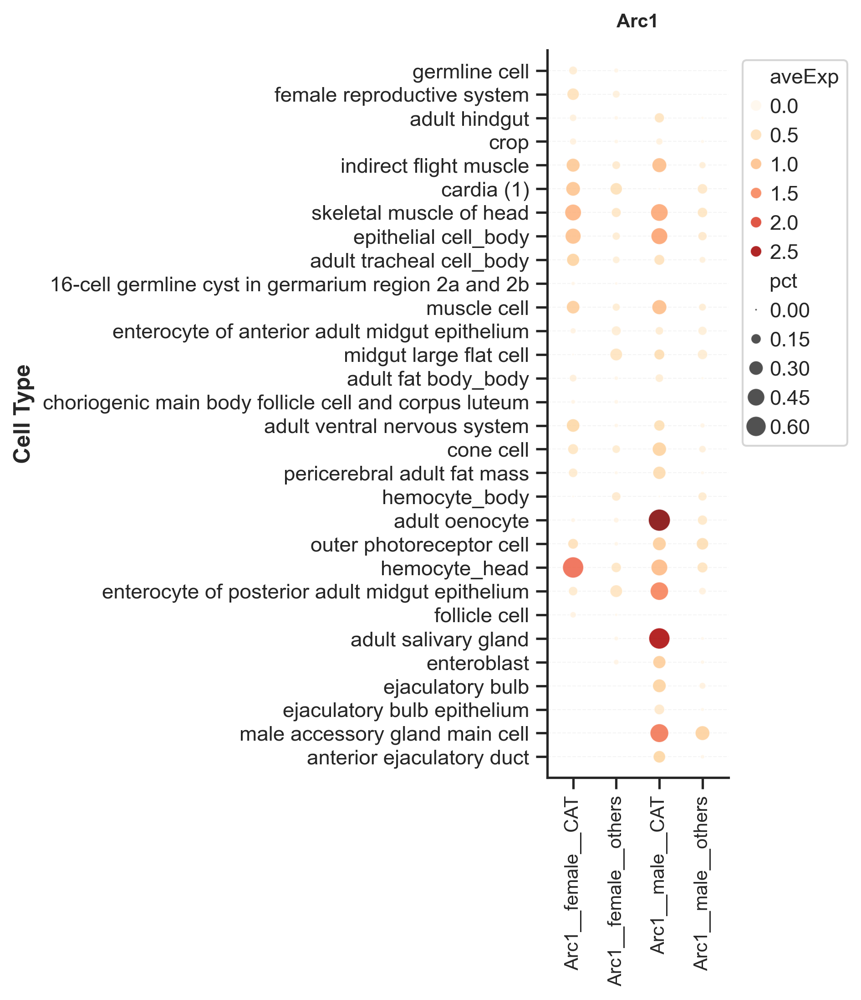

In [97]:
# FIXED PARAMETERS
FIXED_VMIN_PCT = 0.0
FIXED_VMAX_PCT = 0.8
FIXED_VMIN_EXP = 0.0
FIXED_VMAX_EXP = exp_pct_Df.aveExp.max()
FIXED_SIZE_MIN = 1.7
FIXED_SIZE_MAX = 150

# Color setup for custom legend
cmap = plt.cm.OrRd
norm = plt.Normalize(vmin=FIXED_VMIN_EXP, vmax=FIXED_VMAX_EXP)

# 
exp_pct_Df_clean = exp_pct_Df.copy()
# exp_pct_Df_clean[['aveExp', 'pct']] = exp_pct_Df_clean[['aveExp', 'pct']].fillna(0)

n_genes = len(selectGenes_L)
fig, axs = plt.subplots(1, n_genes, figsize=(1.7, 7), 
                        gridspec_kw={'wspace': 0.08})
axs = np.atleast_1d(axs)

for n, gene in enumerate(selectGenes_L):
    print(n)
    gene_data = exp_pct_Df_clean[exp_pct_Df_clean['gene'] == gene].copy()
    # gene_data = gene_data.sort_values('annotation')
    
    # gene_data.annotation = pd.Categorical(gene_data.annotation, categories=degNindex_L)
    scatter = sns.scatterplot(
        data=gene_data,
        x='gene_sex_CAT',
        y='annotation',
        size='pct',
        hue='aveExp',
        palette='OrRd',
        hue_norm=plt.Normalize(vmin=FIXED_VMIN_EXP,vmax=FIXED_VMAX_EXP),
        # vmin=FIXED_VMIN_EXP,
        # vmax=FIXED_VMAX_EXP,
        sizes=(FIXED_SIZE_MIN, FIXED_SIZE_MAX), 
        size_norm=plt.Normalize(FIXED_VMIN_PCT, FIXED_VMAX_PCT),
        alpha=0.85,
        linewidth=0.5,
        edgecolor='white',
        ax=axs[n],
        hue_order=degNindex_L,
        legend=(n == 0)  # Turn off automatic legend
    )

    # Optional: fine-tune legend position
    if n == 0 and axs[n].get_legend():
        axs[n].get_legend().set_bbox_to_anchor((1.02, 1.0))
    
        # axs[n].legend(bbox_to_anchor=(1.1, 1.0))

    # Styling
    axs[n].set_xlabel('')
    axs[n].set_title(gene, fontsize=10, fontweight='bold', pad=12)
    axs[n].tick_params(axis='x', rotation=90, labelsize=10)
    axs[n].margins(x=0.2, y=0.03)
    axs[n].grid(axis='y', alpha=0.2, linestyle='--', linewidth=0.5)
    
    # Y-axis (only show labels on first panel)
    if n == 0:
        axs[n].set_ylabel('Cell Type', fontsize=12, fontweight='bold')
    else:
        axs[n].set_ylabel('')
        axs[n].set_yticklabels([])
        
#     # # Add separator line
#     # if n < len(selectGenes_L) - 1:
#     #     axs[n].axvline(x=axs[n].get_xlim()[1], color='gray', 
#     #                   linewidth=1.5, alpha=0.3)
    
    # Clean spines
    axs[n].spines['top'].set_visible(False)
    axs[n].spines['right'].set_visible(False)
    
    # # legend position
    # if n = 5:
    #     axs[n].spines['right'].set_visible(False)
    
plt.tight_layout()
    
plt.savefig(f'{figure5PicFolder}/dotplot__cat_sex__Arc1_OrRd.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Finish ~ ~